# Assignment 2 — GitHub Submission
**Public repository:** https://github.com/adnan05-gif/i25-7602-NLP-Assignment2

This notebook contains the implementation and experimental workflow for the BBC Urdu NLP Assignment 2.

In [1]:

# ============================================================
# PHASE 0 — CELL 1: ENVIRONMENT AUDIT
# ============================================================

import os
import sys
import platform
import torch
import numpy as np
import pandas as pd

print("=" * 60)
print("BBC URDU NLP ASSIGNMENT 2")
print("PHASE 0: ENVIRONMENT AUDIT")
print("=" * 60)

print("\n[1] SYSTEM INFORMATION")
print("Python:", sys.version)
print("Platform:", platform.platform())
print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

print("\n[2] GPU INFORMATION")
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / (1024 ** 3), 2
        ),
        "GB"
    )
else:
    print("WARNING: GPU not detected.")

print("\n[3] WORKING DIRECTORY")
print(os.getcwd())

print("\n[4] AVAILABLE STORAGE")
print("Temporary storage:", os.path.exists("/content"))

print("\n" + "=" * 60)
print("ENVIRONMENT AUDIT COMPLETED")
print("=" * 60)


BBC URDU NLP ASSIGNMENT 2
PHASE 0: ENVIRONMENT AUDIT

[1] SYSTEM INFORMATION
Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
PyTorch: 2.14.1+cu130
NumPy: 2.4.6
Pandas: 2.2.3

[2] GPU INFORMATION
CUDA available: True
GPU: Tesla T4
CUDA version: 13.0
GPU memory: 14.56 GB

[3] WORKING DIRECTORY
/content

[4] AVAILABLE STORAGE
Temporary storage: True

ENVIRONMENT AUDIT COMPLETED


In [3]:
PROJECT_DIR = "/content/BBC_Urdu_NLP_Assignment2"

In [4]:
import os

folders = [
    "data",
    "embeddings",
    "models",
    "outputs/figures",
    "outputs/logs",
    "annotations",
    "checkpoints"
]

for folder in folders:
    os.makedirs(
        os.path.join(PROJECT_DIR, folder),
        exist_ok=True
    )

print("Project directory ready:", PROJECT_DIR)

Project directory ready: /content/BBC_Urdu_NLP_Assignment2


In [5]:

# ============================================================
# BBC URDU NLP ASSIGNMENT 2
# PHASE 0 — CELL 1: ENVIRONMENT VERIFICATION
# ============================================================

import os
import sys
import platform
import torch
import numpy as np
import pandas as pd

print("=" * 65)
print("BBC URDU NLP ASSIGNMENT 2")
print("PHASE 0: ENVIRONMENT VERIFICATION")
print("=" * 65)

print("\nSYSTEM INFORMATION")
print("Python:", sys.version)
print("Platform:", platform.platform())
print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

print("\nGPU INFORMATION")
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)

    gpu_memory = (
        torch.cuda.get_device_properties(0).total_memory
        / (1024 ** 3)
    )
    print("GPU memory:", round(gpu_memory, 2), "GB")
else:
    print("WARNING: GPU not detected.")

print("\nSTORAGE")
print("Working directory:", os.getcwd())
print("Available disk space:")

import shutil
total, used, free = shutil.disk_usage("/content")

print("Total:", round(total / 1024**3, 2), "GB")
print("Free:", round(free / 1024**3, 2), "GB")

print("\nENVIRONMENT CHECK COMPLETED")


BBC URDU NLP ASSIGNMENT 2
PHASE 0: ENVIRONMENT VERIFICATION

SYSTEM INFORMATION
Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
PyTorch: 2.14.1+cu130
NumPy: 2.4.6
Pandas: 2.2.3

GPU INFORMATION
CUDA available: True
GPU: Tesla T4
CUDA version: 13.0
GPU memory: 14.56 GB

STORAGE
Working directory: /content
Available disk space:
Total: 112.64 GB
Free: 112.54 GB

ENVIRONMENT CHECK COMPLETED


In [7]:

# ============================================================
# PHASE 0 — CELL 2: UPLOAD DATASETS
# ============================================================

from google.colab import files
import os
import shutil

PROJECT_DIR = "/content/BBC_Urdu_NLP_Assignment2"
DATA_DIR = os.path.join(PROJECT_DIR, "data")

os.makedirs(DATA_DIR, exist_ok=True)

print("Please select these three files:")
print("1. cleaned.txt")
print("2. raw.txt")
print("3. Metadata.json")

uploaded = files.upload()

for filename in uploaded:
    destination = os.path.join(DATA_DIR, filename)

    shutil.move(
        os.path.join("/content", filename),
        destination
    )

print("\nUPLOADED FILES")

for filename in os.listdir(DATA_DIR):
    path = os.path.join(DATA_DIR, filename)

    print(
        filename,
        "|",
        round(os.path.getsize(path) / 1024, 2),
        "KB"
    )


Please select these three files:
1. cleaned.txt
2. raw.txt
3. Metadata.json


Saving Metadata.json to Metadata.json
Saving raw.txt.txt to raw.txt.txt
Saving cleaned.txt.txt to cleaned.txt.txt

UPLOADED FILES
raw.txt.txt | 2970.7 KB
cleaned.txt.txt | 2755.47 KB
Metadata.json | 79.23 KB


In [8]:

# ============================================================
# PHASE 0 — CELL 3: PROJECT STRUCTURE
# ============================================================

import os

PROJECT_DIR = "/content/BBC_Urdu_NLP_Assignment2"

folders = [
    "data",
    "embeddings",
    "models",
    "outputs",
    "outputs/figures",
    "outputs/logs",
    "annotations",
    "checkpoints"
]

for folder in folders:
    os.makedirs(
        os.path.join(PROJECT_DIR, folder),
        exist_ok=True
    )

print("PROJECT STRUCTURE")

for root, dirs, files_list in os.walk(PROJECT_DIR):
    level = root.replace(PROJECT_DIR, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")


PROJECT STRUCTURE
BBC_Urdu_NLP_Assignment2/
  annotations/
  embeddings/
  models/
  checkpoints/
  outputs/
    figures/
    logs/
  data/


In [10]:

import os

print("Searching /content for dataset files...\n")

for root, dirs, files in os.walk("/content"):
    dirs[:] = [d for d in dirs if d not in ["drive", ".cache"]]

    for filename in files:
        if filename.lower() in [
            "cleaned.txt",
            "raw.txt",
            "metadata.json"
        ]:
            path = os.path.join(root, filename)
            print("FOUND:", path)


Searching /content for dataset files...

FOUND: /content/BBC_Urdu_NLP_Assignment2/data/Metadata.json


In [11]:

from google.colab import files
import os
import shutil

DATA_DIR = "/content/BBC_Urdu_NLP_Assignment2/data"
os.makedirs(DATA_DIR, exist_ok=True)

uploaded = files.upload()

for filename in uploaded:
    if filename.lower() in ["cleaned.txt", "raw.txt"]:
        destination = os.path.join(DATA_DIR, filename)

        shutil.move(
            os.path.join("/content", filename),
            destination
        )

        print("Saved:", destination)
    else:
        print("Skipped unexpected file:", filename)


Saving cleaned.txt.txt to cleaned.txt.txt
Saving raw.txt.txt to raw.txt.txt
Skipped unexpected file: cleaned.txt.txt
Skipped unexpected file: raw.txt.txt


In [14]:
import os
import shutil

PROJECT_DIR = "/content/BBC_Urdu_NLP_Assignment2"
DATA_DIR = os.path.join(PROJECT_DIR, "data")

os.makedirs(DATA_DIR, exist_ok=True)

# Actual uploaded filenames
file_mapping = {
    "/content/cleaned.txt.txt": "cleaned.txt",
    "/content/raw\\.txt.txt": "raw.txt",
    "/content/Metadata.json": "Metadata.json"
}

for source, new_name in file_mapping.items():

    destination = os.path.join(DATA_DIR, new_name)

    if os.path.isfile(source):
        shutil.move(source, destination)
        print("[RENAMED AND MOVED]", new_name)

    elif os.path.isfile(destination):
        print("[ALREADY EXISTS]", new_name)

    else:
        print("[NOT FOUND]", source)

# Final integrity check
print("\n" + "=" * 50)
print("FINAL DATASET INTEGRITY CHECK")
print("=" * 50)

required_files = [
    "cleaned.txt",
    "raw.txt",
    "Metadata.json"
]

all_found = True

for filename in required_files:

    path = os.path.join(DATA_DIR, filename)

    if os.path.isfile(path):
        print(
            "[FOUND]", filename,
            f"({os.path.getsize(path)/1024:.2f} KB)"
        )
    else:
        print("[MISSING]", filename)
        all_found = False

assert all_found, "Dataset integrity check failed!"

print("\nSUCCESS: All three dataset files are ready!")

[RENAMED AND MOVED] cleaned.txt
[NOT FOUND] /content/raw\.txt.txt
[ALREADY EXISTS] Metadata.json

FINAL DATASET INTEGRITY CHECK
[FOUND] cleaned.txt (2755.47 KB)
[MISSING] raw.txt
[FOUND] Metadata.json (79.23 KB)


AssertionError: Dataset integrity check failed!

In [15]:
import os

print("Searching for raw text files...\n")

for root, dirs, files in os.walk("/content"):
    for filename in files:
        if "raw" in filename.lower():
            print("FOUND:")
            print("Filename:", repr(filename))
            print("Full path:", repr(os.path.join(root, filename)))

Searching for raw text files...

FOUND:
Filename: 'raw.txt.txt'
Full path: '/content/raw.txt.txt'
FOUND:
Filename: 'raw.txt.txt'
Full path: '/content/BBC_Urdu_NLP_Assignment2/data/raw.txt.txt'


In [16]:
import os
import shutil

DATA_DIR = "/content/BBC_Urdu_NLP_Assignment2/data"

# Find the actual uploaded raw file
source = None

for root, dirs, files in os.walk("/content"):
    for filename in files:
        if filename.lower().startswith("raw") and filename.lower().endswith(".txt"):
            candidate = os.path.join(root, filename)

            if os.path.abspath(candidate) != os.path.abspath(
                os.path.join(DATA_DIR, "raw.txt")
            ):
                source = candidate
                break

    if source:
        break

destination = os.path.join(DATA_DIR, "raw.txt")

if source:
    shutil.move(source, destination)
    print("[SUCCESS] Raw file renamed to raw.txt")
elif os.path.isfile(destination):
    print("[ALREADY EXISTS] raw.txt")
else:
    print("[ERROR] Raw file not found. Check Step 1 output.")

# Verify all three files
for filename in ["cleaned.txt", "raw.txt", "Metadata.json"]:
    path = os.path.join(DATA_DIR, filename)
    print(
        "[FOUND]" if os.path.isfile(path) else "[MISSING]",
        filename
    )

[SUCCESS] Raw file renamed to raw.txt
[FOUND] cleaned.txt
[FOUND] raw.txt
[FOUND] Metadata.json


In [17]:
import os
import json

DATA_DIR = "/content/BBC_Urdu_NLP_Assignment2/data"

print("=" * 60)
print("PHASE 0: DATASET CONTENT VALIDATION")
print("=" * 60)

# 1. Validate text files
for filename in ["cleaned.txt", "raw.txt"]:

    path = os.path.join(DATA_DIR, filename)

    with open(path, "r", encoding="utf-8") as f:
        content = f.read()

    print(f"\n{filename}")
    print("Characters:", len(content))
    print("Total lines:", len(content.splitlines()))
    print("Non-empty lines:", sum(bool(x.strip()) for x in content.splitlines()))
    print("Empty file:", not bool(content.strip()))

    assert content.strip(), f"{filename} is empty!"

# 2. Validate Metadata.json
metadata_path = os.path.join(DATA_DIR, "Metadata.json")

with open(metadata_path, "r", encoding="utf-8") as f:
    metadata = json.load(f)

print("\nMetadata.json")
print("JSON format: VALID")
print("Data type:", type(metadata).__name__)

if isinstance(metadata, dict):
    print("Top-level keys:", list(metadata.keys()))

    for key, value in metadata.items():
        if isinstance(value, (list, dict)):
            print(f"{key}: {type(value).__name__}, {len(value)} entries")

elif isinstance(metadata, list):
    print("Total records:", len(metadata))

    if metadata and isinstance(metadata[0], dict):
        print("Record fields:", list(metadata[0].keys()))

print("\n" + "=" * 60)
print("PHASE 0 CONTENT VALIDATION COMPLETED")
print("=" * 60)

PHASE 0: DATASET CONTENT VALIDATION

cleaned.txt
Characters: 1611286
Total lines: 737
Non-empty lines: 492
Empty file: False

raw.txt
Characters: 1707480
Total lines: 10058
Non-empty lines: 9812
Empty file: False

Metadata.json
JSON format: VALID
Data type: list
Total records: 246
Record fields: ['article_number', 'title', 'date', 'url', 'word_count']

PHASE 0 CONTENT VALIDATION COMPLETED


In [18]:
import os
import json
import re

DATA_DIR = "/content/BBC_Urdu_NLP_Assignment2/data"

# Load metadata
with open(os.path.join(DATA_DIR, "Metadata.json"),
          "r", encoding="utf-8") as f:
    metadata = json.load(f)

# Inspect text files
for filename in ["cleaned.txt", "raw.txt"]:

    path = os.path.join(DATA_DIR, filename)

    with open(path, "r", encoding="utf-8") as f:
        lines = f.readlines()

    print("\n" + "=" * 60)
    print(filename)
    print("=" * 60)

    print("Total lines:", len(lines))
    print("Non-empty lines:", sum(bool(x.strip()) for x in lines))

    print("\nFirst 12 non-empty lines:")

    shown = 0
    for line in lines:
        if line.strip():
            print(repr(line.strip()[:180]))
            shown += 1

            if shown == 12:
                break

    print("\nLast 5 non-empty lines:")

    for line in [x for x in lines if x.strip()][-5:]:
        print(repr(line.strip()[:180]))

# Metadata audit
print("\n" + "=" * 60)
print("METADATA ARTICLE AUDIT")
print("=" * 60)

article_numbers = [
    item.get("article_number") for item in metadata
]

print("Total metadata records:", len(metadata))
print("Unique article numbers:", len(set(article_numbers)))
print("Missing article numbers:", sum(x is None for x in article_numbers))
print("Duplicate article numbers:",
      len(article_numbers) - len(set(article_numbers)))

print("First 10 article numbers:", article_numbers[:10])

print("\nMetadata word-count summary:")

word_counts = [
    item.get("word_count", 0)
    for item in metadata
    if isinstance(item.get("word_count"), (int, float))
]

if word_counts:
    print("Minimum:", min(word_counts))
    print("Maximum:", max(word_counts))
    print("Average:", round(sum(word_counts) / len(word_counts), 2))

print("\nAUDIT COMPLETED")


cleaned.txt
Total lines: 737
Non-empty lines: 492

First 12 non-empty lines:
'ARTICLE 1'
'میکسیکو اور جنوب ٹیکساس کے دریاؤں میں مچھل کی ایک ایس قسم پائ جات ہے جس کا بظاہر وجود ناممکن ہون چاہی ۔ گرم اور ہلک بہاؤ وال پان میں مکمل طور پر ماد مچھل پر مشتمل جھنڈ اکثر تیر نظر'
'ARTICLE 2'
'’پارٹیشن نے ہر اس فیمل کو تبا کر دیا جس نے اپن گھر چھوڑ ۔ میر داد کہت تھیں کہ دون طرف کے سیاست دان نے پارٹیشن دیکھ نہیں ، ورن شاید یہ نوبت نہ آتی ۔ یہ ان سے پوچھ جن کے گھرا ، جن کے'
'ARTICLE 3'
'سپریم کورٹ سے <NUM> برس قید کی سزا کی معطل اور ضمانت پر اڈیال جیل رہا ہون وال وکیل ایم مزار اور ان کے شوہر ہاد علی چٹھ کو پولیس نے ایک اور مقدم میں گرفتار کر لیا ہے ۔ اسلام آباد پو'
'ARTICLE 4'
'’وہ ( عمر خان ) بار بار ایک ہی بات کہہ رہے تھے کہ میر ساتھ ظلم ہوا ہے ، مجھ پر ٹارچر ہوا ہے ۔ میں ان ( جیل حکام ) کو کہت تھا کہ ( محمد ) مرس کو بھی ایس ہی مار گیا تھا ۔ میں ان ( جی'
'ARTICLE 5'
'لارڈز کے مید میں پاکست کی ٹیم سے یہ امید کی جا رہی تھی کہ وہ پہل ٹیسٹ میچ کے مقابل میں بہتر کارکرد دکھائ گی اور بابر اعظم کی کپتا

In [19]:
import os
import re
import json
import statistics

DATA_DIR = "/content/BBC_Urdu_NLP_Assignment2/data"

def load_articles(filename):
    path = os.path.join(DATA_DIR, filename)

    with open(path, "r", encoding="utf-8") as f:
        lines = f.readlines()

    articles = {}
    current_id = None

    for line in lines:
        match = re.fullmatch(r"ARTICLE\s+(\d+)\s*", line.strip())

        if match:
            current_id = int(match.group(1))
            articles[current_id] = []
        elif current_id is not None:
            if line.strip():
                articles[current_id].append(line.strip())

    return {
        article_id: " ".join(content)
        for article_id, content in articles.items()
    }

# Load both datasets
raw_articles = load_articles("raw.txt")
cleaned_articles = load_articles("cleaned.txt")

with open(os.path.join(DATA_DIR, "Metadata.json"),
          "r", encoding="utf-8") as f:
    metadata = json.load(f)

metadata_ids = {item["article_number"] for item in metadata}

# Alignment report
print("=" * 65)
print("FINAL ARTICLE ALIGNMENT AUDIT")
print("=" * 65)

for name, articles in [
    ("RAW", raw_articles),
    ("CLEANED", cleaned_articles)
]:
    ids = set(articles)

    print(f"\n{name} DATASET")
    print("Article count:", len(articles))
    print("First article:", min(ids) if ids else None)
    print("Last article:", max(ids) if ids else None)
    print("Missing article IDs:", sorted(metadata_ids - ids))
    print("Unexpected article IDs:", sorted(ids - metadata_ids))
    print("Empty articles:", [
        i for i, text in articles.items() if not text.strip()
    ])

# Word count comparison
print("\n" + "=" * 65)
print("METADATA WORD-COUNT COMPARISON")
print("=" * 65)

raw_counts = []
cleaned_counts = []

for item in metadata:
    article_id = item["article_number"]

    raw_count = len(raw_articles.get(article_id, "").split())
    cleaned_count = len(cleaned_articles.get(article_id, "").split())
    expected_count = item.get("word_count")

    raw_counts.append(raw_count)
    cleaned_counts.append(cleaned_count)

print("Average raw words:", round(statistics.mean(raw_counts), 2))
print("Average cleaned words:", round(statistics.mean(cleaned_counts), 2))
print("Average metadata words:", round(statistics.mean(
    item["word_count"] for item in metadata
), 2))

print("\nFirst 10 article comparisons:")

for item in metadata[:10]:
    i = item["article_number"]
    print(
        f"Article {i}: "
        f"Metadata={item['word_count']}, "
        f"Raw={len(raw_articles.get(i, '').split())}, "
        f"Cleaned={len(cleaned_articles.get(i, '').split())}"
    )

# Inspect final raw article
print("\n" + "=" * 65)
print("FINAL RAW ARTICLE INSPECTION")
print("=" * 65)

print(raw_articles.get(246, "")[-500:])

# Overall status
valid = (
    len(raw_articles) == 246
    and len(cleaned_articles) == 246
    and set(raw_articles) == metadata_ids
    and set(cleaned_articles) == metadata_ids
    and all(text.strip() for text in raw_articles.values())
    and all(text.strip() for text in cleaned_articles.values())
)

print("\n" + "=" * 65)
print("ARTICLE ALIGNMENT:", "PASSED" if valid else "REQUIRES REVIEW")
print("=" * 65)

FINAL ARTICLE ALIGNMENT AUDIT

RAW DATASET
Article count: 246
First article: 1
Last article: 246
Missing article IDs: []
Unexpected article IDs: []
Empty articles: []

CLEANED DATASET
Article count: 246
First article: 1
Last article: 246
Missing article IDs: []
Unexpected article IDs: []
Empty articles: []

METADATA WORD-COUNT COMPARISON
Average raw words: 1489.11
Average cleaned words: 1582.08
Average metadata words: 1489.11

First 10 article comparisons:
Article 1: Metadata=2756, Raw=2756, Cleaned=2961
Article 2: Metadata=1670, Raw=1670, Cleaned=1810
Article 3: Metadata=2414, Raw=2414, Cleaned=2528
Article 4: Metadata=1346, Raw=1346, Cleaned=1411
Article 5: Metadata=1231, Raw=1231, Cleaned=1314
Article 6: Metadata=2254, Raw=2254, Cleaned=2415
Article 7: Metadata=2143, Raw=2143, Cleaned=2221
Article 8: Metadata=1386, Raw=1386, Cleaned=1458
Article 9: Metadata=1274, Raw=1274, Cleaned=1340
Article 10: Metadata=1239, Raw=1239, Cleaned=1319

FINAL RAW ARTICLE INSPECTION
 اپنے خیمے کی طرف 

In [20]:
import json
import re
from collections import Counter

BASE_DIR = "/content/BBC_Urdu_NLP_Assignment2/data"

# --------------------------------------------------
# 1. Inspect complete metadata structure
# --------------------------------------------------
metadata_path = f"{BASE_DIR}/Metadata.json"

with open(metadata_path, "r", encoding="utf-8") as f:
    metadata = json.load(f)

print("=" * 65)
print("METADATA STRUCTURE AUDIT")
print("=" * 65)

print("Metadata type:", type(metadata).__name__)
print("Total records:", len(metadata) if isinstance(metadata, list) else "N/A")

if isinstance(metadata, list) and metadata:
    print("\nFirst complete record:")
    print(json.dumps(metadata[0], ensure_ascii=False, indent=2))

    all_keys = set()
    for record in metadata:
        if isinstance(record, dict):
            all_keys.update(record.keys())

    print("\nAll metadata fields:")
    print(sorted(all_keys))

    possible_topic_fields = [
        key for key in all_keys
        if any(term in key.lower() for term in
               ["topic", "category", "class", "label", "section"])
    ]

    print("\nPossible topic/label fields:", possible_topic_fields)

    for key in possible_topic_fields:
        values = [
            str(record.get(key))
            for record in metadata
            if record.get(key) is not None
        ]
        print(f"\nValues for '{key}':")
        print(Counter(values))

# --------------------------------------------------
# 2. Search raw corpus for the media-player message
# --------------------------------------------------
raw_path = f"{BASE_DIR}/raw.txt"

with open(raw_path, "r", encoding="utf-8") as f:
    raw_text = f.read()

footer = "اپ کی ڈیوائس پر پلے بیک سپورٹ دستیاب نہیں"

print("\n" + "=" * 65)
print("MEDIA-PLAYER TEXT AUDIT")
print("=" * 65)

print("Exact footer occurrences:", raw_text.count(footer))

# --------------------------------------------------
# 3. Inspect cleaned vs raw word-count differences
# --------------------------------------------------
def parse_articles(path):
    articles = {}
    current_id = None
    content = []

    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            match = re.fullmatch(r"ARTICLE\s+(\d+)", line)

            if match:
                if current_id is not None:
                    articles[current_id] = " ".join(content)

                current_id = int(match.group(1))
                content = []
            elif current_id is not None:
                content.append(line)

    if current_id is not None:
        articles[current_id] = " ".join(content)

    return articles

raw_articles = parse_articles(raw_path)
cleaned_articles = parse_articles(f"{BASE_DIR}/cleaned.txt")

print("\n" + "=" * 65)
print("WORD-COUNT DIFFERENCE INSPECTION")
print("=" * 65)

for article_id in range(1, 6):
    raw_words = len(raw_articles[article_id].split())
    cleaned_words = len(cleaned_articles[article_id].split())

    print(
        f"Article {article_id}: "
        f"Raw={raw_words}, "
        f"Cleaned={cleaned_words}, "
        f"Difference={cleaned_words - raw_words}"
    )

print("\nAudit completed.")

METADATA STRUCTURE AUDIT
Metadata type: list
Total records: 246

First complete record:
{
  "article_number": 1,
  "title": "سائنسدانوں کے لیے معمہ بننے والی وہ مچھلیاں جو ایک لاکھ سال سے سیکس کے بغیر اپنی نسل بڑھا رہی ہیں",
  "date": "2026-06-03",
  "url": "https://www.bbc.com/urdu/articles/c04200079zlo",
  "word_count": 2756
}

All metadata fields:
['article_number', 'date', 'title', 'url', 'word_count']

Possible topic/label fields: []

MEDIA-PLAYER TEXT AUDIT
Exact footer occurrences: 245

WORD-COUNT DIFFERENCE INSPECTION
Article 1: Raw=2756, Cleaned=2961, Difference=205
Article 2: Raw=1670, Cleaned=1810, Difference=140
Article 3: Raw=2414, Cleaned=2528, Difference=114
Article 4: Raw=1346, Cleaned=1411, Difference=65
Article 5: Raw=1231, Cleaned=1314, Difference=83

Audit completed.


In [21]:

import os
import re
import json
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer

# ==========================================
# 1. FILE PATHS
# ==========================================

DATA_DIR = "/content/BBC_Urdu_NLP_Assignment2/data"
OUTPUT_DIR = "/content/BBC_Urdu_NLP_Assignment2/part1_tfidf"

os.makedirs(OUTPUT_DIR, exist_ok=True)

CLEANED_FILE = os.path.join(DATA_DIR, "cleaned.txt")

# ==========================================
# 2. LOAD ARTICLES
# ==========================================

articles = {}
current_id = None
content = []

with open(CLEANED_FILE, "r", encoding="utf-8") as f:
    for line in f:
        line = line.strip()

        match = re.fullmatch(r"ARTICLE\s+(\d+)", line)

        if match:
            if current_id is not None:
                articles[current_id] = " ".join(content)

            current_id = int(match.group(1))
            content = []
        elif current_id is not None:
            content.append(line)

if current_id is not None:
    articles[current_id] = " ".join(content)

print("Total articles loaded:", len(articles))

assert len(articles) == 246, "Dataset should contain 246 articles."

# ==========================================
# 3. CLEAN THE WEBSITE FOOTER
# ==========================================

footer = "اپ کی ڈیوائس پر پلے بیک سپورٹ دستیاب نہیں"

documents = []

for article_id in sorted(articles):
    text = articles[article_id]
    text = text.replace(footer, " ")
    text = re.sub(r"\s+", " ", text).strip()
    documents.append(text)

print("Working documents prepared:", len(documents))

# ==========================================
# 4. URDU TOKENIZER
# ==========================================

def urdu_tokenizer(text):
    return re.findall(
        r"[\u0600-\u06FF]+|[A-Za-z]+|\d+",
        text.lower()
    )

# ==========================================
# 5. TF-IDF VECTORIZATION
# ==========================================

vectorizer = TfidfVectorizer(
    tokenizer=urdu_tokenizer,
    token_pattern=None,
    lowercase=False,
    max_features=10000,
    use_idf=True,
    smooth_idf=True,
    norm="l2"
)

tfidf_matrix = vectorizer.fit_transform(documents)

feature_names = vectorizer.get_feature_names_out()

print("\n========== TF-IDF RESULTS ==========")
print("Documents:", tfidf_matrix.shape[0])
print("Vocabulary size:", tfidf_matrix.shape[1])
print("TF-IDF matrix shape:", tfidf_matrix.shape)

# ==========================================
# 6. TOP 10 WORDS FOR EACH ARTICLE
# ==========================================

for article_index in range(3):

    scores = tfidf_matrix[article_index].toarray().flatten()

    top_indices = np.argsort(scores)[::-1][:10]

    print(f"\nArticle {article_index + 1} — Top 10 Words")

    for rank, idx in enumerate(top_indices, 1):
        print(
            f"{rank}. {feature_names[idx]} "
            f"| Score: {scores[idx]:.4f}"
        )

# ==========================================
# 7. TOP 30 WORDS OVERALL
# ==========================================

average_scores = np.asarray(
    tfidf_matrix.mean(axis=0)
).flatten()

top_indices = np.argsort(average_scores)[::-1][:30]

top_words = pd.DataFrame({
    "Word": feature_names[top_indices],
    "Average_TFIDF": average_scores[top_indices]
})

print("\n========== TOP 30 OVERALL WORDS ==========")
display(top_words)

# ==========================================
# 8. SAVE RESULTS
# ==========================================

np.save(
    os.path.join(OUTPUT_DIR, "tfidf_matrix.npy"),
    tfidf_matrix.toarray()
)

with open(
    os.path.join(OUTPUT_DIR, "tfidf_vocabulary.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        feature_names.tolist(),
        f,
        ensure_ascii=False,
        indent=2
    )

top_words.to_csv(
    os.path.join(OUTPUT_DIR, "tfidf_top_30_terms.csv"),
    index=False,
    encoding="utf-8-sig"
)

print("\n========== SAVED FILES ==========")

for filename in os.listdir(OUTPUT_DIR):
    print("[SAVED]", filename)

print("\nTF-IDF IMPLEMENTATION COMPLETED SUCCESSFULLY!")


Total articles loaded: 246
Working documents prepared: 246

========== TF-IDF RESULTS ==========
Documents: 246
Vocabulary size: 10000
TF-IDF matrix shape: (246, 10000)

Article 1 — Top 10 Words
1. جینیا | Score: 0.2933
2. کے | Score: 0.2577
3. ہے | Score: 0.2312
4. ۔ | Score: 0.2224
5. جنس | Score: 0.2100
6. مچھل | Score: 0.1870
7. مول | Score: 0.1834
8. انواع | Score: 0.1834
9. ایماز | Score: 0.1787
10. ، | Score: 0.1769

Article 2 — Top 10 Words
1. داد | Score: 0.3647
2. کے | Score: 0.2998
3. ۔ | Score: 0.2962
4. سپن | Score: 0.2638
5. اویناش | Score: 0.2311
6. میں | Score: 0.1922
7. اوبرائ | Score: 0.1891
8. سے | Score: 0.1481
9. تای | Score: 0.1481
10. ، | Score: 0.1415

Article 3 — Top 10 Words
1. کے | Score: 0.3008
2. مزار | Score: 0.2665
3. کی | Score: 0.2564
4. ہاد | Score: 0.2507
5. چٹھ | Score: 0.2144
6. ایم | Score: 0.1978
7. ۔ | Score: 0.1857
8. نے | Score: 0.1812
9. جیل | Score: 0.1789
10. میں | Score: 0.1602

========== TOP 30 OVERALL WORDS ==========


,Word,Average_TFIDF
0,کے,0.260774
1,۔,0.213243
2,میں,0.178478
3,کی,0.171085
4,ہے,0.131739
5,اور,0.114239
6,سے,0.108095
7,کہ,0.103904
8,نے,0.090904
9,کا,0.090202



========== SAVED FILES ==========
[SAVED] tfidf_top_30_terms.csv
[SAVED] tfidf_vocabulary.json
[SAVED] tfidf_matrix.npy

TF-IDF IMPLEMENTATION COMPLETED SUCCESSFULLY!


In [22]:

import os
import re
import json
import unicodedata
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer

# ==========================================
# 1. PATHS
# ==========================================

BASE_DIR = "/content/BBC_Urdu_NLP_Assignment2"
DATA_DIR = os.path.join(BASE_DIR, "data")
OUTPUT_DIR = os.path.join(BASE_DIR, "part1_tfidf")

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ==========================================
# 2. LOAD ARTICLES
# ==========================================

articles = {}
current_id = None
content = []

with open(os.path.join(DATA_DIR, "cleaned.txt"), encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        match = re.fullmatch(r"ARTICLE\s+(\d+)", line)

        if match:
            if current_id is not None:
                articles[current_id] = " ".join(content)
            current_id = int(match.group(1))
            content = []
        elif current_id is not None:
            content.append(line)

if current_id is not None:
    articles[current_id] = " ".join(content)

assert len(articles) == 246

FOOTER = "اپ کی ڈیوائس پر پلے بیک سپورٹ دستیاب نہیں"

documents = [
    articles[i].replace(FOOTER, " ")
    for i in sorted(articles)
]

# ==========================================
# 3. URDU STOPWORDS
# ==========================================

urdu_stopwords = {
    "کے", "کی", "کا", "میں", "سے", "ہے", "ہیں",
    "اور", "کہ", "کو", "نے", "پر", "اس", "ان",
    "ایک", "یہ", "وہ", "بھی", "تو", "تھا", "تھی",
    "تھے", "ہوں", "ہو", "کیا", "کر", "نہیں",
    "اپنے", "اپنی", "اپنا", "لیے", "لیے", "جو",
    "جب", "جس", "جن", "بعد", "پھر", "اگر",
    "یا", "اب", "تک", "ہی", "سب", "کچھ",
    "انھوں", "انہوں", "اسے", "انھیں"
}

# ==========================================
# 4. IMPROVED TOKENIZER
# ==========================================

def urdu_tokenizer(text):

    tokens = re.findall(
        r"[\u0600-\u06FF]+|[A-Za-z]+|\d+",
        text.lower()
    )

    valid_tokens = []

    for token in tokens:

        # Remove punctuation-only tokens
        if not any(
            unicodedata.category(char)[0] in ("L", "N")
            for char in token
        ):
            continue

        # Remove very short tokens
        if len(token) < 2:
            continue

        # Remove stopwords and placeholders
        if token in urdu_stopwords:
            continue

        if token.lower() in {"num"}:
            continue

        valid_tokens.append(token)

    return valid_tokens

# ==========================================
# 5. GENERATE IMPROVED TF-IDF
# ==========================================

vectorizer = TfidfVectorizer(
    tokenizer=urdu_tokenizer,
    token_pattern=None,
    lowercase=False,
    max_features=10000,
    use_idf=True,
    smooth_idf=True,
    norm="l2"
)

tfidf_matrix = vectorizer.fit_transform(documents)
feature_names = vectorizer.get_feature_names_out()

print("========== IMPROVED TF-IDF ==========")
print("Documents:", tfidf_matrix.shape[0])
print("Vocabulary:", tfidf_matrix.shape[1])
print("Matrix:", tfidf_matrix.shape)

# ==========================================
# 6. TOP 10 TERMS PER SAMPLE ARTICLE
# ==========================================

for i in range(3):

    scores = tfidf_matrix[i].toarray().flatten()
    indices = np.argsort(scores)[::-1][:10]

    print(f"\nArticle {i + 1} — Top 10 Terms")

    for rank, idx in enumerate(indices, 1):
        print(
            f"{rank}. {feature_names[idx]} "
            f"({scores[idx]:.4f})"
        )

# ==========================================
# 7. TOP 30 OVERALL TERMS
# ==========================================

average_scores = np.asarray(
    tfidf_matrix.mean(axis=0)
).flatten()

indices = np.argsort(average_scores)[::-1][:30]

top_words = pd.DataFrame({
    "Word": feature_names[indices],
    "Average_TFIDF": average_scores[indices]
})

display(top_words)

# ==========================================
# 8. SAVE UPDATED RESULTS
# ==========================================

np.save(
    os.path.join(OUTPUT_DIR, "tfidf_matrix.npy"),
    tfidf_matrix.toarray()
)

with open(
    os.path.join(OUTPUT_DIR, "tfidf_vocabulary.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(feature_names.tolist(), f, ensure_ascii=False, indent=2)

top_words.to_csv(
    os.path.join(OUTPUT_DIR, "tfidf_top_30_terms.csv"),
    index=False,
    encoding="utf-8-sig"
)

print("\n========== VERIFICATION ==========")
print("Matrix saved:", os.path.exists(
    os.path.join(OUTPUT_DIR, "tfidf_matrix.npy")
))
print("Vocabulary saved:", os.path.exists(
    os.path.join(OUTPUT_DIR, "tfidf_vocabulary.json")
))
print("TF-IDF improvement completed.")


========== IMPROVED TF-IDF ==========
Documents: 246
Vocabulary: 10000
Matrix: (246, 10000)

Article 1 — Top 10 Terms
1. جینیا (0.3627)
2. جنس (0.2596)
3. مچھل (0.2312)
4. مول (0.2268)
5. انواع (0.2268)
6. ایماز (0.2210)
7. افزائش (0.2184)
8. جاندار (0.2063)
9. کنورژن (0.1584)
10. سیکشوئل (0.1584)

Article 2 — Top 10 Terms
1. داد (0.4668)
2. سپن (0.3376)
3. اویناش (0.2958)
4. اوبرائ (0.2420)
5. تای (0.1895)
6. خاند (0.1799)
7. انہ (0.1382)
8. بوسال (0.1345)
9. میر (0.1268)
10. اپن (0.1204)

Article 3 — Top 10 Terms
1. مزار (0.3441)
2. ہاد (0.3237)
3. چٹھ (0.2769)
4. ایم (0.2554)
5. جیل (0.2310)
6. کورٹ (0.2039)
7. قید (0.1896)
8. عدالت (0.1567)
9. درخواست (0.1532)
10. وکیل (0.1463)


,Word,Average_TFIDF
0,انھ,0.041714
1,اپن,0.039479
2,کرن,0.038790
3,پاکست,0.038385
4,گیا,0.034567
5,وال,0.033954
6,کہا,0.030056
7,کرت,0.029567
8,ہوئ,0.027671
9,مطابق,0.025864



========== VERIFICATION ==========
Matrix saved: True
Vocabulary saved: True
TF-IDF improvement completed.


Articles loaded: 246
Total tokens: 220864
Unique tokens: 11184
PPMI vocabulary size: 3000
Unique co-occurrence pairs: 873785
Co-occurrence matrix: (3000, 3000)
Symmetry check: PASSED

========== PPMI RESULTS ==========
PPMI matrix shape: (3000, 3000)
Non-zero PPMI values: 738741
Total PPMI values: 9000000
Minimum PPMI: 5.9332793e-05
Maximum PPMI: 10.971846
PPMI symmetry check: True

========== NEAREST WORD NEIGHBOURS ==========

Word: انھ
  بتای (similarity: 0.3889)
  کہا (similarity: 0.3748)
  گیا (similarity: 0.3572)
  اپن (similarity: 0.3492)
  مجھ (similarity: 0.3453)

Word: اپن
  انھ (similarity: 0.3492)
  لکھ (similarity: 0.3449)
  میر (similarity: 0.3432)
  والد (similarity: 0.3344)
  بیٹ (similarity: 0.3322)

Word: کرن
  کرت (similarity: 0.3225)
  سکت (similarity: 0.3104)
  دین (similarity: 0.3094)
  وال (similarity: 0.3057)
  استعمال (similarity: 0.2953)

Word: وال
  ہون (similarity: 0.4579)
  جان (similarity: 0.3826)
  زیاد (similarity: 0.3168)
  استعمال (similarity: 0.3106)


/tmp/ipykernel_808/1670892150.py:336: UserWarning: Glyph 1729 (\N{ARABIC LETTER HEH GOAL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_808/1670892150.py:336: UserWarning: Matplotlib currently does not support Arabic natively.
  plt.tight_layout()
/tmp/ipykernel_808/1670892150.py:336: UserWarning: Glyph 1746 (\N{ARABIC LETTER YEH BARREE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_808/1670892150.py:343: UserWarning: Glyph 1729 (\N{ARABIC LETTER HEH GOAL}) missing from font(s) DejaVu Sans.
  plt.savefig(plot_path, dpi=300)
/tmp/ipykernel_808/1670892150.py:343: UserWarning: Matplotlib currently does not support Arabic natively.
  plt.savefig(plot_path, dpi=300)
/tmp/ipykernel_808/1670892150.py:343: UserWarning: Glyph 1746 (\N{ARABIC LETTER YEH BARREE}) missing from font(s) DejaVu Sans.
  plt.savefig(plot_path, dpi=300)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 1729 (\N{ARABIC LETTER HEH G

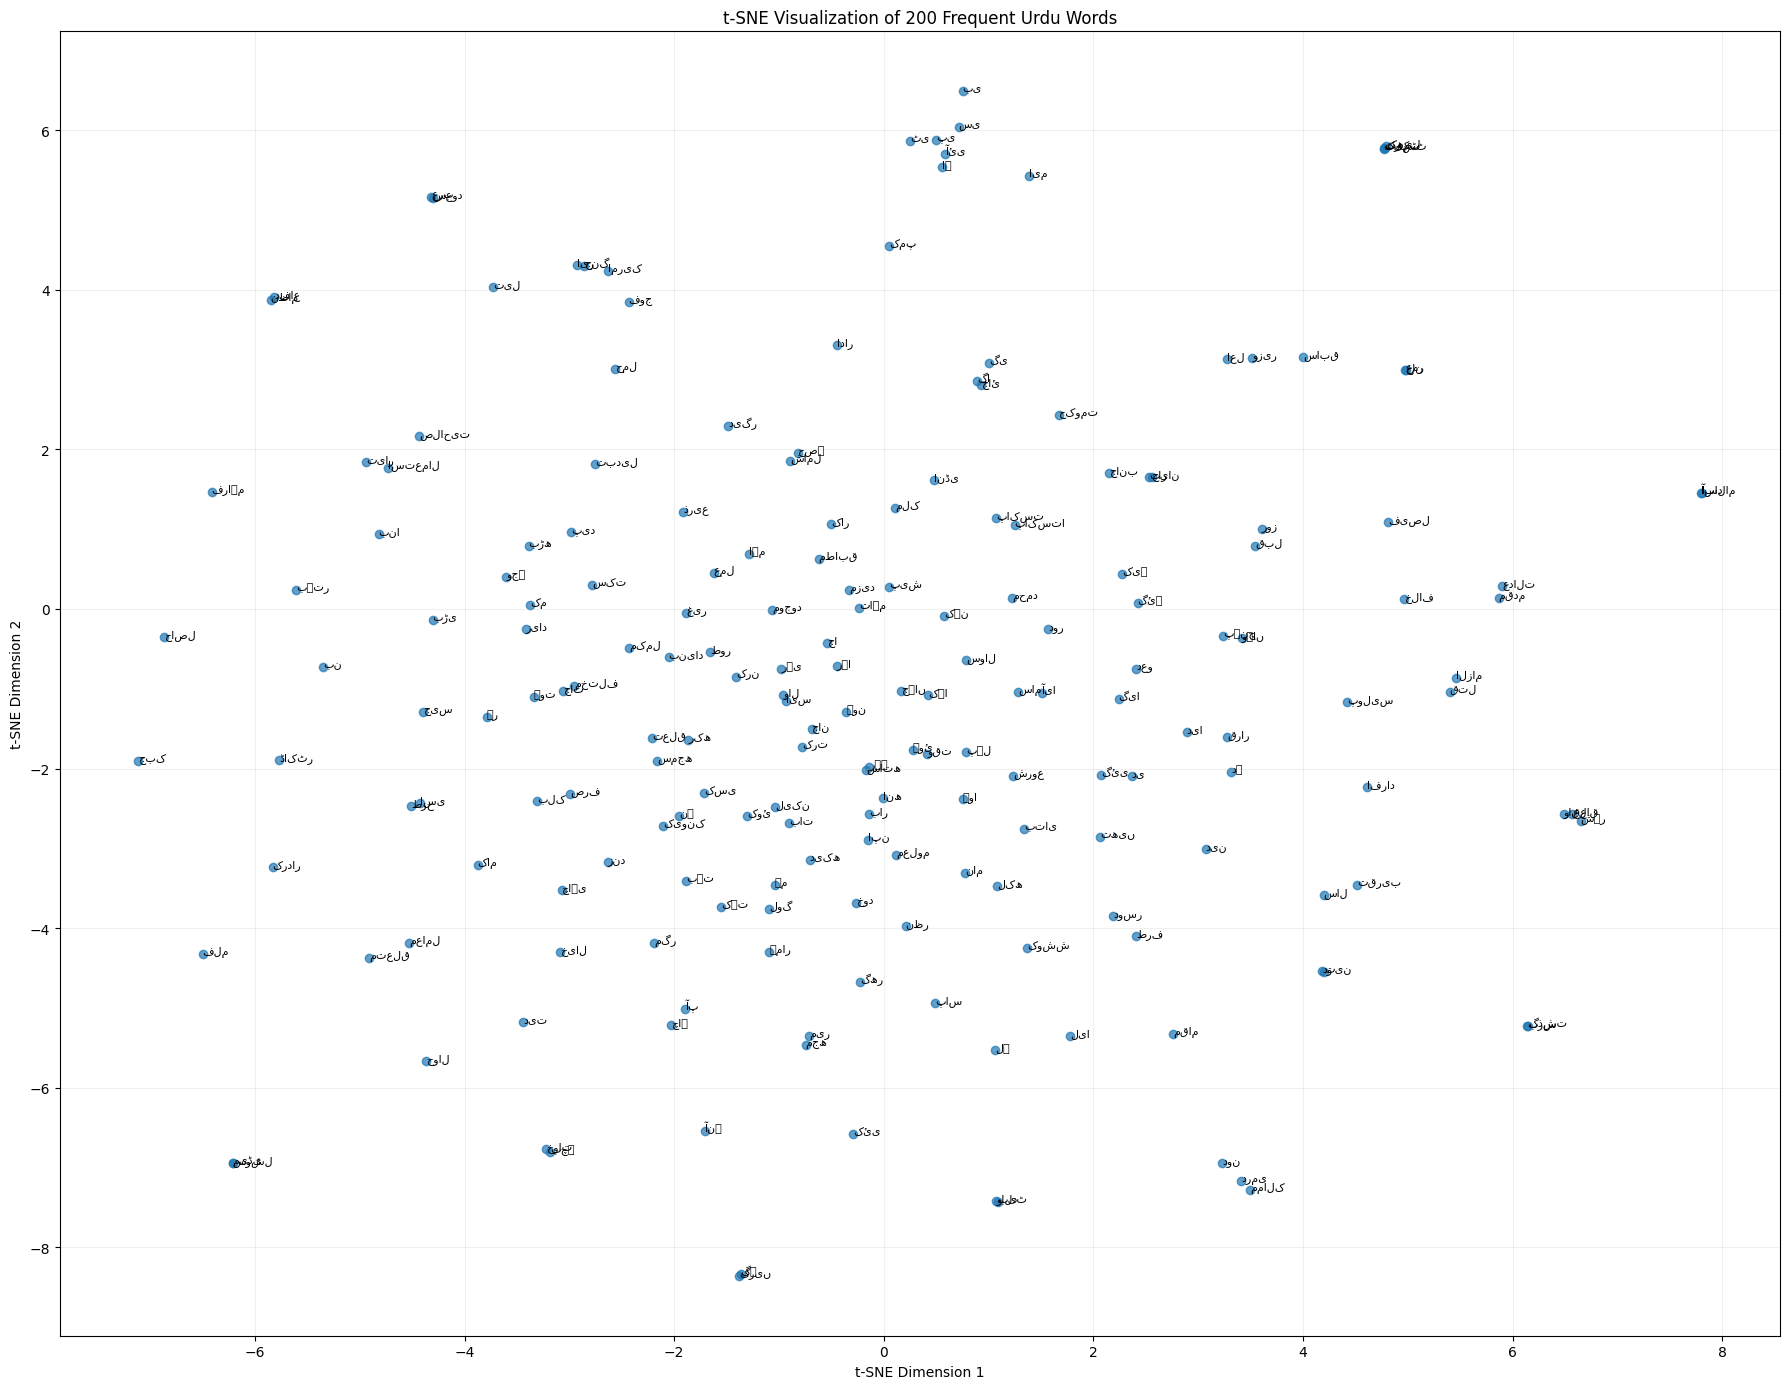


========== FINAL PPMI VERIFICATION ==========
Matrix shape: (3000, 3000)
All values non-negative: True
Matrix saved successfully.

Saved files:
ppmi_matrix.npy (34.33 MB)
ppmi_matrix_sparse.npz (2.85 MB)
ppmi_tsne_200_words.png (0.73 MB)
ppmi_vocabulary.json (0.04 MB)
word_frequencies.csv (0.04 MB)

PPMI IMPLEMENTATION COMPLETED SUCCESSFULLY!


In [23]:

# ============================================================
# PART 1 — PPMI WORD EMBEDDINGS
# BBC Urdu NLP Assignment 2
# ============================================================

import os
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter
from scipy.sparse import coo_matrix, save_npz
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD
from sklearn.manifold import TSNE

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

BASE_DIR = "/content/BBC_Urdu_NLP_Assignment2"
DATA_DIR = os.path.join(BASE_DIR, "data")
OUTPUT_DIR = os.path.join(BASE_DIR, "part1_ppmi")

os.makedirs(OUTPUT_DIR, exist_ok=True)

CLEANED_FILE = os.path.join(DATA_DIR, "cleaned.txt")

WINDOW_SIZE = 5
VOCAB_SIZE = 3000
TOP_VISUAL_WORDS = 200
RANDOM_SEED = 42

# ------------------------------------------------------------
# 2. LOAD ARTICLES
# ------------------------------------------------------------

articles = {}
current_id = None
content = []

with open(CLEANED_FILE, "r", encoding="utf-8") as f:

    for line in f:
        line = line.strip()

        match = re.fullmatch(r"ARTICLE\s+(\d+)", line)

        if match:
            if current_id is not None:
                articles[current_id] = " ".join(content)

            current_id = int(match.group(1))
            content = []

        elif current_id is not None:
            content.append(line)

if current_id is not None:
    articles[current_id] = " ".join(content)

assert len(articles) == 246

documents = [
    articles[i].replace(
        "اپ کی ڈیوائس پر پلے بیک سپورٹ دستیاب نہیں", " "
    )
    for i in sorted(articles)
]

print("Articles loaded:", len(documents))

# ------------------------------------------------------------
# 3. TOKENIZATION AND STOPWORD REMOVAL
# ------------------------------------------------------------

urdu_stopwords = {
    "کے", "کی", "کا", "میں", "سے", "ہے", "ہیں",
    "اور", "کہ", "کو", "نے", "پر", "اس", "ان",
    "ایک", "یہ", "وہ", "بھی", "تو", "تھا", "تھی",
    "تھے", "ہوں", "ہو", "کیا", "کر", "نہیں",
    "اپنے", "اپنی", "اپنا", "لیے", "جو", "جب",
    "جس", "جن", "بعد", "پھر", "اگر", "یا", "اب",
    "تک", "ہی", "سب", "کچھ", "انھوں", "انہوں",
    "اسے", "انھیں"
}

def tokenize(text):

    tokens = re.findall(
        r"[\u0600-\u06FF]+|[A-Za-z]+|\d+",
        text.lower()
    )

    return [
        token for token in tokens
        if len(token) >= 2
        and token not in urdu_stopwords
        and token != "num"
    ]

tokenized_documents = [tokenize(doc) for doc in documents]

all_tokens = [
    token
    for doc in tokenized_documents
    for token in doc
]

word_counts = Counter(all_tokens)

print("Total tokens:", len(all_tokens))
print("Unique tokens:", len(word_counts))

# ------------------------------------------------------------
# 4. SELECT MOST FREQUENT 3000 WORDS
# ------------------------------------------------------------

most_frequent = word_counts.most_common(VOCAB_SIZE)

vocabulary = [word for word, count in most_frequent]

word_to_id = {
    word: index
    for index, word in enumerate(vocabulary)
}

print("PPMI vocabulary size:", len(vocabulary))

# ------------------------------------------------------------
# 5. BUILD SYMMETRIC COOCCURRENCE MATRIX
# ------------------------------------------------------------

cooccurrence_counts = Counter()

for document in tokenized_documents:

    # Keep only selected vocabulary words
    ids = [
        word_to_id[word]
        for word in document
        if word in word_to_id
    ]

    for i, center_id in enumerate(ids):

        start = max(0, i - WINDOW_SIZE)
        end = min(len(ids), i + WINDOW_SIZE + 1)

        for j in range(start, end):

            if i == j:
                continue

            context_id = ids[j]

            # Symmetric co-occurrence count
            cooccurrence_counts[(center_id, context_id)] += 1

print("Unique co-occurrence pairs:", len(cooccurrence_counts))

# Convert counts into sparse matrix
rows = []
cols = []
values = []

for (row, col), count in cooccurrence_counts.items():

    rows.append(row)
    cols.append(col)
    values.append(count)

cooccurrence_matrix = coo_matrix(
    (values, (rows, cols)),
    shape=(len(vocabulary), len(vocabulary)),
    dtype=np.float32
).tocsr()

# Verify symmetry
difference = cooccurrence_matrix - cooccurrence_matrix.T

assert difference.nnz == 0, "Co-occurrence matrix is not symmetric!"

print("Co-occurrence matrix:", cooccurrence_matrix.shape)
print("Symmetry check: PASSED")

# ------------------------------------------------------------
# 6. CALCULATE PPMI
# ------------------------------------------------------------

total_cooccurrences = float(cooccurrence_matrix.sum())

row_sums = np.asarray(
    cooccurrence_matrix.sum(axis=1)
).flatten()

col_sums = np.asarray(
    cooccurrence_matrix.sum(axis=0)
).flatten()

coo = cooccurrence_matrix.tocoo()

ppmi_values = []

for row, col, count in zip(coo.row, coo.col, coo.data):

    numerator = count * total_cooccurrences
    denominator = row_sums[row] * col_sums[col]

    if numerator > 0 and denominator > 0:

        pmi = np.log2(numerator / denominator)

        # Positive PMI: negative values become zero
        ppmi = max(pmi, 0.0)

        ppmi_values.append(ppmi)

    else:
        ppmi_values.append(0.0)

ppmi_matrix = coo_matrix(
    (np.array(ppmi_values, dtype=np.float32),
     (coo.row, coo.col)),
    shape=cooccurrence_matrix.shape
).tocsr()

ppmi_matrix.eliminate_zeros()

print("\n========== PPMI RESULTS ==========")
print("PPMI matrix shape:", ppmi_matrix.shape)
print("Non-zero PPMI values:", ppmi_matrix.nnz)
print("Total PPMI values:", ppmi_matrix.shape[0] * ppmi_matrix.shape[1])
print("Minimum PPMI:", ppmi_matrix.data.min())
print("Maximum PPMI:", ppmi_matrix.data.max())
print("PPMI symmetry check:",
      (ppmi_matrix - ppmi_matrix.T).nnz == 0)

# ------------------------------------------------------------
# 7. NEAREST NEIGHBOURS FOR 10 WORDS
# ------------------------------------------------------------

print("\n========== NEAREST WORD NEIGHBOURS ==========")

query_words = [
    word for word, count in most_frequent[:10]
]

for query_word in query_words:

    query_id = word_to_id[query_word]

    similarities = cosine_similarity(
        ppmi_matrix.getrow(query_id),
        ppmi_matrix
    ).flatten()

    nearest_indices = np.argsort(similarities)[::-1]

    print(f"\nWord: {query_word}")

    shown = 0

    for idx in nearest_indices:

        if idx == query_id:
            continue

        print(
            f"  {vocabulary[idx]} "
            f"(similarity: {similarities[idx]:.4f})"
        )

        shown += 1

        if shown == 5:
            break

# ------------------------------------------------------------
# 8. VISUALIZE 200 FREQUENT WORDS USING t-SNE
# ------------------------------------------------------------

print("\nPreparing t-SNE visualization...")

visual_words = vocabulary[:TOP_VISUAL_WORDS]

visual_indices = [
    word_to_id[word]
    for word in visual_words
]

visual_matrix = ppmi_matrix[visual_indices]

# Reduce dimensions before t-SNE
svd_dimensions = min(50, visual_matrix.shape[1] - 1)

svd = TruncatedSVD(
    n_components=svd_dimensions,
    random_state=RANDOM_SEED
)

reduced_vectors = svd.fit_transform(visual_matrix)

tsne = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    random_state=RANDOM_SEED
)

coordinates = tsne.fit_transform(reduced_vectors)

plt.figure(figsize=(18, 14))

plt.scatter(
    coordinates[:, 0],
    coordinates[:, 1],
    alpha=0.7
)

for i, word in enumerate(visual_words):

    plt.annotate(
        word,
        (coordinates[i, 0], coordinates[i, 1]),
        fontsize=8
    )

plt.title("t-SNE Visualization of 200 Frequent Urdu Words")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.grid(alpha=0.2)
plt.tight_layout()

plot_path = os.path.join(
    OUTPUT_DIR,
    "ppmi_tsne_200_words.png"
)

plt.savefig(plot_path, dpi=300)
plt.show()

# ------------------------------------------------------------
# 9. SAVE PPMI OUTPUTS
# ------------------------------------------------------------

# Required dense NumPy matrix
np.save(
    os.path.join(OUTPUT_DIR, "ppmi_matrix.npy"),
    ppmi_matrix.toarray()
)

# Also save sparse version to save storage
save_npz(
    os.path.join(OUTPUT_DIR, "ppmi_matrix_sparse.npz"),
    ppmi_matrix
)

with open(
    os.path.join(OUTPUT_DIR, "ppmi_vocabulary.json"),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        vocabulary,
        f,
        ensure_ascii=False,
        indent=2
    )

# Save word frequencies
frequency_df = pd.DataFrame(
    most_frequent,
    columns=["Word", "Frequency"]
)

frequency_df.to_csv(
    os.path.join(OUTPUT_DIR, "word_frequencies.csv"),
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 10. FINAL VERIFICATION
# ------------------------------------------------------------

saved_matrix = np.load(
    os.path.join(OUTPUT_DIR, "ppmi_matrix.npy")
)

assert saved_matrix.shape == ppmi_matrix.shape
assert np.all(saved_matrix >= 0)

print("\n========== FINAL PPMI VERIFICATION ==========")
print("Matrix shape:", saved_matrix.shape)
print("All values non-negative:", np.all(saved_matrix >= 0))
print("Matrix saved successfully.")

print("\nSaved files:")

for filename in sorted(os.listdir(OUTPUT_DIR)):
    filepath = os.path.join(OUTPUT_DIR, filename)

    print(
        filename,
        f"({os.path.getsize(filepath) / (1024 * 1024):.2f} MB)"
    )

print("\nPPMI IMPLEMENTATION COMPLETED SUCCESSFULLY!")


PPMI matrix: (3000, 3000)
Frequency records: 3000
Selected words: 200

Category distribution:
Other        186
Politics       7
Sports         4
Geography      3
Name: count, dtype: int64

SVD output shape: (200, 50)

Calculating t-SNE coordinates...
t-SNE completed: (200, 2)
Urdu font: /usr/share/fonts/truetype/noto/NotoNaskhArabic-Regular.ttf


/tmp/ipykernel_808/2280335798.py:367: UserWarning: Glyph 108 (l) missing from font(s) Noto Naskh Arabic.
  plt.tight_layout()
/tmp/ipykernel_808/2280335798.py:367: UserWarning: Glyph 112 (p) missing from font(s) Noto Naskh Arabic.
  plt.tight_layout()
/tmp/ipykernel_808/2280335798.py:369: UserWarning: Glyph 108 (l) missing from font(s) Noto Naskh Arabic.
  plt.savefig(
/tmp/ipykernel_808/2280335798.py:369: UserWarning: Glyph 112 (p) missing from font(s) Noto Naskh Arabic.
  plt.savefig(
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 108 (l) missing from font(s) Noto Naskh Arabic.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 112 (p) missing from font(s) Noto Naskh Arabic.
  fig.canvas.print_figure(bytes_io, **kw)


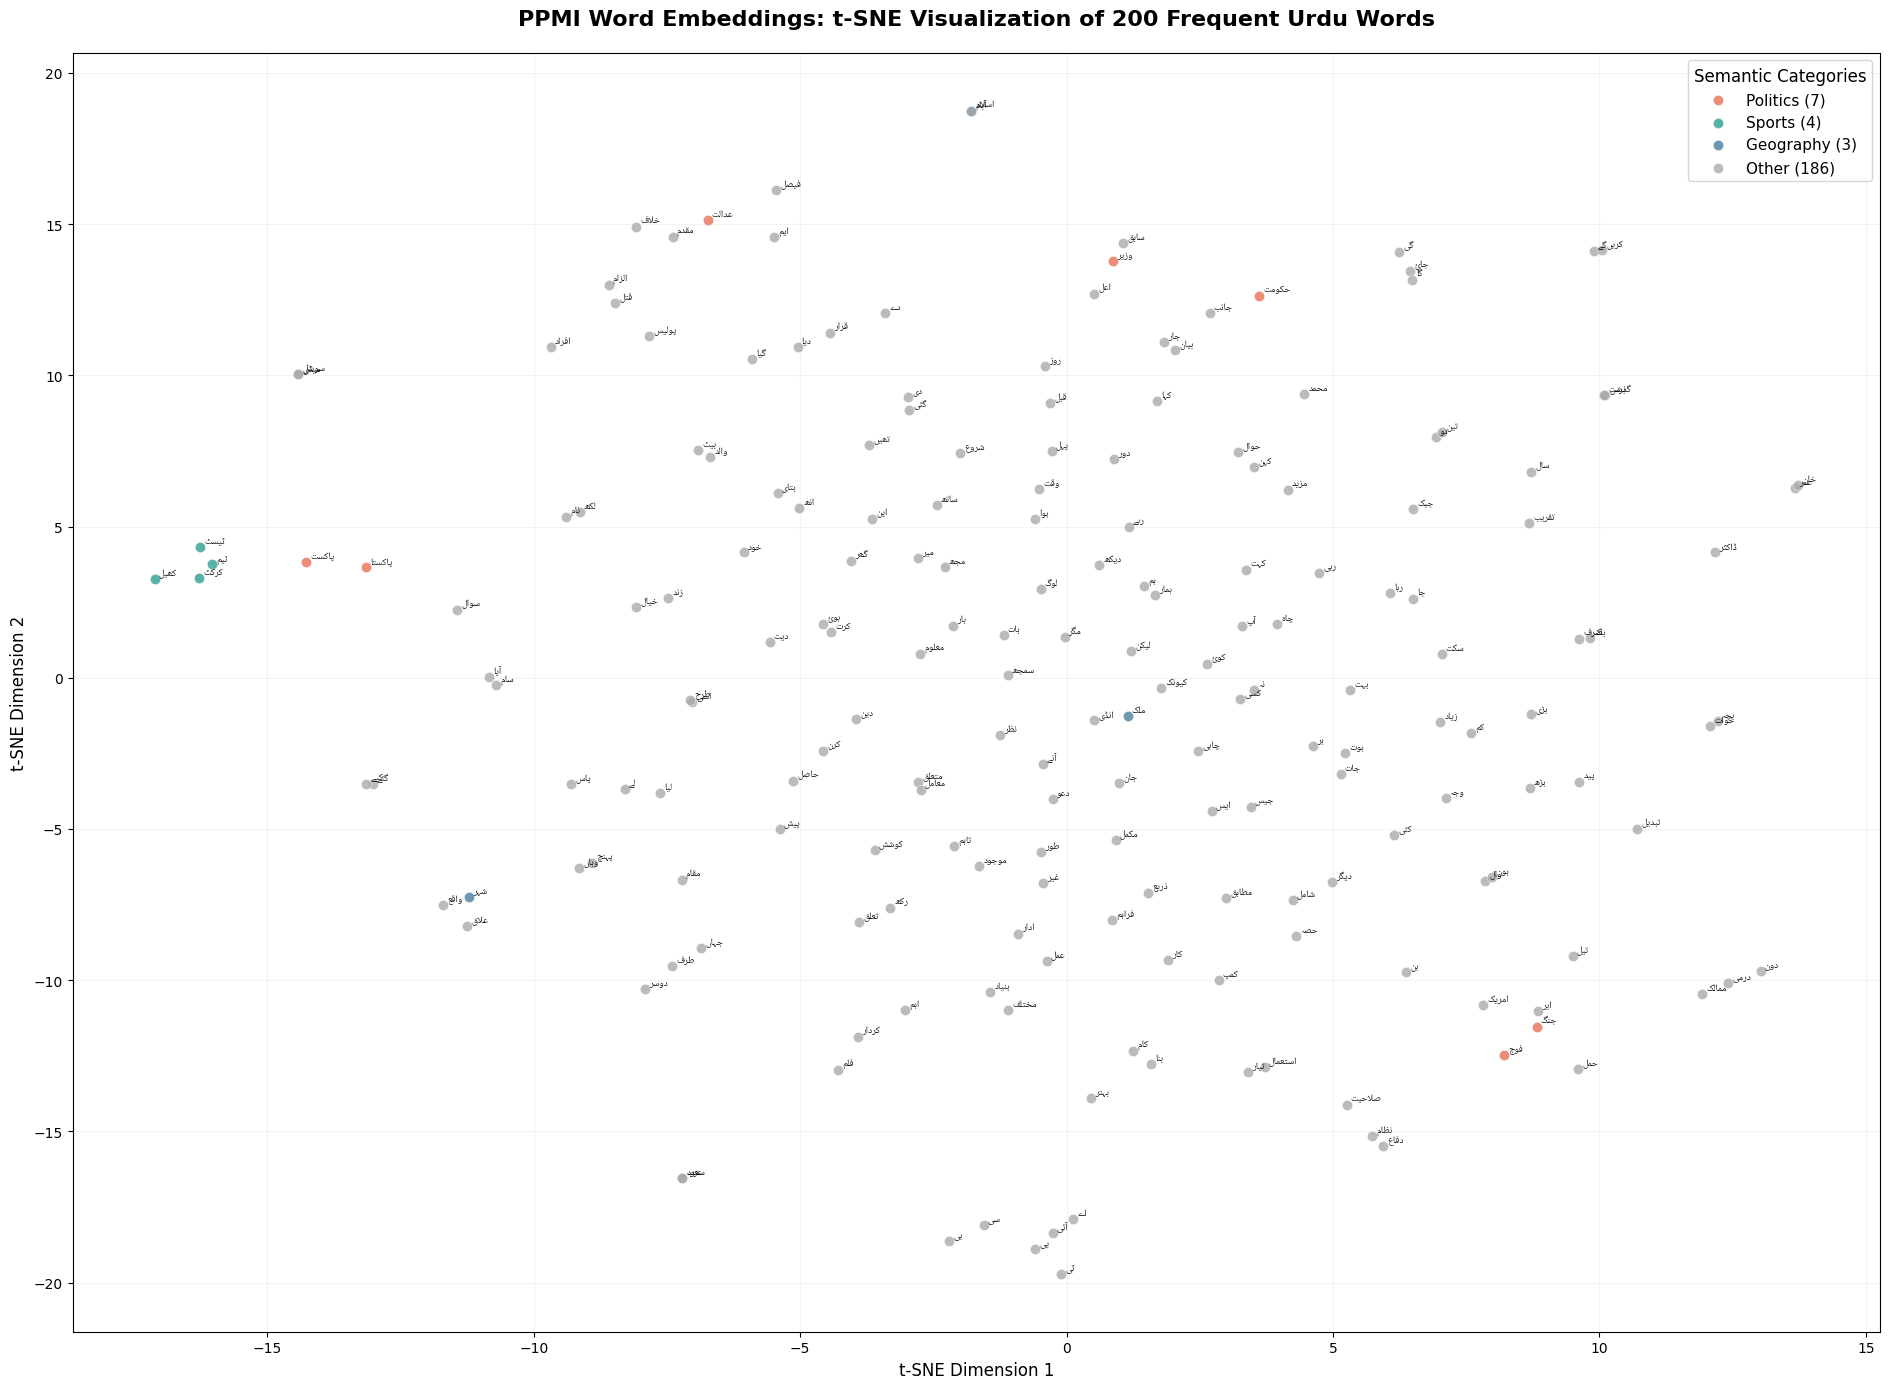


========== VISUALIZATION COMPLETE ==========
Selected words: 200
Categories: 4
PNG saved: /content/BBC_Urdu_NLP_Assignment2/part1_ppmi/ppmi_tsne_200_words_improved.png
Category CSV saved: /content/BBC_Urdu_NLP_Assignment2/part1_ppmi/ppmi_tsne_200_word_categories.csv

Category counts:
category
Other        186
Politics       7
Sports         4
Geography      3
Name: count, dtype: int64


In [24]:

# ============================================================
# PPMI: IMPROVED URDU t-SNE VISUALIZATION
# Reuses saved PPMI outputs. Does NOT recalculate PPMI.
# ============================================================

import os
import sys
import json
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

from sklearn.decomposition import TruncatedSVD
from sklearn.manifold import TSNE
from sklearn.preprocessing import normalize

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

BASE_DIR = "/content/BBC_Urdu_NLP_Assignment2/part1_ppmi"

# If your previous PPMI files are in another folder,
# change BASE_DIR to that folder.

MATRIX_PATH = os.path.join(BASE_DIR, "ppmi_matrix.npy")
VOCAB_PATH = os.path.join(BASE_DIR, "ppmi_vocabulary.json")
FREQ_PATH = os.path.join(BASE_DIR, "word_frequencies.csv")

OUTPUT_PATH = os.path.join(BASE_DIR, "ppmi_tsne_200_words_improved.png")

# ------------------------------------------------------------
# 2. CHECK EXISTING FILES
# ------------------------------------------------------------

for path in [MATRIX_PATH, VOCAB_PATH, FREQ_PATH]:
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Required file not found: {path}\n"
            "Please update BASE_DIR to your existing PPMI output folder."
        )

ppmi = np.load(MATRIX_PATH)

with open(VOCAB_PATH, "r", encoding="utf-8") as f:
    vocab_data = json.load(f)

freq_df = pd.read_csv(FREQ_PATH)

print("PPMI matrix:", ppmi.shape)
print("Frequency records:", len(freq_df))

# ------------------------------------------------------------
# 3. LOAD VOCABULARY ROBUSTLY
# ------------------------------------------------------------

if isinstance(vocab_data, dict):
    # Handle a normal word-to-index dictionary
    if all(isinstance(v, (int, float)) for v in vocab_data.values()):
        word_to_idx = {
            str(word): int(index)
            for word, index in vocab_data.items()
        }

    # Handle a nested vocabulary dictionary
    elif "word_to_idx" in vocab_data:
        word_to_idx = {
            str(word): int(index)
            for word, index in vocab_data["word_to_idx"].items()
        }

    elif "vocabulary" in vocab_data:
        inner = vocab_data["vocabulary"]
        word_to_idx = {
            str(word): int(index)
            for word, index in inner.items()
        }

    else:
        raise ValueError(
            "Unrecognized vocabulary JSON structure. "
            "Please inspect ppmi_vocabulary.json."
        )

elif isinstance(vocab_data, list):
    word_to_idx = {
        str(word): i for i, word in enumerate(vocab_data)
    }

else:
    raise ValueError("Unsupported vocabulary format.")

# ------------------------------------------------------------
# 4. IDENTIFY FREQUENCY COLUMNS
# ------------------------------------------------------------

word_col = next(
    (c for c in freq_df.columns
     if c.lower() in ["word", "token", "term"]),
    None
)

freq_col = next(
    (c for c in freq_df.columns
     if c.lower() in ["frequency", "count", "freq"]),
    None
)

if word_col is None:
    word_col = freq_df.select_dtypes(
        include=["object"]
    ).columns[0]

if freq_col is None:
    numeric_cols = freq_df.select_dtypes(
        include=[np.number]
    ).columns.tolist()

    if not numeric_cols:
        raise ValueError("Could not identify frequency column.")

    freq_col = numeric_cols[0]

freq_df = freq_df.sort_values(
    freq_col, ascending=False
)

# Select the 200 most frequent words present in PPMI vocabulary
top_words = []

for word in freq_df[word_col].astype(str):
    if word in word_to_idx and word not in top_words:
        top_words.append(word)

    if len(top_words) == 200:
        break

if len(top_words) < 200:
    raise ValueError(
        f"Only {len(top_words)} matching words found; "
        "200 are required."
    )

print("Selected words:", len(top_words))

# ------------------------------------------------------------
# 5. ASSIGN DOCUMENTED SEMANTIC CATEGORIES
# ------------------------------------------------------------

category_keywords = {
    "Politics": [
        "حکومت", "وزیر", "صدر", "پارلیمنٹ", "انتخاب",
        "سیاسی", "سیاست", "قومی", "اسمبلی", "عدالت",
        "حزب", "لیگ", "تحریک", "پاکستان", "پاکست",
        "امریکہ", "بھارت", "چین", "جنگ", "فوج",
        "قانون", "وزارت", "مذاکرات", "مقدمہ"
    ],

    "Sports": [
        "کرکٹ", "ٹیم", "میچ", "کھلاڑی", "کھیل",
        "فٹبال", "ٹیسٹ", "رنز", "وکٹ", "بیٹنگ",
        "بولنگ", "کپتان", "ٹورنامنٹ", "چیمپئن",
        "سکور", "ورلڈ", "لیگ", "اولمپک"
    ],

    "Geography": [
        "شہر", "ملک", "صوبہ", "صوب", "لاہور",
        "کراچی", "اسلام", "پشاور", "کوئٹہ",
        "افغانستان", "ایران", "یورپ", "ایشیا",
        "علاقہ", "سرحد", "دریا", "سمندر",
        "پہاڑ", "گاؤں", "دارالحکومت"
    ]
}

def assign_category(word):
    word = str(word).strip()

    for category, keywords in category_keywords.items():
        if word in keywords:
            return category

        # Match common Urdu word stems where appropriate
        if any(
            len(keyword) >= 4 and word.startswith(keyword)
            for keyword in keywords
        ):
            return category

    return "Other"

categories = [assign_category(w) for w in top_words]

print("\nCategory distribution:")
print(pd.Series(categories).value_counts())

# ------------------------------------------------------------
# 6. PREPARE PPMI VECTORS
# ------------------------------------------------------------

indices = [word_to_idx[w] for w in top_words]

X = ppmi[indices, :].astype(np.float32)

# Normalize rows before dimensionality reduction
X = normalize(X, norm="l2")

# Reduce dimensions before t-SNE
svd_components = min(50, X.shape[0] - 1, X.shape[1] - 1)

X_reduced = TruncatedSVD(
    n_components=svd_components,
    random_state=42
).fit_transform(X)

print("\nSVD output shape:", X_reduced.shape)

# ------------------------------------------------------------
# 7. COMPUTE t-SNE
# ------------------------------------------------------------

print("\nCalculating t-SNE coordinates...")

tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    max_iter=1000,
    random_state=42
)

coordinates = tsne.fit_transform(X_reduced)

print("t-SNE completed:", coordinates.shape)

# ------------------------------------------------------------
# 8. INSTALL URDU TEXT SUPPORT
# ------------------------------------------------------------

try:
    import arabic_reshaper
    from bidi.algorithm import get_display
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip",
        "install", "-q", "arabic-reshaper", "python-bidi"
    ])

    import arabic_reshaper
    from bidi.algorithm import get_display

# Locate a suitable Urdu/Arabic font
font_candidates = [
    "/usr/share/fonts/truetype/noto/NotoNaskhArabic-Regular.ttf",
    "/usr/share/fonts/truetype/noto/NotoSansArabic-Regular.ttf",
    "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf"
]

font_path = next(
    (p for p in font_candidates if os.path.exists(p)),
    None
)

if font_path is None:
    try:
        subprocess.run(
            ["apt-get", "update", "-qq"],
            check=True
        )
        subprocess.run(
            ["apt-get", "install", "-y", "-qq", "fonts-noto-core"],
            check=True
        )
    except Exception as e:
        print("Font installation warning:", e)

    font_path = next(
        (p for p in font_candidates if os.path.exists(p)),
        None
    )

if font_path is None:
    raise RuntimeError(
        "No suitable Urdu font found. "
        "Install Noto Naskh Arabic or another Urdu-compatible font."
    )

urdu_font = fm.FontProperties(fname=font_path)

def shape_urdu(text):
    reshaped = arabic_reshaper.reshape(str(text))
    return get_display(reshaped)

print("Urdu font:", font_path)

# ------------------------------------------------------------
# 9. DRAW CATEGORY-COLOURED t-SNE
# ------------------------------------------------------------

plt.figure(figsize=(19, 14))

category_order = [
    "Politics", "Sports", "Geography", "Other"
]

category_colors = {
    "Politics": "#E76F51",
    "Sports": "#2A9D8F",
    "Geography": "#457B9D",
    "Other": "#A8A8A8"
}

for category in category_order:

    selected = [
        i for i, c in enumerate(categories)
        if c == category
    ]

    if not selected:
        continue

    plt.scatter(
        coordinates[selected, 0],
        coordinates[selected, 1],
        s=55,
        alpha=0.78,
        color=category_colors[category],
        label=f"{category} ({len(selected)})",
        edgecolors="white",
        linewidths=0.4
    )

# Urdu word labels
for i, word in enumerate(top_words):
    plt.annotate(
        shape_urdu(word),
        (coordinates[i, 0], coordinates[i, 1]),
        xytext=(3, 3),
        textcoords="offset points",
        fontsize=7,
        fontproperties=urdu_font,
        alpha=0.9
    )

plt.title(
    "PPMI Word Embeddings: t-SNE Visualization of 200 Frequent Urdu Words",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.xlabel("t-SNE Dimension 1", fontsize=12)
plt.ylabel("t-SNE Dimension 2", fontsize=12)

plt.legend(
    title="Semantic Categories",
    fontsize=11,
    title_fontsize=12,
    loc="best",
    frameon=True
)

plt.grid(alpha=0.15)
plt.tight_layout()

plt.savefig(
    OUTPUT_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 10. SAVE WORD-LEVEL CATEGORY ASSIGNMENTS
# ------------------------------------------------------------

results_df = pd.DataFrame({
    "word": top_words,
    "category": categories,
    "tsne_x": coordinates[:, 0],
    "tsne_y": coordinates[:, 1]
})

results_csv = os.path.join(
    BASE_DIR, "ppmi_tsne_200_word_categories.csv"
)

results_df.to_csv(
    results_csv,
    index=False,
    encoding="utf-8-sig"
)

print("\n========== VISUALIZATION COMPLETE ==========")
print("Selected words:", len(top_words))
print("Categories:", results_df["category"].nunique())
print("PNG saved:", OUTPUT_PATH)
print("Category CSV saved:", results_csv)
print("\nCategory counts:")
print(results_df["category"].value_counts())


PPMI matrix verified: (3000, 3000)

Updated category distribution:
category
Other        184
Politics       8
Sports         5
Geography      3
Name: count, dtype: int64


/tmp/ipykernel_808/2702165713.py:290: UserWarning: Glyph 108 (l) missing from font(s) Noto Naskh Arabic.
  plt.tight_layout()
/tmp/ipykernel_808/2702165713.py:290: UserWarning: Glyph 112 (p) missing from font(s) Noto Naskh Arabic.
  plt.tight_layout()
/tmp/ipykernel_808/2702165713.py:296: UserWarning: Glyph 108 (l) missing from font(s) Noto Naskh Arabic.
  plt.savefig(
/tmp/ipykernel_808/2702165713.py:296: UserWarning: Glyph 112 (p) missing from font(s) Noto Naskh Arabic.
  plt.savefig(
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 108 (l) missing from font(s) Noto Naskh Arabic.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 112 (p) missing from font(s) Noto Naskh Arabic.
  fig.canvas.print_figure(bytes_io, **kw)


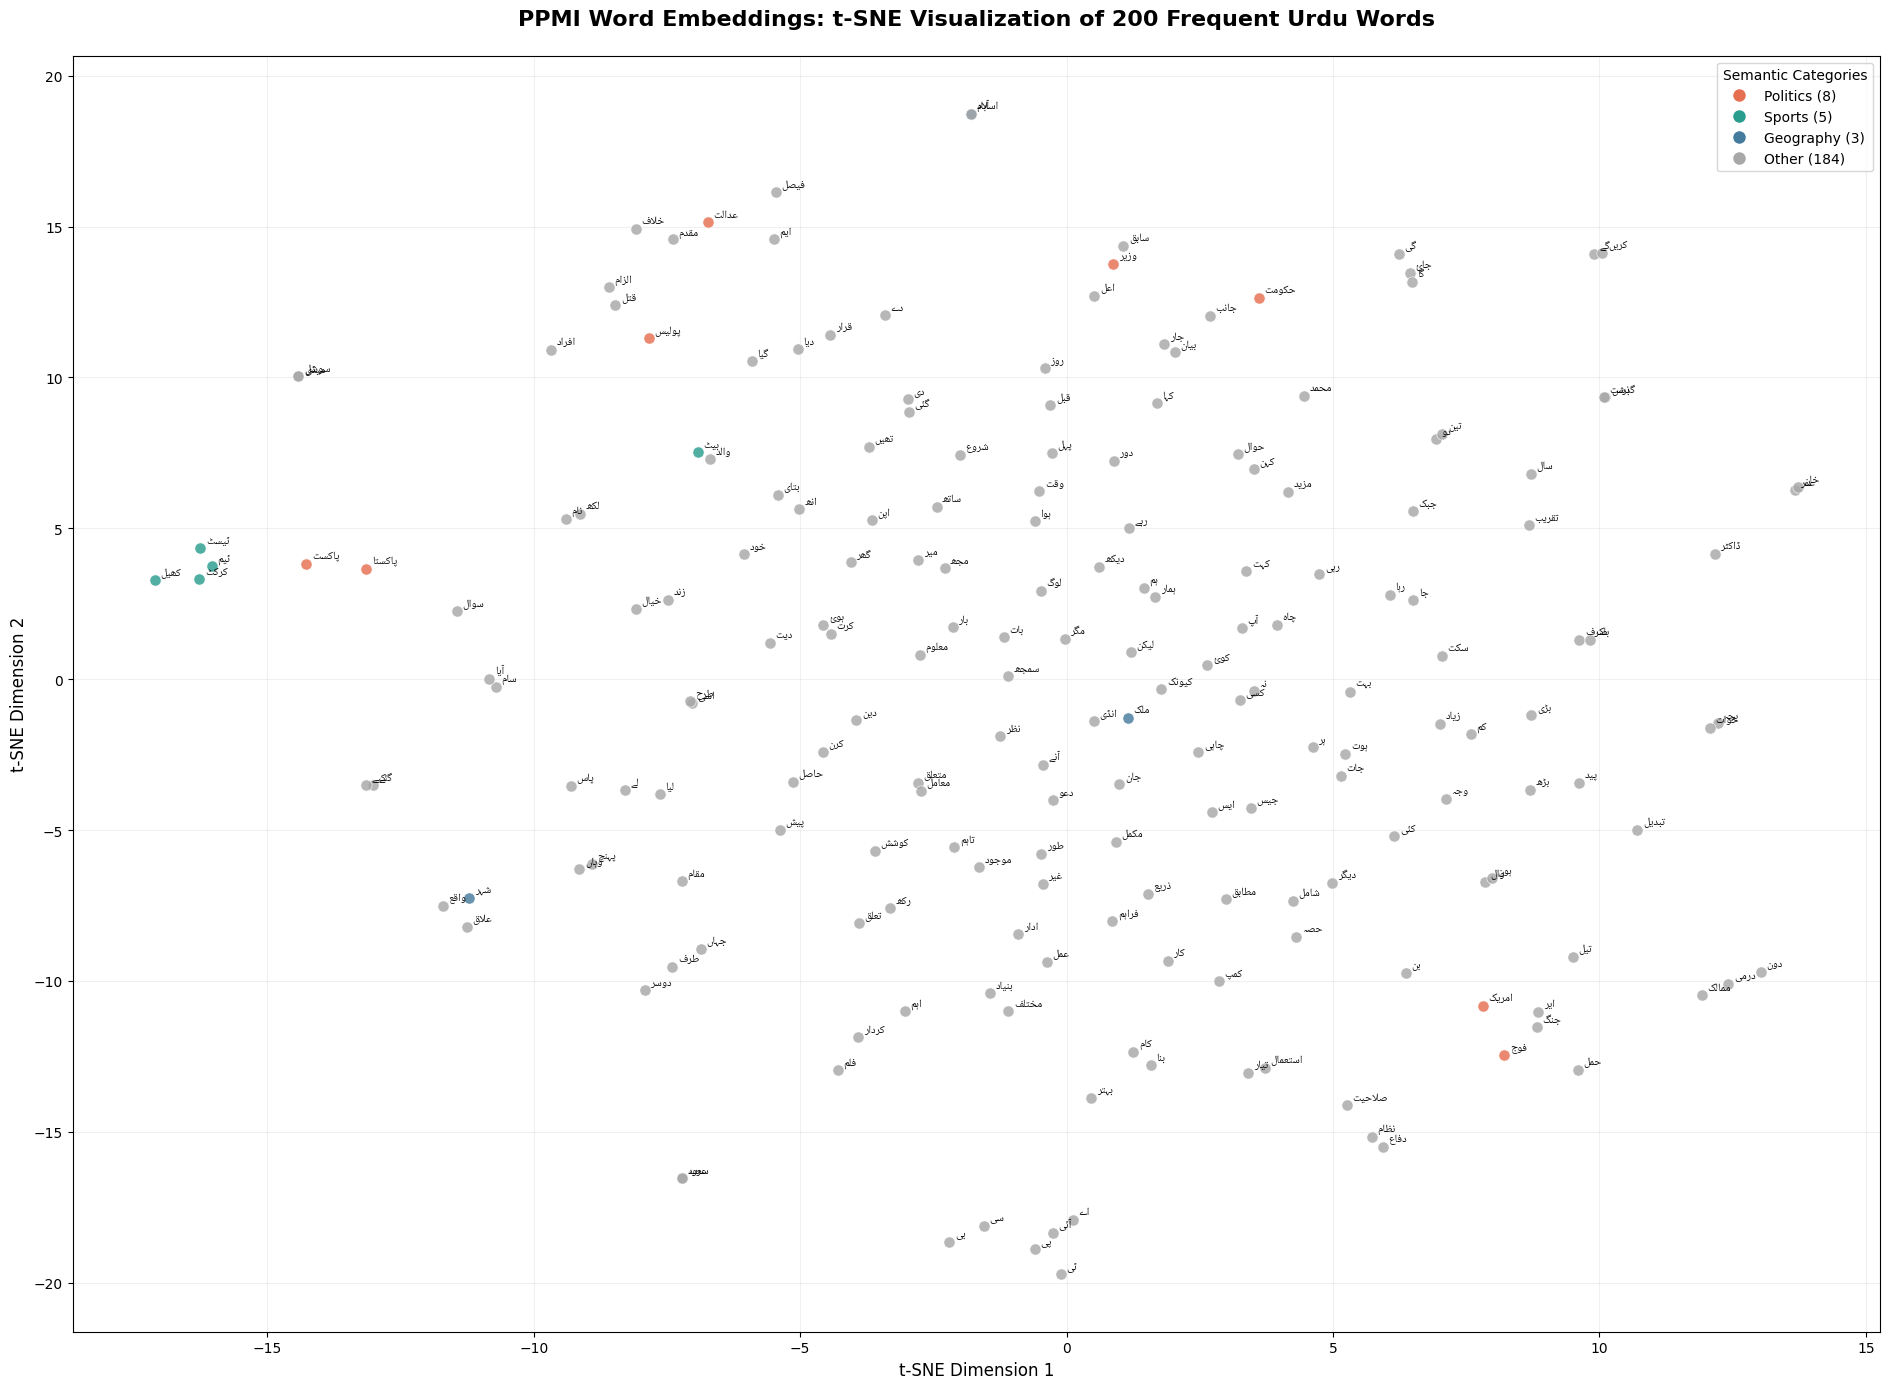


========== FINAL VISUALIZATION ==========
PPMI matrix reused: (3000, 3000)
Existing t-SNE coordinates reused: 200
Final PNG: /content/BBC_Urdu_NLP_Assignment2/part1_ppmi/ppmi_tsne_200_words_final.png
Final category CSV: /content/BBC_Urdu_NLP_Assignment2/part1_ppmi/ppmi_tsne_200_word_categories_final.csv

Final category counts:
category
Other        184
Politics       8
Sports         5
Geography      3
Name: count, dtype: int64

Visualization completed.


In [25]:

# ============================================================
# FINAL PPMI t-SNE VISUALIZATION IMPROVEMENT
# Reuses saved PPMI matrix and existing t-SNE coordinates
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

from matplotlib.lines import Line2D

BASE_DIR = "/content/BBC_Urdu_NLP_Assignment2/part1_ppmi"

MATRIX_PATH = os.path.join(BASE_DIR, "ppmi_matrix.npy")
VOCAB_PATH = os.path.join(BASE_DIR, "ppmi_vocabulary.json")
FREQ_PATH = os.path.join(BASE_DIR, "word_frequencies.csv")

OLD_COORDS = os.path.join(
    BASE_DIR, "ppmi_tsne_200_word_categories.csv"
)

OUTPUT_PNG = os.path.join(
    BASE_DIR, "ppmi_tsne_200_words_final.png"
)

OUTPUT_CSV = os.path.join(
    BASE_DIR, "ppmi_tsne_200_word_categories_final.csv"
)

# ------------------------------------------------------------
# 1. VERIFY EXISTING OUTPUTS
# ------------------------------------------------------------

for path in [
    MATRIX_PATH, VOCAB_PATH, FREQ_PATH, OLD_COORDS
]:
    if not os.path.exists(path):
        raise FileNotFoundError(path)

ppmi = np.load(MATRIX_PATH)

with open(VOCAB_PATH, "r", encoding="utf-8") as f:
    vocab_data = json.load(f)

print("PPMI matrix verified:", ppmi.shape)

# ------------------------------------------------------------
# 2. LOAD EXISTING 200 WORDS AND COORDINATES
# ------------------------------------------------------------

df = pd.read_csv(OLD_COORDS)

required = {"word", "tsne_x", "tsne_y"}
if not required.issubset(df.columns):
    raise ValueError("Existing t-SNE CSV has unexpected columns.")

if len(df) != 200:
    raise ValueError("Expected exactly 200 existing t-SNE points.")

# ------------------------------------------------------------
# 3. EXPANDED SEMANTIC KEYWORD DICTIONARY
# ------------------------------------------------------------

category_keywords = {

    "Politics": [
        "حکومت", "حکوم", "وزیر", "وزارت", "صدر",
        "پارلیمنٹ", "اسمبلی", "انتخاب", "سیاسی",
        "سیاست", "سیاس", "جمہوریت", "قانون",
        "عدالت", "عدال", "پارٹی", "حزب",
        "تحریک", "لیگ", "مذاکرات", "معاہدہ",
        "پاکستان", "پاکست", "امریکہ", "امریک",
        "بھارت", "چین", "ایران", "افغانستان",
        "فوج", "عسکری", "سینیٹ", "قومی",
        "حکمران", "اپوزیشن", "حکومتی", "انتظامیہ",
        "پولیس", "مقدمہ", "سیاستدان", "وزیراعظم",
        "صدر", "انتخابی", "پارلیمانی", "جمہوری"
    ],

    "Sports": [
        "کرکٹ", "ٹیم", "میچ", "کھلاڑی", "کھیل",
        "فٹبال", "ٹیسٹ", "رنز", "وکٹ", "بیٹنگ",
        "بولنگ", "کپتان", "ٹورنامنٹ", "چیمپئن",
        "سکور", "اسکور", "ورلڈ", "لیگ", "اولمپک",
        "فائنل", "سیریز", "گول", "فٹ", "پلیئر",
        "کوچ", "بیٹ", "گیند", "اسٹیڈیم",
        "مقابلہ", "کھیلوں", "پاکستانی", "اننگز",
        "شکست", "فتح", "رن", "کرکٹر", "ٹرافی",
        "ریس", "میدان", "ٹینس", "ہاکی", "فٹبالر"
    ],

    "Geography": [
        "شہر", "ملک", "صوبہ", "لاہور", "کراچی",
        "اسلام", "پشاور", "کوئٹہ", "افغانستان",
        "ایران", "یورپ", "ایشیا", "علاقہ",
        "سرحد", "دریا", "سمندر", "پہاڑ",
        "گاؤں", "دارالحکومت", "آبادی", "خطہ",
        "مشرق", "مغرب", "شمال", "جنوب",
        "جزیرہ", "صحر", "براعظم", "ساحل",
        "قصبہ", "وادی", "صوبائی", "ملکی",
        "زمین", "موسم", "بحیرہ", "پنجاب",
        "سندھ", "بلوچستان", "خیبر", "مقامی",
        "سرحدی", "علاقائی", "شمالی", "جنوبی"
    ]
}

# ------------------------------------------------------------
# 4. IMPROVED CATEGORY ASSIGNMENT
# ------------------------------------------------------------

def classify_word(word):

    word = str(word).strip()

    scores = {}

    for category, keywords in category_keywords.items():

        score = 0

        for keyword in keywords:

            if word == keyword:
                score += 3

            elif len(keyword) >= 4 and word.startswith(keyword):
                score += 1

        scores[category] = score

    best_category = max(scores, key=scores.get)

    if scores[best_category] == 0:
        return "Other"

    return best_category


df["category"] = df["word"].apply(classify_word)

print("\nUpdated category distribution:")
print(df["category"].value_counts())

# ------------------------------------------------------------
# 5. LOAD SEPARATE URDU AND ENGLISH FONTS
# ------------------------------------------------------------

urdu_font_path = (
    "/usr/share/fonts/truetype/noto/"
    "NotoNaskhArabic-Regular.ttf"
)

if not os.path.exists(urdu_font_path):
    raise FileNotFoundError(
        "Noto Naskh Arabic font not found."
    )

urdu_font = fm.FontProperties(
    fname=urdu_font_path
)

# English font: use DejaVu Sans
english_font = fm.FontProperties(
    family="DejaVu Sans"
)

# ------------------------------------------------------------
# 6. URDU TEXT SHAPING
# ------------------------------------------------------------

try:
    import arabic_reshaper
    from bidi.algorithm import get_display

except ImportError:
    raise ImportError(
        "Install arabic-reshaper and python-bidi first."
    )

def shape_urdu(word):
    return get_display(
        arabic_reshaper.reshape(str(word))
    )

# ------------------------------------------------------------
# 7. PLOT EXISTING t-SNE COORDINATES
# ------------------------------------------------------------

category_colors = {
    "Politics": "#E76F51",
    "Sports": "#2A9D8F",
    "Geography": "#457B9D",
    "Other": "#A8A8A8"
}

fig, ax = plt.subplots(figsize=(19, 14))

for category in [
    "Politics", "Sports", "Geography", "Other"
]:

    subset = df[df["category"] == category]

    if subset.empty:
        continue

    ax.scatter(
        subset["tsne_x"],
        subset["tsne_y"],
        s=65,
        alpha=0.82,
        color=category_colors[category],
        edgecolors="white",
        linewidths=0.5,
        zorder=2
    )

# ------------------------------------------------------------
# 8. ADD URDU WORD LABELS
# ------------------------------------------------------------

for _, row in df.iterrows():

    ax.annotate(
        shape_urdu(row["word"]),
        (row["tsne_x"], row["tsne_y"]),
        xytext=(4, 4),
        textcoords="offset points",
        fontproperties=urdu_font,
        fontsize=8,
        alpha=0.95,
        zorder=3
    )

# ------------------------------------------------------------
# 9. ENGLISH TITLE, AXES AND LEGEND
# ------------------------------------------------------------

ax.set_title(
    "PPMI Word Embeddings: t-SNE Visualization of 200 Frequent Urdu Words",
    fontproperties=english_font,
    fontsize=16,
    fontweight="bold",
    pad=22
)

ax.set_xlabel(
    "t-SNE Dimension 1",
    fontproperties=english_font,
    fontsize=12
)

ax.set_ylabel(
    "t-SNE Dimension 2",
    fontproperties=english_font,
    fontsize=12
)

legend_handles = []

for category, color in category_colors.items():

    count = (df["category"] == category).sum()

    if count > 0:
        legend_handles.append(
            Line2D(
                [0], [0],
                marker="o",
                color="w",
                label=f"{category} ({count})",
                markerfacecolor=color,
                markersize=10
            )
        )

ax.legend(
    handles=legend_handles,
    title="Semantic Categories",
    prop=english_font,
    title_fontproperties=english_font,
    loc="best",
    frameon=True
)

ax.grid(alpha=0.18)
plt.tight_layout()

# ------------------------------------------------------------
# 10. SAVE FINAL OUTPUTS
# ------------------------------------------------------------

plt.savefig(
    OUTPUT_PNG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

df.to_csv(
    OUTPUT_CSV,
    index=False,
    encoding="utf-8-sig"
)

print("\n========== FINAL VISUALIZATION ==========")
print("PPMI matrix reused:", ppmi.shape)
print("Existing t-SNE coordinates reused:", len(df))
print("Final PNG:", OUTPUT_PNG)
print("Final category CSV:", OUTPUT_CSV)

print("\nFinal category counts:")
print(df["category"].value_counts())

print("\nVisualization completed.")


Device: cuda

========== CORPUS INFORMATION ==========
Non-empty tokenized lines: 246
Total tokens: 382689
Unique tokens: 11124
Vocabulary size: 11124

========== TRAINING PAIRS ==========
Positive pairs: 3819510
Context window: 5
Negative sampling distribution prepared.
Negative samples per positive pair: 10

Model initialized.
Centre matrix V: (11124, 100)
Context matrix U: (11124, 100)

========== STARTING TRAINING ==========
Epoch 1/5 | Batch 500 | Loss: 3.47499
Epoch 1/5 | Batch 1000 | Loss: 3.34446
Epoch 1/5 | Batch 1500 | Loss: 3.32670
Epoch 1/5 | Batch 2000 | Loss: 3.20811
Epoch 1/5 | Batch 2500 | Loss: 3.20507
Epoch 1/5 | Batch 3000 | Loss: 3.18400
Epoch 1/5 | Batch 3500 | Loss: 3.15254
Epoch 1/5 | Batch 4000 | Loss: 3.16251
Epoch 1/5 | Batch 4500 | Loss: 3.14535
Epoch 1/5 | Batch 5000 | Loss: 3.14614
Epoch 1/5 | Batch 5500 | Loss: 3.14057
Epoch 1/5 | Batch 6000 | Loss: 3.16833
Epoch 1/5 | Batch 6500 | Loss: 3.09101
Epoch 1/5 | Batch 7000 | Loss: 3.08267

Epoch 1/5 completed |

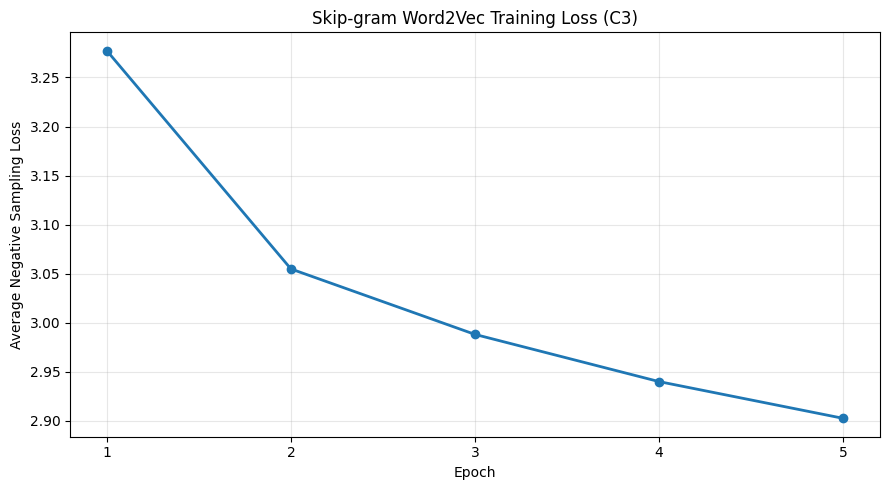


========== FINAL VERIFICATION ==========
Vocabulary size: 11124
Positive training pairs: 3819510
Embedding shape: (11124, 100)
Expected dimension: 100
Training epochs: 5
Batch size: 512
Negative samples: 10
All embeddings finite: True
Embedding file exists: True

Epoch losses:
Epoch 1: 3.277291
Epoch 2: 3.054796
Epoch 3: 2.988034
Epoch 4: 2.939921
Epoch 5: 2.902468

Saved output directory: /content/BBC_Urdu_NLP_Assignment2/part1_word2vec/C3_cleaned_d100
WORD2VEC C3 TRAINING COMPLETED.


In [26]:

# ============================================================
# DS 5007 ASSIGNMENT 2
# PART 1.3 - SKIP-GRAM WORD2VEC (CONDITION C3)
# Corpus: cleaned.txt
# ============================================================

import os
import re
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from collections import Counter

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

PROJECT_DIR = "/content/BBC_Urdu_NLP_Assignment2"
INPUT_FILE = os.path.join(PROJECT_DIR, "data", "cleaned.txt")

OUTPUT_DIR = os.path.join(
    PROJECT_DIR, "part1_word2vec", "C3_cleaned_d100"
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

EMBEDDING_DIM = 100
WINDOW_SIZE = 5
NEGATIVE_SAMPLES = 10
BATCH_SIZE = 512
LEARNING_RATE = 0.001
EPOCHS = 5

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

# ------------------------------------------------------------
# 2. LOAD AND TOKENIZE CLEANED CORPUS
# ------------------------------------------------------------

if not os.path.exists(INPUT_FILE):
    raise FileNotFoundError(INPUT_FILE)

with open(INPUT_FILE, "r", encoding="utf-8") as f:
    corpus_text = f.read()

# Urdu/Arabic Unicode character range
TOKEN_PATTERN = re.compile(r"[\u0600-\u06FF]+")

# Preserve line boundaries to avoid creating artificial
# context pairs across unrelated paragraphs.
lines = corpus_text.splitlines()

tokenized_lines = []

for line in lines:
    tokens = TOKEN_PATTERN.findall(line)

    if len(tokens) >= 2:
        tokenized_lines.append(tokens)

all_tokens = [
    token for line in tokenized_lines
    for token in line
]

print("\n========== CORPUS INFORMATION ==========")
print("Non-empty tokenized lines:", len(tokenized_lines))
print("Total tokens:", len(all_tokens))
print("Unique tokens:", len(set(all_tokens)))

# ------------------------------------------------------------
# 3. BUILD VOCABULARY
# ------------------------------------------------------------

word_counts = Counter(all_tokens)

vocabulary = sorted(
    word_counts.keys(),
    key=lambda word: (-word_counts[word], word)
)

word_to_idx = {
    word: index
    for index, word in enumerate(vocabulary)
}

idx_to_word = vocabulary

vocab_size = len(vocabulary)

print("Vocabulary size:", vocab_size)

# Save vocabulary and frequencies
with open(
    os.path.join(OUTPUT_DIR, "vocabulary.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(word_to_idx, f, ensure_ascii=False, indent=2)

pd.DataFrame({
    "word": vocabulary,
    "frequency": [word_counts[w] for w in vocabulary]
}).to_csv(
    os.path.join(OUTPUT_DIR, "word_frequencies.csv"),
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 4. GENERATE SKIP-GRAM POSITIVE PAIRS
# ------------------------------------------------------------

positive_pairs = []

for tokens in tokenized_lines:

    ids = [word_to_idx[w] for w in tokens]

    for center_position, center_id in enumerate(ids):

        left = max(0, center_position - WINDOW_SIZE)
        right = min(
            len(ids),
            center_position + WINDOW_SIZE + 1
        )

        for context_position in range(left, right):

            if context_position == center_position:
                continue

            context_id = ids[context_position]

            positive_pairs.append(
                (center_id, context_id)
            )

positive_pairs = np.asarray(
    positive_pairs,
    dtype=np.int64
)

if len(positive_pairs) == 0:
    raise ValueError("No Skip-gram training pairs generated.")

print("\n========== TRAINING PAIRS ==========")
print("Positive pairs:", len(positive_pairs))
print("Context window:", WINDOW_SIZE)

# ------------------------------------------------------------
# 5. NEGATIVE SAMPLING DISTRIBUTION
# P(w) proportional to frequency(w)^0.75
# ------------------------------------------------------------

frequencies = np.array(
    [word_counts[word] for word in vocabulary],
    dtype=np.float64
)

noise_weights = frequencies ** 0.75

noise_probabilities = (
    noise_weights / noise_weights.sum()
)

noise_distribution = torch.tensor(
    noise_probabilities,
    dtype=torch.float32,
    device=DEVICE
)

print("Negative sampling distribution prepared.")
print("Negative samples per positive pair:", NEGATIVE_SAMPLES)

# ------------------------------------------------------------
# 6. SKIP-GRAM MODEL
# Separate centre matrix V and context matrix U
# ------------------------------------------------------------

class SkipGramNegativeSampling(nn.Module):

    def __init__(self, vocab_size, embedding_dim):

        super().__init__()

        self.V = nn.Embedding(
            vocab_size, embedding_dim
        )

        self.U = nn.Embedding(
            vocab_size, embedding_dim
        )

        # Standard small random initialization
        nn.init.uniform_(
            self.V.weight,
            -0.5 / embedding_dim,
            0.5 / embedding_dim
        )

        nn.init.zeros_(self.U.weight)

    def forward(self, centers, contexts, negatives):

        center_vectors = self.V(centers)

        positive_vectors = self.U(contexts)

        negative_vectors = self.U(negatives)

        # Positive dot products
        positive_scores = torch.sum(
            center_vectors * positive_vectors,
            dim=1
        )

        # Negative dot products
        negative_scores = torch.bmm(
            negative_vectors,
            center_vectors.unsqueeze(2)
        ).squeeze(2)

        # BCE with logits:
        # -log(sigmoid(positive))
        # -sum(log(sigmoid(-negative)))
        positive_loss = F.softplus(
            -positive_scores
        )

        negative_loss = F.softplus(
            negative_scores
        ).sum(dim=1)

        loss = (
            positive_loss + negative_loss
        ).mean()

        return loss


model = SkipGramNegativeSampling(
    vocab_size,
    EMBEDDING_DIM
).to(DEVICE)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

print("\nModel initialized.")
print("Centre matrix V:", tuple(model.V.weight.shape))
print("Context matrix U:", tuple(model.U.weight.shape))

# ------------------------------------------------------------
# 7. TRAINING
# ------------------------------------------------------------

pair_tensor = torch.from_numpy(positive_pairs)

number_of_pairs = len(pair_tensor)

epoch_losses = []
interval_losses = []

print("\n========== STARTING TRAINING ==========")

for epoch in range(EPOCHS):

    model.train()

    permutation = torch.randperm(number_of_pairs)

    total_loss = 0.0
    processed_pairs = 0
    batch_losses = []

    for start in range(
        0, number_of_pairs, BATCH_SIZE
    ):

        batch_indices = permutation[
            start:start + BATCH_SIZE
        ]

        batch = pair_tensor[batch_indices]

        centers = batch[:, 0].to(DEVICE)
        contexts = batch[:, 1].to(DEVICE)

        current_batch_size = len(centers)

        # Draw K negative samples per positive pair
        negatives = torch.multinomial(
            noise_distribution,
            num_samples=(
                current_batch_size * NEGATIVE_SAMPLES
            ),
            replacement=True
        ).view(
            current_batch_size,
            NEGATIVE_SAMPLES
        )

        optimizer.zero_grad(set_to_none=True)

        loss = model(
            centers,
            contexts,
            negatives
        )

        loss.backward()
        optimizer.step()

        loss_value = loss.item()

        total_loss += loss_value * current_batch_size
        processed_pairs += current_batch_size

        batch_losses.append(loss_value)

        if len(batch_losses) % 500 == 0:
            print(
                f"Epoch {epoch + 1}/{EPOCHS} | "
                f"Batch {len(batch_losses)} | "
                f"Loss: {loss_value:.5f}"
            )

    epoch_loss = total_loss / processed_pairs

    epoch_losses.append(epoch_loss)

    interval_losses.append({
        "epoch": epoch + 1,
        "average_loss": epoch_loss
    })

    print(
        f"\nEpoch {epoch + 1}/{EPOCHS} "
        f"completed | Average loss: {epoch_loss:.6f}"
    )

# ------------------------------------------------------------
# 8. SAVE AVERAGED EMBEDDINGS
# Final embedding = 0.5 * (V + U)
# ------------------------------------------------------------

model.eval()

with torch.no_grad():

    V = model.V.weight.detach().cpu().numpy()
    U = model.U.weight.detach().cpu().numpy()

    averaged_embeddings = 0.5 * (V + U)

embedding_path = os.path.join(
    OUTPUT_DIR, "embeddings_w2v.npy"
)

np.save(
    embedding_path,
    averaged_embeddings
)

# Save separate matrices for reproducibility
np.save(
    os.path.join(OUTPUT_DIR, "centre_embeddings_V.npy"),
    V
)

np.save(
    os.path.join(OUTPUT_DIR, "context_embeddings_U.npy"),
    U
)

# Save model checkpoint
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "vocabulary": word_to_idx,
        "embedding_dim": EMBEDDING_DIM,
        "window_size": WINDOW_SIZE,
        "negative_samples": NEGATIVE_SAMPLES,
        "learning_rate": LEARNING_RATE,
        "epochs": EPOCHS,
        "batch_size": BATCH_SIZE,
        "seed": SEED
    },
    os.path.join(OUTPUT_DIR, "skipgram_checkpoint.pth")
)

# ------------------------------------------------------------
# 9. SAVE TRAINING HISTORY
# ------------------------------------------------------------

history_df = pd.DataFrame(interval_losses)

history_df.to_csv(
    os.path.join(OUTPUT_DIR, "training_loss.csv"),
    index=False
)

# ------------------------------------------------------------
# 10. PLOT LOSS CURVE
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, EPOCHS + 1),
    epoch_losses,
    marker="o",
    linewidth=2
)

plt.title("Skip-gram Word2Vec Training Loss (C3)")
plt.xlabel("Epoch")
plt.ylabel("Average Negative Sampling Loss")
plt.xticks(range(1, EPOCHS + 1))
plt.grid(alpha=0.3)
plt.tight_layout()

loss_plot_path = os.path.join(
    OUTPUT_DIR, "word2vec_training_loss.png"
)

plt.savefig(
    loss_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 11. FINAL VERIFICATION
# ------------------------------------------------------------

print("\n========== FINAL VERIFICATION ==========")

print("Vocabulary size:", vocab_size)
print("Positive training pairs:", number_of_pairs)
print("Embedding shape:", averaged_embeddings.shape)
print("Expected dimension:", EMBEDDING_DIM)
print("Training epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Negative samples:", NEGATIVE_SAMPLES)

print(
    "All embeddings finite:",
    np.isfinite(averaged_embeddings).all()
)

print(
    "Embedding file exists:",
    os.path.exists(embedding_path)
)

print("\nEpoch losses:")
for i, loss_value in enumerate(epoch_losses, 1):
    print(f"Epoch {i}: {loss_value:.6f}")

print("\nSaved output directory:", OUTPUT_DIR)
print("WORD2VEC C3 TRAINING COMPLETED.")


In [27]:

# ============================================================
# DS 5007 - WORD2VEC EVALUATION (C3)
# Nearest Neighbours + 10 Analogy Tests
# Uses saved embeddings; NO retraining.
# ============================================================

import os
import json
import numpy as np
import pandas as pd

from sklearn.metrics.pairwise import cosine_similarity

# ------------------------------------------------------------
# 1. LOAD SAVED C3 EMBEDDINGS
# ------------------------------------------------------------

PROJECT_DIR = "/content/BBC_Urdu_NLP_Assignment2"

MODEL_DIR = os.path.join(
    PROJECT_DIR, "part1_word2vec", "C3_cleaned_d100"
)

EMBEDDING_PATH = os.path.join(
    MODEL_DIR, "embeddings_w2v.npy"
)

VOCAB_PATH = os.path.join(
    MODEL_DIR, "vocabulary.json"
)

OUTPUT_DIR = os.path.join(
    MODEL_DIR, "evaluation"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

embeddings = np.load(EMBEDDING_PATH)

with open(VOCAB_PATH, "r", encoding="utf-8") as f:
    word_to_idx = json.load(f)

idx_to_word = {
    int(index): word
    for word, index in word_to_idx.items()
}

print("Embedding shape:", embeddings.shape)
print("Vocabulary size:", len(word_to_idx))

assert embeddings.shape[0] == len(word_to_idx)

# ------------------------------------------------------------
# 2. NORMALIZE EMBEDDINGS FOR COSINE SIMILARITY
# ------------------------------------------------------------

norms = np.linalg.norm(
    embeddings, axis=1, keepdims=True
)

normalized_embeddings = embeddings / np.maximum(
    norms, 1e-12
)

# ------------------------------------------------------------
# 3. REQUIRED QUERY WORDS
# ------------------------------------------------------------

query_words = [
    "پاکستان",
    "حکومت",
    "عدالت",
    "معیشت",
    "فوج",
    "صحت",
    "تعلیم",
    "آبادی"
]

nearest_results = []
query_status = []

print("\n========== TOP-10 NEAREST NEIGHBOURS ==========")

for query in query_words:

    if query not in word_to_idx:

        print(f"\nWord: {query}")
        print("NOT FOUND in vocabulary.")

        # Suggest possible vocabulary matches
        suggestions = [
            w for w in word_to_idx
            if query[:3] in w or w[:3] == query[:3]
        ][:10]

        print("Possible alternatives:", suggestions)

        query_status.append({
            "query_word": query,
            "status": "Not found",
            "resolved_word": ""
        })

        continue

    query_idx = int(word_to_idx[query])

    query_vector = normalized_embeddings[
        query_idx
    ].reshape(1, -1)

    similarities = (
        normalized_embeddings @ query_vector.T
    ).flatten()

    # Exclude the query word itself
    similarities[query_idx] = -np.inf

    top_indices = np.argsort(
        similarities
    )[::-1][:10]

    print(f"\nWord: {query}")

    query_status.append({
        "query_word": query,
        "status": "Found",
        "resolved_word": query
    })

    for rank, idx in enumerate(top_indices, 1):

        neighbour = idx_to_word[int(idx)]
        similarity = float(similarities[idx])

        print(
            f"{rank:2d}. {neighbour} "
            f"(similarity: {similarity:.4f})"
        )

        nearest_results.append({
            "query_word": query,
            "rank": rank,
            "neighbour": neighbour,
            "cosine_similarity": similarity
        })

# Save nearest-neighbour results
nearest_df = pd.DataFrame(nearest_results)

nearest_csv = os.path.join(
    OUTPUT_DIR, "C3_nearest_neighbours_top10.csv"
)

nearest_df.to_csv(
    nearest_csv,
    index=False,
    encoding="utf-8-sig"
)

pd.DataFrame(query_status).to_csv(
    os.path.join(
        OUTPUT_DIR, "C3_query_word_availability.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 4. DEFINE 10 ANALOGY TESTS
#
# Formula:
# vector(b) - vector(a) + vector(c)
#
# Expected answers are manually specified for evaluation.
# The model is NOT given these expected answers.
# ------------------------------------------------------------

analogy_tests = [

    {
        "a": "پاکستان",
        "b": "کراچی",
        "c": "بھارت",
        "expected": "ممبئی",
        "relation": "Country-city"
    },

    {
        "a": "فرانس",
        "b": "پیرس",
        "c": "اٹلی",
        "expected": "روم",
        "relation": "Country-capital"
    },

    {
        "a": "مرد",
        "b": "عورت",
        "c": "لڑکا",
        "expected": "لڑکی",
        "relation": "Gender"
    },

    {
        "a": "والد",
        "b": "والدہ",
        "c": "بھائی",
        "expected": "بہن",
        "relation": "Family gender"
    },

    {
        "a": "دن",
        "b": "رات",
        "c": "صبح",
        "expected": "شام",
        "relation": "Time opposition"
    },

    {
        "a": "امیر",
        "b": "غریب",
        "c": "کامیاب",
        "expected": "ناکام",
        "relation": "Opposites"
    },

    {
        "a": "استاد",
        "b": "تعلیم",
        "c": "ڈاکٹر",
        "expected": "علاج",
        "relation": "Profession-activity"
    },

    {
        "a": "لاہور",
        "b": "پاکستان",
        "c": "دہلی",
        "expected": "بھارت",
        "relation": "City-country"
    },

    {
        "a": "کرکٹ",
        "b": "پاکستان",
        "c": "فٹبال",
        "expected": "برازیل",
        "relation": "Sport-country"
    },

    {
        "a": "صدر",
        "b": "حکومت",
        "c": "جج",
        "expected": "عدالت",
        "relation": "Role-institution"
    }
]

# ------------------------------------------------------------
# 5. ANALOGY EVALUATION FUNCTION
# ------------------------------------------------------------

def evaluate_analogy(a, b, c, expected, top_k=3):

    words = [a, b, c, expected]

    missing = [
        word for word in words
        if word not in word_to_idx
    ]

    if missing:

        return {
            "a": a,
            "b": b,
            "c": c,
            "expected": expected,
            "top1": "",
            "top2": "",
            "top3": "",
            "correct_top3": False,
            "status": "Missing: " + ", ".join(missing)
        }

    a_vec = embeddings[int(word_to_idx[a])]
    b_vec = embeddings[int(word_to_idx[b])]
    c_vec = embeddings[int(word_to_idx[c])]

    target_vector = b_vec - a_vec + c_vec

    target_norm = np.linalg.norm(target_vector)

    if target_norm < 1e-12:

        return {
            "a": a,
            "b": b,
            "c": c,
            "expected": expected,
            "top1": "",
            "top2": "",
            "top3": "",
            "correct_top3": False,
            "status": "Invalid analogy vector"
        }

    target_vector = target_vector / target_norm

    similarities = (
        normalized_embeddings @ target_vector
    )

    # Exclude input words from candidate answers
    for word in [a, b, c]:
        similarities[int(word_to_idx[word])] = -np.inf

    top_indices = np.argsort(
        similarities
    )[::-1][:top_k]

    predictions = [
        idx_to_word[int(idx)]
        for idx in top_indices
    ]

    is_correct = expected in predictions

    return {
        "a": a,
        "b": b,
        "c": c,
        "expected": expected,
        "top1": predictions[0],
        "top2": predictions[1],
        "top3": predictions[2],
        "correct_top3": is_correct,
        "status": "Evaluated"
    }

# ------------------------------------------------------------
# 6. RUN ALL ANALOGY TESTS
# ------------------------------------------------------------

analogy_results = []

print("\n========== WORD ANALOGY RESULTS ==========")

for i, test in enumerate(analogy_tests, 1):

    result = evaluate_analogy(
        test["a"],
        test["b"],
        test["c"],
        test["expected"]
    )

    result["test_number"] = i
    result["relation"] = test["relation"]

    analogy_results.append(result)

    print(f"\nTest {i}:")
    print(
        f'{test["a"]} : {test["b"]} :: '
        f'{test["c"]} : ?'
    )

    print("Expected answer:", test["expected"])

    if result["status"] == "Evaluated":

        print(
            "Top-3 predictions:",
            result["top1"],
            "|",
            result["top2"],
            "|",
            result["top3"]
        )

        print(
            "Correct in top-3:",
            result["correct_top3"]
        )

    else:
        print("Status:", result["status"])

# ------------------------------------------------------------
# 7. SAVE ANALOGY RESULTS
# ------------------------------------------------------------

analogy_df = pd.DataFrame(analogy_results)

analogy_csv = os.path.join(
    OUTPUT_DIR, "C3_analogy_results_top3.csv"
)

analogy_df.to_csv(
    analogy_csv,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 8. SUMMARY
# ------------------------------------------------------------

evaluated = analogy_df[
    analogy_df["status"] == "Evaluated"
]

correct = int(
    evaluated["correct_top3"].sum()
)

total_evaluated = len(evaluated)

print("\n========== EVALUATION SUMMARY ==========")

print(
    f"Nearest-neighbour queries found: "
    f"{sum(x['status'] == 'Found' for x in query_status)}/8"
)

print(
    f"Analogy tests evaluated: {total_evaluated}/10"
)

print(
    f"Correct analogy answers in top-3: "
    f"{correct}/{total_evaluated}"
)

if total_evaluated:
    print(
        "Top-3 analogy accuracy:",
        round(correct / total_evaluated * 100, 2),
        "%"
    )

print("\nSaved files:")
print(nearest_csv)
print(analogy_csv)

print("\nC3 WORD2VEC EVALUATION COMPLETED.")


Embedding shape: (11124, 100)
Vocabulary size: 11124

========== TOP-10 NEAREST NEIGHBOURS ==========

Word: پاکستان
 1. بنوای (similarity: 0.7805)
 2. آئیکونک (similarity: 0.7366)
 3. دانش (similarity: 0.7034)
 4. ہمیچ (similarity: 0.6940)
 5. راستہ (similarity: 0.6783)
 6. دل (similarity: 0.6719)
 7. اورکزئ (similarity: 0.6695)
 8. میری (similarity: 0.6585)
 9. اینجیل (similarity: 0.6556)
10. نثر (similarity: 0.6507)

Word: حکومت
 1. ہےک (similarity: 0.7393)
 2. پیٹرولیئم (similarity: 0.6646)
 3. بیف (similarity: 0.6548)
 4. معدانی (similarity: 0.6202)
 5. سد (similarity: 0.6143)
 6. ایڈورڈز (similarity: 0.6138)
 7. انصاف (similarity: 0.6025)
 8. موقف (similarity: 0.5952)
 9. دوٹوک (similarity: 0.5886)
10. انخل (similarity: 0.5856)

Word: عدالت
 1. دہشتگرد (similarity: 0.7892)
 2. ابوالحسن (similarity: 0.7789)
 3. درخواست (similarity: 0.7600)
 4. جج (similarity: 0.7556)
 5. ذوالقرن (similarity: 0.7538)
 6. پروسکیوٹر (similarity: 0.7400)
 7. چٹھ (similarity: 0.7278)
 8. استدع (similar

In [28]:

import os
import json
import numpy as np
import pandas as pd

MODEL_DIR = (
    "/content/BBC_Urdu_NLP_Assignment2/"
    "part1_word2vec/C3_cleaned_d100"
)

with open(
    os.path.join(MODEL_DIR, "vocabulary.json"),
    "r",
    encoding="utf-8"
) as f:
    word_to_idx = json.load(f)

embeddings = np.load(
    os.path.join(MODEL_DIR, "embeddings_w2v.npy")
)

freq_path = os.path.join(
    MODEL_DIR, "word_frequencies.csv"
)

freq_df = pd.read_csv(freq_path)

# ------------------------------------------------
# 1. CHECK IMPORTANT WORDS AND SPELLING VARIANTS
# ------------------------------------------------

candidate_words = [
    "پاکستان", "حکومت", "عدالت", "معیشت",
    "فوج", "صحت", "تعلیم", "آبادی",
    "آباد", "کراچی", "ممبئی", "بھارت",
    "فرانس", "پیرس", "اٹلی", "روم",
    "مرد", "عورت", "لڑکا", "لڑکی",
    "والد", "والدہ", "بھائی", "بہن",
    "دن", "رات", "صبح", "شام",
    "امیر", "غریب", "کامیاب", "ناکام",
    "استاد", "ڈاکٹر", "تعلیم", "علاج",
    "لاہور", "دہلی", "کرکٹ", "فٹبال",
    "برازیل", "صدر", "جج"
]

print("========== WORD AVAILABILITY ==========")

for word in candidate_words:
    status = "FOUND" if word in word_to_idx else "MISSING"
    print(f"{word:15s} : {status}")

# ------------------------------------------------
# 2. SHOW MOST FREQUENT WORDS
# ------------------------------------------------

print("\n========== FREQUENCY FILE COLUMNS ==========")
print(freq_df.columns.tolist())

print("\n========== TOP 30 FREQUENT WORDS ==========")

print(freq_df.head(30).to_string(index=False))

# ------------------------------------------------
# 3. CHECK EMBEDDING NORMS
# ------------------------------------------------

norms = np.linalg.norm(embeddings, axis=1)

print("\n========== EMBEDDING NORMS ==========")
print("Minimum norm:", norms.min())
print("Maximum norm:", norms.max())
print("Mean norm:", norms.mean())
print("Standard deviation:", norms.std())

# ------------------------------------------------
# 4. CHECK EMBEDDING SPACE SIMILARITY
# ------------------------------------------------

normalized = embeddings / np.maximum(
    norms[:, None], 1e-12
)

rng = np.random.default_rng(42)

sample_size = min(2000, len(embeddings))

indices = rng.choice(
    len(embeddings),
    size=sample_size,
    replace=False
)

sample = normalized[indices]

similarity_matrix = sample @ sample.T

upper = similarity_matrix[
    np.triu_indices(sample_size, k=1)
]

print("\n========== RANDOM PAIR SIMILARITY ==========")
print("Mean cosine similarity:", upper.mean())
print("Median cosine similarity:", np.median(upper))
print("Minimum:", upper.min())
print("Maximum:", upper.max())

# ------------------------------------------------
# 5. CHECK NEIGHBOURS OF FREQUENT WORDS
# ------------------------------------------------

print("\n========== FREQUENT WORD NEIGHBOURS ==========")

for _, row in freq_df.head(10).iterrows():

    word = str(row["word"])

    if word not in word_to_idx:
        continue

    idx = int(word_to_idx[word])

    sims = normalized @ normalized[idx]

    sims[idx] = -np.inf

    top_ids = np.argsort(sims)[::-1][:5]

    neighbours = [
        f"{list(word_to_idx.keys())[0]}"
        for _ in []
    ]

    idx_to_word = {
        int(v): k for k, v in word_to_idx.items()
    }

    neighbours = [
        idx_to_word[int(i)] for i in top_ids
    ]

    print(f"\n{word}: {', '.join(neighbours)}")

print("\nDIAGNOSTIC COMPLETED.")


========== WORD AVAILABILITY ==========
پاکستان         : FOUND
حکومت           : FOUND
عدالت           : FOUND
معیشت           : FOUND
فوج             : FOUND
صحت             : FOUND
تعلیم           : FOUND
آبادی           : MISSING
آباد            : FOUND
کراچی           : MISSING
ممبئی           : MISSING
بھارت           : FOUND
فرانس           : FOUND
پیرس            : FOUND
اٹلی            : FOUND
روم             : FOUND
مرد             : FOUND
عورت            : FOUND
لڑکا            : MISSING
لڑکی            : MISSING
والد            : FOUND
والدہ           : MISSING
بھائی           : MISSING
بہن             : FOUND
دن              : FOUND
رات             : FOUND
صبح             : FOUND
شام             : FOUND
امیر            : FOUND
غریب            : FOUND
کامیاب          : FOUND
ناکام           : FOUND
استاد           : FOUND
ڈاکٹر           : FOUND
تعلیم           : FOUND
علاج            : FOUND
لاہور           : FOUND
دہلی            : MISSING
کرکٹ            : FOUND
فٹبال   

In [29]:

import os
import re

PROJECT_DIR = "/content/BBC_Urdu_NLP_Assignment2"
RAW_FILE = os.path.join(PROJECT_DIR, "data", "raw.txt")

with open(RAW_FILE, "r", encoding="utf-8") as f:
    lines = f.readlines()

print("========== RAW FILE STRUCTURE ==========")
print("Total lines:", len(lines))
print("Non-empty lines:", sum(bool(x.strip()) for x in lines))
print("Empty lines:", sum(not x.strip() for x in lines))

print("\n========== FIRST 40 LINES ==========")

for i, line in enumerate(lines[:40], start=1):
    print(f"{i:03d}: {line.strip()[:250]!r}")

print("\n========== POSSIBLE ARTICLE MARKERS ==========")

patterns = [
    r"article\s*\d+",
    r"آرٹیکل\s*\d+",
    r"^\s*\d+\s*$",
    r"^https?://",
]

for pattern in patterns:
    matches = [
        (i + 1, line.strip()[:120])
        for i, line in enumerate(lines)
        if re.search(pattern, line, flags=re.IGNORECASE)
    ]

    print(f"\nPattern: {pattern}")
    print("Matches:", len(matches))
    print("Examples:", matches[:10])

print("\n========== LINE LENGTH DISTRIBUTION ==========")

lengths = [len(line.strip()) for line in lines if line.strip()]

if lengths:
    print("Minimum:", min(lengths))
    print("Maximum:", max(lengths))
    print("Average:", round(sum(lengths) / len(lengths), 2))

print("\nRAW FILE INSPECTION COMPLETED.")


========== RAW FILE STRUCTURE ==========
Total lines: 10058
Non-empty lines: 9812
Empty lines: 246

========== FIRST 40 LINES ==========
001: 'ARTICLE 1'
002: 'میکسیکو اور جنوبی ٹیکساس کے دریاؤں میں مچھلی کی ایک ایسی قسم پائی جاتی ہے جس کا بظاہر وجود ناممکن ہونا چاہیے۔'
003: 'گرم اور ہلکے بہاؤ والے پانیوں میں مکمل طور پر مادہ مچھلیوں پر مشتمل جھنڈ اکثر تیرتا نظر آتا ہے۔ دریاؤں کے تیرنے کے دوران ان مادہ مچھلیوں کے چاندی جیسے چمکتے ہوئے پر ایک اور نسل کی نر مچھلیوں سے ٹکراتے ہیں۔'
004: 'ٹکرانے کے اس سادے سے عمل کے دوران ہی یہ مادہ مچھلیاں اپنے لیے ایک ساتھی کا انتخاب کرتی ہیں۔ تاہم ارتقائی عمل کے ایک غیر معمولی واقعے کے طور پر، نر مچھلی کے جینز مادہ کے بچوں کے حوالے سے کوئی کردار ادا نہیں کرتے۔'
005: 'یہ ایک حیاتیاتی عمل ہے جسے ’گائنو جینیسز‘ کہا جاتا ہے۔ اس عمل میں مادہ مچھلی نر کے نطفے کو صرف انڈے کی نشوونما کی شروعات کے لیے استعمال کرتی ہے۔ لیکن اس عمل کے دوران ہی مادہ فوراً نر کا ڈی این اے خارج کر دیتی ہے۔ یوں مادہ مچھلی صرف مادہ کو جنم دیتی ہ'
006: "اس مچھلی کو 'ایمازون مولی' کہا جا

In [30]:

import os
import re
import json

PROJECT_DIR = "/content/BBC_Urdu_NLP_Assignment2"
RAW_FILE = os.path.join(PROJECT_DIR, "data", "raw.txt")

OUTPUT_DIR = os.path.join(
    PROJECT_DIR, "part1_word2vec", "C2_raw_d100"
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Urdu/Arabic Unicode token pattern, same as C3
TOKEN_PATTERN = re.compile(r"[\u0600-\u06FF]+")

# ------------------------------------------------
# 1. READ ORIGINAL RAW FILE
# ------------------------------------------------

with open(RAW_FILE, "r", encoding="utf-8") as f:
    lines = f.readlines()

# ------------------------------------------------
# 2. RECONSTRUCT ARTICLES
# ------------------------------------------------

articles = []
current_article = []
expected_article_id = 1

for line in lines:
    stripped = line.strip()

    marker = re.fullmatch(
        r"ARTICLE\s+(\d+)", stripped, flags=re.IGNORECASE
    )

    if marker:
        if current_article:
            articles.append(" ".join(current_article))
            current_article = []

        article_id = int(marker.group(1))

        if article_id != expected_article_id:
            raise ValueError(
                f"Unexpected article ID: {article_id}; "
                f"expected {expected_article_id}"
            )

        expected_article_id += 1
        continue

    if stripped:
        current_article.append(stripped)

if current_article:
    articles.append(" ".join(current_article))

# ------------------------------------------------
# 3. VALIDATE RECONSTRUCTION
# ------------------------------------------------

print("========== C2 CORPUS VALIDATION ==========")
print("Reconstructed articles:", len(articles))
print("Expected articles: 246")

assert len(articles) == 246, (
    f"Expected 246 articles, found {len(articles)}"
)

assert all(article.strip() for article in articles)

tokenized_articles = [
    TOKEN_PATTERN.findall(article)
    for article in articles
]

total_tokens = sum(
    len(tokens) for tokens in tokenized_articles
)

unique_tokens = len({
    token
    for tokens in tokenized_articles
    for token in tokens
})

print("Total Urdu tokens:", total_tokens)
print("Unique Urdu tokens:", unique_tokens)

print("\nFirst article token count:",
      len(tokenized_articles[0]))

print("Last article token count:",
      len(tokenized_articles[-1]))

print("\n========== ARTICLE BOUNDARY CHECK ==========")

for i in [0, 1, 2, 245]:
    print(
        f"Article {i+1}: "
        f"{len(tokenized_articles[i])} tokens"
    )

# ------------------------------------------------
# 4. SAVE RECONSTRUCTED CORPUS
# ------------------------------------------------

corpus_file = os.path.join(
    OUTPUT_DIR, "raw_articles_reconstructed.txt"
)

with open(corpus_file, "w", encoding="utf-8") as f:
    for article in articles:
        f.write(article + "\n")

tokenized_file = os.path.join(
    OUTPUT_DIR, "raw_articles_tokenized.json"
)

with open(tokenized_file, "w", encoding="utf-8") as f:
    json.dump(
        tokenized_articles,
        f,
        ensure_ascii=False
    )

print("\nSaved reconstructed corpus:")
print(corpus_file)

print("\nSaved tokenized articles:")
print(tokenized_file)

print("\nC2 CORPUS PREPARATION COMPLETED.")


========== C2 CORPUS VALIDATION ==========
Reconstructed articles: 246
Expected articles: 246
Total Urdu tokens: 363527
Unique Urdu tokens: 16735

First article token count: 2752
Last article token count: 2315

========== ARTICLE BOUNDARY CHECK ==========
Article 1: 2752 tokens
Article 2: 1661 tokens
Article 3: 2397 tokens
Article 246: 2315 tokens

Saved reconstructed corpus:
/content/BBC_Urdu_NLP_Assignment2/part1_word2vec/C2_raw_d100/raw_articles_reconstructed.txt

Saved tokenized articles:
/content/BBC_Urdu_NLP_Assignment2/part1_word2vec/C2_raw_d100/raw_articles_tokenized.json

C2 CORPUS PREPARATION COMPLETED.


Device: cuda

========== VOCABULARY ==========
Vocabulary size: 16735
Total tokens: 363527

Generating positive pairs...
Positive pairs: 3627890
Pair array shape: (3627890, 2)

========== MODEL ==========
Centre matrix V: (16735, 100)
Context matrix U: (16735, 100)
Trainable parameters: 3347000

========== C2 TRAINING STARTED ==========
Epoch 1/5 | Average Loss: 3.313685
Epoch 2/5 | Average Loss: 3.031392
Epoch 3/5 | Average Loss: 2.938093
Epoch 4/5 | Average Loss: 2.867136
Epoch 5/5 | Average Loss: 2.810154


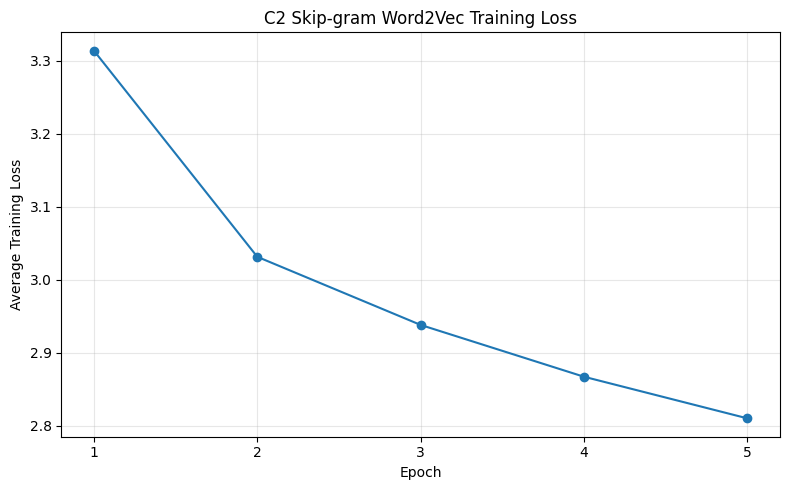


========== C2 FINAL RESULTS ==========
Embedding shape: (16735, 100)
Vocabulary size: 16735
All embeddings finite: True

Training loss history:
 epoch  average_loss
     1      3.313685
     2      3.031392
     3      2.938093
     4      2.867136
     5      2.810154

Saved artifacts:
centre_embeddings_V.npy: 6.38 MB
context_embeddings_U.npy: 6.38 MB
embeddings_w2v.npy: 6.38 MB
raw_articles_reconstructed.txt: 2.90 MB
raw_articles_tokenized.json: 3.91 MB
skipgram_checkpoint.pth: 38.31 MB
training_loss.csv: 0.00 MB
vocabulary.json: 0.33 MB
word2vec_training_loss.png: 0.11 MB
word_frequencies.csv: 0.22 MB

C2 WORD2VEC TRAINING COMPLETED.


In [31]:

import os
import json
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from collections import Counter
from torch.utils.data import DataLoader, TensorDataset

# ==================================================
# 1. CONFIGURATION — MATCH C3
# ==================================================

PROJECT_DIR = "/content/BBC_Urdu_NLP_Assignment2"

MODEL_DIR = os.path.join(
    PROJECT_DIR, "part1_word2vec", "C2_raw_d100"
)
os.makedirs(MODEL_DIR, exist_ok=True)

TOKENIZED_FILE = os.path.join(
    MODEL_DIR, "raw_articles_tokenized.json"
)

EMBEDDING_DIM = 100
WINDOW_SIZE = 5
NEGATIVE_SAMPLES = 10
BATCH_SIZE = 512
EPOCHS = 5
LEARNING_RATE = 0.001
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

# ==================================================
# 2. LOAD RECONSTRUCTED ARTICLES
# ==================================================

with open(TOKENIZED_FILE, "r", encoding="utf-8") as f:
    tokenized_articles = json.load(f)

assert len(tokenized_articles) == 246

# ==================================================
# 3. BUILD VOCABULARY
# ==================================================

counter = Counter(
    word
    for article in tokenized_articles
    for word in article
)

# Deterministic frequency-based vocabulary
sorted_words = sorted(
    counter.items(),
    key=lambda x: (-x[1], x[0])
)

vocabulary = {
    word: idx
    for idx, (word, _) in enumerate(sorted_words)
}

frequencies = np.array(
    [counter[word] for word in vocabulary],
    dtype=np.float64
)

vocab_size = len(vocabulary)

print("\n========== VOCABULARY ==========")
print("Vocabulary size:", vocab_size)
print("Total tokens:", int(frequencies.sum()))

# Save vocabulary and frequencies
with open(
    os.path.join(MODEL_DIR, "vocabulary.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(vocabulary, f, ensure_ascii=False)

pd.DataFrame({
    "word": list(vocabulary.keys()),
    "frequency": [counter[w] for w in vocabulary]
}).to_csv(
    os.path.join(MODEL_DIR, "word_frequencies.csv"),
    index=False,
    encoding="utf-8-sig"
)

# ==================================================
# 4. GENERATE SKIP-GRAM POSITIVE PAIRS
#    Keep article boundaries separate.
# ==================================================

print("\nGenerating positive pairs...")

indexed_articles = [
    [vocabulary[word] for word in article]
    for article in tokenized_articles
]

pair_count = sum(
    min(WINDOW_SIZE, i)
    + min(WINDOW_SIZE, len(article) - i - 1)
    for article in indexed_articles
    for i in range(len(article))
)

pairs = np.empty((pair_count, 2), dtype=np.int32)

position = 0

for article in indexed_articles:
    n = len(article)

    for center_pos in range(n):
        center_id = article[center_pos]

        left = max(0, center_pos - WINDOW_SIZE)
        right = min(n, center_pos + WINDOW_SIZE + 1)

        for context_pos in range(left, right):
            if context_pos == center_pos:
                continue

            pairs[position, 0] = center_id
            pairs[position, 1] = article[context_pos]
            position += 1

assert position == pair_count

print("Positive pairs:", pair_count)
print("Pair array shape:", pairs.shape)

# ==================================================
# 5. NEGATIVE SAMPLING DISTRIBUTION
#    Pn(w) proportional to frequency(w)^0.75
# ==================================================

noise_distribution = frequencies ** 0.75
noise_distribution /= noise_distribution.sum()

noise_distribution = torch.tensor(
    noise_distribution,
    dtype=torch.float32,
    device=DEVICE
)

# ==================================================
# 6. DATA LOADER
# ==================================================

pair_tensor = torch.from_numpy(
    pairs.astype(np.int64)
)

dataset = TensorDataset(pair_tensor)

loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

# ==================================================
# 7. SKIP-GRAM MODEL
#    Separate centre V and context U matrices
# ==================================================

class SkipGramNS(nn.Module):

    def __init__(self, vocab_size, embedding_dim):
        super().__init__()

        self.V = nn.Embedding(
            vocab_size, embedding_dim
        )

        self.U = nn.Embedding(
            vocab_size, embedding_dim
        )

        nn.init.uniform_(
            self.V.weight,
            -0.5 / embedding_dim,
            0.5 / embedding_dim
        )

        nn.init.zeros_(self.U.weight)

    def forward(self, centers, contexts, negatives):

        center_vectors = self.V(centers)
        positive_vectors = self.U(contexts)
        negative_vectors = self.U(negatives)

        positive_scores = torch.sum(
            center_vectors * positive_vectors,
            dim=1
        )

        negative_scores = torch.bmm(
            negative_vectors,
            center_vectors.unsqueeze(2)
        ).squeeze(2)

        positive_loss = F.softplus(
            -positive_scores
        )

        negative_loss = F.softplus(
            negative_scores
        ).sum(dim=1)

        return (positive_loss + negative_loss).mean()


model = SkipGramNS(
    vocab_size, EMBEDDING_DIM
).to(DEVICE)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

print("\n========== MODEL ==========")
print("Centre matrix V:", tuple(model.V.weight.shape))
print("Context matrix U:", tuple(model.U.weight.shape))
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters()))

# ==================================================
# 8. TRAINING
# ==================================================

history = []

print("\n========== C2 TRAINING STARTED ==========")

for epoch in range(1, EPOCHS + 1):

    model.train()

    total_loss = 0.0
    total_examples = 0

    for (batch_pairs,) in loader:

        batch_pairs = batch_pairs.to(
            DEVICE, non_blocking=True
        )

        centers = batch_pairs[:, 0]
        contexts = batch_pairs[:, 1]

        current_batch_size = centers.size(0)

        # Draw K negative samples per positive pair
        negatives = torch.multinomial(
            noise_distribution,
            current_batch_size * NEGATIVE_SAMPLES,
            replacement=True
        ).view(
            current_batch_size, NEGATIVE_SAMPLES
        )

        optimizer.zero_grad(set_to_none=True)

        loss = model(
            centers,
            contexts,
            negatives
        )

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * current_batch_size
        total_examples += current_batch_size

    epoch_loss = total_loss / total_examples

    history.append({
        "epoch": epoch,
        "average_loss": epoch_loss
    })

    print(
        f"Epoch {epoch}/{EPOCHS} | "
        f"Average Loss: {epoch_loss:.6f}"
    )

    # Save checkpoint after every epoch
    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "embedding_dim": EMBEDDING_DIM,
        "window_size": WINDOW_SIZE,
        "negative_samples": NEGATIVE_SAMPLES,
        "batch_size": BATCH_SIZE,
        "learning_rate": LEARNING_RATE,
        "seed": SEED,
        "vocab_size": vocab_size
    }

    torch.save(
        checkpoint,
        os.path.join(MODEL_DIR, "skipgram_checkpoint.pth")
    )

    pd.DataFrame(history).to_csv(
        os.path.join(MODEL_DIR, "training_loss.csv"),
        index=False
    )

# ==================================================
# 9. SAVE AVERAGED EMBEDDINGS
#    E = 0.5 * (V + U)
# ==================================================

model.eval()

with torch.no_grad():

    V = model.V.weight.detach().cpu().numpy()
    U = model.U.weight.detach().cpu().numpy()

    averaged_embeddings = 0.5 * (V + U)

np.save(
    os.path.join(MODEL_DIR, "centre_embeddings_V.npy"),
    V
)

np.save(
    os.path.join(MODEL_DIR, "context_embeddings_U.npy"),
    U
)

np.save(
    os.path.join(MODEL_DIR, "embeddings_w2v.npy"),
    averaged_embeddings
)

# ==================================================
# 10. PLOT TRAINING LOSS
# ==================================================

import matplotlib.pyplot as plt

history_df = pd.DataFrame(history)

plt.figure(figsize=(8, 5))
plt.plot(
    history_df["epoch"],
    history_df["average_loss"],
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Average Training Loss")
plt.title("C2 Skip-gram Word2Vec Training Loss")
plt.xticks(range(1, EPOCHS + 1))
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(MODEL_DIR, "word2vec_training_loss.png"),
    dpi=300
)

plt.show()

# ==================================================
# 11. FINAL VALIDATION
# ==================================================

print("\n========== C2 FINAL RESULTS ==========")

print("Embedding shape:", averaged_embeddings.shape)
print("Vocabulary size:", vocab_size)
print("All embeddings finite:",
      np.isfinite(averaged_embeddings).all())

print("\nTraining loss history:")
print(history_df.to_string(index=False))

print("\nSaved artifacts:")

for filename in sorted(os.listdir(MODEL_DIR)):
    path = os.path.join(MODEL_DIR, filename)

    if os.path.isfile(path):
        print(
            f"{filename}: "
            f"{os.path.getsize(path) / (1024**2):.2f} MB"
        )

assert averaged_embeddings.shape == (
    vocab_size, EMBEDDING_DIM
)

assert np.isfinite(averaged_embeddings).all()

print("\nC2 WORD2VEC TRAINING COMPLETED.")


In [33]:

import os

PROJECT_DIR = "/content/BBC_Urdu_NLP_Assignment2"
CLEANED_FILE = os.path.join(
    PROJECT_DIR, "data", "cleaned.txt"
)

with open(CLEANED_FILE, "r", encoding="utf-8") as f:
    lines = f.readlines()

print("========== CLEANED FILE STRUCTURE ==========")
print("Total lines:", len(lines))
print("Non-empty lines:", sum(bool(x.strip()) for x in lines))
print("Empty lines:", sum(not x.strip() for x in lines))

print("\n========== FIRST 30 LINES ==========")

for i, line in enumerate(lines[:30], start=1):
    print(f"{i:03d}: {line.strip()[:250]!r}")

print("\n========== NON-EMPTY LINE LENGTHS ==========")

lengths = [len(x.strip()) for x in lines if x.strip()]

if lengths:
    print("Minimum:", min(lengths))
    print("Maximum:", max(lengths))
    print("Average:", round(sum(lengths) / len(lengths), 2))

print("\n========== FIRST 30 NON-EMPTY LINE TOKEN COUNTS ==========")

import re

pattern = re.compile(r"[\u0600-\u06FF]+")

count = 0

for i, line in enumerate(lines):
    if line.strip():
        count += 1
        print(
            f"Line {i+1}: "
            f"{len(pattern.findall(line))} tokens"
        )

        if count == 30:
            break

print("\nINSPECTION COMPLETED.")


========== CLEANED FILE STRUCTURE ==========
Total lines: 737
Non-empty lines: 492
Empty lines: 245

========== FIRST 30 LINES ==========
001: 'ARTICLE 1'
002: 'میکسیکو اور جنوب ٹیکساس کے دریاؤں میں مچھل کی ایک ایس قسم پائ جات ہے جس کا بظاہر وجود ناممکن ہون چاہی ۔ گرم اور ہلک بہاؤ وال پان میں مکمل طور پر ماد مچھل پر مشتمل جھنڈ اکثر تیر نظر آتا ہے ۔ دریاؤں کے تیر کے دور ان ماد مچھل کے چاند جیس چمک ہوئ پر ایک '
003: ''
004: 'ARTICLE 2'
005: '’پارٹیشن نے ہر اس فیمل کو تبا کر دیا جس نے اپن گھر چھوڑ ۔ میر داد کہت تھیں کہ دون طرف کے سیاست دان نے پارٹیشن دیکھ نہیں ، ورن شاید یہ نوبت نہ آتی ۔ یہ ان سے پوچھ جن کے گھرا ، جن کے خاند رل گئے ، جو جیت جی مر گئے ۔ ‘ یہ الفاظ سپن کوی اوبرائ کے ہیں ، ج'
006: ''
007: 'ARTICLE 3'
008: 'سپریم کورٹ سے <NUM> برس قید کی سزا کی معطل اور ضمانت پر اڈیال جیل رہا ہون وال وکیل ایم مزار اور ان کے شوہر ہاد علی چٹھ کو پولیس نے ایک اور مقدم میں گرفتار کر لیا ہے ۔ اسلام آباد پولیس کے ایک اہلکار نے نام نہ ظاہر کرن کی شرط پر بتای کہ ایم مزار اور ہا'
009: ''
010: 'ARTICLE

In [34]:

import os
import re
import json
import numpy as np

PROJECT_DIR = "/content/BBC_Urdu_NLP_Assignment2"

CLEANED_FILE = os.path.join(
    PROJECT_DIR, "data", "cleaned.txt"
)

C3_DIR = os.path.join(
    PROJECT_DIR, "part1_word2vec", "C3_cleaned_d100"
)

C4_DIR = os.path.join(
    PROJECT_DIR, "part1_word2vec", "C4_cleaned_d200"
)

os.makedirs(C4_DIR, exist_ok=True)

TOKEN_PATTERN = re.compile(r"[\u0600-\u06FF]+")

# ------------------------------------------------
# 1. LOAD CLEANED FILE
# ------------------------------------------------

with open(CLEANED_FILE, "r", encoding="utf-8") as f:
    lines = f.readlines()

# ------------------------------------------------
# 2. EXTRACT TEXT USING ARTICLE MARKERS
# ------------------------------------------------

articles = []
current_article_id = None

for line in lines:

    stripped = line.strip()

    marker = re.fullmatch(
        r"ARTICLE\s+(\d+)",
        stripped,
        flags=re.IGNORECASE
    )

    if marker:

        if current_article_id is not None:
            raise ValueError(
                f"Article {current_article_id} has no text line."
            )

        current_article_id = int(marker.group(1))
        continue

    if not stripped:
        continue

    if current_article_id is not None:

        articles.append(stripped)
        current_article_id = None

if current_article_id is not None:
    raise ValueError(
        f"Article {current_article_id} has no text."
    )

# ------------------------------------------------
# 3. VALIDATE ARTICLE COUNT
# ------------------------------------------------

assert len(articles) == 246, (
    f"Expected 246 articles, found {len(articles)}"
)

tokenized_articles = [
    TOKEN_PATTERN.findall(article)
    for article in articles
]

total_tokens = sum(
    len(article) for article in tokenized_articles
)

print("========== CORRECTED C4 CORPUS ==========")
print("Articles:", len(articles))
print("Total tokens:", total_tokens)

# ------------------------------------------------
# 4. LOAD EXISTING C3 VOCABULARY
# ------------------------------------------------

with open(
    os.path.join(C3_DIR, "vocabulary.json"),
    "r",
    encoding="utf-8"
) as f:
    c3_vocabulary = json.load(f)

print("\n========== C3 VOCABULARY CHECK ==========")
print("C3 vocabulary size:", len(c3_vocabulary))

# Reuse exact C3 vocabulary and word indices
vocabulary = c3_vocabulary

# ------------------------------------------------
# 5. CHECK TOKEN COVERAGE
# ------------------------------------------------

corpus_counter = {}

for article in tokenized_articles:
    for word in article:
        corpus_counter[word] = (
            corpus_counter.get(word, 0) + 1
        )

missing_words = [
    word for word in corpus_counter
    if word not in vocabulary
]

vocabulary_words = set(vocabulary)

extra_words = [
    word for word in vocabulary_words
    if word not in corpus_counter
]

print("\n========== VOCABULARY CONSISTENCY ==========")
print("Unique corpus words:", len(corpus_counter))
print("Missing from C3 vocabulary:", len(missing_words))
print("Extra C3 vocabulary words:", len(extra_words))

if missing_words:
    print("Missing examples:", missing_words[:20])

if extra_words:
    print("Extra examples:", extra_words[:20])

# ------------------------------------------------
# 6. VERIFY C3 SAVED EMBEDDING
# ------------------------------------------------

c3_embeddings = np.load(
    os.path.join(C3_DIR, "embeddings_w2v.npy")
)

print("\n========== C3 EMBEDDING CHECK ==========")
print("C3 embedding shape:", c3_embeddings.shape)

# ------------------------------------------------
# 7. FINAL STRICT VALIDATION
# ------------------------------------------------

assert total_tokens == 382689, (
    f"Token mismatch: expected 382689, got {total_tokens}"
)

assert len(vocabulary) == 11124

assert len(missing_words) == 0
assert len(extra_words) == 0

assert c3_embeddings.shape == (11124, 100)

# Save correctly reconstructed corpus
with open(
    os.path.join(C4_DIR, "cleaned_articles_tokenized.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        tokenized_articles,
        f,
        ensure_ascii=False
    )

print("\n<escape>======================================</escape>")
print("ALL C4 VALIDATION CHECKS PASSED")
print("C3 and C4 will use identical corpus vocabulary.")
print("C4 can now train with embedding dimension 200.")
print("<escape>======================================</escape>")


========== CORRECTED C4 CORPUS ==========
Articles: 246
Total tokens: 382689

========== C3 VOCABULARY CHECK ==========
C3 vocabulary size: 11124

========== VOCABULARY CONSISTENCY ==========
Unique corpus words: 11124
Missing from C3 vocabulary: 0
Extra C3 vocabulary words: 0

========== C3 EMBEDDING CHECK ==========
C3 embedding shape: (11124, 100)

<escape>======================================</escape>
ALL C4 VALIDATION CHECKS PASSED
C3 and C4 will use identical corpus vocabulary.
C4 can now train with embedding dimension 200.
<escape>======================================</escape>


Device: cuda
Embedding dimension: 200

========== TRAINING DATA ==========
Articles: 246
Total tokens: 382689
Vocabulary: 11124
Positive pairs: 3819510

Model initialized.
Centre matrix V: (11124, 200)
Context matrix U: (11124, 200)

========== C4 TRAINING STARTED ==========
Epoch 1/5 | Batch 1000/7460 | Loss: 3.2414
Epoch 1/5 | Batch 2000/7460 | Loss: 3.1920
Epoch 1/5 | Batch 3000/7460 | Loss: 3.1429
Epoch 1/5 | Batch 4000/7460 | Loss: 3.1248
Epoch 1/5 | Batch 5000/7460 | Loss: 3.0942
Epoch 1/5 | Batch 6000/7460 | Loss: 3.1037
Epoch 1/5 | Batch 7000/7460 | Loss: 3.0618

Epoch 1/5 completed | Average Loss: 3.229393
Epoch 2/5 | Batch 1000/7460 | Loss: 3.0740
Epoch 2/5 | Batch 2000/7460 | Loss: 3.0105
Epoch 2/5 | Batch 3000/7460 | Loss: 3.0004
Epoch 2/5 | Batch 4000/7460 | Loss: 3.0341
Epoch 2/5 | Batch 5000/7460 | Loss: 3.0514
Epoch 2/5 | Batch 6000/7460 | Loss: 3.0203
Epoch 2/5 | Batch 7000/7460 | Loss: 2.9570

Epoch 2/5 completed | Average Loss: 3.020896
Epoch 3/5 | Batch 1000/7460 | 

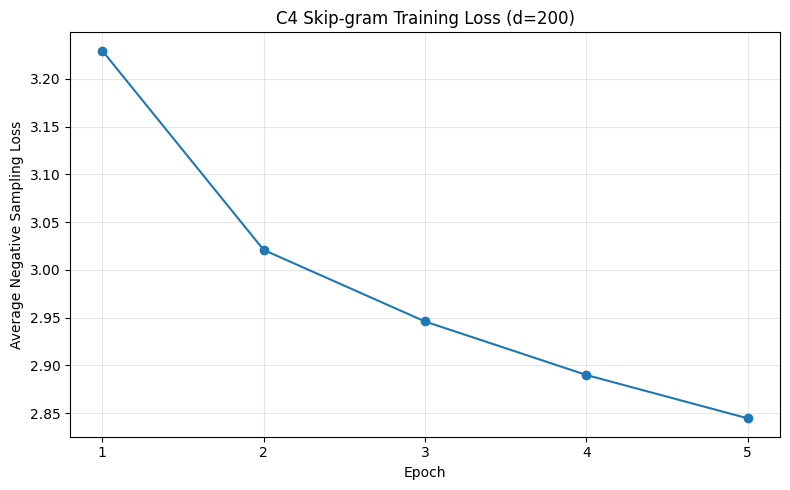


========== C4 TRAINING COMPLETED ==========
Embedding shape: (11124, 200)
Epoch losses: [3.229393, 3.020896, 2.945995, 2.889982, 2.844611]
Loss reduction: 11.91%

Saved files:
centre_embeddings_V.npy: 8.49 MB
cleaned_articles_tokenized.json: 3.74 MB
context_embeddings_U.npy: 8.49 MB
embeddings_w2v.npy: 8.49 MB
skipgram_checkpoint.pth: 50.93 MB
training_loss.csv: 0.00 MB
vocabulary.json: 0.21 MB
word2vec_training_loss.png: 0.13 MB
word_frequencies.csv: 0.14 MB

C4 training and saving completed successfully.


In [35]:

import os
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from collections import Counter

# =====================================================
# 1. CONFIGURATION
# =====================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

PROJECT_DIR = "/content/BBC_Urdu_NLP_Assignment2"

C3_DIR = os.path.join(
    PROJECT_DIR, "part1_word2vec", "C3_cleaned_d100"
)

C4_DIR = os.path.join(
    PROJECT_DIR, "part1_word2vec", "C4_cleaned_d200"
)

os.makedirs(C4_DIR, exist_ok=True)

# Assignment parameters
EMBED_DIM = 200
WINDOW_SIZE = 5
NEGATIVE_SAMPLES = 10
BATCH_SIZE = 512
EPOCHS = 5
LEARNING_RATE = 0.001

print("Device:", DEVICE)
print("Embedding dimension:", EMBED_DIM)

# =====================================================
# 2. LOAD VALIDATED CORPUS
# =====================================================

with open(
    os.path.join(C4_DIR, "cleaned_articles_tokenized.json"),
    "r",
    encoding="utf-8"
) as f:
    tokenized_articles = json.load(f)

assert len(tokenized_articles) == 246

total_tokens = sum(
    len(article) for article in tokenized_articles
)

assert total_tokens == 382689

# =====================================================
# 3. LOAD EXACT C3 VOCABULARY
# =====================================================

with open(
    os.path.join(C3_DIR, "vocabulary.json"),
    "r",
    encoding="utf-8"
) as f:
    saved_vocab = json.load(f)

# Support either dictionary or list vocabulary format
if isinstance(saved_vocab, dict):

    if all(isinstance(v, int) for v in saved_vocab.values()):
        word_to_idx = saved_vocab
    else:
        raise ValueError("Unexpected C3 vocabulary format.")

elif isinstance(saved_vocab, list):

    word_to_idx = {
        word: idx
        for idx, word in enumerate(saved_vocab)
    }

else:
    raise ValueError("Unsupported C3 vocabulary format.")

vocab_size = len(word_to_idx)

assert vocab_size == 11124

# Verify the vocabulary indexes are continuous
assert sorted(word_to_idx.values()) == list(range(vocab_size))

idx_to_word = {
    idx: word
    for word, idx in word_to_idx.items()
}

# =====================================================
# 4. BUILD WORD FREQUENCIES
# =====================================================

counter = Counter()

for article in tokenized_articles:
    counter.update(article)

assert len(counter) == vocab_size
assert set(counter.keys()) == set(word_to_idx.keys())

frequencies = np.zeros(vocab_size, dtype=np.float64)

for word, count in counter.items():
    frequencies[word_to_idx[word]] = count

# Negative sampling distribution: frequency^0.75
noise_distribution = frequencies ** 0.75
noise_distribution /= noise_distribution.sum()

noise_distribution = torch.tensor(
    noise_distribution,
    dtype=torch.float32,
    device=DEVICE
)

# =====================================================
# 5. GENERATE SKIP-GRAM POSITIVE PAIRS
# =====================================================

centres = []
contexts = []

for article in tokenized_articles:

    ids = [
        word_to_idx[word]
        for word in article
    ]

    for i, centre_id in enumerate(ids):

        start = max(0, i - WINDOW_SIZE)
        end = min(len(ids), i + WINDOW_SIZE + 1)

        for j in range(start, end):

            if i == j:
                continue

            centres.append(centre_id)
            contexts.append(ids[j])

centres = np.asarray(centres, dtype=np.int64)
contexts = np.asarray(contexts, dtype=np.int64)

print("\n========== TRAINING DATA ==========")
print("Articles:", len(tokenized_articles))
print("Total tokens:", total_tokens)
print("Vocabulary:", vocab_size)
print("Positive pairs:", len(centres))

assert len(centres) == 3819510, (
    f"Expected 3819510 pairs, found {len(centres)}"
)

# =====================================================
# 6. DATASET AND DATALOADER
# =====================================================

class SkipGramDataset(Dataset):

    def __init__(self, centre_ids, context_ids):
        self.centres = torch.from_numpy(centre_ids)
        self.contexts = torch.from_numpy(context_ids)

    def __len__(self):
        return len(self.centres)

    def __getitem__(self, index):
        return (
            self.centres[index],
            self.contexts[index]
        )

dataset = SkipGramDataset(centres, contexts)

loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

# =====================================================
# 7. SKIP-GRAM MODEL
# =====================================================

class SkipGramNS(nn.Module):

    def __init__(self, vocab_size, embedding_dim):
        super().__init__()

        self.V = nn.Embedding(
            vocab_size,
            embedding_dim
        )

        self.U = nn.Embedding(
            vocab_size,
            embedding_dim
        )

        nn.init.uniform_(
            self.V.weight,
            -0.5 / embedding_dim,
            0.5 / embedding_dim
        )

        nn.init.zeros_(self.U.weight)

    def forward(self, centre_ids, positive_ids, negative_ids):

        centre_vectors = self.V(centre_ids)

        positive_vectors = self.U(positive_ids)

        negative_vectors = self.U(negative_ids)

        positive_scores = torch.sum(
            centre_vectors * positive_vectors,
            dim=1
        )

        negative_scores = torch.bmm(
            negative_vectors,
            centre_vectors.unsqueeze(2)
        ).squeeze(2)

        positive_loss = F.softplus(-positive_scores)

        negative_loss = F.softplus(negative_scores).sum(dim=1)

        loss = (positive_loss + negative_loss).mean()

        return loss


model = SkipGramNS(
    vocab_size,
    EMBED_DIM
).to(DEVICE)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

print("\nModel initialized.")
print("Centre matrix V:", tuple(model.V.weight.shape))
print("Context matrix U:", tuple(model.U.weight.shape))

# =====================================================
# 8. TRAINING
# =====================================================

epoch_losses = []

print("\n========== C4 TRAINING STARTED ==========")

for epoch in range(EPOCHS):

    model.train()

    running_loss = 0.0
    total_examples = 0

    for batch_idx, (centre_ids, positive_ids) in enumerate(loader):

        centre_ids = centre_ids.to(DEVICE, non_blocking=True)
        positive_ids = positive_ids.to(DEVICE, non_blocking=True)

        batch_size = centre_ids.size(0)

        # Draw K negative samples for each positive pair
        negative_ids = torch.multinomial(
            noise_distribution,
            batch_size * NEGATIVE_SAMPLES,
            replacement=True
        ).view(batch_size, NEGATIVE_SAMPLES)

        optimizer.zero_grad(set_to_none=True)

        loss = model(
            centre_ids,
            positive_ids,
            negative_ids
        )

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * batch_size
        total_examples += batch_size

        if (batch_idx + 1) % 1000 == 0:
            print(
                f"Epoch {epoch+1}/{EPOCHS} | "
                f"Batch {batch_idx+1}/{len(loader)} | "
                f"Loss: {loss.item():.4f}"
            )

    epoch_loss = running_loss / total_examples
    epoch_losses.append(epoch_loss)

    print(
        f"\nEpoch {epoch+1}/{EPOCHS} "
        f"completed | Average Loss: {epoch_loss:.6f}"
    )

    # Save checkpoint after every epoch
    checkpoint_path = os.path.join(
        C4_DIR,
        "skipgram_checkpoint.pth"
    )

    torch.save(
        {
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "loss": epoch_loss,
            "embedding_dim": EMBED_DIM,
            "vocab_size": vocab_size
        },
        checkpoint_path
    )

    # Save losses immediately
    pd.DataFrame({
        "epoch": range(1, len(epoch_losses) + 1),
        "loss": epoch_losses
    }).to_csv(
        os.path.join(C4_DIR, "training_loss.csv"),
        index=False
    )

# =====================================================
# 9. SAVE AVERAGED EMBEDDINGS
# =====================================================

model.eval()

with torch.no_grad():

    V = model.V.weight.detach().cpu().numpy()
    U = model.U.weight.detach().cpu().numpy()

    averaged_embeddings = 0.5 * (V + U)

assert averaged_embeddings.shape == (11124, 200)
assert np.isfinite(averaged_embeddings).all()

np.save(
    os.path.join(C4_DIR, "centre_embeddings_V.npy"),
    V
)

np.save(
    os.path.join(C4_DIR, "context_embeddings_U.npy"),
    U
)

np.save(
    os.path.join(C4_DIR, "embeddings_w2v.npy"),
    averaged_embeddings
)

# Save vocabulary in original C3 format
with open(
    os.path.join(C4_DIR, "vocabulary.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        saved_vocab,
        f,
        ensure_ascii=False
    )

pd.DataFrame({
    "word": list(word_to_idx.keys()),
    "frequency": [
        int(frequencies[word_to_idx[word]])
        for word in word_to_idx
    ]
}).to_csv(
    os.path.join(C4_DIR, "word_frequencies.csv"),
    index=False
)

# =====================================================
# 10. LOSS CURVE
# =====================================================

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, EPOCHS + 1),
    epoch_losses,
    marker="o"
)

plt.title("C4 Skip-gram Training Loss (d=200)")
plt.xlabel("Epoch")
plt.ylabel("Average Negative Sampling Loss")
plt.xticks(range(1, EPOCHS + 1))
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(C4_DIR, "word2vec_training_loss.png"),
    dpi=300
)

plt.show()

# =====================================================
# 11. FINAL SUMMARY
# =====================================================

print("\n========== C4 TRAINING COMPLETED ==========")

print("Embedding shape:", averaged_embeddings.shape)
print("Epoch losses:", [round(x, 6) for x in epoch_losses])

if len(epoch_losses) >= 2:
    improvement = (
        (epoch_losses[0] - epoch_losses[-1])
        / epoch_losses[0]
    ) * 100

    print(f"Loss reduction: {improvement:.2f}%")

print("\nSaved files:")
for filename in sorted(os.listdir(C4_DIR)):
    path = os.path.join(C4_DIR, filename)

    if os.path.isfile(path):
        print(
            f"{filename}: "
            f"{os.path.getsize(path) / (1024**2):.2f} MB"
        )

print("\nC4 training and saving completed successfully.")


In [36]:

import os
import json
import numpy as np

BASE = "/content/BBC_Urdu_NLP_Assignment2/part1_word2vec"

PATHS = {
    "C1_PPMI": "/content/BBC_Urdu_NLP_Assignment2/part1_ppmi/ppmi_vocabulary.json",
    "C2_raw_d100": os.path.join(BASE, "C2_raw_d100", "vocabulary.json"),
    "C3_cleaned_d100": os.path.join(BASE, "C3_cleaned_d100", "vocabulary.json"),
    "C4_cleaned_d200": os.path.join(BASE, "C4_cleaned_d200", "vocabulary.json")
}

def load_words(path):
    with open(path, "r", encoding="utf-8") as f:
        obj = json.load(f)

    if isinstance(obj, list):
        return set(obj)

    if isinstance(obj, dict):
        # Standard word -> index dictionary
        if all(isinstance(v, int) for v in obj.values()):
            return set(obj.keys())

        # Alternative index -> word dictionary
        if all(isinstance(k, str) and k.isdigit()
               for k in obj.keys()):
            return set(obj.values())

    raise ValueError(
        f"Unrecognized vocabulary structure: {path}"
    )

vocabularies = {
    name: load_words(path)
    for name, path in PATHS.items()
}

print("========== VOCABULARY SIZES ==========")

for name, words in vocabularies.items():
    print(f"{name}: {len(words):,}")

common_words = set.intersection(
    *vocabularies.values()
)

print("\nWords common to all four conditions:", len(common_words))

# -------------------------------------------------
# Candidate query words for nearest-neighbour tests
# -------------------------------------------------

query_candidates = [
    "پاکستان", "پاکست", "حکومت", "عدالت", "معیشت",
    "کرکٹ", "فوج", "صحت", "تعلیم", "بھارت",
    "لاہور", "پولیس", "ٹیم", "شہر"
]

print("\n========== COMMON QUERY WORDS ==========")

valid_queries = []

for word in query_candidates:
    if word in common_words:
        valid_queries.append(word)
        print("[FOUND]", word)
    else:
        print("[MISSING]", word)

# -------------------------------------------------
# Candidate manually labelled semantic pairs
# -------------------------------------------------

candidate_pairs = [
    ("پاکستان", "لاہور"),
    ("پاکستان", "بھارت"),
    ("حکومت", "وزیر"),
    ("عدالت", "جج"),
    ("فوج", "افواج"),
    ("صحت", "طبی"),
    ("تعلیم", "استاد"),
    ("کرکٹ", "ٹیم"),
    ("کرکٹ", "کھلاڑی"),
    ("معیشت", "تجارت"),
    ("پولیس", "جرم"),
    ("شہر", "آبادی"),
    ("اسکول", "تعلیم"),
    ("ہسپتال", "ڈاکٹر"),
    ("کھیل", "میچ"),
    ("صدر", "حکومت"),
    ("بھارت", "دہلی"),
    ("فرانس", "پیرس"),
    ("فٹبال", "برازیل"),
    ("والد", "والدہ"),
    ("پاکستان", "کراچی"),
    ("عدالت", "قانون"),
    ("صحت", "بیماری"),
    ("تعلیم", "طالب"),
    ("فوج", "سپاہی")
]

print("\n========== COMMON SEMANTIC PAIRS ==========")

valid_pairs = []
invalid_pairs = []

for word1, word2 in candidate_pairs:

    if word1 in common_words and word2 in common_words:
        valid_pairs.append((word1, word2))
        print("[FOUND]", word1, "->", word2)
    else:
        invalid_pairs.append((word1, word2))
        print("[MISSING]", word1, "->", word2)

print("\n========== SUMMARY ==========")
print("Valid query words:", len(valid_queries))
print("Valid candidate pairs:", len(valid_pairs))
print("Pairs needing replacement:", len(invalid_pairs))

print("\nValid pairs for evaluation:")
print(valid_pairs)


========== VOCABULARY SIZES ==========
C1_PPMI: 3,000
C2_raw_d100: 16,735
C3_cleaned_d100: 11,124
C4_cleaned_d200: 11,124

Words common to all four conditions: 2313

========== COMMON QUERY WORDS ==========
[FOUND] پاکستان
[MISSING] پاکست
[FOUND] حکومت
[FOUND] عدالت
[FOUND] معیشت
[FOUND] کرکٹ
[FOUND] فوج
[FOUND] صحت
[FOUND] تعلیم
[MISSING] بھارت
[FOUND] لاہور
[FOUND] پولیس
[FOUND] ٹیم
[FOUND] شہر

========== COMMON SEMANTIC PAIRS ==========
[FOUND] پاکستان -> لاہور
[MISSING] پاکستان -> بھارت
[FOUND] حکومت -> وزیر
[FOUND] عدالت -> جج
[FOUND] فوج -> افواج
[FOUND] صحت -> طبی
[FOUND] تعلیم -> استاد
[FOUND] کرکٹ -> ٹیم
[MISSING] کرکٹ -> کھلاڑی
[FOUND] معیشت -> تجارت
[FOUND] پولیس -> جرم
[MISSING] شہر -> آبادی
[MISSING] اسکول -> تعلیم
[FOUND] ہسپتال -> ڈاکٹر
[FOUND] کھیل -> میچ
[FOUND] صدر -> حکومت
[MISSING] بھارت -> دہلی
[FOUND] فرانس -> پیرس
[FOUND] فٹبال -> برازیل
[MISSING] والد -> والدہ
[MISSING] پاکستان -> کراچی
[MISSING] عدالت -> قانون
[MISSING] صحت -> بیماری
[FOUND] تعلیم -> طالب
[MIS

In [37]:

import os
import json
import pandas as pd

PROJECT = "/content/BBC_Urdu_NLP_Assignment2"
BASE = os.path.join(PROJECT, "part1_word2vec")

# Load PPMI vocabulary
with open(
    os.path.join(PROJECT, "part1_ppmi", "ppmi_vocabulary.json"),
    "r",
    encoding="utf-8"
) as f:
    ppmi_vocab_data = json.load(f)

if isinstance(ppmi_vocab_data, list):
    ppmi_words = set(ppmi_vocab_data)
else:
    ppmi_words = set(ppmi_vocab_data.keys())

# Load C2, C3 and C4 vocabularies
def get_vocab(folder):
    path = os.path.join(BASE, folder, "vocabulary.json")
    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)

    if isinstance(data, list):
        return set(data)

    return set(data.keys())

common_words = (
    ppmi_words
    & get_vocab("C2_raw_d100")
    & get_vocab("C3_cleaned_d100")
    & get_vocab("C4_cleaned_d200")
)

# Load PPMI word frequencies
freq_path = os.path.join(
    PROJECT, "part1_ppmi", "word_frequencies.csv"
)

freq_df = pd.read_csv(freq_path)

# Adapt to the available column names
print("Frequency CSV columns:", list(freq_df.columns))

word_col = "word"
freq_col = "frequency"

if word_col not in freq_df.columns:
    word_col = freq_df.columns[0]

if freq_col not in freq_df.columns:
    freq_col = freq_df.columns[1]

freq_df = freq_df[
    freq_df[word_col].isin(common_words)
].sort_values(freq_col, ascending=False)

print("\n========== TOP 100 COMMON WORDS ==========")

for i, word in enumerate(freq_df[word_col].head(100), 1):
    print(f"{i:03d}. {word}")

print("\nTotal common vocabulary:", len(common_words))


Frequency CSV columns: ['Word', 'Frequency']

========== TOP 100 COMMON WORDS ==========
001. کرن
002. وال
003. گیا
004. کہا
005. مطابق
006. سکت
007. ایس
008. ساتھ
009. دیا
010. جات
011. رہے
012. طور
013. لیکن
014. دور
015. گئی
016. پہل
017. رکھ
018. بات
019. آئی
020. جان
021. کسی
022. سال
023. جا
024. موجود
025. تاہم
026. وقت
027. رہا
028. بار
029. گئے
030. بہت
031. رہی
032. جانب
033. نہ
034. ہم
035. لوگ
036. دی
037. حکومت
038. ہوا
039. گا
040. صرف
041. عمر
042. سام
043. کم
044. شامل
045. خان
046. امریک
047. اے
048. دیکھ
049. استعمال
050. حمل
051. بنا
052. لکھ
053. پولیس
054. مزید
055. میر
056. سی
057. کیے
058. نام
059. آپ
060. تھیں
061. خلاف
062. دو
063. ملک
064. پیش
065. اسی
066. دیت
067. پی
068. واقع
069. فیصل
070. تقریب
071. وجہ
072. کام
073. حاصل
074. غیر
075. گی
076. گے
077. فوج
078. طرح
079. کار
080. تین
081. پہنچ
082. مجھ
083. شروع
084. متعلق
085. ٹیم
086. مختلف
087. نظر
088. دین
089. بیان
090. بڑھ
091. افراد
092. بچہ
093. وزیر
094. پاس
095. ٹی
096. نظام
097. کوشش
098. سمجھ
09

========== VOCABULARY SIZES ==========
C1_PPMI: 3,000
C2_raw_d100: 16,735
C3_cleaned_d100: 11,124
C4_cleaned_d200: 11,124

Common vocabulary: 2313
C1_PPMI: embedding shape = (3000, 3000)
C2_raw_d100: embedding shape = (16735, 100)
C3_cleaned_d100: embedding shape = (11124, 100)
C4_cleaned_d200: embedding shape = (11124, 200)

All conditions restricted to the same
2,313 words for fair evaluation.

========== TOP-5 NEAREST NEIGHBOURS ==========

C1_PPMI

پاکستان:
سائنز (0.309) | وائٹل (0.296) | گیت (0.245) | بینڈ (0.245) | دل (0.244)

حکومت:
جانب (0.343) | پی (0.318) | وزیر (0.305) | عوام (0.299) | گا (0.293)

عدالت:
کورٹ (0.486) | مقدم (0.460) | سماعت (0.452) | درخواست (0.432) | سپریم (0.411)

کرکٹ:
ٹیم (0.474) | کھیل (0.416) | بورڈ (0.395) | ٹیسٹ (0.386) | میچ (0.366)

تعلیم:
طلب (0.331) | کالج (0.250) | میڈیکل (0.246) | حاصل (0.237) | اخراج (0.192)

C2_raw_d100

پاکستان:
ویمنز (0.654) | لیگ (0.644) | شہباز (0.617) | انگلینڈ (0.605) | دہشتگرد (0.602)

حکومت:
پیٹرولیئم (0.668) | انصاف (

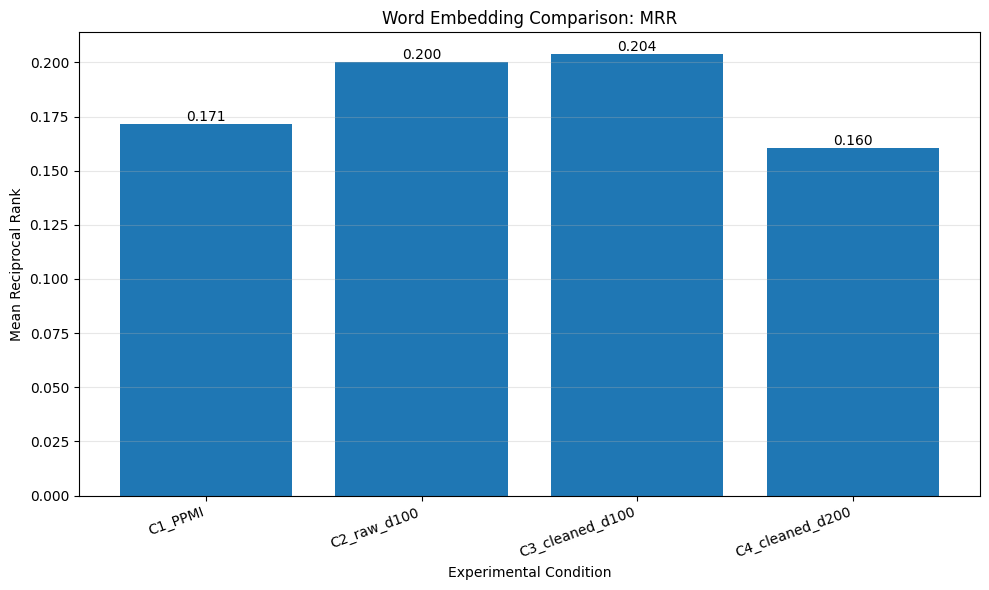


========== EVALUATION COMPLETED ==========
Common vocabulary: 2313
Query words: 5
Evaluation pairs: 20

Saved results in:
/content/BBC_Urdu_NLP_Assignment2/part1_word2vec/C1_C4_comparison

Files:
- C1_C4_MRR_comparison.png
- C1_C4_MRR_summary.csv
- C1_C4_pairwise_MRR.csv
- C1_C4_top5_nearest_neighbours.csv


In [38]:

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =====================================================
# 1. PATHS
# =====================================================

PROJECT = "/content/BBC_Urdu_NLP_Assignment2"

BASE = os.path.join(PROJECT, "part1_word2vec")
PPMI_DIR = os.path.join(PROJECT, "part1_ppmi")

OUTPUT_DIR = os.path.join(
    PROJECT, "part1_word2vec", "C1_C4_comparison"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

CONDITIONS = {
    "C1_PPMI": {
        "vocab": os.path.join(
            PPMI_DIR, "ppmi_vocabulary.json"
        ),
        "embedding": os.path.join(
            PPMI_DIR, "ppmi_matrix.npy"
        )
    },
    "C2_raw_d100": {
        "vocab": os.path.join(
            BASE, "C2_raw_d100", "vocabulary.json"
        ),
        "embedding": os.path.join(
            BASE, "C2_raw_d100", "embeddings_w2v.npy"
        )
    },
    "C3_cleaned_d100": {
        "vocab": os.path.join(
            BASE, "C3_cleaned_d100", "vocabulary.json"
        ),
        "embedding": os.path.join(
            BASE, "C3_cleaned_d100", "embeddings_w2v.npy"
        )
    },
    "C4_cleaned_d200": {
        "vocab": os.path.join(
            BASE, "C4_cleaned_d200", "vocabulary.json"
        ),
        "embedding": os.path.join(
            BASE, "C4_cleaned_d200", "embeddings_w2v.npy"
        )
    }
}

# =====================================================
# 2. LOAD VOCABULARIES
# =====================================================

def load_vocabulary(path):

    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)

    if isinstance(data, list):
        return {
            word: idx
            for idx, word in enumerate(data)
        }

    if isinstance(data, dict):

        if all(isinstance(v, int) for v in data.values()):
            return data

        if all(str(k).isdigit() for k in data.keys()):
            return {
                word: int(idx)
                for idx, word in data.items()
            }

    raise ValueError(
        f"Unknown vocabulary format: {path}"
    )


vocabs = {
    name: load_vocabulary(info["vocab"])
    for name, info in CONDITIONS.items()
}

print("========== VOCABULARY SIZES ==========")

for name, vocab in vocabs.items():
    print(f"{name}: {len(vocab):,}")

# Preserve PPMI vocabulary order for the common evaluation set
common_words = [
    word
    for word in vocabs["C1_PPMI"]
    if all(word in vocab for vocab in vocabs.values())
]

print("\nCommon vocabulary:", len(common_words))

assert len(common_words) == 2313

# =====================================================
# 3. LOAD EMBEDDING MATRICES
# =====================================================

embeddings = {}

for name, info in CONDITIONS.items():

    matrix = np.load(info["embedding"])

    vocab = vocabs[name]

    assert matrix.shape[0] == len(vocab), (
        f"{name}: embedding rows do not match vocabulary"
    )

    assert np.isfinite(matrix).all(), (
        f"{name}: non-finite embedding values found"
    )

    embeddings[name] = matrix.astype(
        np.float32,
        copy=False
    )

    print(
        f"{name}: embedding shape = {matrix.shape}"
    )

# =====================================================
# 4. BUILD IDENTICAL COMMON-VOCAB MATRICES
# =====================================================

common_matrices = {}

for name in CONDITIONS:

    indices = [
        vocabs[name][word]
        for word in common_words
    ]

    matrix = embeddings[name][indices]

    # Normalize rows for cosine similarity
    norms = np.linalg.norm(
        matrix,
        axis=1,
        keepdims=True
    )

    normalized = matrix / np.maximum(norms, 1e-12)

    common_matrices[name] = normalized

word_to_common_idx = {
    word: idx
    for idx, word in enumerate(common_words)
}

print("\nAll conditions restricted to the same")
print("2,313 words for fair evaluation.")

# =====================================================
# 5. FIVE QUERY WORDS
# =====================================================

query_words = [
    "پاکستان",
    "حکومت",
    "عدالت",
    "کرکٹ",
    "تعلیم"
]

assert all(
    word in word_to_common_idx
    for word in query_words
)

# =====================================================
# 6. TOP-5 NEAREST NEIGHBOURS
# =====================================================

neighbour_records = []

for condition, matrix in common_matrices.items():

    for query in query_words:

        query_idx = word_to_common_idx[query]

        scores = matrix @ matrix[query_idx]

        # Exclude the query itself
        scores[query_idx] = -np.inf

        top_indices = np.argsort(scores)[::-1][:5]

        for rank, idx in enumerate(top_indices, 1):

            neighbour_records.append({
                "Condition": condition,
                "Query": query,
                "Rank": rank,
                "Neighbour": common_words[idx],
                "Cosine_Similarity": float(scores[idx])
            })

neighbour_df = pd.DataFrame(neighbour_records)

neighbour_path = os.path.join(
    OUTPUT_DIR,
    "C1_C4_top5_nearest_neighbours.csv"
)

neighbour_df.to_csv(
    neighbour_path,
    index=False,
    encoding="utf-8-sig"
)

print("\n========== TOP-5 NEAREST NEIGHBOURS ==========")

for condition in CONDITIONS:

    print("\n", "=" * 65)
    print(condition)
    print("=" * 65)

    subset = neighbour_df[
        neighbour_df["Condition"] == condition
    ]

    for query in query_words:

        rows = subset[subset["Query"] == query]

        results = [
            f"{r.Neighbour} ({r.Cosine_Similarity:.3f})"
            for r in rows.itertuples()
        ]

        print(f"\n{query}:")
        print(" | ".join(results))

# =====================================================
# 7. 20 MANUALLY LABELLED SEMANTIC PAIRS
# =====================================================

evaluation_pairs = [
    ("پاکستان", "لاہور"),
    ("حکومت", "وزیر"),
    ("عدالت", "جج"),
    ("فوج", "افواج"),
    ("صحت", "طبی"),
    ("تعلیم", "استاد"),
    ("کرکٹ", "ٹیم"),
    ("معیشت", "تجارت"),
    ("پولیس", "جرم"),
    ("ہسپتال", "ڈاکٹر"),
    ("کھیل", "میچ"),
    ("صدر", "حکومت"),
    ("فرانس", "پیرس"),
    ("فٹبال", "برازیل"),
    ("تعلیم", "طالب"),
    ("حکومت", "ملک"),
    ("فوج", "ملک"),
    ("ٹیم", "کھیل"),
    ("عمر", "سال"),
    ("کام", "عمل")
]

assert len(evaluation_pairs) == 20

for word1, word2 in evaluation_pairs:
    assert word1 in word_to_common_idx, (
        f"Missing pair source: {word1}"
    )
    assert word2 in word_to_common_idx, (
        f"Missing pair target: {word2}"
    )

# =====================================================
# 8. MEAN RECIPROCAL RANK
# =====================================================

mrr_records = []
condition_summaries = []

for condition, matrix in common_matrices.items():

    reciprocal_ranks = []

    for source, target in evaluation_pairs:

        source_idx = word_to_common_idx[source]
        target_idx = word_to_common_idx[target]

        scores = matrix @ matrix[source_idx]

        # Exclude the source word
        scores[source_idx] = -np.inf

        target_score = scores[target_idx]

        # Rank is 1 + number of candidates with higher score
        rank = 1 + int(
            np.sum(scores > target_score)
        )

        reciprocal_rank = 1.0 / rank

        reciprocal_ranks.append(reciprocal_rank)

        mrr_records.append({
            "Condition": condition,
            "Source": source,
            "Target": target,
            "Rank": rank,
            "Reciprocal_Rank": reciprocal_rank
        })

    mrr = float(np.mean(reciprocal_ranks))

    condition_summaries.append({
        "Condition": condition,
        "MRR": mrr,
        "Evaluation_Pairs": len(evaluation_pairs)
    })

mrr_df = pd.DataFrame(mrr_records)
summary_df = pd.DataFrame(condition_summaries)

# =====================================================
# 9. SAVE EVALUATION TABLES
# =====================================================

mrr_df.to_csv(
    os.path.join(OUTPUT_DIR, "C1_C4_pairwise_MRR.csv"),
    index=False,
    encoding="utf-8-sig"
)

summary_df.to_csv(
    os.path.join(OUTPUT_DIR, "C1_C4_MRR_summary.csv"),
    index=False
)

print("\n========== MRR RESULTS ==========")

print(
    summary_df.to_string(
        index=False,
        formatters={"MRR": "{:.4f}".format}
    )
)

# =====================================================
# 10. C3 VS C4 IMPROVEMENT
# =====================================================

c3_mrr = summary_df.loc[
    summary_df["Condition"] == "C3_cleaned_d100",
    "MRR"
].iloc[0]

c4_mrr = summary_df.loc[
    summary_df["Condition"] == "C4_cleaned_d200",
    "MRR"
].iloc[0]

print("\n========== DIMENSION COMPARISON ==========")
print(f"C3 d=100 MRR: {c3_mrr:.4f}")
print(f"C4 d=200 MRR: {c4_mrr:.4f}")
print(f"Absolute MRR change: {c4_mrr - c3_mrr:+.4f}")

if c3_mrr > 0:
    relative_change = (
        (c4_mrr - c3_mrr) / c3_mrr
    ) * 100

    print(f"Relative MRR change: {relative_change:+.2f}%")

if c4_mrr > c3_mrr:
    print("Result: C4 performs better than C3 on this MRR test.")
elif c4_mrr < c3_mrr:
    print("Result: C3 performs better than C4 on this MRR test.")
else:
    print("Result: Both conditions have equal MRR.")

# =====================================================
# 11. MRR BAR CHART
# =====================================================

plt.figure(figsize=(10, 6))

plt.bar(
    summary_df["Condition"],
    summary_df["MRR"]
)

plt.title("Word Embedding Comparison: MRR")
plt.xlabel("Experimental Condition")
plt.ylabel("Mean Reciprocal Rank")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)

for i, value in enumerate(summary_df["MRR"]):
    plt.text(
        i,
        value,
        f"{value:.3f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "C1_C4_MRR_comparison.png"),
    dpi=300
)

plt.show()

# =====================================================
# 12. FINAL SUMMARY
# =====================================================

print("\n========== EVALUATION COMPLETED ==========")

print("Common vocabulary:", len(common_words))
print("Query words:", len(query_words))
print("Evaluation pairs:", len(evaluation_pairs))

print("\nSaved results in:")
print(OUTPUT_DIR)

print("\nFiles:")
for filename in sorted(os.listdir(OUTPUT_DIR)):
    print("-", filename)


MRR columns: ['Condition', 'MRR', 'Evaluation_Pairs']
Neighbour columns: ['Condition', 'Query', 'Rank', 'Neighbour', 'Cosine_Similarity']


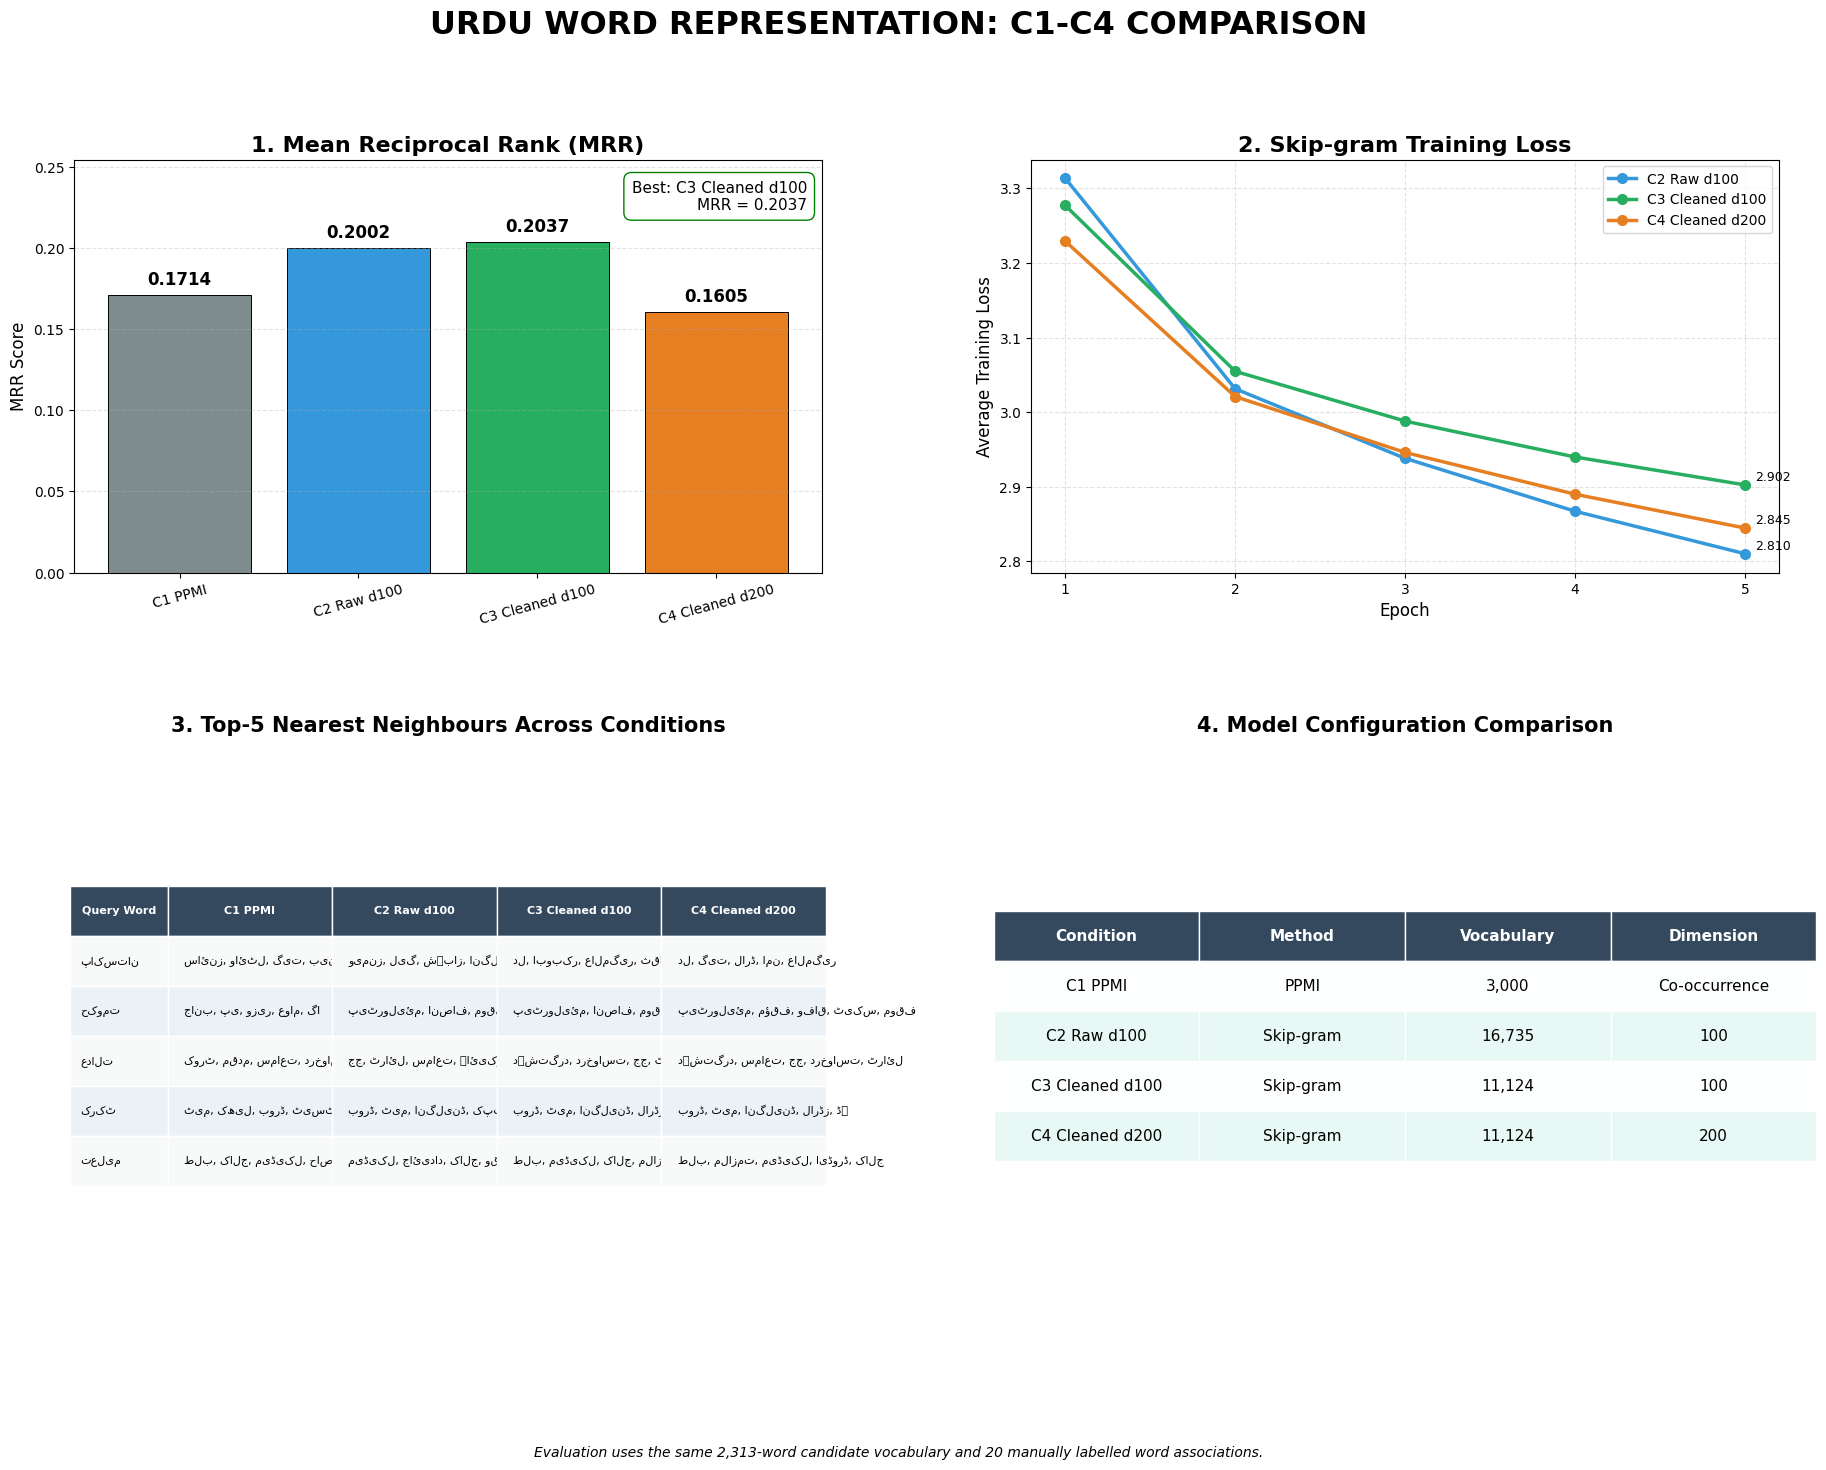


Dashboard saved successfully:
/content/BBC_Urdu_NLP_Assignment2/part1_word2vec/C1_C4_comparison/visualization_dashboard/C1_C4_Complete_Dashboard.png

MRR SUMMARY:


,Condition,MRR
0,C1 PPMI,0.171369
1,C2 Raw d100,0.200167
2,C3 Cleaned d100,0.203676
3,C4 Cleaned d200,0.160451



NEAREST-NEIGHBOUR COMPARISON:


,Query Word,C1 PPMI,C2 Raw d100,C3 Cleaned d100,C4 Cleaned d200
0,پاکستان,"سائنز, وائٹل, گیت, بینڈ, دل","ویمنز, لیگ, شہباز, انگلینڈ, دہشتگرد","دل, ابوبکر, عالمگیر, ثقافت, فتح","دل, گیت, لارڈ, امن, عالمگیر"
1,حکومت,"جانب, پی, وزیر, عوام, گا","پیٹرولیئم, انصاف, موقف, ریلیف, مؤقف","پیٹرولیئم, انصاف, موقف, مؤقف, تحریک","پیٹرولیئم, مؤقف, وفاق, ٹیکس, موقف"
2,عدالت,"کورٹ, مقدم, سماعت, درخواست, سپریم","جج, ٹرائل, سماعت, ہائیکورٹ, درخواست","دہشتگرد, درخواست, جج, ٹرائل, ایڈووکیٹ","دہشتگرد, سماعت, جج, درخواست, ٹرائل"
3,کرکٹ,"ٹیم, کھیل, بورڈ, ٹیسٹ, میچ","بورڈ, ٹیم, انگلینڈ, کپتان, جیسن","بورڈ, ٹیم, انگلینڈ, لارڈز, سیریز","بورڈ, ٹیم, انگلینڈ, لارڈز, ڈے"
4,تعلیم,"طلب, کالج, میڈیکل, حاصل, اخراج","میڈیکل, جائیداد, کالج, وقف, ایڈورڈ","طلب, میڈیکل, کالج, ملازمت, جائیداد","طلب, ملازمت, میڈیکل, ایڈورڈ, کالج"



MODEL CONFIGURATION:


,Condition,Method,Vocabulary,Dimension
0,C1 PPMI,PPMI,"3,000",Co-occurrence
1,C2 Raw d100,Skip-gram,"16,735",100
2,C3 Cleaned d100,Skip-gram,"11,124",100
3,C4 Cleaned d200,Skip-gram,"11,124",200


In [39]:

# ============================================================
# C1-C4 WORD2VEC COMPARISON DASHBOARD
# Uses existing saved results - NO MODEL TRAINING
# ============================================================

import os
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. PROJECT PATHS
# ------------------------------------------------------------

BASE = "/content/BBC_Urdu_NLP_Assignment2"

COMPARISON_DIR = os.path.join(
    BASE, "part1_word2vec", "C1_C4_comparison"
)

MODEL_DIRS = {
    "C2 Raw d100": os.path.join(
        BASE, "part1_word2vec", "C2_raw_d100"
    ),
    "C3 Cleaned d100": os.path.join(
        BASE, "part1_word2vec", "C3_cleaned_d100"
    ),
    "C4 Cleaned d200": os.path.join(
        BASE, "part1_word2vec", "C4_cleaned_d200"
    )
}

MRR_FILE = os.path.join(
    COMPARISON_DIR, "C1_C4_MRR_summary.csv"
)

NEIGHBOUR_FILE = os.path.join(
    COMPARISON_DIR, "C1_C4_top5_nearest_neighbours.csv"
)

OUTPUT_DIR = os.path.join(
    COMPARISON_DIR, "visualization_dashboard"
)
os.makedirs(OUTPUT_DIR, exist_ok=True)


# ------------------------------------------------------------
# 2. LOAD EXISTING COMPARISON RESULTS
# ------------------------------------------------------------

if not os.path.exists(MRR_FILE):
    raise FileNotFoundError(f"MRR file not found: {MRR_FILE}")

if not os.path.exists(NEIGHBOUR_FILE):
    raise FileNotFoundError(
        f"Nearest-neighbour file not found: {NEIGHBOUR_FILE}"
    )

mrr_df = pd.read_csv(MRR_FILE)
neighbour_df = pd.read_csv(NEIGHBOUR_FILE)

print("MRR columns:", list(mrr_df.columns))
print("Neighbour columns:", list(neighbour_df.columns))


# ------------------------------------------------------------
# 3. AUTOMATICALLY IDENTIFY CSV COLUMNS
# ------------------------------------------------------------

def find_column(df, possible_names):
    """Find a column using common alternative names."""
    normalized = {
        str(col).lower().replace(" ", "_"): col
        for col in df.columns
    }

    for name in possible_names:
        if name in normalized:
            return normalized[name]

    for col in df.columns:
        col_norm = str(col).lower().replace(" ", "_")
        if any(name in col_norm for name in possible_names):
            return col

    return None


condition_col = find_column(
    mrr_df, ["condition", "model", "configuration"]
)
mrr_col = find_column(
    mrr_df, ["mrr", "mean_reciprocal_rank"]
)

if condition_col is None or mrr_col is None:
    raise ValueError(
        "Could not identify condition/MRR columns. "
        "Check the printed MRR CSV column names."
    )

# Standardize condition labels
def standard_condition(value):
    value = str(value).lower()

    if "c1" in value:
        return "C1 PPMI"
    if "c2" in value:
        return "C2 Raw d100"
    if "c3" in value:
        return "C3 Cleaned d100"
    if "c4" in value:
        return "C4 Cleaned d200"

    return str(value)


mrr_df["Condition"] = mrr_df[condition_col].apply(
    standard_condition
)
mrr_df["MRR"] = pd.to_numeric(
    mrr_df[mrr_col], errors="coerce"
)
mrr_df = mrr_df.dropna(subset=["MRR"])

condition_order = [
    "C1 PPMI",
    "C2 Raw d100",
    "C3 Cleaned d100",
    "C4 Cleaned d200"
]

mrr_df["Condition"] = pd.Categorical(
    mrr_df["Condition"],
    categories=condition_order,
    ordered=True
)
mrr_df = mrr_df.sort_values("Condition")


# ------------------------------------------------------------
# 4. LOAD TRAINING LOSS CURVES
# C1 is PPMI, so it has no Skip-gram training loss.
# ------------------------------------------------------------

loss_data = {}

for condition, folder in MODEL_DIRS.items():

    possible_files = [
        os.path.join(folder, "training_loss.csv"),
        os.path.join(folder, "word2vec_training_loss.csv")
    ]

    loss_file = next(
        (f for f in possible_files if os.path.exists(f)),
        None
    )

    if loss_file is None:
        print(f"Training loss CSV not found for {condition}")
        continue

    loss_df = pd.read_csv(loss_file)

    epoch_col = find_column(
        loss_df, ["epoch", "epochs"]
    )
    loss_col = find_column(
        loss_df, ["average_loss", "avg_loss", "loss", "train_loss"]
    )

    if epoch_col is None or loss_col is None:
        print(f"Could not identify loss columns in {loss_file}")
        print("Available columns:", list(loss_df.columns))
        continue

    loss_df[epoch_col] = pd.to_numeric(
        loss_df[epoch_col], errors="coerce"
    )
    loss_df[loss_col] = pd.to_numeric(
        loss_df[loss_col], errors="coerce"
    )

    loss_df = loss_df.dropna(
        subset=[epoch_col, loss_col]
    )

    loss_data[condition] = (
        loss_df[epoch_col].values,
        loss_df[loss_col].values
    )


# ------------------------------------------------------------
# 5. PREPARE TOP-5 NEAREST-NEIGHBOUR COMPARISON
# ------------------------------------------------------------

n_condition_col = find_column(
    neighbour_df, ["condition", "model", "configuration"]
)
query_col = find_column(
    neighbour_df, ["query_word", "query", "source_word", "word"]
)
neighbour_col = find_column(
    neighbour_df, ["neighbor", "neighbour", "nearest_word"]
)
rank_col = find_column(
    neighbour_df, ["rank", "top_rank"]
)

if any(x is None for x in [
    n_condition_col, query_col, neighbour_col
]):
    raise ValueError(
        "Could not identify nearest-neighbour columns. "
        "Check the printed Neighbour CSV column names."
    )

neighbour_df["Condition"] = neighbour_df[
    n_condition_col
].apply(standard_condition)

# Keep only top five neighbours if rank is available
if rank_col is not None:
    neighbour_df[rank_col] = pd.to_numeric(
        neighbour_df[rank_col], errors="coerce"
    )
    neighbour_df = neighbour_df[
        neighbour_df[rank_col].isna()
        | (neighbour_df[rank_col] <= 5)
    ]

# Build one cell containing five neighbours per query/condition
neighbour_table = {}

for _, row in neighbour_df.iterrows():

    condition = row["Condition"]
    query = str(row[query_col])
    neighbour = str(row[neighbour_col])

    key = (query, condition)

    if key not in neighbour_table:
        neighbour_table[key] = []

    neighbour_table[key].append(neighbour)

queries = [
    "پاکستان",
    "حکومت",
    "عدالت",
    "کرکٹ",
    "تعلیم"
]

table_rows = []

for query in queries:

    row = {"Query Word": query}

    for condition in condition_order:

        words = neighbour_table.get(
            (query, condition), []
        )

        row[condition] = ", ".join(words[:5]) if words else "Not available"

    table_rows.append(row)

neighbour_display = pd.DataFrame(table_rows)


# ------------------------------------------------------------
# 6. MODEL CONFIGURATION INFORMATION
# ------------------------------------------------------------

configuration = [
    ["C1 PPMI", "PPMI", "3,000", "Co-occurrence"],
    ["C2 Raw d100", "Skip-gram", "16,735", "100"],
    ["C3 Cleaned d100", "Skip-gram", "11,124", "100"],
    ["C4 Cleaned d200", "Skip-gram", "11,124", "200"]
]

config_df = pd.DataFrame(
    configuration,
    columns=[
        "Condition",
        "Method",
        "Vocabulary",
        "Dimension"
    ]
)


# ------------------------------------------------------------
# 7. CREATE VISUAL DASHBOARD
# ------------------------------------------------------------

plt.rcParams["font.family"] = "DejaVu Sans"

fig = plt.figure(figsize=(22, 15))
fig.suptitle(
    "URDU WORD REPRESENTATION: C1-C4 COMPARISON",
    fontsize=23,
    fontweight="bold",
    y=0.98
)

gs = GridSpec(
    2, 2,
    figure=fig,
    height_ratios=[1, 1.35],
    hspace=0.38,
    wspace=0.28
)


# ------------------------------------------------------------
# PANEL 1: MRR COMPARISON
# ------------------------------------------------------------

ax1 = fig.add_subplot(gs[0, 0])

colors = [
    "#7F8C8D",
    "#3498DB",
    "#27AE60",
    "#E67E22"
]

bars = ax1.bar(
    mrr_df["Condition"].astype(str),
    mrr_df["MRR"],
    color=colors[:len(mrr_df)],
    edgecolor="black",
    linewidth=0.7
)

for bar, value in zip(bars, mrr_df["MRR"]):
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.004,
        f"{value:.4f}",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold"
    )

best_row = mrr_df.loc[mrr_df["MRR"].idxmax()]

ax1.set_title(
    "1. Mean Reciprocal Rank (MRR)",
    fontsize=16,
    fontweight="bold"
)
ax1.set_ylabel("MRR Score", fontsize=12)
ax1.set_ylim(0, max(mrr_df["MRR"]) * 1.25)
ax1.tick_params(axis="x", rotation=15)
ax1.grid(axis="y", linestyle="--", alpha=0.35)

ax1.text(
    0.98, 0.95,
    f"Best: {best_row['Condition']}\nMRR = {best_row['MRR']:.4f}",
    transform=ax1.transAxes,
    ha="right",
    va="top",
    fontsize=11,
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="white",
        edgecolor="green"
    )
)


# ------------------------------------------------------------
# PANEL 2: TRAINING LOSS CURVES
# ------------------------------------------------------------

ax2 = fig.add_subplot(gs[0, 1])

loss_colors = {
    "C2 Raw d100": "#3498DB",
    "C3 Cleaned d100": "#27AE60",
    "C4 Cleaned d200": "#E67E22"
}

for condition, (epochs, losses) in loss_data.items():

    ax2.plot(
        epochs,
        losses,
        marker="o",
        linewidth=2.5,
        markersize=7,
        label=condition,
        color=loss_colors.get(condition)
    )

    ax2.annotate(
        f"{losses[-1]:.3f}",
        (epochs[-1], losses[-1]),
        xytext=(7, 3),
        textcoords="offset points",
        fontsize=9
    )

ax2.set_title(
    "2. Skip-gram Training Loss",
    fontsize=16,
    fontweight="bold"
)
ax2.set_xlabel("Epoch", fontsize=12)
ax2.set_ylabel("Average Training Loss", fontsize=12)
ax2.set_xticks([1, 2, 3, 4, 5])
ax2.grid(True, linestyle="--", alpha=0.35)
ax2.legend(fontsize=10)


# ------------------------------------------------------------
# PANEL 3: TOP-5 NEAREST NEIGHBOURS
# ------------------------------------------------------------

ax3 = fig.add_subplot(gs[1, 0])
ax3.axis("off")

ax3.set_title(
    "3. Top-5 Nearest Neighbours Across Conditions",
    fontsize=15,
    fontweight="bold",
    pad=18
)

table = ax3.table(
    cellText=neighbour_display.values,
    colLabels=neighbour_display.columns,
    cellLoc="left",
    colLoc="center",
    loc="center",
    colWidths=[0.13, 0.22, 0.22, 0.22, 0.22]
)

table.auto_set_font_size(False)
table.set_fontsize(8)
table.scale(1.0, 3.0)

for (row, col), cell in table.get_celld().items():

    if row == 0:
        cell.set_text_props(
            weight="bold",
            color="white"
        )
        cell.set_facecolor("#34495E")
    else:
        cell.set_facecolor(
            "#EAF2F8" if row % 2 == 0 else "#F8F9F9"
        )

    cell.set_edgecolor("white")


# ------------------------------------------------------------
# PANEL 4: MODEL CONFIGURATION
# ------------------------------------------------------------

ax4 = fig.add_subplot(gs[1, 1])
ax4.axis("off")

ax4.set_title(
    "4. Model Configuration Comparison",
    fontsize=15,
    fontweight="bold",
    pad=18
)

config_table = ax4.table(
    cellText=config_df.values,
    colLabels=config_df.columns,
    cellLoc="center",
    colLoc="center",
    loc="center"
)

config_table.auto_set_font_size(False)
config_table.set_fontsize(11)
config_table.scale(1.1, 3.0)

for (row, col), cell in config_table.get_celld().items():

    if row == 0:
        cell.set_text_props(
            weight="bold",
            color="white"
        )
        cell.set_facecolor("#34495E")
    else:
        cell.set_facecolor(
            "#E8F8F5" if row % 2 == 0 else "#FDFEFE"
        )

    cell.set_edgecolor("white")


# ------------------------------------------------------------
# 8. FINAL OUTPUT AND SAVE
# ------------------------------------------------------------

fig.text(
    0.5, 0.015,
    "Evaluation uses the same 2,313-word candidate vocabulary "
    "and 20 manually labelled word associations.",
    ha="center",
    fontsize=10,
    style="italic"
)

plt.savefig(
    os.path.join(OUTPUT_DIR, "C1_C4_Complete_Dashboard.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nDashboard saved successfully:")
print(
    os.path.join(
        OUTPUT_DIR, "C1_C4_Complete_Dashboard.png"
    )
)

print("\nMRR SUMMARY:")
display(mrr_df[[condition_col, mrr_col]])

print("\nNEAREST-NEIGHBOUR COMPARISON:")
display(neighbour_display)

print("\nMODEL CONFIGURATION:")
display(config_df)


In [40]:

# ============================================================
# PART 1.1 — EXACT TF-IDF IMPLEMENTATION
# 9999 frequent words + <UNK> = 10000 features
# ============================================================

import os
import re
import json
import shutil
import numpy as np
import pandas as pd
from collections import Counter
from scipy.sparse import csr_matrix, save_npz

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

BASE = "/content/BBC_Urdu_NLP_Assignment2"

INPUT_FILE = os.path.join(BASE, "data", "cleaned.txt")

OUTPUT_DIR = os.path.join(BASE, "part1_tfidf")
os.makedirs(OUTPUT_DIR, exist_ok=True)

MATRIX_FILE = os.path.join(OUTPUT_DIR, "tfidf_matrix.npy")

# Preserve any previous matrix
if os.path.exists(MATRIX_FILE):
    shutil.copy2(
        MATRIX_FILE,
        os.path.join(OUTPUT_DIR, "tfidf_matrix_previous_backup.npy")
    )
    print("Previous TF-IDF matrix backed up.")

# ------------------------------------------------------------
# 2. LOAD AND EXTRACT ARTICLES
# ------------------------------------------------------------

with open(INPUT_FILE, "r", encoding="utf-8") as f:
    lines = f.readlines()

articles = []

for line in lines:
    line = line.strip()

    if not line:
        continue

    # Ignore ARTICLE 1, ARTICLE 2, etc.
    if re.fullmatch(r"ARTICLE\s+\d+", line, flags=re.I):
        continue

    articles.append(line)

print("Articles extracted:", len(articles))

assert len(articles) == 246, (
    f"Expected 246 articles, found {len(articles)}"
)

# ------------------------------------------------------------
# 3. TOKENIZE
# ------------------------------------------------------------

TOKEN_PATTERN = re.compile(r"[\u0600-\u06FF]+")

tokenized_articles = [
    TOKEN_PATTERN.findall(article)
    for article in articles
]

print(
    "Total tokens:",
    sum(len(tokens) for tokens in tokenized_articles)
)

# ------------------------------------------------------------
# 4. BUILD FREQUENCY COUNTER
# ------------------------------------------------------------

word_frequency = Counter()

for tokens in tokenized_articles:
    word_frequency.update(tokens)

print("Unique tokens:", len(word_frequency))

# 9999 frequent words + one UNK feature
MAX_FEATURES = 10000

most_common_words = [
    word for word, count in
    word_frequency.most_common(MAX_FEATURES - 1)
]

vocabulary = most_common_words + ["<UNK>"]

word_to_index = {
    word: idx
    for idx, word in enumerate(vocabulary)
}

print("Final vocabulary size:", len(vocabulary))

assert len(vocabulary) == 10000

# ------------------------------------------------------------
# 5. MAP RARE WORDS TO <UNK>
# ------------------------------------------------------------

document_frequency = np.zeros(
    len(vocabulary),
    dtype=np.int32
)

term_frequency_rows = []
term_frequency_cols = []
term_frequency_values = []

for doc_idx, tokens in enumerate(tokenized_articles):

    mapped_tokens = [
        word if word in word_to_index else "<UNK>"
        for word in tokens
    ]

    counts = Counter(mapped_tokens)

    for word, count in counts.items():

        word_idx = word_to_index[word]

        term_frequency_rows.append(doc_idx)
        term_frequency_cols.append(word_idx)
        term_frequency_values.append(count)

        # Document frequency: count documents containing word
        document_frequency[word_idx] += 1

# ------------------------------------------------------------
# 6. BUILD TERM-DOCUMENT MATRIX
# ------------------------------------------------------------

N = len(articles)

tf_matrix = csr_matrix(
    (
        np.array(term_frequency_values, dtype=np.float32),
        (
            np.array(term_frequency_rows),
            np.array(term_frequency_cols)
        )
    ),
    shape=(N, len(vocabulary)),
    dtype=np.float32
)

# ------------------------------------------------------------
# 7. APPLY EXACT ASSIGNMENT IDF FORMULA
# ------------------------------------------------------------

idf = np.log(
    N / (1.0 + document_frequency)
).astype(np.float32)

# TF-IDF = TF * IDF
tfidf_matrix = tf_matrix.multiply(idf).tocsr()

# Save dense matrix as requested
np.save(
    MATRIX_FILE,
    tfidf_matrix.toarray().astype(np.float32)
)

# Also save sparse version to conserve storage
save_npz(
    os.path.join(OUTPUT_DIR, "tfidf_matrix_sparse.npz"),
    tfidf_matrix
)

# ------------------------------------------------------------
# 8. SAVE VOCABULARY AND IDF
# ------------------------------------------------------------

with open(
    os.path.join(OUTPUT_DIR, "tfidf_vocabulary.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        vocabulary,
        f,
        ensure_ascii=False,
        indent=2
    )

pd.DataFrame({
    "word": vocabulary,
    "document_frequency": document_frequency,
    "idf": idf
}).to_csv(
    os.path.join(OUTPUT_DIR, "tfidf_vocabulary_statistics.csv"),
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 9. VALIDATION
# ------------------------------------------------------------

print("\n========== TF-IDF VALIDATION ==========")

print("Number of documents:", N)
print("Vocabulary dimensions:", len(vocabulary))
print("Matrix shape:", tfidf_matrix.shape)
print("UNK document frequency:", document_frequency[-1])
print("UNK IDF:", idf[-1])

print("All matrix values finite:",
      np.isfinite(tfidf_matrix.data).all())

print("Matrix contains <UNK>:",
      "<UNK>" in word_to_index)

print("TF-IDF matrix saved:",
      os.path.exists(MATRIX_FILE))

print("Final matrix shape:",
      np.load(MATRIX_FILE, mmap_mode="r").shape)

assert tfidf_matrix.shape == (246, 10000)
assert np.isfinite(tfidf_matrix.data).all()

print("\nTF-IDF implementation completed successfully.")
print("Output directory:", OUTPUT_DIR)


Previous TF-IDF matrix backed up.
Articles extracted: 246
Total tokens: 382689
Unique tokens: 11124
Final vocabulary size: 10000

========== TF-IDF VALIDATION ==========
Number of documents: 246
Vocabulary dimensions: 10000
Matrix shape: (246, 10000)
UNK document frequency: 61
UNK IDF: 1.3781972
All matrix values finite: True
Matrix contains <UNK>: True
TF-IDF matrix saved: True
Final matrix shape: (246, 10000)

TF-IDF implementation completed successfully.
Output directory: /content/BBC_Urdu_NLP_Assignment2/part1_tfidf


In [41]:

# ============================================================
# PART 1.1 — CREATE TOPIC ANNOTATION TEMPLATE
# ============================================================

import os
import re
import json
import pandas as pd

BASE = "/content/BBC_Urdu_NLP_Assignment2"

METADATA_FILE = os.path.join(BASE, "data", "Metadata.json")
CLEANED_FILE = os.path.join(BASE, "data", "cleaned.txt")

OUTPUT_DIR = os.path.join(BASE, "part1_tfidf")
os.makedirs(OUTPUT_DIR, exist_ok=True)

OUTPUT_FILE = os.path.join(
    OUTPUT_DIR, "article_topic_annotations.csv"
)

# ------------------------------------------------------------
# 1. LOAD METADATA
# ------------------------------------------------------------

with open(METADATA_FILE, "r", encoding="utf-8") as f:
    metadata = json.load(f)

# Support either a list or a dictionary containing records
if isinstance(metadata, dict):
    if "articles" in metadata:
        metadata = metadata["articles"]
    else:
        metadata = list(metadata.values())

# ------------------------------------------------------------
# 2. EXTRACT ARTICLE TEXT
# ------------------------------------------------------------

with open(CLEANED_FILE, "r", encoding="utf-8") as f:
    lines = f.readlines()

articles = []

for line in lines:
    line = line.strip()

    if not line:
        continue

    if re.fullmatch(r"ARTICLE\s+\d+", line, flags=re.I):
        continue

    articles.append(line)

assert len(metadata) == 246, (
    f"Expected 246 metadata records, found {len(metadata)}"
)

assert len(articles) == 246, (
    f"Expected 246 articles, found {len(articles)}"
)

# ------------------------------------------------------------
# 3. CREATE ANNOTATION TEMPLATE
# ------------------------------------------------------------

rows = []

for i, (record, article_text) in enumerate(
    zip(metadata, articles), start=1
):

    rows.append({
        "article_number": record.get("article_number", i),
        "title": record.get("title", ""),
        "date": record.get("date", ""),
        "url": record.get("url", ""),
        "word_count": record.get("word_count", ""),
        "text_preview": article_text[:700],
        "topic_label": ""
    })

annotation_df = pd.DataFrame(rows)

# ------------------------------------------------------------
# 4. SAVE TEMPLATE
# ------------------------------------------------------------

annotation_df.to_csv(
    OUTPUT_FILE,
    index=False,
    encoding="utf-8-sig"
)

print("Topic annotation template created.")
print("Articles:", len(annotation_df))
print("Topic labels currently assigned: 0")
print("\nOutput file:")
print(OUTPUT_FILE)

print("\nAvailable topic labels:")
print([
    "Politics",
    "Sports",
    "Business",
    "Technology",
    "Entertainment"
])

print("\nPreview:")
display(
    annotation_df[
        ["article_number", "title", "text_preview", "topic_label"]
    ].head(10)
)


Topic annotation template created.
Articles: 246
Topic labels currently assigned: 0

Output file:
/content/BBC_Urdu_NLP_Assignment2/part1_tfidf/article_topic_annotations.csv

Available topic labels:
['Politics', 'Sports', 'Business', 'Technology', 'Entertainment']

Preview:


,article_number,title,text_preview,topic_label
0,1,سائنسدانوں کے لیے معمہ بننے والی وہ مچھلیاں جو...,میکسیکو اور جنوب ٹیکساس کے دریاؤں میں مچھل کی ...,
1,2,دو ملکوں میں تقسیم خاندان کی کہانی: ’مرنے سے پ...,’پارٹیشن نے ہر اس فیمل کو تبا کر دیا جس نے اپن...,
2,3,ایمان مزاری اور ہادی علی چٹھہ رہائی کے بعد دوس...,سپریم کورٹ سے <NUM> برس قید کی سزا کی معطل اور...,
3,4,ڈاکٹر عظمیٰ کی عمران خان سے ملاقات اور محمد مُ...,’وہ ( عمر خان ) بار بار ایک ہی بات کہہ رہے تھے...,
4,5,لارڈز ٹیسٹ کا پہلا دن، بابر کی کپتانی کا امتحا...,لارڈز کے مید میں پاکست کی ٹیم سے یہ امید کی جا...,
5,6,پاکستان میں فیشن ڈیزائنر کیسے بنا جا سکتا ہے ا...,ریمپ پر کیٹ واک کرت ماڈلز ، روشن کی چکا چوند ا...,
6,7,سپاٹ فکسنگ سکینڈل: دنیا کو دھوکہ دینے والی تین...,نوٹ : یہ تحریر پہل مرتب <NUM> اگست <NUM> کو شا...,
7,8,’غلط فہمی کے شکار‘ مظاہرین کی پاکستانی ٹیم کے ...,ایک طرف جہاں پاکست کی مرد کی قوم کرکٹ ٹیم دور ...,
8,9,ساؤتھ ایئر: پاکستان میں اے ٹی آر طیاروں کے سات...,پاکست میں ایئر لائن کے شعب میں ایک نئی ایئر لا...,
9,10,خانہ بدوشوں کے عالمی مقابلوں میں پاکستان کے چا...,کرغزست میں ایک ہفت تک جار رہن وال چھٹ ورلڈ نوم...,


In [42]:

# ============================================================
# PART 1.1 — SEMI-AUTOMATIC TOPIC SUGGESTIONS
# Suggestions require human review before final evaluation.
# ============================================================

import os
import pandas as pd

BASE = "/content/BBC_Urdu_NLP_Assignment2"

INPUT_FILE = os.path.join(
    BASE, "part1_tfidf", "article_topic_annotations.csv"
)

OUTPUT_FILE = os.path.join(
    BASE, "part1_tfidf", "article_topic_suggestions.csv"
)

df = pd.read_csv(INPUT_FILE).fillna("")

# ------------------------------------------------------------
# 1. TOPIC KEYWORDS
# These are heuristic indicators, not ground-truth labels.
# ------------------------------------------------------------

keywords = {
    "Politics": [
        "حکومت", "وزیر", "سیاست", "سیاسی", "انتخابات",
        "پارلیمنٹ", "صدر", "وزارت", "عمران خان",
        "سپریم کورٹ", "اسمبلی", "اپوزیشن", "عدالت",
        "قانون", "پارٹی", "مظاہرین", "پاکستانی سیاست"
    ],

    "Sports": [
        "کرکٹ", "فٹبال", "فٹ بال", "ٹیسٹ", "میچ",
        "ٹیم", "کپتان", "کھلاڑی", "ورلڈ کپ",
        "اسکور", "گول", "اولمپک", "ٹورنامنٹ",
        "بابر", "کوہلی", "لیگ", "اسٹیڈیم"
    ],

    "Business": [
        "معیشت", "کاروبار", "تجارت", "مارکیٹ",
        "قیمت", "مہنگائی", "روپے", "ڈالر",
        "بینک", "سرمایہ", "کمپنی", "منافع",
        "نقصان", "ٹیکس", "بجٹ", "اسٹاک",
        "معاشی", "ایئر لائن"
    ],

    "Technology": [
        "ٹیکنالوجی", "سائنس", "سائنسدان", "کمپیوٹر",
        "موبائل", "انٹرنیٹ", "مصنوعی ذہانت",
        "روبوٹ", "ایپ", "ڈیجیٹل", "سافٹ ویئر",
        "خلائی", "سیٹلائٹ", "تحقیق", "ایجاد",
        "ڈیٹا", "آلہ"
    ],

    "Entertainment": [
        "فلم", "اداکار", "اداکارہ", "گلوکار",
        "گلوکارہ", "موسیقی", "ڈرامہ", "فیشن",
        "ٹی وی", "شوبز", "گانا", "فنکار",
        "سیریز", "سنیما", "تفریح", "مشہور شخصیت"
    ]
}

# ------------------------------------------------------------
# 2. FIND MATCHING TOPICS
# ------------------------------------------------------------

def suggest_topic(title, preview):

    text = f"{title} {preview}"

    scores = {}

    for topic, words in keywords.items():

        scores[topic] = sum(
            text.count(word)
            for word in words
        )

    ranked = sorted(
        scores.items(),
        key=lambda x: x[1],
        reverse=True
    )

    best_topic, best_score = ranked[0]
    second_score = ranked[1][1]

    # Require at least one keyword and a clear lead
    if best_score == 0:
        return "Review", scores

    if best_score == second_score:
        return "Review", scores

    return best_topic, scores


# ------------------------------------------------------------
# 3. GENERATE SUGGESTIONS
# ------------------------------------------------------------

suggestions = []
score_records = []

for _, row in df.iterrows():

    topic, scores = suggest_topic(
        str(row["title"]),
        str(row["text_preview"])
    )

    suggestions.append(topic)
    score_records.append(scores)

df["suggested_topic"] = suggestions
df["annotation_status"] = "Needs human review"

score_df = pd.DataFrame(score_records).add_prefix("score_")

df = pd.concat(
    [df.reset_index(drop=True), score_df],
    axis=1
)

# Create a separate final-label column for manual review
df["final_topic_label"] = ""

# ------------------------------------------------------------
# 4. SAVE
# ------------------------------------------------------------

df.to_csv(
    OUTPUT_FILE,
    index=False,
    encoding="utf-8-sig"
)

print("Topic suggestions generated.")
print("Total articles:", len(df))

print("\nSuggested topic counts:")
print(df["suggested_topic"].value_counts())

print("\nFirst 20 suggestions:")
display(
    df[
        [
            "article_number",
            "title",
            "suggested_topic",
            "annotation_status"
        ]
    ].head(20)
)

print("\nSaved to:")
print(OUTPUT_FILE)


Topic suggestions generated.
Total articles: 246

Suggested topic counts:
suggested_topic
Politics         73
Review           65
Sports           31
Entertainment    29
Business         28
Technology       20
Name: count, dtype: int64

First 20 suggestions:


,article_number,title,suggested_topic,annotation_status
0,1,سائنسدانوں کے لیے معمہ بننے والی وہ مچھلیاں جو...,Technology,Needs human review
1,2,دو ملکوں میں تقسیم خاندان کی کہانی: ’مرنے سے پ...,Politics,Needs human review
2,3,ایمان مزاری اور ہادی علی چٹھہ رہائی کے بعد دوس...,Politics,Needs human review
3,4,ڈاکٹر عظمیٰ کی عمران خان سے ملاقات اور محمد مُ...,Politics,Needs human review
4,5,لارڈز ٹیسٹ کا پہلا دن، بابر کی کپتانی کا امتحا...,Sports,Needs human review
5,6,پاکستان میں فیشن ڈیزائنر کیسے بنا جا سکتا ہے ا...,Entertainment,Needs human review
6,7,سپاٹ فکسنگ سکینڈل: دنیا کو دھوکہ دینے والی تین...,Sports,Needs human review
7,8,’غلط فہمی کے شکار‘ مظاہرین کی پاکستانی ٹیم کے ...,Sports,Needs human review
8,9,ساؤتھ ایئر: پاکستان میں اے ٹی آر طیاروں کے سات...,Business,Needs human review
9,10,خانہ بدوشوں کے عالمی مقابلوں میں پاکستان کے چا...,Review,Needs human review



Saved to:
/content/BBC_Urdu_NLP_Assignment2/part1_tfidf/article_topic_suggestions.csv


In [43]:

# ============================================================
# TOPIC ANNOTATION — HUMAN REVIEW FILE
# ============================================================

import os
import pandas as pd

BASE = "/content/BBC_Urdu_NLP_Assignment2"

INPUT_FILE = os.path.join(
    BASE, "part1_tfidf", "article_topic_suggestions.csv"
)

OUTPUT_FILE = os.path.join(
    BASE, "part1_tfidf", "article_topic_review.csv"
)

df = pd.read_csv(INPUT_FILE).fillna("")

# Use suggestions as provisional labels, not verified labels
df["final_topic_label"] = df["suggested_topic"].replace({
    "Review": ""
})

df["annotation_status"] = "UNVERIFIED"

# Articles needing manual classification
review_df = df[
    df["suggested_topic"] == "Review"
]

# Save a separate complete review file
df.to_csv(
    OUTPUT_FILE,
    index=False,
    encoding="utf-8-sig"
)

print("Review file created:", OUTPUT_FILE)
print("Total articles:", len(df))
print("Provisional labels:", (df["final_topic_label"] != "").sum())
print("Articles requiring a topic decision:", len(review_df))

print("\nArticles requiring manual topic assignment:")
display(
    review_df[
        ["article_number", "title", "text_preview"]
    ]
)

print("\nProvisional category distribution:")
print(df["final_topic_label"].value_counts())


Review file created: /content/BBC_Urdu_NLP_Assignment2/part1_tfidf/article_topic_review.csv
Total articles: 246
Provisional labels: 181
Articles requiring a topic decision: 65

Articles requiring manual topic assignment:


,article_number,title,text_preview
9,10,خانہ بدوشوں کے عالمی مقابلوں میں پاکستان کے چا...,کرغزست میں ایک ہفت تک جار رہن وال چھٹ ورلڈ نوم...
18,19,انڈیا میں سول سروس کے امتحان میں کامیابی پانے ...,انڈی کی سول سروسز کے اس سال کے امتح میں مسلمان...
22,23,’اپنے استاد کی شرمندگی پر پردہ ڈال دو میرے بچے...,انتبا : اس تحریر میں جنس بدسلوک سے متعلق تفصیل...
24,25,بچے کی پیدائش کے بعد وزن کم کرنے کا دباؤ: ’ہر ...,’اب جلد ہی پرا شکل میں واپس آجاؤ ۔ جیس پہل تھی...
30,31,خوف کی علامت سمجھا جانے والا ’ڈرٹی ہیری سیریل ...,لوئ وان شور ، جو سیکیورٹ گارڈ کے طور پر کام کر...
...,...,...,...
222,223,کترنوں سے ڈیزائنر مصنوعات بنانے والی پاکستانی ...,’کوئ بھی چیز بے کار نہیں ہوت ۔ آپ پرا چیز کو ب...
224,225,وہ نوکیلے جوتے جنھیں لندن میں ’شیطانی پنجے‘ قر...,قرون وسط کے زما میں شاید سب سے بڑا خطر اس وقت ...
232,233,توہین مذہب کا الزام: ننکانہ میں ہجوم کے ہاتھوں...,’میر بیٹ کی جب سے اپن بیو سے طلاق ہوئ تھی ، اس...
233,234,’رؤف پڑھنے کے لیے تربت گیا تھا، توہین مذہب کے ...,’جہاں تک مجھ معلوم ہے رؤف ایک آزاد منش انس تھا...



Provisional category distribution:
final_topic_label
Politics         73
                 65
Sports           31
Entertainment    29
Business         28
Technology       20
Name: count, dtype: int64


In [44]:

from google.colab import files

REVIEW_FILE = (
    "/content/BBC_Urdu_NLP_Assignment2/"
    "part1_tfidf/article_topic_review.csv"
)

files.download(REVIEW_FILE)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [45]:

# ============================================================
# PART 1.1 — CORRECTED TF-IDF IMPLEMENTATION
# Exact assignment formula + 10,000 columns including <UNK>
# ============================================================

import os
import re
import json
import glob
import numpy as np
import pandas as pd
from collections import Counter

BASE_DIR = "/content/BBC_Urdu_NLP_Assignment2"
DATA_DIR = os.path.join(BASE_DIR, "data")
OUTPUT_DIR = os.path.join(BASE_DIR, "part1_tfidf")
os.makedirs(OUTPUT_DIR, exist_ok=True)

CLEANED_FILE = os.path.join(DATA_DIR, "cleaned.txt")
TOKEN_PATTERN = re.compile(r"[\u0600-\u06FF]+")

# ------------------------------------------------------------
# 1. Extract article texts (ignore ARTICLE marker lines)
# ------------------------------------------------------------
with open(CLEANED_FILE, "r", encoding="utf-8") as f:
    lines = f.read().splitlines()

documents = []
i = 0

while i < len(lines):
    line = lines[i].strip()

    if re.fullmatch(r"ARTICLE\s+\d+", line):
        i += 1

        # Find the next non-empty line as the article text
        while i < len(lines) and not lines[i].strip():
            i += 1

        if i < len(lines):
            documents.append(lines[i].strip())

    i += 1

tokenized_docs = [
    TOKEN_PATTERN.findall(doc) for doc in documents
]

assert len(documents) == 246, (
    f"Expected 246 articles, found {len(documents)}"
)

print("Articles loaded:", len(documents))
print("Total Urdu tokens:", sum(map(len, tokenized_docs)))

# ------------------------------------------------------------
# 2. Build vocabulary: 9,999 frequent words + <UNK>
# ------------------------------------------------------------
global_counts = Counter(
    token for doc in tokenized_docs for token in doc
)

most_frequent = [
    word for word, count in global_counts.most_common(9999)
]

vocabulary = ["<UNK>"] + most_frequent
word_to_index = {word: idx for idx, word in enumerate(vocabulary)}

assert len(vocabulary) == 10000

# ------------------------------------------------------------
# 3. Build term-document frequency matrix
# Rows = articles; columns = vocabulary terms
# All excluded words are mapped to <UNK>
# ------------------------------------------------------------
N = len(tokenized_docs)
V = len(vocabulary)

tf = np.zeros((N, V), dtype=np.float32)

for doc_idx, tokens in enumerate(tokenized_docs):
    mapped_tokens = [
        token if token in word_to_index else "<UNK>"
        for token in tokens
    ]

    counts = Counter(mapped_tokens)

    for word, count in counts.items():
        tf[doc_idx, word_to_index[word]] = count

print("TF matrix shape:", tf.shape)
print("Total tokens represented:", int(tf.sum()))

# ------------------------------------------------------------
# 4. Calculate document frequency and exact IDF
# Assignment formula:
# IDF(w) = log(N / (1 + df(w)))
# ------------------------------------------------------------
df = np.count_nonzero(tf > 0, axis=0)

idf = np.log(
    N / (1.0 + df.astype(np.float64))
).astype(np.float32)

# TF-IDF = TF * IDF
tfidf_matrix = tf * idf[np.newaxis, :]

# ------------------------------------------------------------
# 5. Save matrix, vocabulary, and IDF
# ------------------------------------------------------------
np.save(
    os.path.join(OUTPUT_DIR, "tfidf_matrix.npy"),
    tfidf_matrix
)

with open(
    os.path.join(OUTPUT_DIR, "tfidf_vocabulary.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(vocabulary, f, ensure_ascii=False, indent=2)

pd.DataFrame({
    "word": vocabulary,
    "document_frequency": df,
    "idf": idf
}).to_csv(
    os.path.join(OUTPUT_DIR, "tfidf_idf_values.csv"),
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 6. Find an existing annotation CSV/XLSX with topic labels
# ------------------------------------------------------------
annotation_df = None
annotation_path = None

candidate_files = (
    glob.glob(os.path.join(BASE_DIR, "**", "*.csv"), recursive=True)
    + glob.glob(os.path.join(BASE_DIR, "**", "*.xlsx"), recursive=True)
)

for path in candidate_files:
    try:
        if path.endswith(".csv"):
            candidate = pd.read_csv(path)
        else:
            candidate = pd.read_excel(path)

        columns = set(candidate.columns.astype(str))

        if (
            "article_number" in columns
            and "final_topic_label" in columns
        ):
            annotation_df = candidate
            annotation_path = path
            break

    except Exception:
        continue

# ------------------------------------------------------------
# 7. Generate top-10 terms per topic
# Uses existing final_topic_label values.
# Blank labels are excluded, not guessed.
# ------------------------------------------------------------
if annotation_df is not None:
    print("\nAnnotation file found:", annotation_path)

    annotation_df["article_number"] = pd.to_numeric(
        annotation_df["article_number"], errors="coerce"
    )

    annotation_df["final_topic_label"] = (
        annotation_df["final_topic_label"]
        .fillna("")
        .astype(str)
        .str.strip()
    )

    article_topics = dict(zip(
        annotation_df["article_number"],
        annotation_df["final_topic_label"]
    ))

    topic_rows = []

    for topic in sorted({
        label for label in article_topics.values()
        if label and label.lower() != "nan"
    }):
        article_indices = [
            idx for idx in range(N)
            if article_topics.get(idx + 1, "") == topic
        ]

        if not article_indices:
            continue

        # Mean TF-IDF score across articles in this topic
        mean_scores = tfidf_matrix[article_indices].mean(axis=0)

        # Exclude <UNK> from displayed topic terms
        ranked_indices = np.argsort(mean_scores[1:])[::-1][:10] + 1

        for rank, word_idx in enumerate(ranked_indices, start=1):
            topic_rows.append({
                "topic": topic,
                "rank": rank,
                "word": vocabulary[word_idx],
                "mean_tfidf": float(mean_scores[word_idx])
            })

        print(f"{topic}: {len(article_indices)} labelled articles")

    if topic_rows:
        topic_terms_df = pd.DataFrame(topic_rows)
        topic_terms_df.to_csv(
            os.path.join(OUTPUT_DIR, "top10_tfidf_terms_per_topic.csv"),
            index=False,
            encoding="utf-8-sig"
        )

        print("\nTOP-10 TF-IDF TERMS PER TOPIC")
        for topic in topic_terms_df["topic"].unique():
            print(f"\n{topic}")
            print(
                topic_terms_df[
                    topic_terms_df["topic"] == topic
                ][["rank", "word", "mean_tfidf"]].to_string(index=False)
            )
    else:
        print("No usable topic labels found in the annotation file.")

else:
    print(
        "\nNo annotation CSV/XLSX with article_number and "
        "final_topic_label was found."
    )
    print("TF-IDF matrix is saved; topic-wise terms remain pending.")

# ------------------------------------------------------------
# 8. Final verification
# ------------------------------------------------------------
print("\n========== TF-IDF VERIFICATION ==========")
print("Matrix shape:", tfidf_matrix.shape)
print("Vocabulary size:", len(vocabulary))
print("<UNK> index:", word_to_index["<UNK>"])
print("All matrix values finite:", np.isfinite(tfidf_matrix).all())
print("Matrix saved:", os.path.exists(
    os.path.join(OUTPUT_DIR, "tfidf_matrix.npy")
))
print("Output folder:", OUTPUT_DIR)


Articles loaded: 246
Total Urdu tokens: 382689
TF matrix shape: (246, 10000)
Total tokens represented: 382689

Annotation file found: /content/BBC_Urdu_NLP_Assignment2/part1_tfidf/article_topic_suggestions.csv
No usable topic labels found in the annotation file.

========== TF-IDF VERIFICATION ==========
Matrix shape: (246, 10000)
Vocabulary size: 10000
<UNK> index: 0
All matrix values finite: True
Matrix saved: True
Output folder: /content/BBC_Urdu_NLP_Assignment2/part1_tfidf


In [46]:

import pandas as pd

path = "/content/BBC_Urdu_NLP_Assignment2/part1_tfidf/article_topic_suggestions.csv"
df = pd.read_csv(path)

print("COLUMNS:")
print(df.columns.tolist())

for col in ["topic_label", "suggested_topic",
            "annotation_status", "final_topic_label"]:
    if col in df.columns:
        print(f"\n{col} — value counts:")
        print(df[col].fillna("[BLANK]").value_counts().to_string())

print("\nSAMPLE LABEL RECORDS:")
cols = [
    c for c in [
        "article_number", "title", "suggested_topic",
        "annotation_status", "final_topic_label"
    ] if c in df.columns
]
print(df[cols].head(15).to_string(index=False))


COLUMNS:
['article_number', 'title', 'date', 'url', 'word_count', 'text_preview', 'topic_label', 'suggested_topic', 'annotation_status', 'score_Politics', 'score_Sports', 'score_Business', 'score_Technology', 'score_Entertainment', 'final_topic_label']

topic_label — value counts:
topic_label
[BLANK]    246

suggested_topic — value counts:
suggested_topic
Politics         73
Review           65
Sports           31
Entertainment    29
Business         28
Technology       20

annotation_status — value counts:
annotation_status
Needs human review    246

final_topic_label — value counts:
final_topic_label
[BLANK]    246

SAMPLE LABEL RECORDS:
 article_number                                                                                                                           title suggested_topic  annotation_status  final_topic_label
              1                               سائنسدانوں کے لیے معمہ بننے والی وہ مچھلیاں جو ایک لاکھ سال سے سیکس کے بغیر اپنی نسل بڑھا رہی ہیں      Techn

In [47]:

import os
import numpy as np
import pandas as pd
import json

BASE_DIR = "/content/BBC_Urdu_NLP_Assignment2"
OUT_DIR = os.path.join(BASE_DIR, "part1_tfidf")

# Load existing TF-IDF results — no recalculation
tfidf = np.load(os.path.join(OUT_DIR, "tfidf_matrix.npy"))

with open(os.path.join(OUT_DIR, "tfidf_vocabulary.json"),
          "r", encoding="utf-8") as f:
    vocabulary = json.load(f)

annotations = pd.read_csv(
    os.path.join(OUT_DIR, "article_topic_suggestions.csv")
    if os.path.exists(os.path.join(OUT_DIR, "article_topic_suggestions.csv"))
    else os.path.join(OUT_DIR, "article_topic_suggestions.csv")
)

# The annotation file is stored in the same folder
annotations["suggested_topic"] = (
    annotations["suggested_topic"].fillna("").str.strip()
)

# Five assignment categories + separately reported Review
topics = [
    "Politics", "Sports", "Business",
    "Technology", "Entertainment", "Review"
]

results = []

for topic in topics:
    article_numbers = annotations.loc[
        annotations["suggested_topic"] == topic,
        "article_number"
    ].astype(int).tolist()

    # Convert article numbers to zero-based matrix rows
    rows = [n - 1 for n in article_numbers if 1 <= n <= tfidf.shape[0]]

    if not rows:
        continue

    mean_scores = tfidf[rows].mean(axis=0)

    # Exclude <UNK> from displayed terms
    top_indices = np.argsort(mean_scores[1:])[::-1][:10] + 1

    print(f"\n{topic} — {len(rows)} articles")
    print("-" * 55)

    for rank, idx in enumerate(top_indices, 1):
        word = vocabulary[idx]
        score = float(mean_scores[idx])

        results.append({
            "topic": topic,
            "rank": rank,
            "word": word,
            "mean_tfidf": score,
            "article_count": len(rows),
            "label_status": "Provisional suggested label"
        })

        print(f"{rank:2}. {word}  |  TF-IDF: {score:.6f}")

result_df = pd.DataFrame(results)

result_df.to_csv(
    os.path.join(OUT_DIR, "top10_tfidf_terms_per_suggested_topic.csv"),
    index=False,
    encoding="utf-8-sig"
)

print("\nSaved: top10_tfidf_terms_per_suggested_topic.csv")
print("Total topic groups:", result_df["topic"].nunique())
print("Total topic-term rows:", len(result_df))



Politics — 73 articles
-------------------------------------------------------
 1. سعود  |  TF-IDF: 4.941480
 2. حوث  |  TF-IDF: 4.406675
 3. کورٹ  |  TF-IDF: 4.405791
 4. عدالت  |  TF-IDF: 4.375640
 5. افغانست  |  TF-IDF: 4.159746
 6. ترک  |  TF-IDF: 4.055784
 7. عرب  |  TF-IDF: 3.911553
 8. القاعد  |  TF-IDF: 3.724061
 9. پاکست  |  TF-IDF: 3.685962
10. مقدم  |  TF-IDF: 3.666792

Sports — 31 articles
-------------------------------------------------------
 1. کرکٹ  |  TF-IDF: 16.741385
 2. ٹیم  |  TF-IDF: 11.834084
 3. سکندر  |  TF-IDF: 10.762646
 4. ٹیسٹ  |  TF-IDF: 10.533234
 5. کھلاڑ  |  TF-IDF: 10.148804
 6. کھیل  |  TF-IDF: 8.329365
 7. میچ  |  TF-IDF: 8.026868
 8. رنز  |  TF-IDF: 7.112614
 9. چنگیز  |  TF-IDF: 7.042224
10. انگلینڈ  |  TF-IDF: 6.699757

Business — 28 articles
-------------------------------------------------------
 1. تیل  |  TF-IDF: 11.849187
 2. گاڑ  |  TF-IDF: 8.738381
 3. چیونٹ  |  TF-IDF: 7.374370
 4. قیمت  |  TF-IDF: 6.316329
 5. کمپ  |  TF-IDF: 6.152493
 

## Part 02 of Assignment

In [48]:

# ============================================================
# PART 2 — SEQUENCE LABELLING
# STEP 1: CREATE 500-SENTENCE ANNOTATION DATASET
# ============================================================

import os
import re
import pandas as pd
import numpy as np

BASE_DIR = "/content/BBC_Urdu_NLP_Assignment2"
DATA_FILE = os.path.join(BASE_DIR, "data", "cleaned.txt")
ANNOTATION_FILE = os.path.join(
    BASE_DIR, "part1_tfidf", "article_topic_suggestions.csv"
)

OUT_DIR = os.path.join(BASE_DIR, "part2_sequence_labelling")
os.makedirs(OUT_DIR, exist_ok=True)

RANDOM_SEED = 42

# Three selected assignment topics
SELECTED_TOPICS = ["Politics", "Sports", "Business"]
TARGET_COUNTS = {
    "Politics": 167,
    "Sports": 167,
    "Business": 166
}

# ------------------------------------------------------------
# 1. Load article-level suggested topics
# ------------------------------------------------------------
annotations = pd.read_csv(ANNOTATION_FILE)

annotations["article_number"] = pd.to_numeric(
    annotations["article_number"], errors="coerce"
)

annotations["suggested_topic"] = (
    annotations["suggested_topic"].fillna("").str.strip()
)

topic_map = dict(zip(
    annotations["article_number"].astype(int),
    annotations["suggested_topic"]
))

# ------------------------------------------------------------
# 2. Extract the 246 article texts
# ------------------------------------------------------------
with open(DATA_FILE, "r", encoding="utf-8") as f:
    lines = f.read().splitlines()

articles = {}
i = 0

while i < len(lines):
    match = re.fullmatch(r"ARTICLE\s+(\d+)", lines[i].strip())

    if match:
        article_number = int(match.group(1))
        i += 1

        while i < len(lines) and not lines[i].strip():
            i += 1

        if i < len(lines):
            articles[article_number] = lines[i].strip()

    i += 1

assert len(articles) == 246, (
    f"Expected 246 articles, found {len(articles)}"
)

# ------------------------------------------------------------
# 3. Split articles into Urdu sentences
# ------------------------------------------------------------
sentence_splitter = re.compile(r"(?<=[۔؟!?])\s+")
token_pattern = re.compile(
    r"[\u0600-\u06FF]+|[0-9]+|[A-Za-z]+|[۔،؛؟!.,:;]"
)

sentence_records = []

for article_number, article_text in articles.items():

    topic = topic_map.get(article_number, "")

    if topic not in SELECTED_TOPICS:
        continue

    pieces = sentence_splitter.split(article_text)

    for sentence in pieces:
        sentence = sentence.strip()
        tokens = token_pattern.findall(sentence)

        # Remove very short fragments
        if len(tokens) < 5:
            continue

        sentence_records.append({
            "article_number": article_number,
            "topic": topic,
            "sentence": sentence,
            "token_count": len(tokens)
        })

candidates = pd.DataFrame(sentence_records)

print("Available sentence counts:")
print(candidates["topic"].value_counts().to_string())

# ------------------------------------------------------------
# 4. Select exactly 500 sentences
# ------------------------------------------------------------
selected_parts = []

for topic, target in TARGET_COUNTS.items():

    topic_sentences = candidates[
        candidates["topic"] == topic
    ].copy()

    if len(topic_sentences) < target:
        raise ValueError(
            f"Only {len(topic_sentences)} sentences available "
            f"for {topic}; {target} required."
        )

    selected = topic_sentences.sample(
        n=target,
        random_state=RANDOM_SEED
    )

    selected_parts.append(selected)

dataset = pd.concat(
    selected_parts,
    ignore_index=True
).sample(
    frac=1,
    random_state=RANDOM_SEED
).reset_index(drop=True)

dataset.insert(
    0,
    "sentence_id",
    [f"S{i:04d}" for i in range(1, len(dataset) + 1)]
)

assert len(dataset) == 500
assert all(
    dataset["topic"].value_counts()[topic] >= 100
    for topic in SELECTED_TOPICS
)

# ------------------------------------------------------------
# 5. Save sentence dataset
# ------------------------------------------------------------
sentence_file = os.path.join(
    OUT_DIR, "part2_500_sentences.csv"
)

dataset.to_csv(
    sentence_file,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 6. Create token-level POS and NER annotation template
# ------------------------------------------------------------
token_rows = []

for _, row in dataset.iterrows():

    tokens = token_pattern.findall(row["sentence"])

    for token_index, token in enumerate(tokens):

        token_rows.append({
            "sentence_id": row["sentence_id"],
            "article_number": row["article_number"],
            "topic": row["topic"],
            "token_index": token_index,
            "token": token,
            "POS_tag": "",
            "NER_tag": ""
        })

token_df = pd.DataFrame(token_rows)

token_file = os.path.join(
    OUT_DIR, "part2_token_annotation_template.csv"
)

token_df.to_csv(
    token_file,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 7. Create gazetteer annotation template
# ------------------------------------------------------------
gazetteer_rows = []

for entity_type, required_count in [
    ("PERSON", 50),
    ("LOCATION", 50),
    ("ORGANIZATION", 30)
]:
    for number in range(1, required_count + 1):
        gazetteer_rows.append({
            "entity_type": entity_type,
            "entry_number": number,
            "entity_name": "",
            "verified": ""
        })

gazetteer_df = pd.DataFrame(gazetteer_rows)

gazetteer_file = os.path.join(
    OUT_DIR, "gazetteer_annotation_template.csv"
)

gazetteer_df.to_csv(
    gazetteer_file,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 8. Summary and verification
# ------------------------------------------------------------
print("\n========== PART 2 DATASET SUMMARY ==========")
print("Articles available:", len(articles))
print("Candidate sentences:", len(candidates))
print("Selected sentences:", len(dataset))
print("Token annotation rows:", len(token_df))

print("\nSelected topic distribution:")
print(dataset["topic"].value_counts().to_string())

print("\nGazetteer requirements:")
print(gazetteer_df["entity_type"].value_counts().to_string())

print("\nSaved files:")
print(sentence_file)
print(token_file)
print(gazetteer_file)

print("\nDataset validation:")
print("Exactly 500 sentences:", len(dataset) == 500)
print("All three topics included:",
      set(SELECTED_TOPICS).issubset(set(dataset["topic"])))
print("All POS tags blank for annotation:",
      token_df["POS_tag"].eq("").all())
print("All NER tags blank for annotation:",
      token_df["NER_tag"].eq("").all())


Available sentence counts:
topic
Politics    3760
Sports      1976
Business    1617

========== PART 2 DATASET SUMMARY ==========
Articles available: 246
Candidate sentences: 7353
Selected sentences: 500
Token annotation rows: 14646

Selected topic distribution:
topic
Politics    167
Sports      167
Business    166

Gazetteer requirements:
entity_type
PERSON          50
LOCATION        50
ORGANIZATION    30

Saved files:
/content/BBC_Urdu_NLP_Assignment2/part2_sequence_labelling/part2_500_sentences.csv
/content/BBC_Urdu_NLP_Assignment2/part2_sequence_labelling/part2_token_annotation_template.csv
/content/BBC_Urdu_NLP_Assignment2/part2_sequence_labelling/gazetteer_annotation_template.csv

Dataset validation:
Exactly 500 sentences: True
All three topics included: True
All POS tags blank for annotation: True
All NER tags blank for annotation: True


In [49]:

# ============================================================
# PART 2 — STEP 2: STRATIFIED TRAIN / VALIDATION / TEST SPLIT
# ============================================================

import os
import pandas as pd
from sklearn.model_selection import train_test_split

BASE_DIR = "/content/BBC_Urdu_NLP_Assignment2"
OUT_DIR = os.path.join(BASE_DIR, "part2_sequence_labelling")

INPUT_FILE = os.path.join(OUT_DIR, "part2_500_sentences.csv")

df = pd.read_csv(INPUT_FILE)

# First: 70% train, 30% temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["topic"]
)

# Second: divide temporary set equally into validation and test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["topic"]
)

train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

train_df["split"] = "train"
val_df["split"] = "validation"
test_df["split"] = "test"

# Save individual splits
train_df.to_csv(
    os.path.join(OUT_DIR, "train_sentences.csv"),
    index=False,
    encoding="utf-8-sig"
)

val_df.to_csv(
    os.path.join(OUT_DIR, "validation_sentences.csv"),
    index=False,
    encoding="utf-8-sig"
)

test_df.to_csv(
    os.path.join(OUT_DIR, "test_sentences.csv"),
    index=False,
    encoding="utf-8-sig"
)

# Combined split file
combined = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
)

combined.to_csv(
    os.path.join(OUT_DIR, "part2_dataset_with_splits.csv"),
    index=False,
    encoding="utf-8-sig"
)

# Add split information to token annotation template
token_file = os.path.join(
    OUT_DIR, "part2_token_annotation_template.csv"
)

tokens = pd.read_csv(token_file)

split_map = combined.set_index("sentence_id")["split"].to_dict()
tokens["split"] = tokens["sentence_id"].map(split_map)

tokens.to_csv(
    token_file,
    index=False,
    encoding="utf-8-sig"
)

# Verification
print("========== SPLIT SUMMARY ==========")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Total:", len(combined))

print("\nTopic distribution by split:")
print(pd.crosstab(combined["topic"], combined["split"]))

print("\nSplit percentages:")
for name, part in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"{name}: {len(part)/len(df)*100:.1f}%")

print("\nAll sentence IDs assigned exactly once:",
      combined["sentence_id"].nunique() == 500)

print("All token rows have split assignments:",
      tokens["split"].notna().all())


========== SPLIT SUMMARY ==========
Train: 350
Validation: 75
Test: 75
Total: 500

Topic distribution by split:
split     test  train  validation
topic                            
Business    25    116          25
Politics    25    117          25
Sports      25    117          25

Split percentages:
Train: 70.0%
Validation: 15.0%
Test: 15.0%

All sentence IDs assigned exactly once: True
All token rows have split assignments: True


In [50]:

# ============================================================
# PART 2 — STEP 3: POS + BIO NER ANNOTATION SCHEME
# ============================================================

import os
import json
import pandas as pd

BASE_DIR = "/content/BBC_Urdu_NLP_Assignment2"
OUT_DIR = os.path.join(BASE_DIR, "part2_sequence_labelling")

TOKEN_FILE = os.path.join(
    OUT_DIR, "part2_token_annotation_template.csv"
)

tokens = pd.read_csv(TOKEN_FILE)

# Exactly 12 POS tags
POS_TAGS = [
    "NOUN", "PROPN", "VERB", "ADJ",
    "ADV", "PRON", "ADP", "AUX",
    "CONJ", "PART", "NUM", "PUNCT"
]

# BIO labels for three entity types
NER_TAGS = [
    "O",
    "B-PER", "I-PER",
    "B-LOC", "I-LOC",
    "B-ORG", "I-ORG"
]

# Save annotation scheme
annotation_scheme = {
    "POS_tags": POS_TAGS,
    "NER_tags": NER_TAGS,
    "NER_entity_types": {
        "PER": "Person",
        "LOC": "Location",
        "ORG": "Organization"
    },
    "NER_format": "BIO",
    "BIO_description": {
        "B": "Beginning of an entity",
        "I": "Inside an entity",
        "O": "Outside any named entity"
    }
}

scheme_file = os.path.join(
    OUT_DIR, "annotation_scheme.json"
)

with open(scheme_file, "w", encoding="utf-8") as f:
    json.dump(
        annotation_scheme,
        f,
        ensure_ascii=False,
        indent=4
    )

# Initialize annotation columns
tokens["POS_tag"] = tokens["POS_tag"].fillna("").astype(str)
tokens["NER_tag"] = tokens["NER_tag"].fillna("").astype(str)

# Save the annotation-ready token dataset
annotation_file = os.path.join(
    OUT_DIR, "part2_token_annotations.csv"
)

tokens.to_csv(
    annotation_file,
    index=False,
    encoding="utf-8-sig"
)

# Save a compact annotation guide
guide = """
URDU POS AND NER ANNOTATION GUIDE

POS TAGS (12):
NOUN  - Common noun
PROPN - Proper noun (person/place/organization names)
VERB  - Main verb
ADJ   - Adjective
ADV   - Adverb
PRON  - Pronoun
ADP   - Preposition/postposition
AUX   - Auxiliary verb
CONJ  - Coordinating or subordinating conjunction
PART  - Particle
NUM   - Number
PUNCT - Punctuation

NER BIO TAGS:
O      - Not part of a named entity
B-PER  - Beginning of a person's name
I-PER  - Continuation of a person's name
B-LOC  - Beginning of a location name
I-LOC  - Continuation of a location name
B-ORG  - Beginning of an organization name
I-ORG  - Continuation of an organization name

EXAMPLE:
Token: عمران | POS: PROPN | NER: B-PER
Token: خان   | POS: PROPN | NER: I-PER
Token: نے    | POS: PART  | NER: O
Token: لاہور | POS: PROPN | NER: B-LOC
Token: کا    | POS: ADP   | NER: O

IMPORTANT:
- Annotate every token.
- Use one POS tag per token.
- Use BIO tags for named entities.
- Use O for tokens outside named entities.
- Do not infer an entity from context if it is not present in the sentence.
"""

guide_file = os.path.join(
    OUT_DIR, "POS_NER_annotation_guide.txt"
)

with open(guide_file, "w", encoding="utf-8") as f:
    f.write(guide)

# Verification
print("========== ANNOTATION SCHEME ==========")
print("Number of POS tags:", len(POS_TAGS))
print("POS tags:", POS_TAGS)
print("\nNER labels:", NER_TAGS)

print("\nToken rows:", len(tokens))
print("Unique sentences:", tokens["sentence_id"].nunique())
print("Split distribution:")
print(tokens.groupby("split")["sentence_id"].nunique())

print("\nUnannotated POS tokens:", (tokens["POS_tag"] == "").sum())
print("Unannotated NER tokens:", (tokens["NER_tag"] == "").sum())

print("\nSaved:")
print(scheme_file)
print(guide_file)
print(annotation_file)


========== ANNOTATION SCHEME ==========
Number of POS tags: 12
POS tags: ['NOUN', 'PROPN', 'VERB', 'ADJ', 'ADV', 'PRON', 'ADP', 'AUX', 'CONJ', 'PART', 'NUM', 'PUNCT']

NER labels: ['O', 'B-PER', 'I-PER', 'B-LOC', 'I-LOC', 'B-ORG', 'I-ORG']

Token rows: 14646
Unique sentences: 500
Split distribution:
split
test           75
train         350
validation     75
Name: sentence_id, dtype: int64

Unannotated POS tokens: 14646
Unannotated NER tokens: 14646

Saved:
/content/BBC_Urdu_NLP_Assignment2/part2_sequence_labelling/annotation_scheme.json
/content/BBC_Urdu_NLP_Assignment2/part2_sequence_labelling/POS_NER_annotation_guide.txt
/content/BBC_Urdu_NLP_Assignment2/part2_sequence_labelling/part2_token_annotations.csv


In [51]:

# ============================================================
# PART 2 — STEP 4: AUTOMATIC POS + NER PRE-ANNOTATION
# ============================================================

!pip -q install stanza transformers accelerate

import os
import re
import torch
import stanza
import pandas as pd
from collections import Counter
from transformers import pipeline

BASE_DIR = "/content/BBC_Urdu_NLP_Assignment2"
OUT_DIR = os.path.join(BASE_DIR, "part2_sequence_labelling")

INPUT_FILE = os.path.join(OUT_DIR, "part2_500_sentences.csv")

# ------------------------------------------------------------
# 1. Load models
# ------------------------------------------------------------
device = 0 if torch.cuda.is_available() else -1

print("Loading Urdu POS model...")
stanza.download("ur", processors="tokenize,pos", verbose=False)

pos_nlp = stanza.Pipeline(
    "ur",
    processors="tokenize,pos",
    use_gpu=torch.cuda.is_available(),
    verbose=False
)

print("Loading Urdu NER model...")
ner_pipeline = pipeline(
    "token-classification",
    model="Sankalp-Bahad/Monolingual-Urdu-NER-Model",
    aggregation_strategy="simple",
    device=device
)

# ------------------------------------------------------------
# 2. POS tag mapping to assignment's 12 tags
# ------------------------------------------------------------
POS_MAP = {
    "NOUN": "NOUN",
    "PROPN": "PROPN",
    "VERB": "VERB",
    "ADJ": "ADJ",
    "ADV": "ADV",
    "PRON": "PRON",
    "ADP": "ADP",
    "AUX": "AUX",
    "CCONJ": "CONJ",
    "SCONJ": "CONJ",
    "PART": "PART",
    "NUM": "NUM",
    "PUNCT": "PUNCT",
    "INTJ": "PART",
    "SYM": "PUNCT",
    "X": "NOUN"
}

def map_pos(upos):
    return POS_MAP.get(upos, "NOUN")

# ------------------------------------------------------------
# 3. Convert NER model labels to assignment entity types
# ------------------------------------------------------------
def map_entity_type(label):
    label = str(label).upper()

    if "PERSON" in label or "PER" in label:
        return "PER"

    if "LOCATION" in label or "LOC" in label:
        return "LOC"

    if "ORGANIZATION" in label or "ORG" in label:
        return "ORG"

    return None

# ------------------------------------------------------------
# 4. Process all 500 sentences
# ------------------------------------------------------------
sentences = pd.read_csv(INPUT_FILE)

annotation_rows = []
gazetteer_counter = {
    "PER": Counter(),
    "LOC": Counter(),
    "ORG": Counter()
}

for row_number, row in sentences.iterrows():

    sentence_id = row["sentence_id"]
    sentence = str(row["sentence"])

    # POS prediction
    doc = pos_nlp(sentence)

    # NER predictions with character offsets
    ner_results = ner_pipeline(sentence)

    entities = []

    for entity in ner_results:
        entity_type = map_entity_type(
            entity.get("entity_group", entity.get("entity", ""))
        )

        if entity_type is None:
            continue

        start = entity.get("start")
        end = entity.get("end")

        if start is None or end is None:
            continue

        entity_text = sentence[start:end].strip()

        if entity_text:
            entities.append({
                "start": start,
                "end": end,
                "type": entity_type,
                "text": entity_text
            })

            gazetteer_counter[entity_type][entity_text] += 1

    # Align NER spans with Stanza token offsets
    for stanza_sentence in doc.sentences:

        for token in stanza_sentence.tokens:

            word = token.text
            start = token.start_char
            end = token.end_char

            if start is None or end is None:
                continue

            pos_tag = map_pos(token.words[0].upos)

            ner_tag = "O"

            overlapping = [
                ent for ent in entities
                if start < ent["end"] and end > ent["start"]
            ]

            if overlapping:
                ent = overlapping[0]

                # First overlapping token becomes B; subsequent
                # overlapping tokens become I.
                entity_start = ent["start"]

                ner_tag = (
                    "B-" if start <= entity_start < end else "I-"
                ) + ent["type"]

            annotation_rows.append({
                "sentence_id": sentence_id,
                "article_number": row["article_number"],
                "topic": row["topic"],
                "split": row["split"],
                "token": word,
                "POS_tag": pos_tag,
                "NER_tag": ner_tag,
                "annotation_status": "AUTO_REVIEW_REQUIRED"
            })

    if (row_number + 1) % 50 == 0:
        print(f"Processed {row_number + 1}/500 sentences")

# ------------------------------------------------------------
# 5. Save draft annotations
# ------------------------------------------------------------
predicted_df = pd.DataFrame(annotation_rows)

annotation_output = os.path.join(
    OUT_DIR, "part2_auto_annotations_for_review.csv"
)

predicted_df.to_csv(
    annotation_output,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 6. Build candidate gazetteer
# ------------------------------------------------------------
gazetteer_rows = []

for entity_type, counter in gazetteer_counter.items():

    for entity, frequency in counter.most_common():

        gazetteer_rows.append({
            "entity_type": entity_type,
            "entity_name": entity,
            "frequency": frequency,
            "verified": "NO"
        })

gazetteer_df = pd.DataFrame(gazetteer_rows)

gazetteer_output = os.path.join(
    OUT_DIR, "gazetteer_candidates.csv"
)

gazetteer_df.to_csv(
    gazetteer_output,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 7. Summary
# ------------------------------------------------------------
print("\n========== PRE-ANNOTATION SUMMARY ==========")

print("Input sentences:", len(sentences))
print("Generated token rows:", len(predicted_df))

print("\nPOS distribution:")
print(predicted_df["POS_tag"].value_counts().to_string())

print("\nNER distribution:")
print(predicted_df["NER_tag"].value_counts().to_string())

print("\nDetected unique gazetteer candidates:")
print(
    gazetteer_df.groupby("entity_type")["entity_name"]
    .nunique()
    .to_string()
)

print("\nSaved:")
print(annotation_output)
print(gazetteer_output)

print("\nReminder: These are machine-generated draft labels.")
print("Review and correct them before treating them as gold annotations.")


Loading Urdu POS model...


models/tokenize/udtb_nocharlm.pt: reconstructing file:   0%|          |  0.00B /  636kB            

models/tokenize/udtb_nocharlm.pt: downloading bytes:           |  0.00B            

models/pos/udtb_nocharlm.pt: reconstructing file:   0%|          |  0.00B / 18.1MB            

models/pos/udtb_nocharlm.pt: downloading bytes:           |  0.00B            

models/pretrain/conll17.pt: reconstructing file:   0%|          |  0.00B / 46.5MB            

... (9 outputs left out)

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

KeyError: 'split'

In [52]:

import os
import pandas as pd

BASE_DIR = "/content/BBC_Urdu_NLP_Assignment2"
OUT_DIR = os.path.join(BASE_DIR, "part2_sequence_labelling")

# Load the dataset that already contains train/validation/test
INPUT_FILE = os.path.join(
    OUT_DIR, "part2_dataset_with_splits.csv"
)

sentences = pd.read_csv(INPUT_FILE)

print("Dataset columns:", sentences.columns.tolist())
print("Total sentences:", len(sentences))
print("\nSplit distribution:")
print(sentences["split"].value_counts())

print("\nNER model labels:")
print(ner_pipeline.model.config.id2label)

assert "split" in sentences.columns
assert len(sentences) == 500

print("\nDataset check passed.")
print("Existing POS and NER models are available:",
      pos_nlp is not None and ner_pipeline is not None)


Dataset columns: ['sentence_id', 'article_number', 'topic', 'sentence', 'token_count', 'split']
Total sentences: 500

Split distribution:
split
train         350
validation     75
test           75
Name: count, dtype: int64

NER model labels:
{0: 'O', 1: 'O', 2: 'O', 3: 'B-NEAR', 4: 'B-NEL', 5: 'O', 6: 'B-NEN', 7: 'B-NEO', 8: 'B-NEP', 9: 'O', 10: 'B-NETI', 11: 'O', 12: 'O', 13: 'O', 14: 'I-NEAR', 15: 'I-NEL', 16: 'O', 17: 'I-NEN', 18: 'I-NEO', 19: 'I-NEP', 20: 'O', 21: 'I-NETI', 22: 'O'}

Dataset check passed.
Existing POS and NER models are available: True


In [53]:

import os
import pandas as pd
from collections import defaultdict

OUT_DIR = "/content/BBC_Urdu_NLP_Assignment2/part2_sequence_labelling"
INPUT_FILE = os.path.join(OUT_DIR, "part2_dataset_with_splits.csv")

sentences = pd.read_csv(INPUT_FILE)

# Assignment POS tag mapping
POS_MAP = {
    "NOUN": "NOUN",
    "PROPN": "PROPN",
    "VERB": "VERB",
    "ADJ": "ADJ",
    "ADV": "ADV",
    "PRON": "PRON",
    "ADP": "ADP",
    "AUX": "AUX",
    "CCONJ": "CONJ",
    "SCONJ": "CONJ",
    "PART": "PART",
    "NUM": "NUM",
    "PUNCT": "PUNCT",
    "DET": "PART",
    "SYM": "PUNCT",
    "X": "NOUN"
}

# Urdu NER model labels -> assignment entity labels
NER_MAP = {
    "NEP": "PER",
    "NEL": "LOC",
    "NEO": "ORG"
}

annotation_rows = []
gazetteer = defaultdict(set)

for row in sentences.itertuples(index=False):
    text = str(row.sentence)

    # POS tagging
    doc = pos_nlp(text)

    words = []
    for stanza_sentence in doc.sentences:
        for word in stanza_sentence.words:
            start = word.start_char
            end = word.end_char

            # Fallback if character offsets are unavailable
            if start is None or end is None:
                start = text.find(word.text)
                end = start + len(word.text)

            if start < 0:
                continue

            words.append({
                "token": word.text,
                "start": start,
                "end": end,
                "pos": POS_MAP.get(word.upos, "NOUN")
            })

    # Initialize every token as outside an entity
    ner_tags = ["O"] * len(words)

    # NER prediction with character offsets
    predictions = ner_pipeline(text)

    for prediction in predictions:
        raw_label = prediction.get(
            "entity_group",
            prediction.get("entity", "O")
        )

        raw_label = raw_label.replace("B-", "").replace("I-", "")
        entity_type = NER_MAP.get(raw_label)

        if entity_type is None:
            continue

        entity_start = prediction.get("start")
        entity_end = prediction.get("end")

        if entity_start is None or entity_end is None:
            continue

        matched_indices = [
            i for i, word in enumerate(words)
            if word["start"] < entity_end
            and word["end"] > entity_start
        ]

        if not matched_indices:
            continue

        for position, token_index in enumerate(matched_indices):
            prefix = "B-" if position == 0 else "I-"
            ner_tags[token_index] = prefix + entity_type

        entity_text = text[entity_start:entity_end].strip()
        if entity_text:
            gazetteer[entity_type].add(entity_text)

    # Save token-level annotations
    for i, word in enumerate(words):
        annotation_rows.append({
            "sentence_id": row.sentence_id,
            "article_number": row.article_number,
            "topic": row.topic,
            "split": row.split,
            "token_index": i,
            "token": word["token"],
            "pos_tag": word["pos"],
            "ner_tag": ner_tags[i]
        })

# Create and save annotation file
annotations = pd.DataFrame(annotation_rows)

annotation_file = os.path.join(
    OUT_DIR, "part2_auto_annotations_for_review.csv"
)
annotations.to_csv(annotation_file, index=False, encoding="utf-8-sig")

# Save detected entity candidates for gazetteer review
gazetteer_rows = []
for entity_type, entity_values in gazetteer.items():
    for entity in sorted(entity_values):
        gazetteer_rows.append({
            "entity_type": entity_type,
            "entity": entity,
            "human_verified": ""
        })

gazetteer_df = pd.DataFrame(
    gazetteer_rows,
    columns=["entity_type", "entity", "human_verified"]
)

gazetteer_file = os.path.join(
    OUT_DIR, "gazetteer_candidates.csv"
)
gazetteer_df.to_csv(
    gazetteer_file, index=False, encoding="utf-8-sig"
)

# Summary
print("PRE-ANNOTATION COMPLETED")
print("=" * 50)
print("Sentences:", len(sentences))
print("Token annotations:", len(annotations))
print("\nPOS tag distribution:")
print(annotations["pos_tag"].value_counts())

print("\nNER tag distribution:")
print(annotations["ner_tag"].value_counts())

print("\nDetected entity candidates:")
print(gazetteer_df["entity_type"].value_counts())

print("\nSaved files:")
print(annotation_file)
print(gazetteer_file)


[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


PRE-ANNOTATION COMPLETED
Sentences: 500
Token annotations: 14877

POS tag distribution:
pos_tag
NOUN     3539
ADP      2881
PROPN    2254
VERB     1122
AUX      1003
PUNCT     979
ADJ       898
CONJ      689
PRON      626
PART      522
NUM       241
ADV       123
Name: count, dtype: int64

NER tag distribution:
ner_tag
O        14080
B-PER      265
I-PER      236
B-LOC      151
I-ORG       65
I-LOC       45
B-ORG       35
Name: count, dtype: int64

Detected entity candidates:
entity_type
PER    298
LOC    127
ORG     39
Name: count, dtype: int64

Saved files:
/content/BBC_Urdu_NLP_Assignment2/part2_sequence_labelling/part2_auto_annotations_for_review.csv
/content/BBC_Urdu_NLP_Assignment2/part2_sequence_labelling/gazetteer_candidates.csv


In [54]:

import os
import pandas as pd
from collections import Counter

OUT_DIR = "/content/BBC_Urdu_NLP_Assignment2/part2_sequence_labelling"

INPUT_FILE = os.path.join(
    OUT_DIR, "part2_auto_annotations_for_review.csv"
)

df = pd.read_csv(INPUT_FILE)

entity_counts = Counter()

# Reconstruct entity phrases from BIO annotations
for sentence_id, group in df.groupby("sentence_id", sort=False):
    group = group.sort_values("token_index")

    current_type = None
    current_tokens = []

    def save_entity():
        if current_type and current_tokens:
            phrase = " ".join(current_tokens).strip()
            if phrase:
                entity_counts[(current_type, phrase)] += 1

    for row in group.itertuples(index=False):
        tag = row.ner_tag
        token = str(row.token)

        if tag.startswith("B-"):
            save_entity()
            current_type = tag[2:]
            current_tokens = [token]

        elif tag.startswith("I-") and current_type == tag[2:]:
            current_tokens.append(token)

        else:
            save_entity()
            current_type = None
            current_tokens = []

    save_entity()

# Required gazetteer sizes
required = {
    "PER": 50,
    "LOC": 50,
    "ORG": 30
}

selected = []

for entity_type, required_count in required.items():
    candidates = [
        (phrase, count)
        for (etype, phrase), count in entity_counts.items()
        if etype == entity_type
    ]

    candidates.sort(key=lambda x: (-x[1], x[0]))

    print(
        f"{entity_type}: {len(candidates)} unique candidates; "
        f"{required_count} required"
    )

    for phrase, count in candidates[:required_count]:
        selected.append({
            "entity_type": entity_type,
            "entity": phrase,
            "frequency": count,
            "human_verified": ""
        })

gazetteer = pd.DataFrame(selected)

output_file = os.path.join(
    OUT_DIR, "gazetteer_top_candidates_for_review.csv"
)

gazetteer.to_csv(
    output_file, index=False, encoding="utf-8-sig"
)

print("\nSelected gazetteer candidates:")
print(gazetteer.groupby("entity_type").size())
print("\nSaved:", output_file)


PER: 211 unique candidates; 50 required
LOC: 83 unique candidates; 50 required
ORG: 30 unique candidates; 30 required

Selected gazetteer candidates:
entity_type
LOC    50
ORG    30
PER    50
dtype: int64

Saved: /content/BBC_Urdu_NLP_Assignment2/part2_sequence_labelling/gazetteer_top_candidates_for_review.csv


Device: cuda
Word2Vec vocabulary: 11124
Embedding dimension: 100
Prepared sentences: 500
Word2Vec token coverage: 14390/14877 (96.73%)
Train sentences: 350
Validation sentences: 75
Test sentences: 75

TRAINING: BiLSTM_frozen
Epoch 01/10 | Loss: 40.5107 | POS F1: 0.0482 | NER F1: 0.0000
Epoch 02/10 | Loss: 11.9546 | POS F1: 0.0334 | NER F1: 0.0000
Epoch 03/10 | Loss: 11.1766 | POS F1: 0.0335 | NER F1: 0.0000
Epoch 04/10 | Loss: 10.4732 | POS F1: 0.0334 | NER F1: 0.0000
Epoch 05/10 | Loss: 9.5637 | POS F1: 0.0368 | NER F1: 0.0000
Epoch 06/10 | Loss: 9.0373 | POS F1: 0.0653 | NER F1: 0.0000
Epoch 07/10 | Loss: 8.6383 | POS F1: 0.0663 | NER F1: 0.0000
Epoch 08/10 | Loss: 8.4123 | POS F1: 0.0647 | NER F1: 0.0000
Epoch 09/10 | Loss: 7.9327 | POS F1: 0.0686 | NER F1: 0.1127
Epoch 10/10 | Loss: 7.5955 | POS F1: 0.0718 | NER F1: 0.1818

BEST CHECKPOINT — TEST RESULTS
POS Accuracy : 0.2618
POS Macro-F1 : 0.0721
NER Precision: 0.1667
NER Recall   : 0.0299
NER Entity F1: 0.0506

TRAINING: BiLSTM_f

,name,test_pos_accuracy,test_pos_macro_f1,test_ner_precision,test_ner_recall,test_ner_f1
0,BiLSTM_frozen,0.261766,0.072086,0.166667,0.029851,0.050633
1,BiLSTM_finetuned,0.267593,0.070540,0.240000,0.089552,0.130435


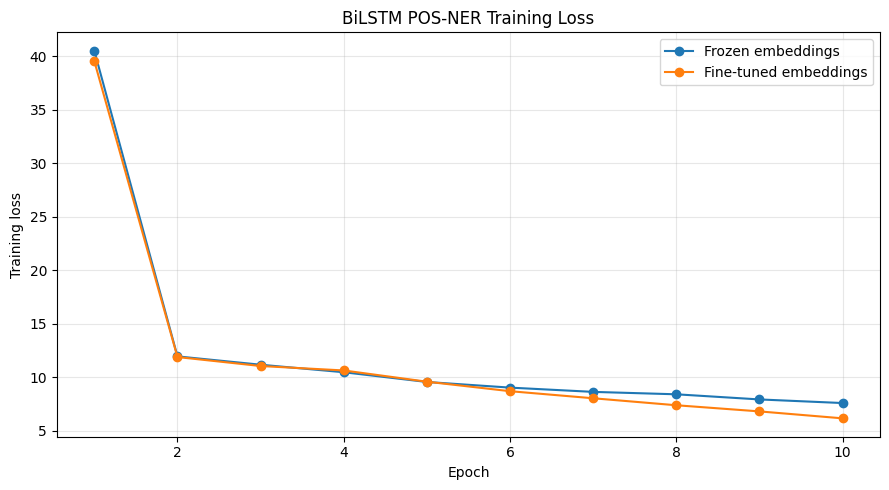


All BiLSTM results saved in:
/content/BBC_Urdu_NLP_Assignment2/part2_sequence_labelling/bilstm_results


In [55]:

# ============================================================
# PART 2: TWO-LAYER BiLSTM FOR POS + NER (WITH CRF)
# Frozen vs Fine-tuned Word2Vec embeddings
# ============================================================

import os
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence

from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix
)

# -------------------- 1. CONFIGURATION -----------------------

BASE_DIR = "/content/BBC_Urdu_NLP_Assignment2"
PART2_DIR = os.path.join(BASE_DIR, "part2_sequence_labelling")
W2V_DIR = os.path.join(
    BASE_DIR, "part1_word2vec", "C3_cleaned_d100"
)

ANNOTATION_FILE = os.path.join(
    PART2_DIR, "part2_auto_annotations_for_review.csv"
)
EMBEDDING_FILE = os.path.join(W2V_DIR, "embeddings_w2v.npy")
VOCAB_FILE = os.path.join(W2V_DIR, "vocabulary.json")

RESULT_DIR = os.path.join(PART2_DIR, "bilstm_results")
os.makedirs(RESULT_DIR, exist_ok=True)

SEED = 42
BATCH_SIZE = 32
EPOCHS = 10
LEARNING_RATE = 0.001
HIDDEN_SIZE = 128
DROPOUT = 0.5

POS_TAGS = [
    "NOUN", "PROPN", "VERB", "ADJ", "ADV", "PRON",
    "ADP", "AUX", "CONJ", "PART", "NUM", "PUNCT"
]

NER_TAGS = [
    "O", "B-PER", "I-PER", "B-LOC",
    "I-LOC", "B-ORG", "I-ORG"
]

POS_TO_ID = {tag: i for i, tag in enumerate(POS_TAGS)}
NER_TO_ID = {tag: i for i, tag in enumerate(NER_TAGS)}

PAD_ID = 0
UNK_ID = 1

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# -------------------- 2. LOAD WORD2VEC -----------------------

embeddings = np.load(EMBEDDING_FILE).astype(np.float32)

with open(VOCAB_FILE, "r", encoding="utf-8") as f:
    vocab_data = json.load(f)

# Support common vocabulary JSON formats
if isinstance(vocab_data, list):
    word_to_idx = {str(word): i for i, word in enumerate(vocab_data)}

elif isinstance(vocab_data, dict):
    word_to_idx = None

    for key in ["word_to_idx", "word2idx", "token_to_id", "stoi"]:
        if key in vocab_data and isinstance(vocab_data[key], dict):
            word_to_idx = vocab_data[key]
            break

    if word_to_idx is None and "vocab" in vocab_data:
        if isinstance(vocab_data["vocab"], list):
            word_to_idx = {
                str(word): i
                for i, word in enumerate(vocab_data["vocab"])
            }
        elif isinstance(vocab_data["vocab"], dict):
            word_to_idx = vocab_data["vocab"]

    if word_to_idx is None and all(
        isinstance(v, int) for v in vocab_data.values()
    ):
        word_to_idx = vocab_data

    if word_to_idx is None:
        raise ValueError(
            "Could not identify vocabulary mapping. "
            f"JSON keys: {list(vocab_data.keys())[:15]}"
        )
else:
    raise ValueError("Unsupported vocabulary JSON format.")

word_to_idx = {
    str(word): int(index)
    for word, index in word_to_idx.items()
}

assert len(word_to_idx) == embeddings.shape[0], (
    f"Vocabulary size {len(word_to_idx)} does not match "
    f"embedding rows {embeddings.shape[0]}"
)

assert sorted(word_to_idx.values()) == list(range(len(word_to_idx))), (
    "Vocabulary indices are not contiguous."
)

embedding_dim = embeddings.shape[1]

# Add PAD and UNK rows
embedding_matrix = np.zeros(
    (len(word_to_idx) + 2, embedding_dim),
    dtype=np.float32
)

embedding_matrix[2:] = embeddings
embedding_matrix[UNK_ID] = embeddings.mean(axis=0)

print("Word2Vec vocabulary:", len(word_to_idx))
print("Embedding dimension:", embedding_dim)

# -------------------- 3. LOAD ANNOTATIONS --------------------

df = pd.read_csv(ANNOTATION_FILE)

required_columns = [
    "sentence_id", "split", "token_index",
    "token", "pos_tag", "ner_tag"
]

missing = [c for c in required_columns if c not in df.columns]
if missing:
    raise ValueError(f"Missing annotation columns: {missing}")

df = df.dropna(subset=["token", "pos_tag", "ner_tag"]).copy()

df["pos_tag"] = df["pos_tag"].astype(str)
df["ner_tag"] = df["ner_tag"].astype(str)
df["token"] = df["token"].astype(str)

df = df[
    df["pos_tag"].isin(POS_TO_ID) &
    df["ner_tag"].isin(NER_TO_ID)
].copy()

# Convert each sentence into aligned token and label sequences
records = []

for sentence_id, group in df.groupby("sentence_id", sort=False):
    group = group.sort_values("token_index")

    records.append({
        "sentence_id": sentence_id,
        "split": group["split"].iloc[0],
        "tokens": group["token"].tolist(),
        "pos": [POS_TO_ID[x] for x in group["pos_tag"]],
        "ner": [NER_TO_ID[x] for x in group["ner_tag"]]
    })

print("Prepared sentences:", len(records))

# Show vocabulary coverage
all_tokens = [token for r in records for token in r["tokens"]]
known_tokens = sum(token in word_to_idx for token in all_tokens)

print(
    f"Word2Vec token coverage: {known_tokens}/{len(all_tokens)} "
    f"({100 * known_tokens / max(1, len(all_tokens)):.2f}%)"
)

# -------------------- 4. DATASET AND DATALOADER ----------------

class UrduSequenceDataset(Dataset):
    def __init__(self, records, split):
        self.records = [r for r in records if r["split"] == split]

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        r = self.records[index]

        ids = [
            word_to_idx.get(token, UNK_ID) + 2
            if token in word_to_idx else UNK_ID
            for token in r["tokens"]
        ]

        return (
            torch.tensor(ids, dtype=torch.long),
            torch.tensor(r["pos"], dtype=torch.long),
            torch.tensor(r["ner"], dtype=torch.long)
        )


def collate_batch(batch):
    token_ids, pos_ids, ner_ids = zip(*batch)

    lengths = torch.tensor(
        [len(x) for x in token_ids],
        dtype=torch.long
    )

    token_ids = pad_sequence(
        token_ids, batch_first=True, padding_value=PAD_ID
    )
    pos_ids = pad_sequence(
        pos_ids, batch_first=True, padding_value=0
    )
    ner_ids = pad_sequence(
        ner_ids, batch_first=True, padding_value=0
    )

    mask = (
        torch.arange(token_ids.size(1)).unsqueeze(0)
        < lengths.unsqueeze(1)
    )

    return token_ids, pos_ids, ner_ids, mask


train_ds = UrduSequenceDataset(records, "train")
val_ds = UrduSequenceDataset(records, "validation")
test_ds = UrduSequenceDataset(records, "test")

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE,
    shuffle=True, collate_fn=collate_batch
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE,
    shuffle=False, collate_fn=collate_batch
)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE,
    shuffle=False, collate_fn=collate_batch
)

print("Train sentences:", len(train_ds))
print("Validation sentences:", len(val_ds))
print("Test sentences:", len(test_ds))

# -------------------- 5. LINEAR-CHAIN CRF --------------------

class LinearCRF(nn.Module):
    def __init__(self, num_tags):
        super().__init__()
        self.num_tags = num_tags

        self.transitions = nn.Parameter(
            torch.empty(num_tags, num_tags)
        )
        self.start_transitions = nn.Parameter(
            torch.empty(num_tags)
        )
        self.end_transitions = nn.Parameter(
            torch.empty(num_tags)
        )

        nn.init.uniform_(self.transitions, -0.1, 0.1)
        nn.init.uniform_(self.start_transitions, -0.1, 0.1)
        nn.init.uniform_(self.end_transitions, -0.1, 0.1)

    def neg_log_likelihood(self, emissions, tags, mask):
        batch_size, seq_len, _ = emissions.shape

        # Gold sequence score
        first_tags = tags[:, 0]
        gold_score = (
            self.start_transitions[first_tags]
            + emissions[:, 0].gather(
                1, first_tags.unsqueeze(1)
            ).squeeze(1)
        )

        for t in range(1, seq_len):
            previous = tags[:, t - 1]
            current = tags[:, t]

            step_score = (
                self.transitions[previous, current]
                + emissions[:, t].gather(
                    1, current.unsqueeze(1)
                ).squeeze(1)
            )

            gold_score += step_score * mask[:, t].float()

        lengths = mask.long().sum(dim=1)
        last_tags = tags.gather(
            1, (lengths - 1).unsqueeze(1)
        ).squeeze(1)

        gold_score += self.end_transitions[last_tags]

        # Partition function
        alpha = self.start_transitions.unsqueeze(0) + emissions[:, 0]

        for t in range(1, seq_len):
            scores = (
                alpha.unsqueeze(2)
                + self.transitions.unsqueeze(0)
                + emissions[:, t].unsqueeze(1)
            )

            next_alpha = torch.logsumexp(scores, dim=1)

            alpha = torch.where(
                mask[:, t].unsqueeze(1),
                next_alpha,
                alpha
            )

        log_partition = torch.logsumexp(
            alpha + self.end_transitions.unsqueeze(0),
            dim=1
        )

        return (log_partition - gold_score).mean()

    @torch.no_grad()
    def decode(self, emissions, mask):
        predictions = []

        for b in range(emissions.size(0)):
            length = int(mask[b].sum().item())
            emit = emissions[b, :length]

            score = self.start_transitions + emit[0]
            history = []

            for t in range(1, length):
                candidates = (
                    score.unsqueeze(1)
                    + self.transitions
                )

                best_score, best_path = candidates.max(dim=0)
                score = best_score + emit[t]
                history.append(best_path)

            score = score + self.end_transitions
            last_tag = int(score.argmax().item())

            path = [last_tag]

            for backpointer in reversed(history):
                last_tag = int(backpointer[last_tag].item())
                path.append(last_tag)

            predictions.append(list(reversed(path)))

        return predictions


# -------------------- 6. TWO-LAYER BiLSTM --------------------

class BiLSTM_POS_NER(nn.Module):
    def __init__(self, embedding_matrix, freeze_embeddings):
        super().__init__()

        self.embedding = nn.Embedding.from_pretrained(
            torch.tensor(embedding_matrix),
            freeze=freeze_embeddings,
            padding_idx=PAD_ID
        )

        self.lstm = nn.LSTM(
            input_size=embedding_matrix.shape[1],
            hidden_size=HIDDEN_SIZE,
            num_layers=2,
            batch_first=True,
            bidirectional=True,
            dropout=DROPOUT
        )

        output_dim = HIDDEN_SIZE * 2
        self.dropout = nn.Dropout(DROPOUT)

        self.pos_classifier = nn.Linear(
            output_dim, len(POS_TAGS)
        )

        self.ner_classifier = nn.Linear(
            output_dim, len(NER_TAGS)
        )

        self.crf = LinearCRF(len(NER_TAGS))

    def forward(self, token_ids):
        x = self.embedding(token_ids)
        output, _ = self.lstm(x)
        output = self.dropout(output)

        pos_logits = self.pos_classifier(output)
        ner_emissions = self.ner_classifier(output)

        return pos_logits, ner_emissions


# -------------------- 7. METRICS ------------------------------

def extract_entities(tag_sequence):
    entities = set()
    start = None
    entity_type = None

    for i, tag in enumerate(tag_sequence + ["O"]):
        if tag.startswith("B-"):
            if start is not None:
                entities.add((entity_type, start, i - 1))
            start = i
            entity_type = tag[2:]

        elif tag.startswith("I-"):
            new_type = tag[2:]
            if start is None or entity_type != new_type:
                if start is not None:
                    entities.add((entity_type, start, i - 1))
                start = i
                entity_type = new_type

        else:
            if start is not None:
                entities.add((entity_type, start, i - 1))
                start = None
                entity_type = None

    return entities


def entity_metrics(gold_sequences, predicted_sequences):
    true_positive = 0
    predicted_total = 0
    gold_total = 0

    for gold, predicted in zip(gold_sequences, predicted_sequences):
        gold_entities = extract_entities(gold)
        pred_entities = extract_entities(predicted)

        true_positive += len(gold_entities & pred_entities)
        predicted_total += len(pred_entities)
        gold_total += len(gold_entities)

    precision = true_positive / max(1, predicted_total)
    recall = true_positive / max(1, gold_total)
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0.0
    )

    return precision, recall, f1


@torch.no_grad()
def evaluate(model, loader):
    model.eval()

    all_pos_gold, all_pos_pred = [], []
    all_ner_gold, all_ner_pred = [], []

    for token_ids, pos_ids, ner_ids, mask in loader:
        token_ids = token_ids.to(device)
        pos_ids = pos_ids.to(device)
        ner_ids = ner_ids.to(device)
        mask = mask.to(device)

        pos_logits, ner_emissions = model(token_ids)

        pos_predictions = pos_logits.argmax(dim=-1)
        ner_predictions = model.crf.decode(
            ner_emissions, mask
        )

        for i, predicted_ner in enumerate(ner_predictions):
            length = int(mask[i].sum().item())

            all_pos_gold.extend(pos_ids[i, :length].cpu().tolist())
            all_pos_pred.extend(
                pos_predictions[i, :length].cpu().tolist()
            )

            all_ner_gold.append([
                NER_TAGS[x]
                for x in ner_ids[i, :length].cpu().tolist()
            ])

            all_ner_pred.append([
                NER_TAGS[x] for x in predicted_ner
            ])

    pos_accuracy = accuracy_score(all_pos_gold, all_pos_pred)
    pos_macro_f1 = f1_score(
        all_pos_gold, all_pos_pred,
        average="macro", zero_division=0
    )

    ner_p, ner_r, ner_f1 = entity_metrics(
        all_ner_gold, all_ner_pred
    )

    return {
        "pos_accuracy": pos_accuracy,
        "pos_macro_f1": pos_macro_f1,
        "ner_precision": ner_p,
        "ner_recall": ner_r,
        "ner_f1": ner_f1,
        "pos_gold": all_pos_gold,
        "pos_pred": all_pos_pred,
        "ner_gold": all_ner_gold,
        "ner_pred": all_ner_pred
    }


# -------------------- 8. TRAINING FUNCTION -------------------

def train_variant(name, freeze_embeddings):
    print("\n" + "=" * 65)
    print("TRAINING:", name)
    print("=" * 65)

    model = BiLSTM_POS_NER(
        embedding_matrix,
        freeze_embeddings=freeze_embeddings
    ).to(device)

    optimizer = torch.optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=LEARNING_RATE
    )

    pos_loss_function = nn.CrossEntropyLoss(reduction="none")

    history = []
    best_score = -1
    checkpoint_path = os.path.join(
        RESULT_DIR, f"{name}_best.pth"
    )

    for epoch in range(1, EPOCHS + 1):
        model.train()
        total_loss = 0.0

        for token_ids, pos_ids, ner_ids, mask in train_loader:
            token_ids = token_ids.to(device)
            pos_ids = pos_ids.to(device)
            ner_ids = ner_ids.to(device)
            mask = mask.to(device)

            optimizer.zero_grad()

            pos_logits, ner_emissions = model(token_ids)

            pos_loss_all = pos_loss_function(
                pos_logits.reshape(-1, len(POS_TAGS)),
                pos_ids.reshape(-1)
            ).reshape_as(pos_ids)

            pos_loss = (
                pos_loss_all * mask.float()
            ).sum() / mask.sum().clamp(min=1)

            ner_loss = model.crf.neg_log_likelihood(
                ner_emissions, ner_ids, mask
            )

            loss = pos_loss + ner_loss
            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(), max_norm=5.0
            )

            optimizer.step()
            total_loss += loss.item()

        average_loss = total_loss / max(1, len(train_loader))
        val = evaluate(model, val_loader)

        # Joint validation score for checkpoint selection
        selection_score = (
            val["pos_macro_f1"] + val["ner_f1"]
        ) / 2

        history.append({
            "epoch": epoch,
            "train_loss": average_loss,
            "val_pos_accuracy": val["pos_accuracy"],
            "val_pos_macro_f1": val["pos_macro_f1"],
            "val_ner_precision": val["ner_precision"],
            "val_ner_recall": val["ner_recall"],
            "val_ner_f1": val["ner_f1"]
        })

        print(
            f"Epoch {epoch:02d}/{EPOCHS} | "
            f"Loss: {average_loss:.4f} | "
            f"POS F1: {val['pos_macro_f1']:.4f} | "
            f"NER F1: {val['ner_f1']:.4f}"
        )

        if selection_score > best_score:
            best_score = selection_score
            torch.save({
                "model_state_dict": model.state_dict(),
                "freeze_embeddings": freeze_embeddings,
                "pos_tags": POS_TAGS,
                "ner_tags": NER_TAGS,
                "embedding_dim": embedding_dim,
                "hidden_size": HIDDEN_SIZE
            }, checkpoint_path)

    history_df = pd.DataFrame(history)
    history_df.to_csv(
        os.path.join(RESULT_DIR, f"{name}_history.csv"),
        index=False
    )

    # Load best validation checkpoint
    checkpoint = torch.load(
        checkpoint_path, map_location=device, weights_only=False
    )
    model.load_state_dict(checkpoint["model_state_dict"])

    test = evaluate(model, test_loader)

    print("\nBEST CHECKPOINT — TEST RESULTS")
    print(f"POS Accuracy : {test['pos_accuracy']:.4f}")
    print(f"POS Macro-F1 : {test['pos_macro_f1']:.4f}")
    print(f"NER Precision: {test['ner_precision']:.4f}")
    print(f"NER Recall   : {test['ner_recall']:.4f}")
    print(f"NER Entity F1: {test['ner_f1']:.4f}")

    # Save POS confusion matrix and classification report
    cm = confusion_matrix(
        test["pos_gold"],
        test["pos_pred"],
        labels=list(range(len(POS_TAGS)))
    )

    pd.DataFrame(
        cm, index=POS_TAGS, columns=POS_TAGS
    ).to_csv(
        os.path.join(RESULT_DIR, f"{name}_pos_confusion_matrix.csv")
    )

    report = classification_report(
        test["pos_gold"],
        test["pos_pred"],
        labels=list(range(len(POS_TAGS))),
        target_names=POS_TAGS,
        zero_division=0
    )

    with open(
        os.path.join(RESULT_DIR, f"{name}_pos_classification_report.txt"),
        "w",
        encoding="utf-8"
    ) as f:
        f.write(report)

    # Save final test predictions
    prediction_rows = []
    for i, (gold, predicted) in enumerate(
        zip(test["ner_gold"], test["ner_pred"])
    ):
        for j, (g, p) in enumerate(zip(gold, predicted)):
            prediction_rows.append({
                "test_sentence_index": i,
                "token_index": j,
                "gold_ner": g,
                "predicted_ner": p
            })

    pd.DataFrame(prediction_rows).to_csv(
        os.path.join(RESULT_DIR, f"{name}_ner_test_predictions.csv"),
        index=False
    )

    return {
        "name": name,
        "test_pos_accuracy": test["pos_accuracy"],
        "test_pos_macro_f1": test["pos_macro_f1"],
        "test_ner_precision": test["ner_precision"],
        "test_ner_recall": test["ner_recall"],
        "test_ner_f1": test["ner_f1"],
        "history": history_df
    }


# -------------------- 9. TRAIN BOTH VARIANTS -----------------

frozen_result = train_variant(
    "BiLSTM_frozen",
    freeze_embeddings=True
)

finetuned_result = train_variant(
    "BiLSTM_finetuned",
    freeze_embeddings=False
)

# -------------------- 10. COMPARE AND SAVE -------------------

comparison = pd.DataFrame([
    {k: v for k, v in frozen_result.items()
     if k not in ["history"]},
    {k: v for k, v in finetuned_result.items()
     if k not in ["history"]}
])

comparison.to_csv(
    os.path.join(RESULT_DIR, "frozen_vs_finetuned_comparison.csv"),
    index=False
)

print("\nFINAL COMPARISON")
display(comparison)

# Training loss curves
plt.figure(figsize=(9, 5))

plt.plot(
    frozen_result["history"]["epoch"],
    frozen_result["history"]["train_loss"],
    marker="o",
    label="Frozen embeddings"
)

plt.plot(
    finetuned_result["history"]["epoch"],
    finetuned_result["history"]["train_loss"],
    marker="o",
    label="Fine-tuned embeddings"
)

plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("BiLSTM POS-NER Training Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(RESULT_DIR, "bilstm_training_loss_comparison.png"),
    dpi=300
)
plt.show()

print("\nAll BiLSTM results saved in:")
print(RESULT_DIR)


In [56]:

import os
import torch
import pandas as pd
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# Reuse objects from the previous training cell
diagnostic_rows = []

for variant, freeze in [
    ("BiLSTM_frozen", True),
    ("BiLSTM_finetuned", False)
]:
    print("\n" + "=" * 60)
    print(variant)
    print("=" * 60)

    model = BiLSTM_POS_NER(
        embedding_matrix,
        freeze_embeddings=freeze
    ).to(device)

    checkpoint_path = os.path.join(
        RESULT_DIR, f"{variant}_best.pth"
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    gold_pos, pred_pos = [], []
    gold_ner, pred_ner = [], []

    sample_rows = []

    with torch.no_grad():
        for token_ids, pos_ids, ner_ids, mask in test_loader:
            token_ids = token_ids.to(device)
            pos_ids = pos_ids.to(device)
            ner_ids = ner_ids.to(device)
            mask = mask.to(device)

            pos_logits, ner_emissions = model(token_ids)

            pos_predictions = pos_logits.argmax(dim=-1)
            ner_predictions = model.crf.decode(
                ner_emissions, mask
            )

            for i in range(token_ids.size(0)):
                length = int(mask[i].sum().item())

                for j in range(length):
                    g = int(pos_ids[i, j].item())
                    p = int(pos_predictions[i, j].item())

                    gold_pos.append(g)
                    pred_pos.append(p)

                    sample_rows.append({
                        "token_id": int(token_ids[i, j].item()),
                        "gold_pos": POS_TAGS[g],
                        "predicted_pos": POS_TAGS[p],
                        "correct": g == p
                    })

                gold_ner.append([
                    NER_TAGS[x]
                    for x in ner_ids[i, :length].cpu().tolist()
                ])
                pred_ner.append([
                    NER_TAGS[x] for x in ner_predictions[i]
                ])

    print("\nGold POS distribution:")
    print(pd.Series([POS_TAGS[x] for x in gold_pos]).value_counts())

    print("\nPredicted POS distribution:")
    print(pd.Series([POS_TAGS[x] for x in pred_pos]).value_counts())

    print("\nPOS classification report:")
    print(classification_report(
        gold_pos,
        pred_pos,
        labels=list(range(len(POS_TAGS))),
        target_names=POS_TAGS,
        zero_division=0
    ))

    print("\nNER gold tag distribution:")
    print(pd.Series(
        [tag for sequence in gold_ner for tag in sequence]
    ).value_counts())

    print("\nNER predicted tag distribution:")
    print(pd.Series(
        [tag for sequence in pred_ner for tag in sequence]
    ).value_counts())

    # Save detailed POS predictions for inspection
    pd.DataFrame(sample_rows).to_csv(
        os.path.join(
            RESULT_DIR, f"{variant}_pos_test_diagnostics.csv"
        ),
        index=False
    )

print("\nDiagnostics saved in:", RESULT_DIR)



BiLSTM_frozen

Gold POS distribution:
NOUN     510
ADP      427
PROPN    316
VERB     177
AUX      163
PUNCT    143
ADJ      135
PRON     113
CONJ     102
PART      79
NUM       43
ADV       23
Name: count, dtype: int64

Predicted POS distribution:
NOUN     1770
PROPN     385
ADP        74
AUX         2
Name: count, dtype: int64

POS classification report:
              precision    recall  f1-score   support

        NOUN       0.24      0.82      0.37       510
       PROPN       0.38      0.47      0.42       316
        VERB       0.00      0.00      0.00       177
         ADJ       0.00      0.00      0.00       135
         ADV       0.00      0.00      0.00        23
        PRON       0.00      0.00      0.00       113
         ADP       0.27      0.05      0.08       427
         AUX       0.00      0.00      0.00       163
        CONJ       0.00      0.00      0.00       102
        PART       0.00      0.00      0.00        79
         NUM       0.00      0.00      0.00  

Device: cuda
Embedding matrix: (11126, 100)
Train/Validation/Test: 350 75 75

POS training counts:
{'NOUN': 2422, 'PROPN': 1596, 'VERB': 754, 'ADJ': 613, 'ADV': 78, 'PRON': 420, 'ADP': 1967, 'AUX': 699, 'CONJ': 470, 'PART': 355, 'NUM': 167, 'PUNCT': 685}

NER training counts:
{'O': 9637, 'B-PER': 204, 'I-PER': 184, 'B-LOC': 93, 'I-LOC': 22, 'B-ORG': 29, 'I-ORG': 57}

POS class weights:
{'NOUN': np.float32(0.5), 'PROPN': np.float32(0.537), 'VERB': np.float32(0.781), 'ADJ': np.float32(0.867), 'ADV': np.float32(2.429), 'PRON': np.float32(1.047), 'ADP': np.float32(0.5), 'AUX': np.float32(0.811), 'CONJ': np.float32(0.99), 'PART': np.float32(1.139), 'NUM': np.float32(1.66), 'PUNCT': np.float32(0.82)}

NER class weights:
{'O': np.float32(0.25), 'B-PER': np.float32(0.621), 'I-PER': np.float32(0.654), 'B-LOC': np.float32(0.92), 'I-LOC': np.float32(1.892), 'B-ORG': np.float32(1.648), 'I-ORG': np.float32(1.175)}

CORRECTED MODEL: Corrected_BiLSTM_frozen
Epoch 01/10 | Loss: 3.2003 | POS F1: 0.0443

,name,test_pos_accuracy,test_pos_macro_f1,test_ner_precision,test_ner_recall,test_ner_f1
0,Corrected_BiLSTM_frozen,0.466607,0.309853,0.0,0.0,0.0
1,Corrected_BiLSTM_finetuned,0.506499,0.367569,0.0,0.0,0.0


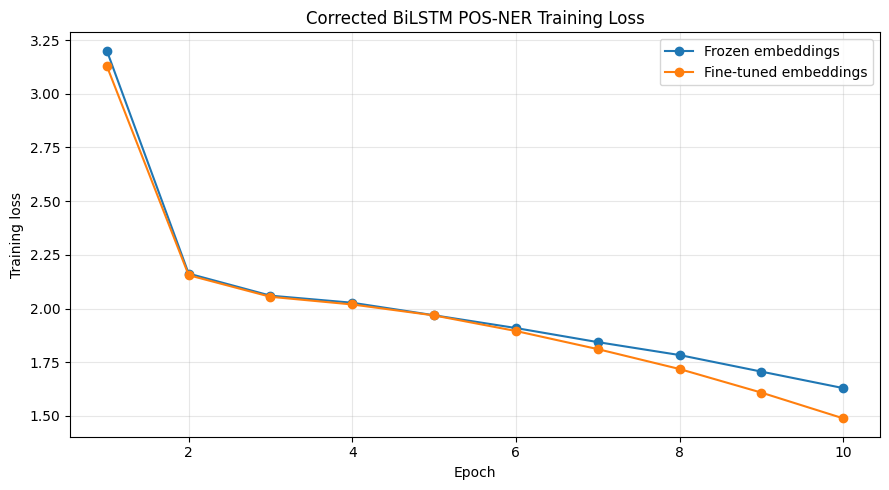


Corrected results saved in:
/content/BBC_Urdu_NLP_Assignment2/part2_sequence_labelling/bilstm_results_corrected


In [57]:

# ============================================================
# CORRECTED PART 2: BiLSTM + POS + NER CRF
# Packed sequences + balanced losses
# Original results are preserved
# ============================================================

import os
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.nn.utils.rnn import (
    pack_padded_sequence,
    pad_packed_sequence
)

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

CORRECTED_DIR = os.path.join(
    PART2_DIR, "bilstm_results_corrected"
)
os.makedirs(CORRECTED_DIR, exist_ok=True)

EPOCHS_CORRECTED = 10
LR_CORRECTED = 0.001
NER_AUX_WEIGHT = 0.5

print("Device:", device)
print("Embedding matrix:", embedding_matrix.shape)
print("Train/Validation/Test:",
      len(train_ds), len(val_ds), len(test_ds))

# ------------------------------------------------------------
# 2. CALCULATE CLASS WEIGHTS FROM TRAINING DATA ONLY
# ------------------------------------------------------------

pos_counts = np.zeros(len(POS_TAGS), dtype=np.int64)
ner_counts = np.zeros(len(NER_TAGS), dtype=np.int64)

for record in train_ds.records:
    pos_counts += np.bincount(
        record["pos"], minlength=len(POS_TAGS)
    )
    ner_counts += np.bincount(
        record["ner"], minlength=len(NER_TAGS)
    )

# Inverse-square-root weights reduce extreme weighting
pos_weights = 1.0 / np.sqrt(np.maximum(pos_counts, 1))
pos_weights = pos_weights / pos_weights.mean()
pos_weights = np.clip(pos_weights, 0.5, 4.0)

ner_weights = 1.0 / np.sqrt(np.maximum(ner_counts, 1))
ner_weights = ner_weights / ner_weights.mean()
ner_weights = np.clip(ner_weights, 0.25, 5.0)

# Padding/O class should not dominate the auxiliary NER loss
ner_weights[NER_TO_ID["O"]] = min(
    ner_weights[NER_TO_ID["O"]], 0.25
)

pos_weights = torch.tensor(
    pos_weights, dtype=torch.float32, device=device
)
ner_weights = torch.tensor(
    ner_weights, dtype=torch.float32, device=device
)

print("\nPOS training counts:")
print(dict(zip(POS_TAGS, pos_counts.tolist())))

print("\nNER training counts:")
print(dict(zip(NER_TAGS, ner_counts.tolist())))

print("\nPOS class weights:")
print(dict(zip(POS_TAGS, pos_weights.cpu().numpy().round(3))))

print("\nNER class weights:")
print(dict(zip(NER_TAGS, ner_weights.cpu().numpy().round(3))))

# ------------------------------------------------------------
# 3. CORRECTED LINEAR-CHAIN CRF
# ------------------------------------------------------------

class CorrectedCRF(nn.Module):
    def __init__(self, num_tags):
        super().__init__()
        self.num_tags = num_tags

        self.transitions = nn.Parameter(
            torch.empty(num_tags, num_tags)
        )
        self.start_transitions = nn.Parameter(
            torch.empty(num_tags)
        )
        self.end_transitions = nn.Parameter(
            torch.empty(num_tags)
        )

        nn.init.uniform_(self.transitions, -0.1, 0.1)
        nn.init.uniform_(self.start_transitions, -0.1, 0.1)
        nn.init.uniform_(self.end_transitions, -0.1, 0.1)

    def neg_log_likelihood(self, emissions, tags, mask):
        batch_size, seq_len, _ = emissions.shape

        # Gold sequence score
        first_tags = tags[:, 0]

        gold_score = (
            self.start_transitions[first_tags]
            + emissions[:, 0].gather(
                1, first_tags.unsqueeze(1)
            ).squeeze(1)
        )

        for t in range(1, seq_len):
            previous = tags[:, t - 1]
            current = tags[:, t]

            step = (
                self.transitions[previous, current]
                + emissions[:, t].gather(
                    1, current.unsqueeze(1)
                ).squeeze(1)
            )

            gold_score += step * mask[:, t].float()

        lengths = mask.long().sum(dim=1)

        last_tags = tags.gather(
            1, (lengths - 1).unsqueeze(1)
        ).squeeze(1)

        gold_score += self.end_transitions[last_tags]

        # Partition function
        alpha = (
            self.start_transitions.unsqueeze(0)
            + emissions[:, 0]
        )

        for t in range(1, seq_len):
            scores = (
                alpha.unsqueeze(2)
                + self.transitions.unsqueeze(0)
                + emissions[:, t].unsqueeze(1)
            )

            next_alpha = torch.logsumexp(scores, dim=1)

            alpha = torch.where(
                mask[:, t].unsqueeze(1),
                next_alpha,
                alpha
            )

        log_partition = torch.logsumexp(
            alpha + self.end_transitions.unsqueeze(0),
            dim=1
        )

        # Normalize each sequence loss by its actual length
        sequence_loss = (
            log_partition - gold_score
        ) / lengths.float().clamp(min=1)

        return sequence_loss.mean()

    @torch.no_grad()
    def decode(self, emissions, mask):
        predictions = []

        for b in range(emissions.size(0)):
            length = int(mask[b].sum().item())
            emit = emissions[b, :length]

            score = self.start_transitions + emit[0]
            history = []

            for t in range(1, length):
                candidates = (
                    score.unsqueeze(1) + self.transitions
                )

                best_score, best_path = candidates.max(dim=0)
                score = best_score + emit[t]
                history.append(best_path)

            score += self.end_transitions
            last_tag = int(score.argmax().item())

            path = [last_tag]

            for backpointer in reversed(history):
                last_tag = int(backpointer[last_tag].item())
                path.append(last_tag)

            predictions.append(list(reversed(path)))

        return predictions

# ------------------------------------------------------------
# 4. CORRECTED TWO-LAYER BiLSTM
# ------------------------------------------------------------

class CorrectedBiLSTM(nn.Module):
    def __init__(self, embedding_matrix, freeze_embeddings):
        super().__init__()

        self.embedding = nn.Embedding.from_pretrained(
            torch.tensor(embedding_matrix, dtype=torch.float32),
            freeze=freeze_embeddings,
            padding_idx=PAD_ID
        )

        self.lstm = nn.LSTM(
            input_size=embedding_matrix.shape[1],
            hidden_size=HIDDEN_SIZE,
            num_layers=2,
            batch_first=True,
            bidirectional=True,
            dropout=DROPOUT
        )

        self.dropout = nn.Dropout(DROPOUT)

        output_dim = HIDDEN_SIZE * 2

        self.pos_classifier = nn.Linear(
            output_dim, len(POS_TAGS)
        )

        self.ner_classifier = nn.Linear(
            output_dim, len(NER_TAGS)
        )

        self.crf = CorrectedCRF(len(NER_TAGS))

    def forward(self, token_ids, lengths):
        embedded = self.embedding(token_ids)

        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        packed_output, _ = self.lstm(packed)

        output, _ = pad_packed_sequence(
            packed_output,
            batch_first=True,
            total_length=token_ids.size(1)
        )

        output = self.dropout(output)

        pos_logits = self.pos_classifier(output)
        ner_emissions = self.ner_classifier(output)

        return pos_logits, ner_emissions

# ------------------------------------------------------------
# 5. EVALUATION
# Uses existing entity_metrics() and tag lists
# ------------------------------------------------------------

@torch.no_grad()
def corrected_evaluate(model, loader):
    model.eval()

    all_pos_gold, all_pos_pred = [], []
    all_ner_gold, all_ner_pred = [], []

    for token_ids, pos_ids, ner_ids, mask in loader:
        lengths = mask.long().sum(dim=1)

        token_ids = token_ids.to(device)
        pos_ids = pos_ids.to(device)
        ner_ids = ner_ids.to(device)
        mask = mask.to(device)

        pos_logits, ner_emissions = model(
            token_ids, lengths
        )

        pos_predictions = pos_logits.argmax(dim=-1)
        ner_predictions = model.crf.decode(
            ner_emissions, mask
        )

        for i, predicted_ner in enumerate(ner_predictions):
            length = int(lengths[i].item())

            all_pos_gold.extend(
                pos_ids[i, :length].cpu().tolist()
            )
            all_pos_pred.extend(
                pos_predictions[i, :length].cpu().tolist()
            )

            all_ner_gold.append([
                NER_TAGS[x]
                for x in ner_ids[i, :length].cpu().tolist()
            ])

            all_ner_pred.append([
                NER_TAGS[x] for x in predicted_ner
            ])

    pos_accuracy = accuracy_score(
        all_pos_gold, all_pos_pred
    )

    pos_macro_f1 = f1_score(
        all_pos_gold,
        all_pos_pred,
        average="macro",
        zero_division=0
    )

    ner_p, ner_r, ner_f1 = entity_metrics(
        all_ner_gold, all_ner_pred
    )

    return {
        "pos_accuracy": pos_accuracy,
        "pos_macro_f1": pos_macro_f1,
        "ner_precision": ner_p,
        "ner_recall": ner_r,
        "ner_f1": ner_f1,
        "pos_gold": all_pos_gold,
        "pos_pred": all_pos_pred,
        "ner_gold": all_ner_gold,
        "ner_pred": all_ner_pred
    }

# ------------------------------------------------------------
# 6. TRAINING FUNCTION
# ------------------------------------------------------------

def train_corrected_variant(name, freeze_embeddings):
    print("\n" + "=" * 65)
    print("CORRECTED MODEL:", name)
    print("=" * 65)

    model = CorrectedBiLSTM(
        embedding_matrix,
        freeze_embeddings
    ).to(device)

    optimizer = torch.optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=LR_CORRECTED
    )

    best_score = -1
    history = []

    checkpoint_path = os.path.join(
        CORRECTED_DIR, f"{name}_best.pth"
    )

    for epoch in range(1, EPOCHS_CORRECTED + 1):
        model.train()
        total_loss = 0.0

        for token_ids, pos_ids, ner_ids, mask in train_loader:
            lengths = mask.long().sum(dim=1)

            token_ids = token_ids.to(device)
            pos_ids = pos_ids.to(device)
            ner_ids = ner_ids.to(device)
            mask = mask.to(device)

            optimizer.zero_grad()

            pos_logits, ner_emissions = model(
                token_ids, lengths
            )

            # Weighted POS cross-entropy
            pos_raw = F.cross_entropy(
                pos_logits.reshape(-1, len(POS_TAGS)),
                pos_ids.reshape(-1),
                weight=pos_weights,
                reduction="none"
            ).reshape_as(pos_ids)

            pos_loss = (
                pos_raw * mask.float()
            ).sum() / mask.sum().clamp(min=1)

            # Length-normalized CRF loss
            crf_loss = model.crf.neg_log_likelihood(
                ner_emissions, ner_ids, mask
            )

            # Auxiliary weighted NER loss
            ner_raw = F.cross_entropy(
                ner_emissions.reshape(-1, len(NER_TAGS)),
                ner_ids.reshape(-1),
                weight=ner_weights,
                reduction="none"
            ).reshape_as(ner_ids)

            ner_aux_loss = (
                ner_raw * mask.float()
            ).sum() / mask.sum().clamp(min=1)

            loss = (
                pos_loss
                + crf_loss
                + NER_AUX_WEIGHT * ner_aux_loss
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(), max_norm=5.0
            )

            optimizer.step()
            total_loss += loss.item()

        average_loss = total_loss / max(1, len(train_loader))

        val = corrected_evaluate(model, val_loader)

        score = (
            val["pos_macro_f1"] + val["ner_f1"]
        ) / 2

        history.append({
            "epoch": epoch,
            "train_loss": average_loss,
            "val_pos_accuracy": val["pos_accuracy"],
            "val_pos_macro_f1": val["pos_macro_f1"],
            "val_ner_precision": val["ner_precision"],
            "val_ner_recall": val["ner_recall"],
            "val_ner_f1": val["ner_f1"]
        })

        print(
            f"Epoch {epoch:02d}/{EPOCHS_CORRECTED} | "
            f"Loss: {average_loss:.4f} | "
            f"POS F1: {val['pos_macro_f1']:.4f} | "
            f"NER F1: {val['ner_f1']:.4f}"
        )

        if score > best_score:
            best_score = score

            torch.save({
                "model_state_dict": model.state_dict(),
                "freeze_embeddings": freeze_embeddings,
                "pos_tags": POS_TAGS,
                "ner_tags": NER_TAGS
            }, checkpoint_path)

    history_df = pd.DataFrame(history)
    history_df.to_csv(
        os.path.join(CORRECTED_DIR, f"{name}_history.csv"),
        index=False
    )

    # Load best validation checkpoint
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )
    model.load_state_dict(checkpoint["model_state_dict"])

    test = corrected_evaluate(model, test_loader)

    print("\nBEST CHECKPOINT — TEST RESULTS")
    print(f"POS Accuracy : {test['pos_accuracy']:.4f}")
    print(f"POS Macro-F1 : {test['pos_macro_f1']:.4f}")
    print(f"NER Precision: {test['ner_precision']:.4f}")
    print(f"NER Recall   : {test['ner_recall']:.4f}")
    print(f"NER Entity F1: {test['ner_f1']:.4f}")

    # Save POS confusion matrix and report
    cm = confusion_matrix(
        test["pos_gold"],
        test["pos_pred"],
        labels=list(range(len(POS_TAGS)))
    )

    pd.DataFrame(
        cm, index=POS_TAGS, columns=POS_TAGS
    ).to_csv(
        os.path.join(CORRECTED_DIR, f"{name}_pos_confusion_matrix.csv")
    )

    report = classification_report(
        test["pos_gold"],
        test["pos_pred"],
        labels=list(range(len(POS_TAGS))),
        target_names=POS_TAGS,
        zero_division=0
    )

    with open(
        os.path.join(CORRECTED_DIR, f"{name}_pos_report.txt"),
        "w",
        encoding="utf-8"
    ) as f:
        f.write(report)

    # Save NER predictions
    prediction_rows = []

    for i, (gold, predicted) in enumerate(
        zip(test["ner_gold"], test["ner_pred"])
    ):
        for j, (g, p) in enumerate(zip(gold, predicted)):
            prediction_rows.append({
                "test_sentence_index": i,
                "token_index": j,
                "gold_ner": g,
                "predicted_ner": p
            })

    pd.DataFrame(prediction_rows).to_csv(
        os.path.join(CORRECTED_DIR, f"{name}_ner_predictions.csv"),
        index=False
    )

    return {
        "name": name,
        "test_pos_accuracy": test["pos_accuracy"],
        "test_pos_macro_f1": test["pos_macro_f1"],
        "test_ner_precision": test["ner_precision"],
        "test_ner_recall": test["ner_recall"],
        "test_ner_f1": test["ner_f1"],
        "history": history_df
    }

# ------------------------------------------------------------
# 7. TRAIN FROZEN AND FINE-TUNED VARIANTS
# ------------------------------------------------------------

corrected_frozen = train_corrected_variant(
    "Corrected_BiLSTM_frozen",
    freeze_embeddings=True
)

corrected_finetuned = train_corrected_variant(
    "Corrected_BiLSTM_finetuned",
    freeze_embeddings=False
)

# ------------------------------------------------------------
# 8. COMPARISON
# ------------------------------------------------------------

comparison_corrected = pd.DataFrame([
    {k: v for k, v in corrected_frozen.items()
     if k != "history"},
    {k: v for k, v in corrected_finetuned.items()
     if k != "history"}
])

comparison_corrected.to_csv(
    os.path.join(
        CORRECTED_DIR, "corrected_frozen_vs_finetuned.csv"
    ),
    index=False
)

print("\nFINAL CORRECTED MODEL COMPARISON")
display(comparison_corrected)

# Loss curves
plt.figure(figsize=(9, 5))

plt.plot(
    corrected_frozen["history"]["epoch"],
    corrected_frozen["history"]["train_loss"],
    marker="o",
    label="Frozen embeddings"
)

plt.plot(
    corrected_finetuned["history"]["epoch"],
    corrected_finetuned["history"]["train_loss"],
    marker="o",
    label="Fine-tuned embeddings"
)

plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("Corrected BiLSTM POS-NER Training Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        CORRECTED_DIR,
        "corrected_bilstm_training_loss.png"
    ),
    dpi=300
)
plt.show()

print("\nCorrected results saved in:")
print(CORRECTED_DIR)


In [58]:
import os
import pandas as pd

RESULT_DIR = (
    "/content/BBC_Urdu_NLP_Assignment2/"
    "part2_sequence_labelling/bilstm_results_corrected"
)

print("=" * 65)
print("EXISTING CORRECTED MODEL OUTPUTS")
print("=" * 65)

for root, dirs, files in os.walk(RESULT_DIR):
    for file in files:
        path = os.path.join(root, file)
        size_mb = os.path.getsize(path) / (1024 * 1024)

        print(f"{file:50s} {size_mb:.2f} MB")

        if file.endswith(".csv"):
            try:
                df = pd.read_csv(path)
                print("   Columns:", df.columns.tolist())
                print("   Rows:", len(df))
            except Exception as e:
                print("   Could not read:", e)

EXISTING CORRECTED MODEL OUTPUTS
Corrected_BiLSTM_frozen_ner_predictions.csv        0.02 MB
   Columns: ['test_sentence_index', 'token_index', 'gold_ner', 'predicted_ner']
   Rows: 2231
Corrected_BiLSTM_finetuned_pos_report.txt          0.00 MB
Corrected_BiLSTM_frozen_pos_confusion_matrix.csv   0.00 MB
   Columns: ['Unnamed: 0', 'NOUN', 'PROPN', 'VERB', 'ADJ', 'ADV', 'PRON', 'ADP', 'AUX', 'CONJ', 'PART', 'NUM', 'PUNCT']
   Rows: 12
Corrected_BiLSTM_finetuned_pos_confusion_matrix.csv 0.00 MB
   Columns: ['Unnamed: 0', 'NOUN', 'PROPN', 'VERB', 'ADJ', 'ADV', 'PRON', 'ADP', 'AUX', 'CONJ', 'PART', 'NUM', 'PUNCT']
   Rows: 12
corrected_frozen_vs_finetuned.csv                  0.00 MB
   Columns: ['name', 'test_pos_accuracy', 'test_pos_macro_f1', 'test_ner_precision', 'test_ner_recall', 'test_ner_f1']
   Rows: 2
Corrected_BiLSTM_finetuned_history.csv             0.00 MB
   Columns: ['epoch', 'train_loss', 'val_pos_accuracy', 'val_pos_macro_f1', 'val_ner_precision', 'val_ner_recall', 'val_ner_

In [59]:

import os
import pandas as pd
from collections import Counter

RESULT_DIR = (
    "/content/BBC_Urdu_NLP_Assignment2/"
    "part2_sequence_labelling/bilstm_results_corrected"
)

FILES = {
    "Frozen": "Corrected_BiLSTM_frozen_ner_predictions.csv",
    "Fine-tuned": "Corrected_BiLSTM_finetuned_ner_predictions.csv"
}

def extract_entities(df, label_column):
    """Extract BIO entity spans separately for each sentence."""
    entities = set()

    for sentence_id, group in df.groupby("test_sentence_index"):
        group = group.sort_values("token_index")
        labels = group[label_column].astype(str).tolist()

        entity_type = None
        start = None

        for i, label in enumerate(labels):
            if label.startswith("B-"):
                if entity_type is not None:
                    entities.add((sentence_id, start, i - 1, entity_type))

                entity_type = label[2:]
                start = i

            elif label.startswith("I-"):
                current_type = label[2:]

                if entity_type != current_type:
                    if entity_type is not None:
                        entities.add(
                            (sentence_id, start, i - 1, entity_type)
                        )

                    entity_type = current_type
                    start = i

            else:
                if entity_type is not None:
                    entities.add((sentence_id, start, i - 1, entity_type))

                entity_type = None
                start = None

        if entity_type is not None:
            entities.add(
                (sentence_id, start, len(labels) - 1, entity_type)
            )

    return entities


for mode, filename in FILES.items():

    path = os.path.join(RESULT_DIR, filename)
    df = pd.read_csv(path)

    print("\n" + "=" * 65)
    print(f"NER DIAGNOSTIC: {mode}")
    print("=" * 65)

    # 1. Label distributions
    print("\nGOLD LABEL DISTRIBUTION:")
    print(df["gold_ner"].value_counts().to_string())

    print("\nPREDICTED LABEL DISTRIBUTION:")
    print(df["predicted_ner"].value_counts().to_string())

    # 2. Entity-level counts
    gold_entities = extract_entities(df, "gold_ner")
    predicted_entities = extract_entities(df, "predicted_ner")

    correct_entities = gold_entities.intersection(predicted_entities)

    print("\nENTITY COUNTS:")
    print("Gold entities:", len(gold_entities))
    print("Predicted entities:", len(predicted_entities))
    print("Correct exact matches:", len(correct_entities))

    precision = (
        len(correct_entities) / len(predicted_entities)
        if predicted_entities else 0
    )
    recall = (
        len(correct_entities) / len(gold_entities)
        if gold_entities else 0
    )
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    print(f"Exact entity precision: {precision:.4f}")
    print(f"Exact entity recall:    {recall:.4f}")
    print(f"Exact entity F1:         {f1:.4f}")

    # 3. Per-entity-type gold and prediction counts
    print("\nPER-TYPE ENTITY COUNTS:")

    for entity_type in ["PER", "LOC", "ORG", "MISC"]:
        gold_count = sum(e[3] == entity_type for e in gold_entities)
        pred_count = sum(e[3] == entity_type for e in predicted_entities)
        correct_count = sum(
            e[3] == entity_type for e in correct_entities
        )

        print(
            f"{entity_type:5s} | Gold: {gold_count:4d} | "
            f"Predicted: {pred_count:4d} | Correct: {correct_count:4d}"
        )

    # 4. Show sample mismatches
    print("\nFIRST 20 TOKEN-LEVEL MISMATCHES:")

    mismatches = df[
        df["gold_ner"].astype(str) !=
        df["predicted_ner"].astype(str)
    ]

    print(mismatches.head(20).to_string(index=False))

    # 5. BIO label validity check
    invalid_i = 0

    for _, group in df.groupby("test_sentence_index"):
        labels = group.sort_values("token_index")[
            "predicted_ner"
        ].astype(str).tolist()

        previous_type = None

        for label in labels:
            if label.startswith("B-"):
                previous_type = label[2:]

            elif label.startswith("I-"):
                current_type = label[2:]

                if previous_type != current_type:
                    invalid_i += 1

                previous_type = current_type

            else:
                previous_type = None

    print("\nInvalid I-tag transitions:", invalid_i)



NER DIAGNOSTIC: Frozen

GOLD LABEL DISTRIBUTION:
gold_ner
O        2123
B-LOC      40
B-PER      24
I-PER      21
I-LOC      16
I-ORG       4
B-ORG       3

PREDICTED LABEL DISTRIBUTION:
predicted_ner
O    2231

ENTITY COUNTS:
Gold entities: 67
Predicted entities: 0
Correct exact matches: 0
Exact entity precision: 0.0000
Exact entity recall:    0.0000
Exact entity F1:         0.0000

PER-TYPE ENTITY COUNTS:
PER   | Gold:   24 | Predicted:    0 | Correct:    0
LOC   | Gold:   40 | Predicted:    0 | Correct:    0
ORG   | Gold:    3 | Predicted:    0 | Correct:    0
MISC  | Gold:    0 | Predicted:    0 | Correct:    0

FIRST 20 TOKEN-LEVEL MISMATCHES:
 test_sentence_index  token_index gold_ner predicted_ner
                   0            1    B-PER             O
                   0            2    I-PER             O
                   0            3    I-PER             O
                   0           21    B-PER             O
                   0           22    I-PER             O


In [60]:

import torch
import inspect
import os

print("=" * 70)
print("NER MODEL AND CRF IMPLEMENTATION INSPECTION")
print("=" * 70)

# 1. Find existing PyTorch models in the notebook runtime
model_objects = {}

for name, obj in list(globals().items()):
    try:
        if isinstance(obj, torch.nn.Module):
            model_objects[name] = obj
    except Exception:
        pass

print("\n1. AVAILABLE MODEL OBJECTS")

for name, model in model_objects.items():
    print(f"\nModel variable: {name}")
    print("Class:", type(model).__name__)

    for layer_name, layer in model.named_modules():
        if layer_name:
            print(f"  {layer_name}: {type(layer).__name__}")

# 2. Find CRF-related classes and functions
print("\n" + "=" * 70)
print("2. CRF IMPLEMENTATION")
print("=" * 70)

for name, obj in list(globals().items()):
    if inspect.isclass(obj) and (
        "crf" in name.lower()
        or "viterbi" in name.lower()
    ):
        print(f"\nCLASS: {name}")
        try:
            print(inspect.getsource(obj))
        except Exception as e:
            print("Source unavailable:", e)

    elif inspect.isfunction(obj) and (
        "decode" in name.lower()
        or "viterbi" in name.lower()
    ):
        print(f"\nFUNCTION: {name}")
        try:
            print(inspect.getsource(obj))
        except Exception as e:
            print("Source unavailable:", e)

# 3. Inspect saved checkpoint structure
print("\n" + "=" * 70)
print("3. SAVED CHECKPOINT STRUCTURE")
print("=" * 70)

checkpoint_dir = (
    "/content/BBC_Urdu_NLP_Assignment2/"
    "part2_sequence_labelling/bilstm_results_corrected"
)

for filename in [
    "Corrected_BiLSTM_frozen_best.pth",
    "Corrected_BiLSTM_finetuned_best.pth"
]:
    path = os.path.join(checkpoint_dir, filename)

    print(f"\nCheckpoint: {filename}")

    if not os.path.exists(path):
        print("NOT FOUND")
        continue

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    print("Checkpoint type:", type(checkpoint).__name__)

    if isinstance(checkpoint, dict):
        print("Top-level keys:", list(checkpoint.keys()))

        state = checkpoint.get(
            "model_state_dict",
            checkpoint.get("state_dict", checkpoint)
        )

        if isinstance(state, dict):
            print("\nModel parameter names and shapes:")

            for key, value in state.items():
                if torch.is_tensor(value):
                    print(f"{key:55s} {tuple(value.shape)}")

print("\n" + "=" * 70)
print("INSPECTION COMPLETED — NO TRAINING PERFORMED")
print("=" * 70)


NER MODEL AND CRF IMPLEMENTATION INSPECTION

1. AVAILABLE MODEL OBJECTS

Model variable: model
Class: BiLSTM_POS_NER
  embedding: Embedding
  lstm: LSTM
  dropout: Dropout
  pos_classifier: Linear
  ner_classifier: Linear
  crf: LinearCRF

2. CRF IMPLEMENTATION

CLASS: LinearCRF
Source unavailable: source code not available

CLASS: CorrectedCRF
Source unavailable: source code not available

3. SAVED CHECKPOINT STRUCTURE

Checkpoint: Corrected_BiLSTM_frozen_best.pth
Checkpoint type: dict
Top-level keys: ['model_state_dict', 'freeze_embeddings', 'pos_tags', 'ner_tags']

Model parameter names and shapes:
embedding.weight                                        (11126, 100)
lstm.weight_ih_l0                                       (512, 100)
lstm.weight_hh_l0                                       (512, 128)
lstm.bias_ih_l0                                         (512,)
lstm.bias_hh_l0                                         (512,)
lstm.weight_ih_l0_reverse                               (512, 

In [61]:

import torch
import copy
import inspect
import os

print("=" * 70)
print("RAW NER EMISSION vs CRF DECODING DIAGNOSTIC")
print("=" * 70)

# ------------------------------------------------
# 1. Inspect CRF methods
# ------------------------------------------------
print("\n1. CRF METHODS")

crf = model.crf

for method_name in ["forward", "decode", "_compute_score", "_compute_normalizer"]:
    method = getattr(type(crf), method_name, None)

    if method is not None:
        try:
            print(f"\n{method_name}{inspect.signature(method)}")
        except Exception:
            pass

print("\nCRF transition matrix:")
print(crf.transitions.detach().cpu())

print("\nCRF start transitions:")
print(crf.start_transitions.detach().cpu())

print("\nCRF end transitions:")
print(crf.end_transitions.detach().cpu())

# ------------------------------------------------
# 2. Inspect one test batch
# ------------------------------------------------
print("\n" + "=" * 70)
print("2. TEST BATCH STRUCTURE")
print("=" * 70)

batch = next(iter(test_loader))

if isinstance(batch, dict):
    print("Batch keys:", list(batch.keys()))
    for key, value in batch.items():
        if torch.is_tensor(value):
            print(key, value.shape, value.dtype)
        else:
            print(key, type(value))
elif isinstance(batch, (tuple, list)):
    print("Number of batch elements:", len(batch))
    for i, value in enumerate(batch):
        if torch.is_tensor(value):
            print(f"Element {i}: shape={tuple(value.shape)}, dtype={value.dtype}")
        else:
            print(f"Element {i}: type={type(value)}")
else:
    print("Batch type:", type(batch))

# ------------------------------------------------
# 3. Inspect model forward output
# ------------------------------------------------
print("\n" + "=" * 70)
print("3. MODEL FORWARD OUTPUT")
print("=" * 70)

model.eval()

with torch.no_grad():
    try:
        if isinstance(batch, dict):
            output = model(
                batch["input_ids"].to(device),
                batch["mask"].to(device)
            )
        else:
            # Standard dataset batch: input_ids, pos_labels, ner_labels, lengths
            output = model(
                batch[0].to(device)
            )

        print("Output type:", type(output))

        if isinstance(output, dict):
            for key, value in output.items():
                if torch.is_tensor(value):
                    print(key, tuple(value.shape), value.dtype)
                else:
                    print(key, type(value))

        elif isinstance(output, (tuple, list)):
            for i, value in enumerate(output):
                if torch.is_tensor(value):
                    print(f"Output {i}: {tuple(value.shape)}")
                else:
                    print(f"Output {i}: {type(value)}")

        elif torch.is_tensor(output):
            print("Output shape:", tuple(output.shape))

    except Exception as e:
        print("Forward inspection error:", repr(e))

# ------------------------------------------------
# 4. Inspect model forward signature
# ------------------------------------------------
print("\n" + "=" * 70)
print("4. MODEL FORWARD SIGNATURE")
print("=" * 70)

try:
    print(inspect.signature(model.forward))
except Exception as e:
    print("Signature unavailable:", e)

# ------------------------------------------------
# 5. Check checkpoint tag ordering
# ------------------------------------------------
print("\n" + "=" * 70)
print("5. CHECKPOINT TAG ORDER")
print("=" * 70)

RESULT_DIR = (
    "/content/BBC_Urdu_NLP_Assignment2/"
    "part2_sequence_labelling/bilstm_results_corrected"
)

for filename in [
    "Corrected_BiLSTM_frozen_best.pth",
    "Corrected_BiLSTM_finetuned_best.pth"
]:
    checkpoint = torch.load(
        os.path.join(RESULT_DIR, filename),
        map_location="cpu",
        weights_only=False
    )

    print("\n", filename)
    print("Frozen embeddings:", checkpoint["freeze_embeddings"])
    print("POS tags:", checkpoint["pos_tags"])
    print("NER tags:", checkpoint["ner_tags"])

print("\nDIAGNOSTIC INSPECTION FINISHED")


RAW NER EMISSION vs CRF DECODING DIAGNOSTIC

1. CRF METHODS

forward(self, *input: Any) -> None

decode(self, emissions, mask)

CRF transition matrix:
tensor([[ 0.1143,  0.0641, -0.1180,  0.0854, -0.0658,  0.0170, -0.1274],
        [-0.0679, -0.1733,  0.0410,  0.0146, -0.0390, -0.0058,  0.0055],
        [ 0.0112, -0.0996,  0.0544, -0.0233, -0.0398,  0.0015,  0.0122],
        [-0.0572, -0.1448, -0.0488,  0.0236,  0.1490, -0.0483, -0.0201],
        [-0.1059, -0.0965,  0.0253,  0.0671,  0.0851, -0.0925, -0.0318],
        [-0.0942, -0.1208, -0.0680, -0.0262,  0.0634, -0.0484,  0.1023],
        [ 0.0045, -0.0874,  0.0343, -0.0194,  0.0670,  0.0297,  0.0374]])

CRF start transitions:
tensor([ 0.1042, -0.0266, -0.1933,  0.0294, -0.0437,  0.0726, -0.1730])

CRF end transitions:
tensor([ 0.0904, -0.0650, -0.0845, -0.0950, -0.0381, -0.0960, -0.0364])

2. TEST BATCH STRUCTURE
Number of batch elements: 4
Element 0: shape=(32, 57), dtype=torch.int64
Element 1: shape=(32, 57), dtype=torch.int64
Elem

In [62]:

import os
import torch
from collections import Counter

RESULT_DIR = (
    "/content/BBC_Urdu_NLP_Assignment2/"
    "part2_sequence_labelling/bilstm_results_corrected"
)

CHECKPOINTS = {
    "Frozen": "Corrected_BiLSTM_frozen_best.pth",
    "Fine-tuned": "Corrected_BiLSTM_finetuned_best.pth"
}

NER_TAGS = [
    "O", "B-PER", "I-PER",
    "B-LOC", "I-LOC", "B-ORG", "I-ORG"
]

def normalize_decoded(decoded, mask):
    """Convert CRF output into a padded prediction tensor."""
    if torch.is_tensor(decoded):
        return decoded.to(device)

    result = torch.zeros(
        mask.shape, dtype=torch.long, device=device
    )

    for i, sequence in enumerate(decoded):
        if torch.is_tensor(sequence):
            sequence = sequence.tolist()

        result[i, :len(sequence)] = torch.tensor(
            sequence, dtype=torch.long, device=device
        )

    return result


for mode, filename in CHECKPOINTS.items():

    print("\n" + "=" * 70)
    print(f"CHECKPOINT: {mode}")
    print("=" * 70)

    checkpoint = torch.load(
        os.path.join(RESULT_DIR, filename),
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    raw_counts = Counter()
    crf_counts = Counter()
    gold_counts = Counter()

    total_tokens = 0
    raw_correct = 0
    crf_correct = 0

    # Mean emission scores for each gold class
    class_emissions = {tag: [] for tag in NER_TAGS}

    with torch.no_grad():

        for batch in test_loader:

            token_ids = batch[0].to(device)
            gold_ner = batch[2].to(device)
            mask = batch[3].to(device).bool()

            pos_logits, ner_emissions = model(token_ids)

            # Raw independent token-level predictions
            raw_predictions = ner_emissions.argmax(dim=-1)

            # Actual CRF Viterbi predictions
            decoded = model.crf.decode(
                ner_emissions, mask
            )

            crf_predictions = normalize_decoded(
                decoded, mask
            )

            for i in range(token_ids.size(0)):

                valid_length = int(mask[i].sum().item())

                gold = gold_ner[i, :valid_length]
                raw = raw_predictions[i, :valid_length]
                crf = crf_predictions[i, :valid_length]
                emissions = ner_emissions[i, :valid_length]

                for tag_id, tag in enumerate(NER_TAGS):
                    selected = gold == tag_id

                    if selected.any():
                        class_emissions[tag].extend(
                            emissions[selected].mean(dim=0).cpu().tolist()
                        )

                raw_counts.update(raw.cpu().tolist())
                crf_counts.update(crf.cpu().tolist())
                gold_counts.update(gold.cpu().tolist())

                total_tokens += valid_length
                raw_correct += (raw == gold).sum().item()
                crf_correct += (crf == gold).sum().item()

    print("\nGOLD LABEL DISTRIBUTION:")
    for i, tag in enumerate(NER_TAGS):
        print(f"{tag:8s}: {gold_counts[i]}")

    print("\nRAW ARGMAX PREDICTIONS:")
    for i, tag in enumerate(NER_TAGS):
        print(f"{tag:8s}: {raw_counts[i]}")

    print("\nCRF VITERBI PREDICTIONS:")
    for i, tag in enumerate(NER_TAGS):
        print(f"{tag:8s}: {crf_counts[i]}")

    print("\nTOKEN-LEVEL ACCURACY:")
    print(f"Raw argmax: {raw_correct / total_tokens:.4f}")
    print(f"CRF decode: {crf_correct / total_tokens:.4f}")

    print("\nAVERAGE EMISSION SCORES BY GOLD CLASS:")
    for tag in NER_TAGS:
        values = class_emissions[tag]

        if values:
            mean_scores = torch.tensor(values).mean(dim=0)

            ranking = torch.argsort(
                mean_scores, descending=True
            ).tolist()

            print(
                f"{tag:8s}: "
                f"highest score = {NER_TAGS[ranking[0]]}, "
                f"mean = {mean_scores.tolist()}"
            )

print("\n" + "=" * 70)
print("COMPARISON COMPLETED — NO TRAINING")
print("=" * 70)



CHECKPOINT: Frozen

GOLD LABEL DISTRIBUTION:
O       : 2123
B-PER   : 24
I-PER   : 21
B-LOC   : 40
I-LOC   : 16
B-ORG   : 3
I-ORG   : 4

RAW ARGMAX PREDICTIONS:
O       : 2231
B-PER   : 0
I-PER   : 0
B-LOC   : 0
I-LOC   : 0
B-ORG   : 0
I-ORG   : 0

CRF VITERBI PREDICTIONS:
O       : 2231
B-PER   : 0
I-PER   : 0
B-LOC   : 0
I-LOC   : 0
B-ORG   : 0
I-ORG   : 0

TOKEN-LEVEL ACCURACY:
Raw argmax: 0.9516
CRF decode: 0.9516

AVERAGE EMISSION SCORES BY GOLD CLASS:


TypeError: 'int' object is not subscriptable

In [63]:

import os
import torch
from collections import Counter

RESULT_DIR = (
    "/content/BBC_Urdu_NLP_Assignment2/"
    "part2_sequence_labelling/bilstm_results_corrected"
)

CHECKPOINTS = {
    "Frozen": "Corrected_BiLSTM_frozen_best.pth",
    "Fine-tuned": "Corrected_BiLSTM_finetuned_best.pth"
}

TAG_NAMES = [
    "O", "B-PER", "I-PER",
    "B-LOC", "I-LOC", "B-ORG", "I-ORG"
]

def inspect_loader(loader, split_name, current_model):
    prediction_counts = Counter()
    gold_counts = Counter()
    class_scores = {tag: [] for tag in range(len(TAG_NAMES))}

    total = 0
    correct = 0

    with torch.no_grad():
        for batch in loader:
            token_ids = batch[0].to(device)
            gold = batch[2].to(device)
            mask = batch[3].to(device).bool()

            _, emissions = current_model(token_ids)

            predictions = emissions.argmax(dim=-1)

            for i in range(token_ids.size(0)):
                length = int(mask[i].sum().item())

                y = gold[i, :length]
                p = predictions[i, :length]
                e = emissions[i, :length]

                prediction_counts.update(p.cpu().tolist())
                gold_counts.update(y.cpu().tolist())

                total += length
                correct += (p == y).sum().item()

                for tag_id in range(len(TAG_NAMES)):
                    selected = y == tag_id
                    if selected.any():
                        class_scores[tag_id].append(
                            e[selected].mean(dim=0).cpu()
                        )

    print(f"\n--- {split_name} ---")
    print("Token accuracy:", round(correct / max(total, 1), 4))

    print("\nGold labels:")
    for i, tag in enumerate(TAG_NAMES):
        print(f"{tag:8s}: {gold_counts[i]}")

    print("\nRaw predicted labels:")
    for i, tag in enumerate(TAG_NAMES):
        print(f"{tag:8s}: {prediction_counts[i]}")

    print("\nMean emission scores by gold class:")
    for i, tag in enumerate(TAG_NAMES):
        if class_scores[i]:
            mean_scores = torch.stack(class_scores[i]).mean(dim=0)
            predicted_tag = TAG_NAMES[int(mean_scores.argmax())]

            print(
                f"{tag:8s} | highest mean score: {predicted_tag:8s} | "
                f"O score: {mean_scores[0].item():.4f} | "
                f"correct-class score: {mean_scores[i].item():.4f}"
            )

for mode, filename in CHECKPOINTS.items():

    print("\n" + "=" * 70)
    print("MODEL:", mode)
    print("=" * 70)

    checkpoint = torch.load(
        os.path.join(RESULT_DIR, filename),
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    inspect_loader(train_loader, "TRAINING DATA", model)
    inspect_loader(test_loader, "TEST DATA", model)

print("\nDIAGNOSTIC COMPLETE — NO TRAINING PERFORMED")



MODEL: Frozen

--- TRAINING DATA ---
Token accuracy: 0.9435

Gold labels:
O       : 9637
B-PER   : 204
I-PER   : 184
B-LOC   : 93
I-LOC   : 22
B-ORG   : 29
I-ORG   : 57

Raw predicted labels:
O       : 10198
B-PER   : 0
I-PER   : 28
B-LOC   : 0
I-LOC   : 0
B-ORG   : 0
I-ORG   : 0

Mean emission scores by gold class:
O        | highest mean score: O        | O score: 4.1451 | correct-class score: 4.1451
B-PER    | highest mean score: O        | O score: 1.8305 | correct-class score: -0.0165
I-PER    | highest mean score: O        | O score: 1.6369 | correct-class score: 0.1155
B-LOC    | highest mean score: O        | O score: 2.6275 | correct-class score: -0.7565
I-LOC    | highest mean score: O        | O score: 2.4604 | correct-class score: -1.8870
B-ORG    | highest mean score: O        | O score: 2.0044 | correct-class score: -1.4718
I-ORG    | highest mean score: O        | O score: 1.9906 | correct-class score: -0.9475

--- TEST DATA ---
Token accuracy: 0.9516

Gold labels:
O   

In [65]:

class RepairCRF(nn.Module):

    def __init__(self, num_tags):
        super().__init__()

        self.num_tags = num_tags
        self.transitions = nn.Parameter(torch.zeros(num_tags, num_tags))
        self.start_transitions = nn.Parameter(torch.zeros(num_tags))
        self.end_transitions = nn.Parameter(torch.zeros(num_tags))

    def neg_log_likelihood(self, emissions, tags, mask):

        mask = mask.bool()
        batch_size, seq_len, _ = emissions.shape
        lengths = mask.long().sum(dim=1)

        # Gold sequence score
        first_tags = tags[:, 0]

        gold_score = (
            self.start_transitions[first_tags]
            + emissions[:, 0].gather(
                1, first_tags.unsqueeze(1)
            ).squeeze(1)
        )

        for t in range(1, seq_len):

            previous = tags[:, t - 1]
            current = tags[:, t]

            transition_score = self.transitions[previous, current]

            emission_score = emissions[:, t].gather(
                1, current.unsqueeze(1)
            ).squeeze(1)

            step_score = transition_score + emission_score

            gold_score = gold_score + (
                step_score * mask[:, t].float()
            )

        last_tags = tags.gather(
            1, (lengths - 1).unsqueeze(1)
        ).squeeze(1)

        gold_score = gold_score + self.end_transitions[last_tags]

        # Partition function
        alpha = (
            self.start_transitions.unsqueeze(0)
            + emissions[:, 0]
        )

        for t in range(1, seq_len):

            scores = (
                alpha.unsqueeze(2)
                + self.transitions.unsqueeze(0)
            )

            next_alpha = torch.logsumexp(scores, dim=1)

            # IMPORTANT: out-of-place addition
            next_alpha = next_alpha + emissions[:, t]

            alpha = torch.where(
                mask[:, t].unsqueeze(1),
                next_alpha,
                alpha
            )

        log_partition = torch.logsumexp(
            alpha + self.end_transitions.unsqueeze(0),
            dim=1
        )

        nll = log_partition - gold_score

        return (nll / lengths.float()).mean()

    def decode(self, emissions, mask):

        mask = mask.bool()
        results = []

        for b in range(emissions.size(0)):

            length = int(mask[b].sum().item())
            sequence = emissions[b, :length]

            score = self.start_transitions + sequence[0]
            backpointers = []

            for t in range(1, length):

                candidates = (
                    score.unsqueeze(1) + self.transitions
                )

                best_score, best_path = candidates.max(dim=0)

                score = best_score + sequence[t]
                backpointers.append(best_path)

            score = score + self.end_transitions

            last_tag = int(score.argmax().item())
            path = [last_tag]

            for pointer in reversed(backpointers):
                last_tag = int(pointer[last_tag].item())
                path.append(last_tag)

            results.append(list(reversed(path)))

        return results


print("Corrected CRF class defined successfully.")


Corrected CRF class defined successfully.


In [66]:

# ================================================================
# COMPLETE NER REPAIR TRAINING — USING CORRECTED CRF
# ================================================================

import os
import copy
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd

# ------------------------------------------------
# 1. SETUP
# ------------------------------------------------

BASE_DIR = "/content/BBC_Urdu_NLP_Assignment2/part2_sequence_labelling"

SOURCE_CHECKPOINT = os.path.join(
    BASE_DIR,
    "bilstm_results_corrected",
    "Corrected_BiLSTM_finetuned_best.pth"
)

OUTPUT_DIR = os.path.join(BASE_DIR, "ner_repair_results")
os.makedirs(OUTPUT_DIR, exist_ok=True)

BEST_PATH = os.path.join(OUTPUT_DIR, "NER_repaired_best.pth")
HISTORY_PATH = os.path.join(OUTPUT_DIR, "NER_repair_history.csv")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

assert os.path.exists(SOURCE_CHECKPOINT), "Source checkpoint missing."
assert "model" in globals(), "Original BiLSTM model is missing."
assert "RepairCRF" in globals(), "Run the corrected RepairCRF class cell first."

checkpoint = torch.load(
    SOURCE_CHECKPOINT,
    map_location=device,
    weights_only=False
)

# Restore original model, then make an independent copy.
model.load_state_dict(checkpoint["model_state_dict"])
ner_model = copy.deepcopy(model).to(device)

NER_TAGS = checkpoint["ner_tags"]
TAG_TO_ID = {tag: i for i, tag in enumerate(NER_TAGS)}

# Replace CRF with corrected implementation.
ner_model.crf = RepairCRF(len(NER_TAGS)).to(device)

print("Device:", device)
print("NER tags:", NER_TAGS)

# ------------------------------------------------
# 2. FREEZE EMBEDDINGS AND POS CLASSIFIER
# ------------------------------------------------

for parameter in ner_model.parameters():
    parameter.requires_grad = False

for module in [
    ner_model.lstm,
    ner_model.ner_classifier,
    ner_model.crf
]:
    for parameter in module.parameters():
        parameter.requires_grad = True

# ------------------------------------------------
# 3. COMPUTE CLASS WEIGHTS
# ------------------------------------------------

class_counts = torch.zeros(len(NER_TAGS))

for batch in train_loader:

    token_ids, pos_labels, ner_labels, mask = batch

    labels = ner_labels[mask.bool()].long()

    class_counts += torch.bincount(
        labels.cpu(),
        minlength=len(NER_TAGS)
    )

print("\nTraining label distribution:")

for i, tag in enumerate(NER_TAGS):
    print(f"{tag:8s}: {int(class_counts[i])}")

weights = torch.sqrt(
    class_counts.max() / class_counts.clamp(min=1)
)

weights = weights.clamp(max=8.0)
weights[TAG_TO_ID["O"]] = 0.25

class_weights = weights.to(device)

print("\nClass weights:")

for i, tag in enumerate(NER_TAGS):
    print(f"{tag:8s}: {class_weights[i].item():.3f}")

# ------------------------------------------------
# 4. ENTITY EXTRACTION AND METRICS
# ------------------------------------------------

def extract_entities(tag_ids):

    entities = set()
    i = 0

    while i < len(tag_ids):

        tag = NER_TAGS[int(tag_ids[i])]

        if tag.startswith("B-"):

            entity_type = tag[2:]
            start = i
            i += 1

            while i < len(tag_ids):

                next_tag = NER_TAGS[int(tag_ids[i])]

                if next_tag == "I-" + entity_type:
                    i += 1
                else:
                    break

            entities.add((entity_type, start, i - 1))

        else:
            i += 1

    return entities


def calculate_entity_metrics(predictions, gold_labels):

    correct = 0
    predicted_total = 0
    gold_total = 0

    for predicted, gold in zip(predictions, gold_labels):

        predicted_entities = extract_entities(predicted)
        gold_entities = extract_entities(gold)

        correct += len(predicted_entities & gold_entities)
        predicted_total += len(predicted_entities)
        gold_total += len(gold_entities)

    precision = (
        correct / predicted_total if predicted_total else 0.0
    )

    recall = (
        correct / gold_total if gold_total else 0.0
    )

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    return precision, recall, f1


# ------------------------------------------------
# 5. VALIDATION FUNCTION
# ------------------------------------------------

@torch.no_grad()
def evaluate_ner(loader):

    ner_model.eval()

    all_predictions = []
    all_gold = []

    total_loss = 0.0
    batches = 0

    for batch in loader:

        token_ids, pos_labels, ner_labels, mask = [
            x.to(device) for x in batch
        ]

        _, emissions = ner_model(token_ids)

        loss = ner_model.crf.neg_log_likelihood(
            emissions, ner_labels, mask
        )

        predictions = ner_model.crf.decode(
            emissions, mask
        )

        for b, prediction in enumerate(predictions):

            length = int(mask[b].sum().item())

            all_predictions.append(prediction)
            all_gold.append(
                ner_labels[b, :length].tolist()
            )

        total_loss += loss.item()
        batches += 1

    precision, recall, f1 = calculate_entity_metrics(
        all_predictions, all_gold
    )

    return (
        total_loss / max(batches, 1),
        precision,
        recall,
        f1
    )


# ------------------------------------------------
# 6. OPTIMIZER AND TRAINING
# ------------------------------------------------

optimizer = torch.optim.Adam(
    [
        p for p in ner_model.parameters()
        if p.requires_grad
    ],
    lr=0.001,
    weight_decay=0.0001
)

MAX_EPOCHS = 20
PATIENCE = 5

best_f1 = -1.0
best_val_loss = float("inf")
patience_counter = 0

history = []

print("\nStarting NER repair training...")

for epoch in range(1, MAX_EPOCHS + 1):

    ner_model.train()

    running_loss = 0.0
    batches = 0

    for batch in train_loader:

        token_ids, pos_labels, ner_labels, mask = [
            x.to(device) for x in batch
        ]

        optimizer.zero_grad()

        _, emissions = ner_model(token_ids)

        valid = mask.bool()

        # Weighted token-level supervision
        ce_loss = F.cross_entropy(
            emissions[valid],
            ner_labels[valid],
            weight=class_weights
        )

        # Structured CRF supervision
        crf_loss = ner_model.crf.neg_log_likelihood(
            emissions, ner_labels, mask
        )

        total_loss = ce_loss + 0.2 * crf_loss

        total_loss.backward()

        torch.nn.utils.clip_grad_norm_(
            [
                p for p in ner_model.parameters()
                if p.requires_grad
            ],
            max_norm=1.0
        )

        optimizer.step()

        running_loss += total_loss.item()
        batches += 1

    train_loss = running_loss / max(batches, 1)

    val_loss, precision, recall, val_f1 = evaluate_ner(
        val_loader
    )

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "precision": precision,
        "recall": recall,
        "val_entity_f1": val_f1
    })

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f} | "
        f"Entity F1: {val_f1:.4f}"
    )

    improved = (
        val_f1 > best_f1
        or (
            val_f1 == best_f1
            and val_loss < best_val_loss
        )
    )

    if improved:

        best_f1 = val_f1
        best_val_loss = val_loss
        patience_counter = 0

        torch.save({
            "model_state_dict": ner_model.state_dict(),
            "ner_tags": NER_TAGS,
            "best_val_f1": best_f1,
            "best_val_loss": best_val_loss,
            "epoch": epoch
        }, BEST_PATH)

        print("  Best checkpoint saved.")

    else:

        patience_counter += 1

    if patience_counter >= PATIENCE:

        print("\nEarly stopping triggered.")
        break


# ------------------------------------------------
# 7. RESTORE BEST CHECKPOINT
# ------------------------------------------------

best_checkpoint = torch.load(
    BEST_PATH,
    map_location=device,
    weights_only=False
)

ner_model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

# ------------------------------------------------
# 8. FINAL TEST EVALUATION
# ------------------------------------------------

test_loss, test_precision, test_recall, test_f1 = (
    evaluate_ner(test_loader)
)

history_df = pd.DataFrame(history)
history_df.to_csv(HISTORY_PATH, index=False)

print("\n" + "=" * 60)
print("FINAL NER REPAIR RESULTS")
print("=" * 60)

print("Best epoch:", best_checkpoint["epoch"])
print(f"Best validation F1: {best_checkpoint['best_val_f1']:.4f}")
print(f"Test loss:           {test_loss:.4f}")
print(f"Test precision:      {test_precision:.4f}")
print(f"Test recall:         {test_recall:.4f}")
print(f"Test entity F1:      {test_f1:.4f}")

print("\nSaved files:")
print(BEST_PATH)
print(HISTORY_PATH)

print("\nOriginal POS checkpoint remains unchanged.")


Device: cuda
NER tags: ['O', 'B-PER', 'I-PER', 'B-LOC', 'I-LOC', 'B-ORG', 'I-ORG']

Training label distribution:
O       : 9637
B-PER   : 204
I-PER   : 184
B-LOC   : 93
I-LOC   : 22
B-ORG   : 29
I-ORG   : 57

Class weights:
O       : 0.250
B-PER   : 6.873
I-PER   : 7.237
B-LOC   : 8.000
I-LOC   : 8.000
B-ORG   : 8.000
I-ORG   : 8.000

Starting NER repair training...
Epoch 01/20 | Train Loss: 1.3302 | Val Loss: 0.3086 | Precision: 0.0588 | Recall: 0.0862 | Entity F1: 0.0699
  Best checkpoint saved.
Epoch 02/20 | Train Loss: 1.1589 | Val Loss: 0.2945 | Precision: 0.0556 | Recall: 0.1207 | Entity F1: 0.0761
  Best checkpoint saved.
Epoch 03/20 | Train Loss: 1.0344 | Val Loss: 0.3903 | Precision: 0.0609 | Recall: 0.2414 | Entity F1: 0.0972
  Best checkpoint saved.
Epoch 04/20 | Train Loss: 0.9352 | Val Loss: 0.3429 | Precision: 0.0628 | Recall: 0.2414 | Entity F1: 0.0996
  Best checkpoint saved.
Epoch 05/20 | Train Loss: 0.8568 | Val Loss: 0.2775 | Precision: 0.0932 | Recall: 0.2586 | Enti

In [67]:

# ================================================================
# PART 2 — NER EVALUATION
# Repaired CRF vs Softmax, per-entity metrics, FP/FN examples
# No training is performed.
# ================================================================

import os
import torch
import pandas as pd
from collections import defaultdict

# ------------------------------------------------
# 1. PATHS AND CHECKPOINT
# ------------------------------------------------

BASE_DIR = "/content/BBC_Urdu_NLP_Assignment2/part2_sequence_labelling"

CHECKPOINT_PATH = os.path.join(
    BASE_DIR,
    "ner_repair_results",
    "NER_repaired_best.pth"
)

EVAL_DIR = os.path.join(BASE_DIR, "ner_evaluation")
os.makedirs(EVAL_DIR, exist_ok=True)

assert os.path.exists(CHECKPOINT_PATH), "Repaired NER checkpoint not found."
assert "ner_model" in globals(), "NER model is not available."
assert "test_loader" in globals(), "Test loader is not available."

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

ner_model.load_state_dict(checkpoint["model_state_dict"])
ner_model.to(device)
ner_model.eval()

NER_TAGS = checkpoint["ner_tags"]

print("Loaded checkpoint:", CHECKPOINT_PATH)
print("Best validation F1:", checkpoint["best_val_f1"])
print("NER tags:", NER_TAGS)

# ------------------------------------------------
# 2. FIND TOKEN-TO-WORD MAPPING IF AVAILABLE
# ------------------------------------------------

id_to_token = {}

# Dictionaries that map token -> integer ID
for variable_name in [
    "word_to_idx", "word2idx", "token_to_id",
    "word2id", "vocab", "stoi"
]:
    obj = globals().get(variable_name)

    if isinstance(obj, dict) and obj:
        if all(isinstance(v, int) for v in obj.values()):
            id_to_token = {int(v): str(k) for k, v in obj.items()}
            break

# Dictionaries that map integer ID -> token
if not id_to_token:
    for variable_name in [
        "idx_to_word", "id_to_word", "id2word",
        "idx_to_token", "itos"
    ]:
        obj = globals().get(variable_name)

        if isinstance(obj, dict) and obj:
            if all(isinstance(k, int) for k in obj.keys()):
                id_to_token = {int(k): str(v) for k, v in obj.items()}
                break

# Lists of tokens indexed by ID
if not id_to_token:
    for variable_name in ["itos", "idx_to_word", "id_to_word"]:
        obj = globals().get(variable_name)

        if isinstance(obj, (list, tuple)):
            id_to_token = {
                i: str(token) for i, token in enumerate(obj)
            }
            break

print(
    "Token vocabulary mapping:",
    "available" if id_to_token else "not found — token IDs will be shown"
)

def token_text(token_id):
    return id_to_token.get(int(token_id), str(int(token_id)))


# ------------------------------------------------
# 3. BIO ENTITY EXTRACTION
# ------------------------------------------------

ENTITY_TYPES = ["PER", "LOC", "ORG", "MISC"]

def extract_entities(tag_ids):

    entities = set()
    i = 0

    while i < len(tag_ids):

        tag = NER_TAGS[int(tag_ids[i])]

        if tag.startswith("B-") or tag.startswith("I-"):

            entity_type = tag[2:]
            start = i
            i += 1

            while i < len(tag_ids):

                next_tag = NER_TAGS[int(tag_ids[i])]

                if next_tag == "I-" + entity_type:
                    i += 1
                else:
                    break

            entities.add((entity_type, start, i - 1))

        else:
            i += 1

    return entities


# ------------------------------------------------
# 4. COLLECT TEST PREDICTIONS
# ------------------------------------------------

all_gold = []
all_crf = []
all_softmax = []
all_token_ids = []

with torch.no_grad():

    for batch in test_loader:

        token_ids, pos_labels, ner_labels, mask = [
            x.to(device) for x in batch
        ]

        _, emissions = ner_model(token_ids)

        crf_predictions = ner_model.crf.decode(
            emissions, mask
        )

        softmax_predictions = emissions.argmax(dim=-1)

        for b in range(token_ids.size(0)):

            length = int(mask[b].sum().item())

            all_token_ids.append(
                token_ids[b, :length].cpu().tolist()
            )

            all_gold.append(
                ner_labels[b, :length].cpu().tolist()
            )

            all_crf.append(crf_predictions[b])

            all_softmax.append(
                softmax_predictions[b, :length].cpu().tolist()
            )

print("\nTest sentences evaluated:", len(all_gold))
print("Test tokens evaluated:", sum(len(x) for x in all_gold))


# ------------------------------------------------
# 5. ENTITY-LEVEL METRICS
# ------------------------------------------------

def calculate_metrics(predictions, gold_labels):

    gold_count = defaultdict(int)
    pred_count = defaultdict(int)
    correct_count = defaultdict(int)

    for pred_sequence, gold_sequence in zip(
        predictions, gold_labels
    ):

        gold_entities = extract_entities(gold_sequence)
        pred_entities = extract_entities(pred_sequence)

        for entity in gold_entities:
            gold_count[entity[0]] += 1

        for entity in pred_entities:
            pred_count[entity[0]] += 1

        for entity in gold_entities & pred_entities:
            correct_count[entity[0]] += 1

    rows = []

    for entity_type in ENTITY_TYPES:

        correct = correct_count[entity_type]
        predicted = pred_count[entity_type]
        gold = gold_count[entity_type]

        precision = correct / predicted if predicted else 0.0
        recall = correct / gold if gold else 0.0

        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall else 0.0
        )

        rows.append({
            "Entity": entity_type,
            "Gold entities": gold,
            "Predicted entities": predicted,
            "Correct entities": correct,
            "Precision": precision,
            "Recall": recall,
            "F1": f1
        })

    total_correct = sum(correct_count.values())
    total_predicted = sum(pred_count.values())
    total_gold = sum(gold_count.values())

    overall_precision = (
        total_correct / total_predicted if total_predicted else 0.0
    )

    overall_recall = (
        total_correct / total_gold if total_gold else 0.0
    )

    overall_f1 = (
        2 * overall_precision * overall_recall
        / (overall_precision + overall_recall)
        if overall_precision + overall_recall else 0.0
    )

    rows.append({
        "Entity": "OVERALL",
        "Gold entities": total_gold,
        "Predicted entities": total_predicted,
        "Correct entities": total_correct,
        "Precision": overall_precision,
        "Recall": overall_recall,
        "F1": overall_f1
    })

    return pd.DataFrame(rows)


crf_metrics = calculate_metrics(all_crf, all_gold)
softmax_metrics = calculate_metrics(all_softmax, all_gold)

print("\n" + "=" * 65)
print("NER RESULTS — CRF DECODING")
print("=" * 65)
print(crf_metrics.round(4).to_string(index=False))

print("\n" + "=" * 65)
print("NER RESULTS — SOFTMAX DECODING")
print("=" * 65)
print(softmax_metrics.round(4).to_string(index=False))


# ------------------------------------------------
# 6. COMPARISON TABLE
# ------------------------------------------------

comparison = crf_metrics[
    ["Entity", "Precision", "Recall", "F1"]
].merge(
    softmax_metrics[
        ["Entity", "Precision", "Recall", "F1"]
    ],
    on="Entity",
    suffixes=("_CRF", "_Softmax")
)

print("\n" + "=" * 65)
print("CRF VS SOFTMAX COMPARISON")
print("=" * 65)
print(comparison.round(4).to_string(index=False))


# ------------------------------------------------
# 7. FIND FALSE POSITIVES AND FALSE NEGATIVES
# ------------------------------------------------

false_positives = []
false_negatives = []

for sentence_idx, (gold, pred, token_ids) in enumerate(
    zip(all_gold, all_crf, all_token_ids)
):

    gold_entities = extract_entities(gold)
    pred_entities = extract_entities(pred)

    sentence_words = [token_text(x) for x in token_ids]

    for entity_type, start, end in sorted(pred_entities - gold_entities):

        false_positives.append({
            "sentence_index": sentence_idx,
            "entity_type": entity_type,
            "start_token": start,
            "end_token": end,
            "predicted_entity": " ".join(
                sentence_words[start:end + 1]
            ),
            "sentence": " ".join(sentence_words)
        })

    for entity_type, start, end in sorted(gold_entities - pred_entities):

        false_negatives.append({
            "sentence_index": sentence_idx,
            "entity_type": entity_type,
            "start_token": start,
            "end_token": end,
            "missed_entity": " ".join(
                sentence_words[start:end + 1]
            ),
            "sentence": " ".join(sentence_words)
        })


fp_df = pd.DataFrame(false_positives)
fn_df = pd.DataFrame(false_negatives)

print("\n" + "=" * 65)
print("FIVE FALSE POSITIVES")
print("=" * 65)

if len(fp_df):
    print(fp_df.head(5).to_string(index=False))
else:
    print("No false positives found.")

print("\n" + "=" * 65)
print("FIVE FALSE NEGATIVES")
print("=" * 65)

if len(fn_df):
    print(fn_df.head(5).to_string(index=False))
else:
    print("No false negatives found.")


# ------------------------------------------------
# 8. SAVE TOKEN-LEVEL PREDICTIONS
# ------------------------------------------------

prediction_rows = []

for sentence_idx, (gold, crf, softmax, token_ids) in enumerate(
    zip(all_gold, all_crf, all_softmax, all_token_ids)
):

    for token_idx, (token_id, g, c, s) in enumerate(
        zip(token_ids, gold, crf, softmax)
    ):

        prediction_rows.append({
            "sentence_index": sentence_idx,
            "token_index": token_idx,
            "token_id": token_id,
            "token": token_text(token_id),
            "gold_ner": NER_TAGS[int(g)],
            "crf_prediction": NER_TAGS[int(c)],
            "softmax_prediction": NER_TAGS[int(s)]
        })


predictions_df = pd.DataFrame(prediction_rows)

# ------------------------------------------------
# 9. SAVE ALL EVALUATION RESULTS
# ------------------------------------------------

crf_metrics.to_csv(
    os.path.join(EVAL_DIR, "NER_CRF_entity_metrics.csv"),
    index=False
)

softmax_metrics.to_csv(
    os.path.join(EVAL_DIR, "NER_Softmax_entity_metrics.csv"),
    index=False
)

comparison.to_csv(
    os.path.join(EVAL_DIR, "NER_CRF_vs_Softmax.csv"),
    index=False
)

predictions_df.to_csv(
    os.path.join(EVAL_DIR, "NER_test_token_predictions.csv"),
    index=False
)

fp_df.to_csv(
    os.path.join(EVAL_DIR, "NER_false_positives.csv"),
    index=False
)

fn_df.to_csv(
    os.path.join(EVAL_DIR, "NER_false_negatives.csv"),
    index=False
)

print("\n" + "=" * 65)
print("NER EVALUATION COMPLETED")
print("=" * 65)

print("Output directory:", EVAL_DIR)

for filename in sorted(os.listdir(EVAL_DIR)):
    print(" -", filename)


Loaded checkpoint: /content/BBC_Urdu_NLP_Assignment2/part2_sequence_labelling/ner_repair_results/NER_repaired_best.pth
Best validation F1: 0.30526315789473685
NER tags: ['O', 'B-PER', 'I-PER', 'B-LOC', 'I-LOC', 'B-ORG', 'I-ORG']
Token vocabulary mapping: available

Test sentences evaluated: 75
Test tokens evaluated: 2231

NER RESULTS — CRF DECODING
 Entity  Gold entities  Predicted entities  Correct entities  Precision  Recall     F1
    PER             24                  55                10     0.1818  0.4167 0.2532
    LOC             40                  44                13     0.2955  0.3250 0.3095
    ORG              3                  12                 0     0.0000  0.0000 0.0000
   MISC              0                   0                 0     0.0000  0.0000 0.0000
OVERALL             67                 111                23     0.2072  0.3433 0.2584

NER RESULTS — SOFTMAX DECODING
 Entity  Gold entities  Predicted entities  Correct entities  Precision  Recall     F1
    PER 

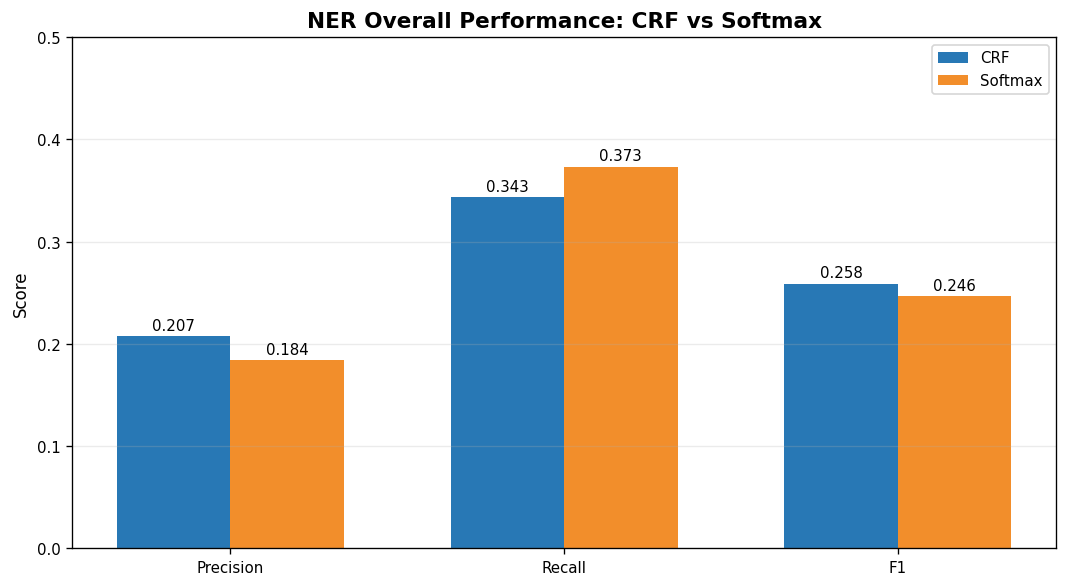

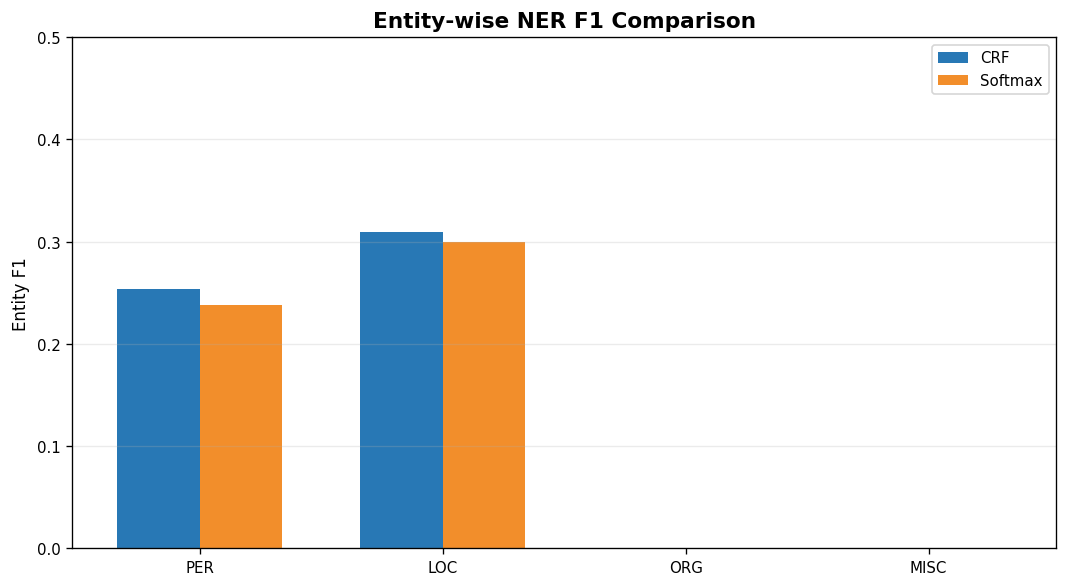

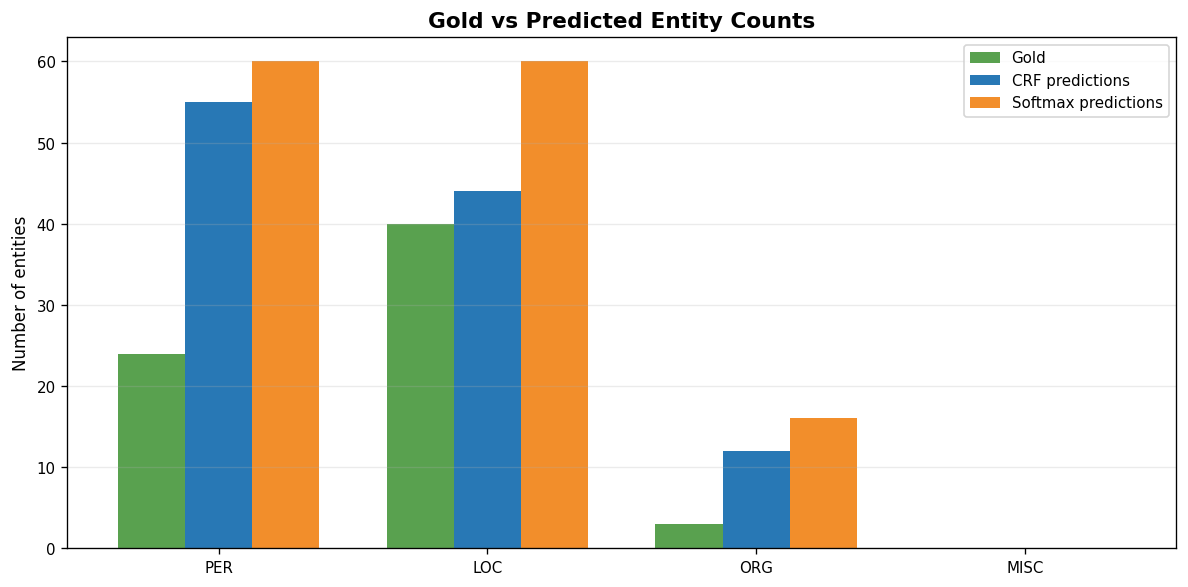

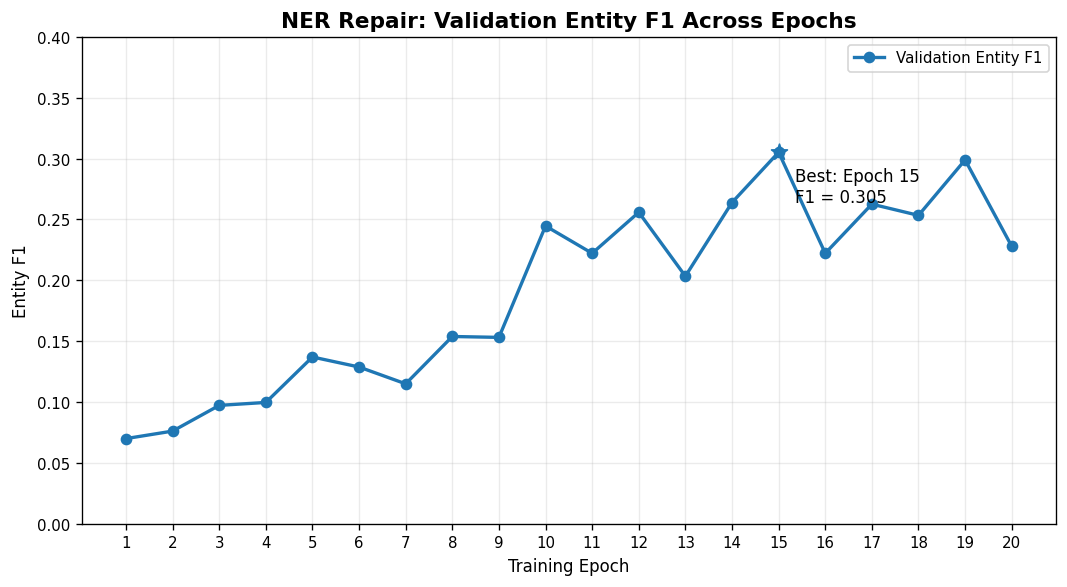

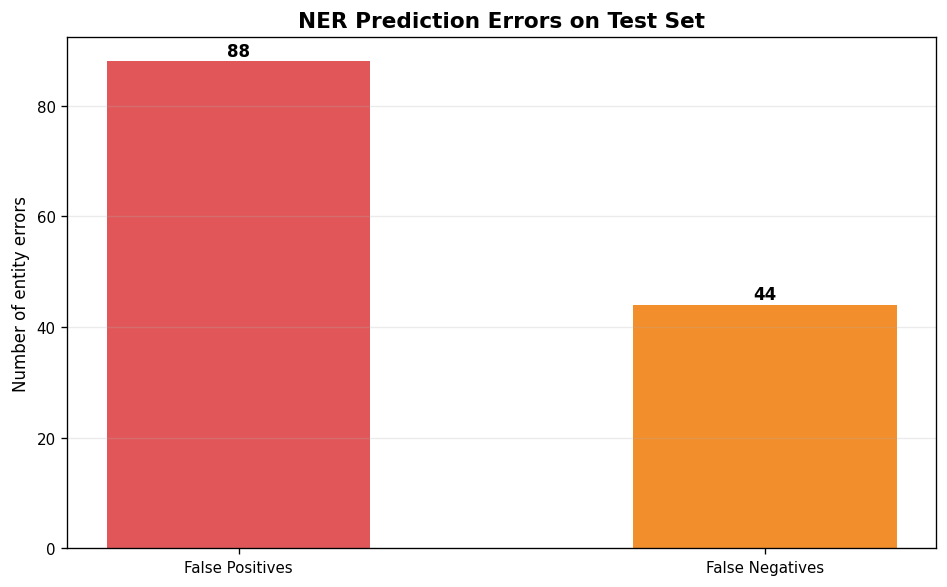

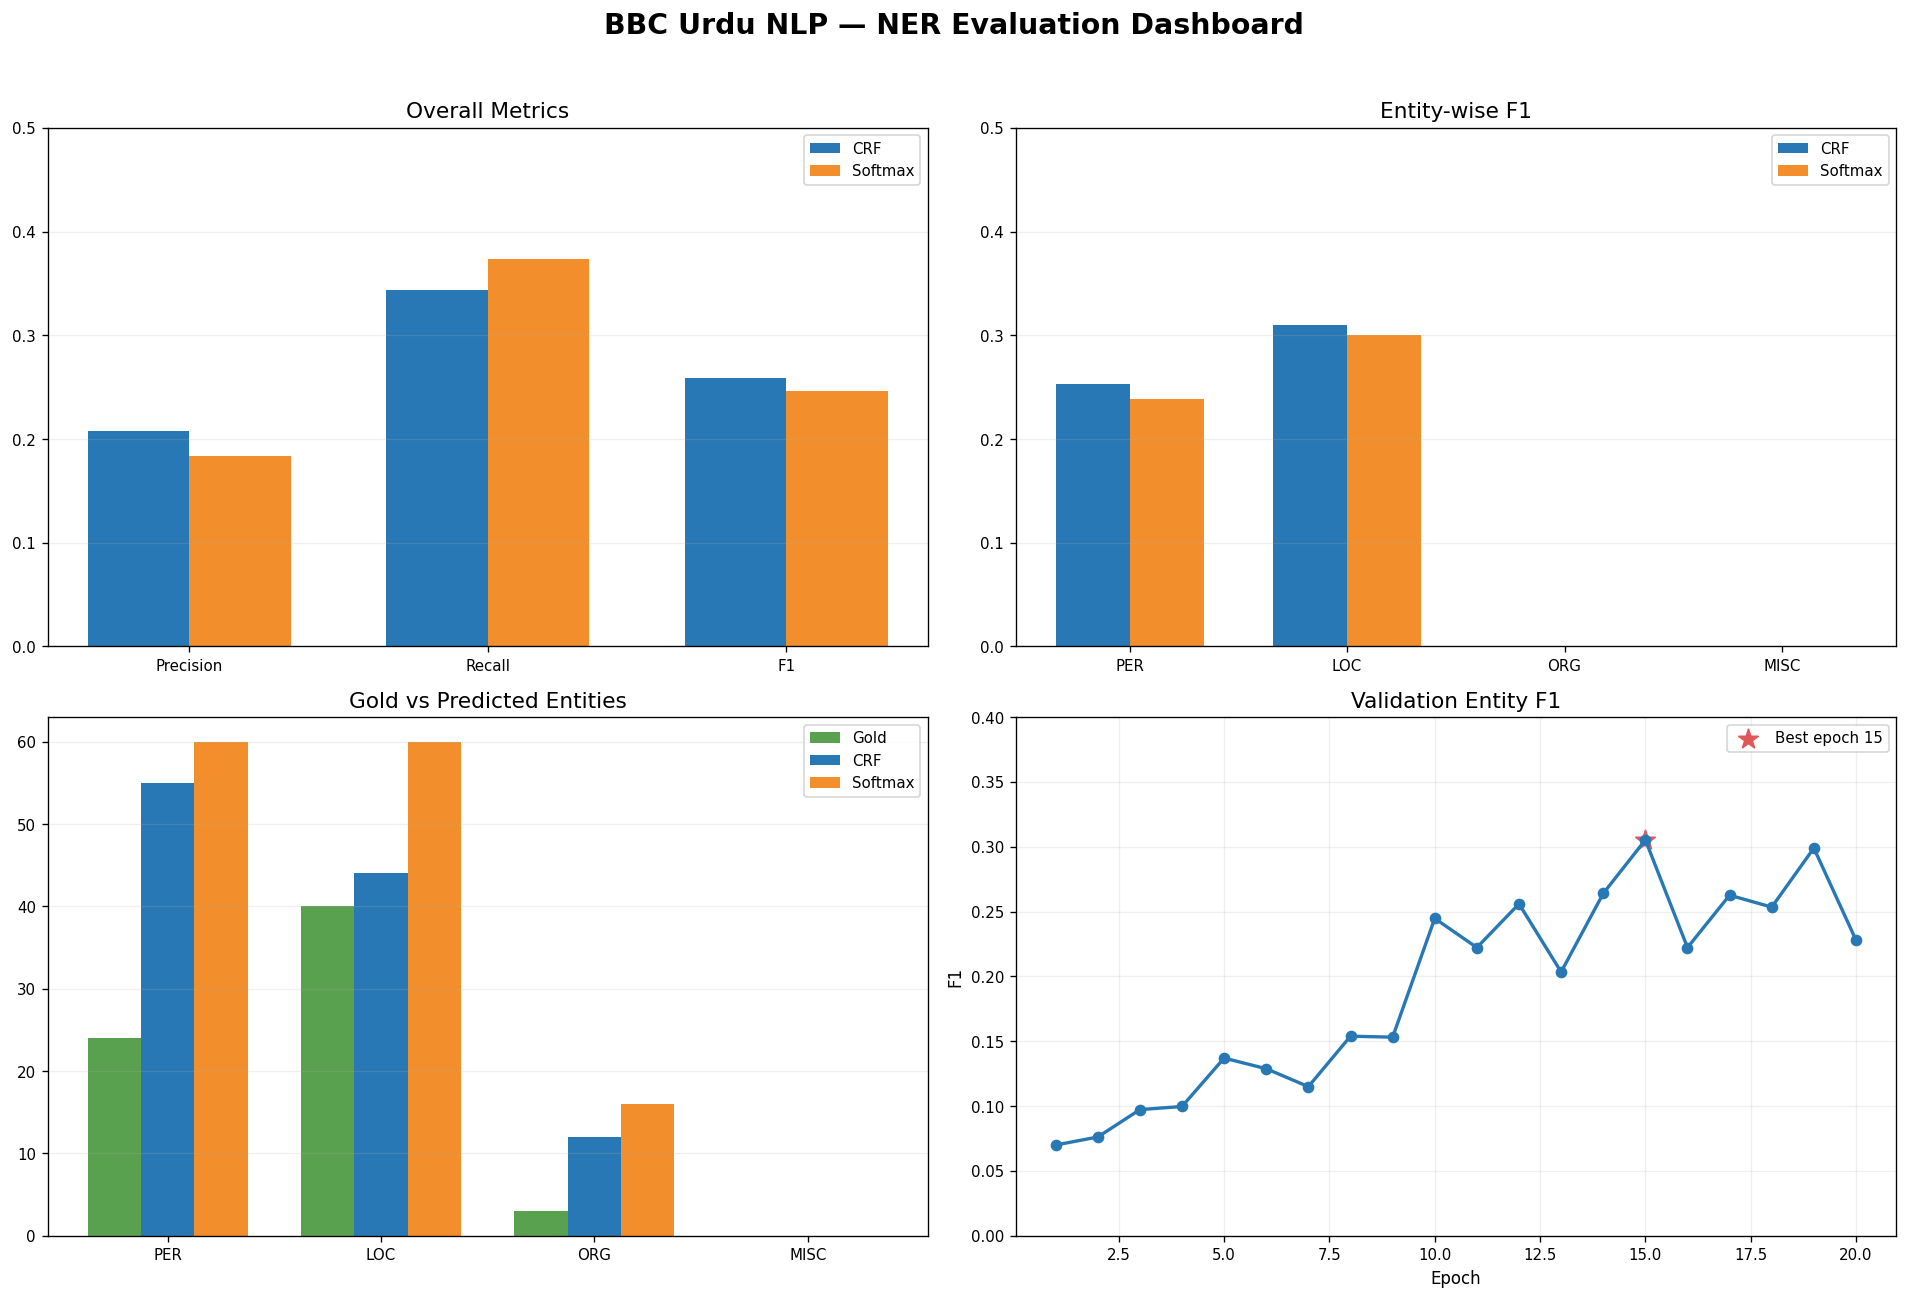


NER VISUALIZATION COMPLETED
CRF overall F1:     0.2584
Softmax overall F1: 0.2463
Best validation F1: 0.3053 at epoch 15
False positives: 88
False negatives: 44

Saved visualization files:
 - NER_01_CRF_vs_Softmax.png
 - NER_02_Entity_Wise_F1.png
 - NER_03_Entity_Counts.png
 - NER_04_Validation_F1_History.png
 - NER_05_Prediction_Errors.png
 - NER_06_Complete_Dashboard.png


In [68]:

# ================================================================
# PART 2 — NER RESULTS VISUALIZATION
# Report-ready charts using existing CSV outputs
# No training or model evaluation required
# ================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------
# 1. LOAD EXISTING RESULTS
# ------------------------------------------------

BASE_DIR = "/content/BBC_Urdu_NLP_Assignment2/part2_sequence_labelling"

EVAL_DIR = os.path.join(BASE_DIR, "ner_evaluation")

HISTORY_PATH = os.path.join(
    BASE_DIR,
    "ner_repair_results",
    "NER_repair_history.csv"
)

crf = pd.read_csv(
    os.path.join(EVAL_DIR, "NER_CRF_entity_metrics.csv")
)

softmax = pd.read_csv(
    os.path.join(EVAL_DIR, "NER_Softmax_entity_metrics.csv")
)

comparison = pd.read_csv(
    os.path.join(EVAL_DIR, "NER_CRF_vs_Softmax.csv")
)

fp = pd.read_csv(
    os.path.join(EVAL_DIR, "NER_false_positives.csv")
)

fn = pd.read_csv(
    os.path.join(EVAL_DIR, "NER_false_negatives.csv")
)

history = pd.read_csv(HISTORY_PATH)

# Exclude overall row for entity-level charts.
entity_comparison = comparison[
    comparison["Entity"] != "OVERALL"
].copy()

overall = comparison[
    comparison["Entity"] == "OVERALL"
].iloc[0]

# ------------------------------------------------
# 2. GENERAL PLOT SETTINGS
# ------------------------------------------------

plt.rcParams.update({
    "figure.figsize": (10, 6),
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.dpi": 120
})

# ------------------------------------------------
# 3. CHART 1 — CRF VS SOFTMAX OVERALL PERFORMANCE
# ------------------------------------------------

metrics = ["Precision", "Recall", "F1"]

crf_values = [
    overall["Precision_CRF"],
    overall["Recall_CRF"],
    overall["F1_CRF"]
]

softmax_values = [
    overall["Precision_Softmax"],
    overall["Recall_Softmax"],
    overall["F1_Softmax"]
]

x = np.arange(len(metrics))
width = 0.34

fig, ax = plt.subplots(figsize=(9, 5))

bars1 = ax.bar(
    x - width / 2,
    crf_values,
    width,
    label="CRF",
    color="#2878B5"
)

bars2 = ax.bar(
    x + width / 2,
    softmax_values,
    width,
    label="Softmax",
    color="#F28E2B"
)

ax.set_title(
    "NER Overall Performance: CRF vs Softmax",
    fontweight="bold"
)

ax.set_ylabel("Score")
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 0.50)

ax.legend()
ax.grid(axis="y", alpha=0.25)

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(
            f"{height:.3f}",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            fontsize=9
        )

plt.tight_layout()

fig.savefig(
    os.path.join(EVAL_DIR, "NER_01_CR F_vs_Softmax.png".replace(" ", "")),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------
# 4. CHART 2 — ENTITY-WISE F1 COMPARISON
# ------------------------------------------------

entities = entity_comparison["Entity"].tolist()

crf_f1 = entity_comparison["F1_CRF"].values
softmax_f1 = entity_comparison["F1_Softmax"].values

x = np.arange(len(entities))

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    x - width / 2,
    crf_f1,
    width,
    label="CRF",
    color="#2878B5"
)

ax.bar(
    x + width / 2,
    softmax_f1,
    width,
    label="Softmax",
    color="#F28E2B"
)

ax.set_title(
    "Entity-wise NER F1 Comparison",
    fontweight="bold"
)

ax.set_ylabel("Entity F1")
ax.set_xticks(x)
ax.set_xticklabels(entities)
ax.set_ylim(0, max(0.5, max(crf_f1.max(), softmax_f1.max()) + 0.1))

ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

fig.savefig(
    os.path.join(EVAL_DIR, "NER_02_Entity_Wise_F1.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------
# 5. CHART 3 — GOLD VS PREDICTED ENTITY COUNTS
# ------------------------------------------------

entity_types = ["PER", "LOC", "ORG", "MISC"]

gold_counts = [
    int(crf.loc[crf["Entity"] == e, "Gold entities"].iloc[0])
    for e in entity_types
]

crf_counts = [
    int(crf.loc[crf["Entity"] == e, "Predicted entities"].iloc[0])
    for e in entity_types
]

softmax_counts = [
    int(softmax.loc[softmax["Entity"] == e, "Predicted entities"].iloc[0])
    for e in entity_types
]

x = np.arange(len(entity_types))
width3 = 0.25

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    x - width3,
    gold_counts,
    width3,
    label="Gold",
    color="#59A14F"
)

ax.bar(
    x,
    crf_counts,
    width3,
    label="CRF predictions",
    color="#2878B5"
)

ax.bar(
    x + width3,
    softmax_counts,
    width3,
    label="Softmax predictions",
    color="#F28E2B"
)

ax.set_title(
    "Gold vs Predicted Entity Counts",
    fontweight="bold"
)

ax.set_ylabel("Number of entities")
ax.set_xticks(x)
ax.set_xticklabels(entity_types)

ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

fig.savefig(
    os.path.join(EVAL_DIR, "NER_03_Entity_Counts.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------
# 6. CHART 4 — NER TRAINING AND VALIDATION F1
# ------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    history["epoch"],
    history["val_entity_f1"],
    marker="o",
    linewidth=2,
    label="Validation Entity F1"
)

ax.set_title(
    "NER Repair: Validation Entity F1 Across Epochs",
    fontweight="bold"
)

ax.set_xlabel("Training Epoch")
ax.set_ylabel("Entity F1")
ax.set_xticks(history["epoch"])
ax.set_ylim(0, max(0.4, history["val_entity_f1"].max() + 0.08))

ax.grid(alpha=0.25)
ax.legend()

best_index = history["val_entity_f1"].idxmax()
best_epoch = int(history.loc[best_index, "epoch"])
best_f1 = history.loc[best_index, "val_entity_f1"]

ax.scatter(
    [best_epoch],
    [best_f1],
    s=100,
    marker="*",
    label="Best epoch",
    zorder=5
)

ax.annotate(
    f"Best: Epoch {best_epoch}\nF1 = {best_f1:.3f}",
    xy=(best_epoch, best_f1),
    xytext=(10, -30),
    textcoords="offset points"
)

plt.tight_layout()

fig.savefig(
    os.path.join(EVAL_DIR, "NER_04_Validation_F1_History.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------
# 7. CHART 5 — FALSE POSITIVE VS FALSE NEGATIVE COUNTS
# ------------------------------------------------

error_types = ["False Positives", "False Negatives"]
error_counts = [len(fp), len(fn)]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    error_types,
    error_counts,
    color=["#E15759", "#F28E2B"],
    width=0.5
)

ax.set_title(
    "NER Prediction Errors on Test Set",
    fontweight="bold"
)

ax.set_ylabel("Number of entity errors")
ax.grid(axis="y", alpha=0.25)

for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        str(int(bar.get_height())),
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()

fig.savefig(
    os.path.join(EVAL_DIR, "NER_05_Prediction_Errors.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------
# 8. COMBINED FOUR-PANEL DASHBOARD
# ------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# Panel A: Overall metrics
ax = axes[0, 0]

ax.bar(
    x[:3] if False else np.arange(3) - 0.17,
    crf_values,
    0.34,
    label="CRF",
    color="#2878B5"
)

ax.bar(
    np.arange(3) + 0.17,
    softmax_values,
    0.34,
    label="Softmax",
    color="#F28E2B"
)

ax.set_xticks(np.arange(3))
ax.set_xticklabels(metrics)
ax.set_ylim(0, 0.5)
ax.set_title("Overall Metrics")
ax.legend()
ax.grid(axis="y", alpha=0.2)

# Panel B: Entity F1
ax = axes[0, 1]

ax.bar(
    np.arange(4) - 0.17,
    crf_f1,
    0.34,
    label="CRF",
    color="#2878B5"
)

ax.bar(
    np.arange(4) + 0.17,
    softmax_f1,
    0.34,
    label="Softmax",
    color="#F28E2B"
)

ax.set_xticks(np.arange(4))
ax.set_xticklabels(entities)
ax.set_ylim(0, 0.5)
ax.set_title("Entity-wise F1")
ax.legend()
ax.grid(axis="y", alpha=0.2)

# Panel C: Entity counts
ax = axes[1, 0]

ax.bar(
    np.arange(4) - 0.25,
    gold_counts,
    0.25,
    label="Gold",
    color="#59A14F"
)

ax.bar(
    np.arange(4),
    crf_counts,
    0.25,
    label="CRF",
    color="#2878B5"
)

ax.bar(
    np.arange(4) + 0.25,
    softmax_counts,
    0.25,
    label="Softmax",
    color="#F28E2B"
)

ax.set_xticks(np.arange(4))
ax.set_xticklabels(entities)
ax.set_title("Gold vs Predicted Entities")
ax.legend()
ax.grid(axis="y", alpha=0.2)

# Panel D: Validation F1
ax = axes[1, 1]

ax.plot(
    history["epoch"],
    history["val_entity_f1"],
    marker="o",
    linewidth=2,
    color="#2878B5"
)

ax.scatter(
    [best_epoch],
    [best_f1],
    marker="*",
    s=150,
    color="#E15759",
    label=f"Best epoch {best_epoch}"
)

ax.set_title("Validation Entity F1")
ax.set_xlabel("Epoch")
ax.set_ylabel("F1")
ax.set_ylim(0, 0.4)
ax.legend()
ax.grid(alpha=0.2)

fig.suptitle(
    "BBC Urdu NLP — NER Evaluation Dashboard",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

fig.savefig(
    os.path.join(EVAL_DIR, "NER_06_Complete_Dashboard.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------
# 9. FINAL SUMMARY
# ------------------------------------------------

print("\n" + "=" * 60)
print("NER VISUALIZATION COMPLETED")
print("=" * 60)

print(f"CRF overall F1:     {overall['F1_CRF']:.4f}")
print(f"Softmax overall F1: {overall['F1_Softmax']:.4f}")
print(f"Best validation F1: {best_f1:.4f} at epoch {best_epoch}")
print("False positives:", len(fp))
print("False negatives:", len(fn))

print("\nSaved visualization files:")

for filename in sorted(os.listdir(EVAL_DIR)):
    if filename.endswith(".png"):
        print(" -", filename)


Evaluation device: cuda

POS labels: ['NOUN', 'PROPN', 'VERB', 'ADJ', 'ADV', 'PRON', 'ADP', 'AUX', 'CONJ', 'PART', 'NUM', 'PUNCT']
Number of POS labels: 12
Token mapping found: id_to_token

FROZEN POS RESULTS
Test sentences: 75
Test tokens:    2231
Accuracy:       0.4307
Macro Precision:0.2752
Macro Recall:   0.2791
Macro F1:       0.2625

Classification Report:
              precision    recall  f1-score   support

        NOUN       0.39      0.60      0.48       510
       PROPN       0.46      0.65      0.54       316
        VERB       0.39      0.44      0.41       177
         ADJ       0.00      0.00      0.00       135
         ADV       0.00      0.00      0.00        23
        PRON       0.31      0.12      0.18       113
         ADP       0.52      0.47      0.49       427
         AUX       0.45      0.66      0.53       163
        CONJ       0.25      0.21      0.23       102
        PART       0.00      0.00      0.00        79
         NUM       0.00      0.00      0

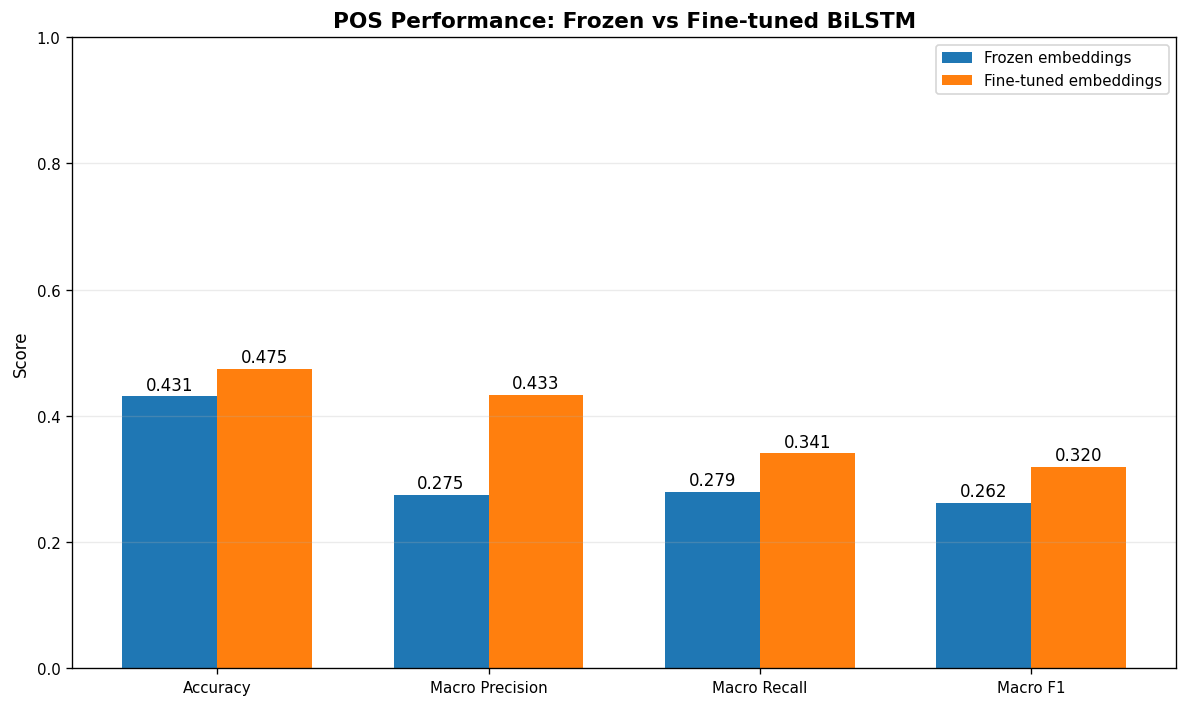

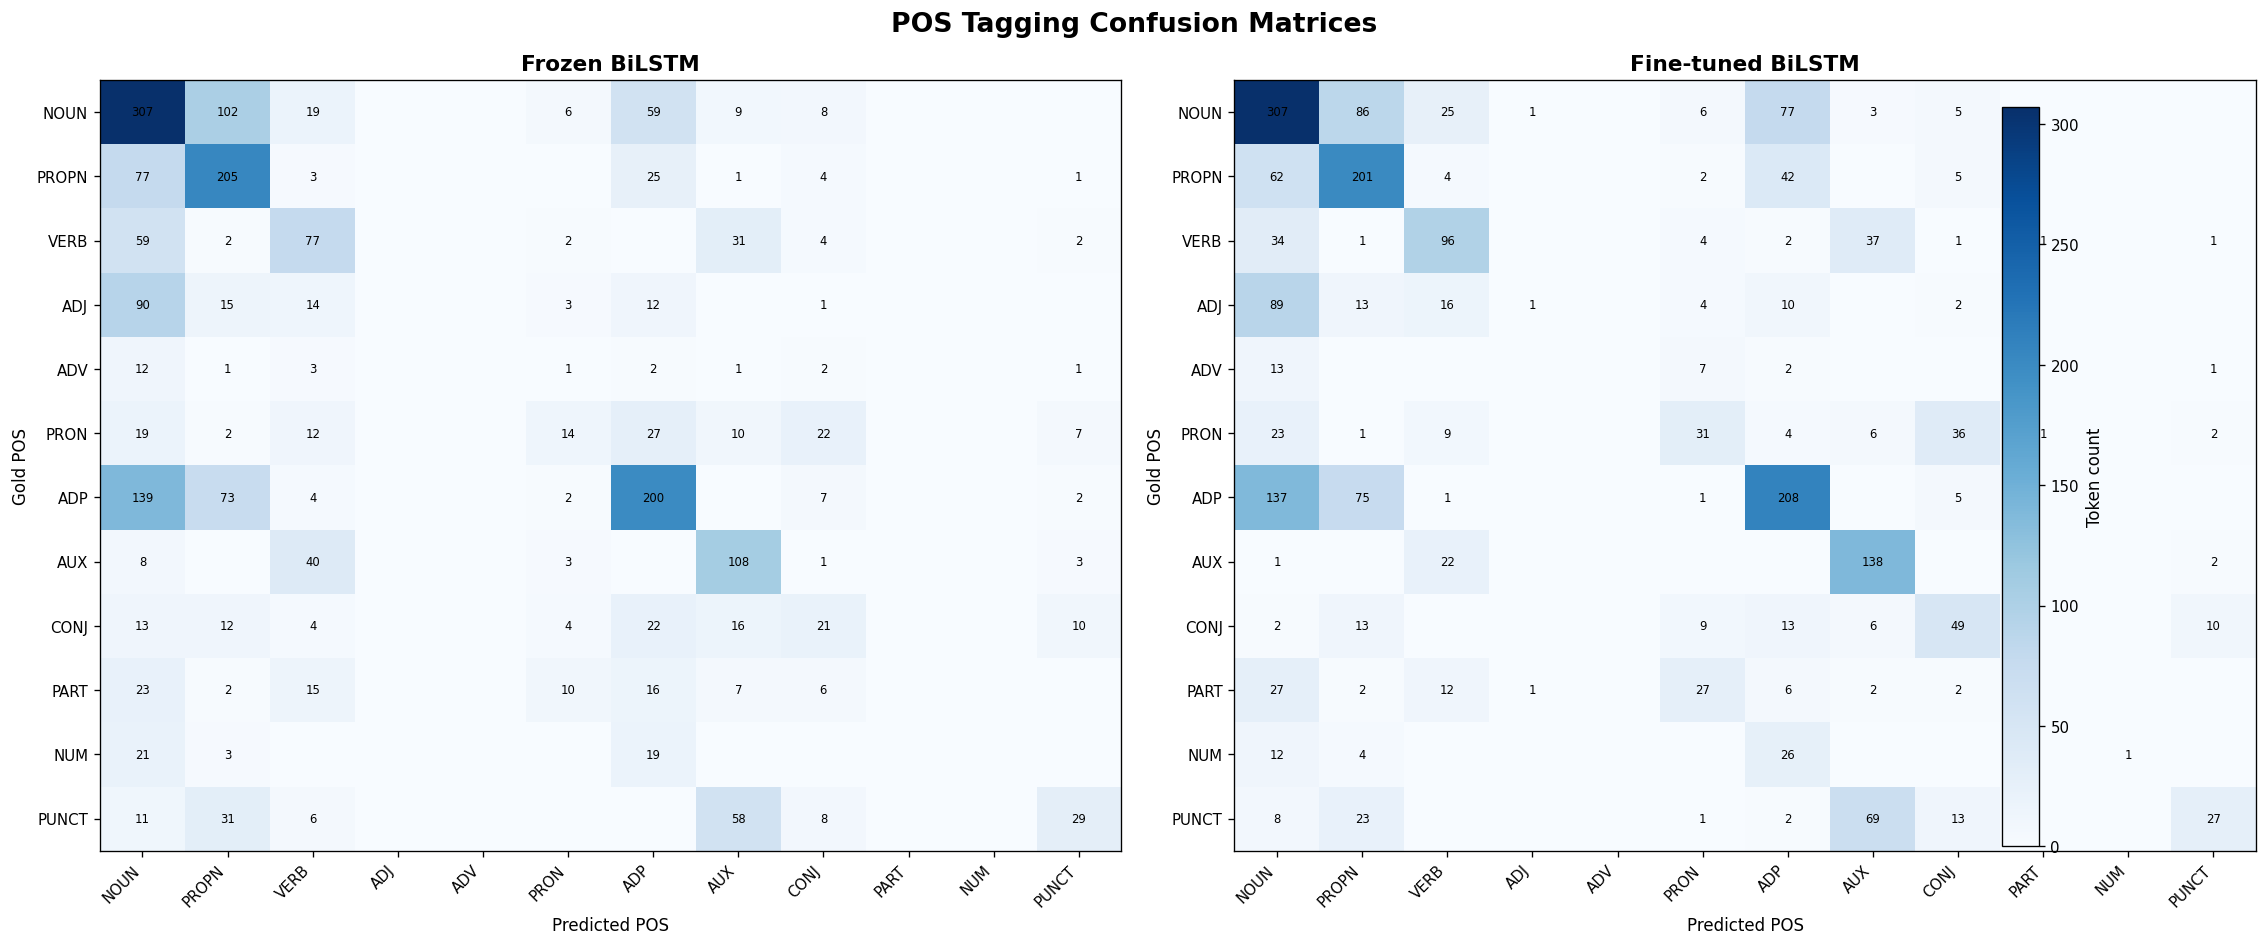


POS EVALUATION COMPLETED

Saved files in:
/content/BBC_Urdu_NLP_Assignment2/part2_sequence_labelling/bilstm_results_corrected
 - POS_01_Frozen_vs_Finetuned.png
 - POS_02_Confusion_Matrices.png
 - POS_finetuned_classification_report.csv
 - POS_finetuned_confusion_matrix.csv
 - POS_frozen_classification_report.csv
 - POS_frozen_confusion_matrix.csv
 - POS_frozen_vs_finetuned.csv
 - POS_top_confusion_examples.txt

No model training was performed.


In [69]:

# ================================================================
# PART 2 — POS EVALUATION
# Frozen vs Fine-tuned BiLSTM
# Uses saved checkpoints; NO TRAINING
# ================================================================

import os
import copy
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------
# 1. PATHS AND CHECKPOINTS
# ------------------------------------------------

BASE_DIR = "/content/BBC_Urdu_NLP_Assignment2/part2_sequence_labelling"

RESULT_DIR = os.path.join(
    BASE_DIR,
    "bilstm_results_corrected"
)

os.makedirs(RESULT_DIR, exist_ok=True)

CHECKPOINTS = {
    "Frozen": os.path.join(
        RESULT_DIR,
        "Corrected_BiLSTM_frozen_best.pth"
    ),
    "Fine-tuned": os.path.join(
        RESULT_DIR,
        "Corrected_BiLSTM_finetuned_best.pth"
    )
}

for name, path in CHECKPOINTS.items():
    assert os.path.exists(path), f"Missing {name} checkpoint: {path}"

assert "model" in globals(), "BiLSTM model architecture is not available."
assert "test_loader" in globals(), "test_loader is not available."

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Evaluation device:", device)

# ------------------------------------------------
# 2. LOAD POS TAGS
# ------------------------------------------------

first_checkpoint = torch.load(
    CHECKPOINTS["Frozen"],
    map_location=device,
    weights_only=False
)

POS_TAGS = first_checkpoint["pos_tags"]
NUM_TAGS = len(POS_TAGS)

print("\nPOS labels:", POS_TAGS)
print("Number of POS labels:", NUM_TAGS)

# ------------------------------------------------
# 3. FIND TOKEN ID TO WORD MAPPING
# ------------------------------------------------

id_to_word = None

# Try common vocabulary variable names from the notebook.
for variable_name in [
    "id_to_token",
    "idx_to_token",
    "idx_to_word",
    "id2word",
    "itos"
]:
    candidate = globals().get(variable_name)

    if isinstance(candidate, (dict, list, tuple)):
        id_to_word = candidate
        print("Token mapping found:", variable_name)
        break

# If only word-to-ID vocabulary exists, reverse it.
if id_to_word is None:
    for variable_name in [
        "word_to_id",
        "word2idx",
        "token_to_id",
        "vocab"
    ]:
        candidate = globals().get(variable_name)

        if isinstance(candidate, dict):
            id_to_word = {
                int(index): word
                for word, index in candidate.items()
                if isinstance(index, (int, np.integer))
            }
            print("Reversed vocabulary:", variable_name)
            break

def get_word(token_id):
    if id_to_word is None:
        return str(token_id)

    try:
        return str(id_to_word[int(token_id)])
    except (KeyError, IndexError, TypeError):
        return str(token_id)

# ------------------------------------------------
# 4. EVALUATION FUNCTION
# ------------------------------------------------

def evaluate_pos(checkpoint_path, model_name):

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )

    # Use the existing architecture and load saved weights.
    evaluation_model = copy.deepcopy(model)

    evaluation_model.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True
    )

    evaluation_model.to(device)
    evaluation_model.eval()

    all_gold = []
    all_pred = []
    sentence_records = []

    sentence_number = 0

    with torch.no_grad():

        for batch in test_loader:

            token_ids, pos_labels, ner_labels, mask = batch

            token_ids = token_ids.to(device)
            pos_labels = pos_labels.to(device)
            mask = mask.to(device).bool()

            pos_logits, _ = evaluation_model(token_ids)

            predictions = torch.argmax(
                pos_logits,
                dim=-1
            )

            for i in range(token_ids.size(0)):

                valid_length = int(mask[i].sum().item())

                gold_sequence = (
                    pos_labels[i, :valid_length]
                    .cpu().numpy()
                    .astype(int)
                )

                pred_sequence = (
                    predictions[i, :valid_length]
                    .cpu().numpy()
                    .astype(int)
                )

                token_sequence = (
                    token_ids[i, :valid_length]
                    .cpu().numpy()
                    .astype(int)
                )

                all_gold.extend(gold_sequence.tolist())
                all_pred.extend(pred_sequence.tolist())

                sentence_records.append({
                    "sentence_index": sentence_number,
                    "tokens": token_sequence.tolist(),
                    "gold": gold_sequence.tolist(),
                    "predicted": pred_sequence.tolist()
                })

                sentence_number += 1

    # Metrics
    accuracy = accuracy_score(all_gold, all_pred)

    macro_f1 = f1_score(
        all_gold,
        all_pred,
        labels=list(range(NUM_TAGS)),
        average="macro",
        zero_division=0
    )

    macro_precision = precision_score(
        all_gold,
        all_pred,
        labels=list(range(NUM_TAGS)),
        average="macro",
        zero_division=0
    )

    macro_recall = recall_score(
        all_gold,
        all_pred,
        labels=list(range(NUM_TAGS)),
        average="macro",
        zero_division=0
    )

    # Classification report
    report = classification_report(
        all_gold,
        all_pred,
        labels=list(range(NUM_TAGS)),
        target_names=POS_TAGS,
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(report).transpose()

    report_df.to_csv(
        os.path.join(
            RESULT_DIR,
            f"POS_{model_name}_classification_report.csv"
        )
    )

    # Confusion matrix
    cm = confusion_matrix(
        all_gold,
        all_pred,
        labels=list(range(NUM_TAGS))
    )

    cm_df = pd.DataFrame(
        cm,
        index=POS_TAGS,
        columns=POS_TAGS
    )

    cm_df.index.name = "Gold"
    cm_df.columns.name = "Predicted"

    cm_df.to_csv(
        os.path.join(
            RESULT_DIR,
            f"POS_{model_name}_confusion_matrix.csv"
        )
    )

    print("\n" + "=" * 60)
    print(f"{model_name.upper()} POS RESULTS")
    print("=" * 60)

    print(f"Test sentences: {len(sentence_records)}")
    print(f"Test tokens:    {len(all_gold)}")
    print(f"Accuracy:       {accuracy:.4f}")
    print(f"Macro Precision:{macro_precision:.4f}")
    print(f"Macro Recall:   {macro_recall:.4f}")
    print(f"Macro F1:       {macro_f1:.4f}")

    print("\nClassification Report:")
    print(
        classification_report(
            all_gold,
            all_pred,
            labels=list(range(NUM_TAGS)),
            target_names=POS_TAGS,
            zero_division=0
        )
    )

    return {
        "name": model_name,
        "gold": np.array(all_gold),
        "pred": np.array(all_pred),
        "accuracy": accuracy,
        "macro_precision": macro_precision,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "confusion_matrix": cm,
        "sentences": sentence_records
    }


# ------------------------------------------------
# 5. EVALUATE BOTH CHECKPOINTS
# ------------------------------------------------

frozen_results = evaluate_pos(
    CHECKPOINTS["Frozen"],
    "frozen"
)

finetuned_results = evaluate_pos(
    CHECKPOINTS["Fine-tuned"],
    "finetuned"
)

# ------------------------------------------------
# 6. FROZEN VS FINE-TUNED SUMMARY
# ------------------------------------------------

summary = pd.DataFrame([
    {
        "Model": "Frozen",
        "Accuracy": frozen_results["accuracy"],
        "Macro Precision": frozen_results["macro_precision"],
        "Macro Recall": frozen_results["macro_recall"],
        "Macro F1": frozen_results["macro_f1"]
    },
    {
        "Model": "Fine-tuned",
        "Accuracy": finetuned_results["accuracy"],
        "Macro Precision": finetuned_results["macro_precision"],
        "Macro Recall": finetuned_results["macro_recall"],
        "Macro F1": finetuned_results["macro_f1"]
    }
])

summary.to_csv(
    os.path.join(RESULT_DIR, "POS_frozen_vs_finetuned.csv"),
    index=False
)

print("\nFROZEN VS FINE-TUNED")
print(summary.to_string(index=False))

# ------------------------------------------------
# 7. FIND TOP THREE CONFUSED TAG PAIRS
# ------------------------------------------------

def get_top_confusions(results, model_name):

    cm = results["confusion_matrix"]
    pairs = []

    for gold_id in range(NUM_TAGS):
        for pred_id in range(NUM_TAGS):

            if gold_id == pred_id:
                continue

            count = int(cm[gold_id, pred_id])

            if count > 0:
                pairs.append({
                    "Gold_Tag": POS_TAGS[gold_id],
                    "Predicted_Tag": POS_TAGS[pred_id],
                    "Count": count,
                    "Gold_ID": gold_id,
                    "Predicted_ID": pred_id
                })

    pairs.sort(
        key=lambda item: item["Count"],
        reverse=True
    )

    top_three = pairs[:3]

    print(f"\nTOP THREE CONFUSIONS — {model_name.upper()}")

    for rank, pair in enumerate(top_three, 1):

        print(
            f"\n{rank}. Gold {pair['Gold_Tag']} "
            f"predicted as {pair['Predicted_Tag']}: "
            f"{pair['Count']} tokens"
        )

    return top_three


frozen_confusions = get_top_confusions(
    frozen_results,
    "Frozen"
)

finetuned_confusions = get_top_confusions(
    finetuned_results,
    "Fine-tuned"
)

# ------------------------------------------------
# 8. SHOW TWO SENTENCE EXAMPLES PER CONFUSION
# ------------------------------------------------

def print_confusion_examples(results, top_pairs, model_name):

    output_lines = []

    for rank, pair in enumerate(top_pairs, 1):

        gold_id = pair["Gold_ID"]
        pred_id = pair["Predicted_ID"]

        heading = (
            f"\n{rank}. {pair['Gold_Tag']} -> "
            f"{pair['Predicted_Tag']} "
            f"({pair['Count']} occurrences)"
        )

        print(heading)
        output_lines.append(heading)

        examples_found = 0

        for sentence in results["sentences"]:

            for position, (gold, pred) in enumerate(
                zip(sentence["gold"], sentence["predicted"])
            ):

                if gold == gold_id and pred == pred_id:

                    words = [
                        get_word(token)
                        for token in sentence["tokens"]
                    ]

                    # Mark the incorrectly classified token.
                    words[position] = (
                        "[" + words[position] + "]"
                    )

                    example = (
                        f"Sentence {sentence['sentence_index']}: "
                        + " ".join(words)
                    )

                    print(example)
                    output_lines.append(example)

                    examples_found += 1

                    if examples_found == 2:
                        break

            if examples_found == 2:
                break

        if examples_found == 0:
            message = "No sentence examples found."
            print(message)
            output_lines.append(message)

    return output_lines


frozen_examples = print_confusion_examples(
    frozen_results,
    frozen_confusions,
    "Frozen"
)

finetuned_examples = print_confusion_examples(
    finetuned_results,
    finetuned_confusions,
    "Fine-tuned"
)

with open(
    os.path.join(RESULT_DIR, "POS_top_confusion_examples.txt"),
    "w",
    encoding="utf-8"
) as f:

    f.write("FROZEN MODEL\n")
    f.write("\n".join(frozen_examples))

    f.write("\n\nFINE-TUNED MODEL\n")
    f.write("\n".join(finetuned_examples))

# ------------------------------------------------
# 9. VISUALIZATION — FROZEN VS FINE-TUNED
# ------------------------------------------------

metric_names = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1"
]

frozen_values = [
    frozen_results["accuracy"],
    frozen_results["macro_precision"],
    frozen_results["macro_recall"],
    frozen_results["macro_f1"]
]

fine_values = [
    finetuned_results["accuracy"],
    finetuned_results["macro_precision"],
    finetuned_results["macro_recall"],
    finetuned_results["macro_f1"]
]

x = np.arange(len(metric_names))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

bars1 = ax.bar(
    x - width / 2,
    frozen_values,
    width,
    label="Frozen embeddings"
)

bars2 = ax.bar(
    x + width / 2,
    fine_values,
    width,
    label="Fine-tuned embeddings"
)

ax.set_title(
    "POS Performance: Frozen vs Fine-tuned BiLSTM",
    fontweight="bold"
)

ax.set_ylabel("Score")
ax.set_xticks(x)
ax.set_xticklabels(metric_names)
ax.set_ylim(0, 1.0)
ax.legend()
ax.grid(axis="y", alpha=0.25)

for bars in [bars1, bars2]:
    for bar in bars:
        ax.annotate(
            f"{bar.get_height():.3f}",
            xy=(bar.get_x() + bar.get_width() / 2,
                bar.get_height()),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center"
        )

plt.tight_layout()

plt.savefig(
    os.path.join(RESULT_DIR, "POS_01_Frozen_vs_Finetuned.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------
# 10. VISUALIZATION — CONFUSION MATRICES
# ------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(19, 8))

for ax, results, title in [
    (axes[0], frozen_results, "Frozen BiLSTM"),
    (axes[1], finetuned_results, "Fine-tuned BiLSTM")
]:

    image = ax.imshow(
        results["confusion_matrix"],
        interpolation="nearest",
        aspect="auto",
        cmap="Blues"
    )

    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Predicted POS")
    ax.set_ylabel("Gold POS")

    ax.set_xticks(range(NUM_TAGS))
    ax.set_yticks(range(NUM_TAGS))

    ax.set_xticklabels(
        POS_TAGS,
        rotation=45,
        ha="right"
    )

    ax.set_yticklabels(POS_TAGS)

    for i in range(NUM_TAGS):
        for j in range(NUM_TAGS):
            value = results["confusion_matrix"][i, j]

            if value > 0:
                ax.text(
                    j, i, str(value),
                    ha="center",
                    va="center",
                    fontsize=7
                )

fig.colorbar(
    image,
    ax=axes,
    fraction=0.025,
    pad=0.02,
    label="Token count"
)

fig.suptitle(
    "POS Tagging Confusion Matrices",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    os.path.join(RESULT_DIR, "POS_02_Confusion_Matrices.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------
# 11. FINAL SUMMARY
# ------------------------------------------------

print("\n" + "=" * 65)
print("POS EVALUATION COMPLETED")
print("=" * 65)

print("\nSaved files in:")
print(RESULT_DIR)

for filename in sorted(os.listdir(RESULT_DIR)):
    if filename.startswith("POS_"):
        print(" -", filename)

print("\nNo model training was performed.")


In [70]:

# ================================================================
# PART 2 — ABLATION STUDY: A1, A2, A3
# A1: Unidirectional LSTM
# A2: BiLSTM without dropout
# A3: BiLSTM with random embeddings
#
# Reuses existing train_loader, val_loader, test_loader.
# Does not modify previous checkpoints or results.
# ================================================================

import os
import copy
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.nn.utils.rnn import (
    pack_padded_sequence,
    pad_packed_sequence
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------

BASE_DIR = "/content/BBC_Urdu_NLP_Assignment2/part2_sequence_labelling"

BASELINE_DIR = os.path.join(
    BASE_DIR, "bilstm_results_corrected"
)

ABLATION_DIR = os.path.join(
    BASE_DIR, "ablation_results"
)

os.makedirs(ABLATION_DIR, exist_ok=True)

FROZEN_CHECKPOINT = os.path.join(
    BASELINE_DIR,
    "Corrected_BiLSTM_frozen_best.pth"
)

assert os.path.exists(FROZEN_CHECKPOINT), (
    "Frozen baseline checkpoint not found."
)

assert all(
    name in globals()
    for name in ["train_loader", "val_loader", "test_loader"]
), "Train, validation or test loader is missing."

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

SEED = 42
EPOCHS = 20
PATIENCE = 5
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001
NER_AUX_WEIGHT = 0.5

torch.manual_seed(SEED)
np.random.seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Device:", device)

# ------------------------------------------------
# 2. LOAD ORIGINAL PRETRAINED EMBEDDINGS
# ------------------------------------------------

base_checkpoint = torch.load(
    FROZEN_CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

state = base_checkpoint["model_state_dict"]

embedding_candidates = [
    (name, value)
    for name, value in state.items()
    if name.endswith("embedding.weight")
    and isinstance(value, torch.Tensor)
    and value.ndim == 2
]

if not embedding_candidates:
    # Fallback: find the embedding matrix by its known shape.
    embedding_candidates = [
        (name, value)
        for name, value in state.items()
        if isinstance(value, torch.Tensor)
        and value.ndim == 2
        and value.shape[1] == 100
        and value.shape[0] > 1000
    ]

assert embedding_candidates, (
    "Could not identify the pretrained embedding matrix."
)

embedding_key, pretrained_embeddings = embedding_candidates[0]

pretrained_embeddings = pretrained_embeddings.detach().clone().float()

VOCAB_SIZE, EMBEDDING_DIM = pretrained_embeddings.shape

POS_TAGS = list(base_checkpoint["pos_tags"])
NER_TAGS = list(base_checkpoint["ner_tags"])

NUM_POS = len(POS_TAGS)
NUM_NER = len(NER_TAGS)

print("Embedding key:", embedding_key)
print("Embedding shape:", tuple(pretrained_embeddings.shape))
print("POS tags:", POS_TAGS)
print("NER tags:", NER_TAGS)

# Confirm that input IDs fit the embedding matrix.
max_token_id = 0

for loader in [train_loader, val_loader, test_loader]:
    for batch in loader:
        max_token_id = max(
            max_token_id,
            int(batch[0].max().item())
        )

assert max_token_id < VOCAB_SIZE, (
    f"Token ID {max_token_id} exceeds vocabulary size {VOCAB_SIZE}."
)

# ------------------------------------------------
# 3. CLASS WEIGHTS FROM TRAINING DATA
# ------------------------------------------------

pos_counts = torch.zeros(NUM_POS)
ner_counts = torch.zeros(NUM_NER)

for token_ids, pos_labels, ner_labels, mask in train_loader:

    mask = mask.bool()

    valid_pos = pos_labels[mask].long()
    valid_ner = ner_labels[mask].long()

    pos_counts += torch.bincount(
        valid_pos,
        minlength=NUM_POS
    ).float()

    ner_counts += torch.bincount(
        valid_ner,
        minlength=NUM_NER
    ).float()


def make_class_weights(counts, minimum, maximum):

    weights = torch.zeros_like(counts)

    present = counts > 0

    weights[present] = (
        counts[present].sum() / counts[present]
    ).sqrt()

    weights[present] = weights[present] / weights[present].mean()

    weights = torch.clamp(
        weights,
        min=minimum,
        max=maximum
    )

    return weights


POS_WEIGHTS = make_class_weights(
    pos_counts, 0.5, 4.0
).to(device)

NER_WEIGHTS = make_class_weights(
    ner_counts, 0.25, 5.0
).to(device)

# Reduce dominance of the O label.
o_index = NER_TAGS.index("O")
NER_WEIGHTS[o_index] = 0.25

print("\nTraining POS counts:", pos_counts.tolist())
print("Training NER counts:", ner_counts.tolist())

# ------------------------------------------------
# 4. CRF IMPLEMENTATION
# ------------------------------------------------

class AblationCRF(nn.Module):

    def __init__(self, num_tags):

        super().__init__()

        self.num_tags = num_tags

        self.transitions = nn.Parameter(
            torch.zeros(num_tags, num_tags)
        )

        self.start_transitions = nn.Parameter(
            torch.zeros(num_tags)
        )

        self.end_transitions = nn.Parameter(
            torch.zeros(num_tags)
        )

    def neg_log_likelihood(self, emissions, tags, mask):

        batch_size, seq_len, _ = emissions.shape

        mask = mask.bool()

        alpha = (
            self.start_transitions.unsqueeze(0)
            + emissions[:, 0]
        )

        for t in range(1, seq_len):

            scores = (
                alpha.unsqueeze(2)
                + self.transitions.unsqueeze(0)
                + emissions[:, t].unsqueeze(1)
            )

            next_alpha = torch.logsumexp(scores, dim=1)

            alpha = torch.where(
                mask[:, t].unsqueeze(1),
                next_alpha,
                alpha
            )

        log_partition = torch.logsumexp(
            alpha + self.end_transitions.unsqueeze(0),
            dim=1
        )

        first_tags = tags[:, 0]

        gold_score = (
            self.start_transitions[first_tags]
            + emissions[:, 0].gather(
                1, first_tags.unsqueeze(1)
            ).squeeze(1)
        )

        for t in range(1, seq_len):

            previous_tags = tags[:, t - 1]
            current_tags = tags[:, t]

            transition_score = self.transitions[
                previous_tags, current_tags
            ]

            emission_score = emissions[:, t].gather(
                1, current_tags.unsqueeze(1)
            ).squeeze(1)

            step_score = transition_score + emission_score

            gold_score = gold_score + (
                step_score * mask[:, t].float()
            )

        lengths = mask.sum(dim=1).clamp(min=1)

        last_indices = lengths.long() - 1

        last_tags = tags.gather(
            1, last_indices.unsqueeze(1)
        ).squeeze(1)

        gold_score = gold_score + self.end_transitions[last_tags]

        nll = log_partition - gold_score

        return (nll / lengths.float()).mean()

    def decode(self, emissions, mask):

        results = []

        for i in range(emissions.size(0)):

            length = int(mask[i].sum().item())

            sequence = emissions[i, :length]

            score = (
                self.start_transitions + sequence[0]
            )

            backpointers = []

            for t in range(1, length):

                next_score = (
                    score.unsqueeze(1)
                    + self.transitions
                    + sequence[t].unsqueeze(0)
                )

                best_score, best_path = next_score.max(dim=0)

                score = best_score
                backpointers.append(best_path)

            score = score + self.end_transitions

            last_tag = int(score.argmax().item())

            best_path = [last_tag]

            for pointer in reversed(backpointers):

                last_tag = int(pointer[last_tag].item())
                best_path.append(last_tag)

            best_path.reverse()

            results.append(best_path)

        return results


# ------------------------------------------------
# 5. ABLATION MODEL
# ------------------------------------------------

class AblationBiLSTM(nn.Module):

    def __init__(
        self,
        embedding_matrix,
        bidirectional=True,
        dropout=0.5,
        random_embeddings=False
    ):

        super().__init__()

        vocab_size, embedding_dim = embedding_matrix.shape

        if random_embeddings:

            self.embedding = nn.Embedding(
                vocab_size,
                embedding_dim,
                padding_idx=0
            )

            nn.init.normal_(
                self.embedding.weight,
                mean=0.0,
                std=0.1
            )

            with torch.no_grad():
                self.embedding.weight[0].zero_()

        else:

            self.embedding = nn.Embedding.from_pretrained(
                embedding_matrix.clone(),
                freeze=False,
                padding_idx=0
            )

        self.bidirectional = bidirectional

        # Use hidden size 256 for a unidirectional model
        # so that its output dimension matches the BiLSTM.
        hidden_size = 128 if bidirectional else 256

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_size,
            num_layers=2,
            batch_first=True,
            bidirectional=bidirectional,
            dropout=dropout
        )

        output_size = hidden_size * (
            2 if bidirectional else 1
        )

        self.pos_classifier = nn.Linear(
            output_size,
            NUM_POS
        )

        self.ner_classifier = nn.Linear(
            output_size,
            NUM_NER
        )

        self.crf = AblationCRF(NUM_NER)

    def forward(self, token_ids, mask):

        lengths = mask.sum(dim=1).cpu()

        embedded = self.embedding(token_ids)

        packed = pack_padded_sequence(
            embedded,
            lengths,
            batch_first=True,
            enforce_sorted=False
        )

        packed_output, _ = self.lstm(packed)

        output, _ = pad_packed_sequence(
            packed_output,
            batch_first=True,
            total_length=token_ids.size(1)
        )

        pos_logits = self.pos_classifier(output)
        ner_emissions = self.ner_classifier(output)

        return pos_logits, ner_emissions


# ------------------------------------------------
# 6. BIO ENTITY METRICS
# ------------------------------------------------

def extract_entities(tag_sequence, sentence_id):

    entities = set()

    start = None
    entity_type = None

    def close_entity(end_position):

        if start is not None:
            entities.add(
                (sentence_id, entity_type, start, end_position)
            )

    for i, tag in enumerate(tag_sequence):

        if tag == "O":
            close_entity(i - 1)
            start = None
            entity_type = None
            continue

        prefix, _, current_type = tag.partition("-")

        if prefix == "B" or (
            prefix == "I" and current_type != entity_type
        ):

            close_entity(i - 1)

            start = i
            entity_type = current_type

        elif prefix == "I":
            if start is None:
                start = i
                entity_type = current_type

    close_entity(len(tag_sequence) - 1)

    return entities


def calculate_ner_metrics(gold_sequences, pred_sequences):

    gold_entities = set()
    pred_entities = set()

    for sentence_id, (gold, pred) in enumerate(
        zip(gold_sequences, pred_sequences)
    ):

        gold_tags = [NER_TAGS[x] for x in gold]
        pred_tags = [NER_TAGS[x] for x in pred]

        gold_entities.update(
            extract_entities(gold_tags, sentence_id)
        )

        pred_entities.update(
            extract_entities(pred_tags, sentence_id)
        )

    correct = len(gold_entities & pred_entities)

    precision = (
        correct / len(pred_entities)
        if pred_entities else 0.0
    )

    recall = (
        correct / len(gold_entities)
        if gold_entities else 0.0
    )

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    return precision, recall, f1


# ------------------------------------------------
# 7. TRAINING AND EVALUATION FUNCTIONS
# ------------------------------------------------

def run_model(model, loader, optimizer=None):

    training = optimizer is not None

    model.train(training)

    total_loss = 0.0
    batches = 0

    all_pos_gold = []
    all_pos_pred = []

    all_ner_gold = []
    all_ner_pred = []

    context = torch.enable_grad() if training else torch.no_grad()

    with context:

        for token_ids, pos_labels, ner_labels, mask in loader:

            token_ids = token_ids.to(device)
            pos_labels = pos_labels.to(device).long()
            ner_labels = ner_labels.to(device).long()
            mask = mask.to(device).bool()

            if training:
                optimizer.zero_grad(set_to_none=True)

            pos_logits, ner_emissions = model(
                token_ids,
                mask
            )

            valid_pos_logits = pos_logits[mask]
            valid_pos_labels = pos_labels[mask]

            valid_ner_emissions = ner_emissions[mask]
            valid_ner_labels = ner_labels[mask]

            pos_loss = nn.functional.cross_entropy(
                valid_pos_logits,
                valid_pos_labels,
                weight=POS_WEIGHTS
            )

            ner_ce_loss = nn.functional.cross_entropy(
                valid_ner_emissions,
                valid_ner_labels,
                weight=NER_WEIGHTS
            )

            crf_loss = model.crf.neg_log_likelihood(
                ner_emissions,
                ner_labels,
                mask
            )

            loss = (
                pos_loss
                + crf_loss
                + NER_AUX_WEIGHT * ner_ce_loss
            )

            if training:

                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=5.0
                )

                optimizer.step()

            total_loss += float(loss.item())
            batches += 1

            pos_predictions = pos_logits.argmax(dim=-1)

            all_pos_gold.extend(
                pos_labels[mask].detach().cpu().tolist()
            )

            all_pos_pred.extend(
                pos_predictions[mask].detach().cpu().tolist()
            )

            decoded_ner = model.crf.decode(
                ner_emissions,
                mask
            )

            for i, decoded in enumerate(decoded_ner):

                length = len(decoded)

                all_ner_gold.append(
                    ner_labels[i, :length].detach().cpu().tolist()
                )

                all_ner_pred.append(decoded)

    pos_macro_f1 = f1_score(
        all_pos_gold,
        all_pos_pred,
        labels=list(range(NUM_POS)),
        average="macro",
        zero_division=0
    )

    pos_accuracy = accuracy_score(
        all_pos_gold,
        all_pos_pred
    )

    ner_precision, ner_recall, ner_f1 = calculate_ner_metrics(
        all_ner_gold,
        all_ner_pred
    )

    return {
        "loss": total_loss / max(batches, 1),
        "pos_accuracy": pos_accuracy,
        "pos_macro_f1": pos_macro_f1,
        "ner_precision": ner_precision,
        "ner_recall": ner_recall,
        "ner_f1": ner_f1
    }


# ------------------------------------------------
# 8. DEFINE THREE ABLATIONS
# ------------------------------------------------

ABLATIONS = {
    "A1_Unidirectional": {
        "bidirectional": False,
        "dropout": 0.5,
        "random_embeddings": False
    },

    "A2_No_Dropout": {
        "bidirectional": True,
        "dropout": 0.0,
        "random_embeddings": False
    },

    "A3_Random_Embeddings": {
        "bidirectional": True,
        "dropout": 0.5,
        "random_embeddings": True
    }
}

all_test_results = []
all_histories = {}

# ------------------------------------------------
# 9. TRAIN EACH ABLATION
# ------------------------------------------------

for ablation_name, settings in ABLATIONS.items():

    print("\n" + "=" * 65)
    print("STARTING:", ablation_name)
    print("=" * 65)

    torch.manual_seed(SEED)
    np.random.seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    model_ablation = AblationBiLSTM(
        embedding_matrix=pretrained_embeddings,
        **settings
    ).to(device)

    optimizer = torch.optim.Adam(
        model_ablation.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    best_score = -1.0
    best_epoch = 0
    patience_counter = 0

    history = []

    checkpoint_path = os.path.join(
        ABLATION_DIR,
        f"{ablation_name}_best.pth"
    )

    for epoch in range(1, EPOCHS + 1):

        train_metrics = run_model(
            model_ablation,
            train_loader,
            optimizer
        )

        val_metrics = run_model(
            model_ablation,
            val_loader
        )

        # Joint validation score: POS macro-F1 and NER entity F1.
        validation_score = (
            val_metrics["pos_macro_f1"]
            + val_metrics["ner_f1"]
        ) / 2

        history_row = {
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "train_pos_macro_f1": train_metrics["pos_macro_f1"],
            "train_ner_f1": train_metrics["ner_f1"],
            "val_loss": val_metrics["loss"],
            "val_pos_macro_f1": val_metrics["pos_macro_f1"],
            "val_ner_f1": val_metrics["ner_f1"],
            "validation_score": validation_score
        }

        history.append(history_row)

        print(
            f"Epoch {epoch:02d}/{EPOCHS} | "
            f"Train loss: {train_metrics['loss']:.4f} | "
            f"Val loss: {val_metrics['loss']:.4f} | "
            f"POS F1: {val_metrics['pos_macro_f1']:.4f} | "
            f"NER F1: {val_metrics['ner_f1']:.4f}"
        )

        if validation_score > best_score:

            best_score = validation_score
            best_epoch = epoch
            patience_counter = 0

            torch.save(
                {
                    "model_state_dict": model_ablation.state_dict(),
                    "settings": settings,
                    "pos_tags": POS_TAGS,
                    "ner_tags": NER_TAGS,
                    "best_epoch": best_epoch,
                    "best_validation_score": best_score
                },
                checkpoint_path
            )

        else:

            patience_counter += 1

        if patience_counter >= PATIENCE:

            print(
                f"Early stopping at epoch {epoch}; "
                f"best epoch was {best_epoch}."
            )

            break

    history_df = pd.DataFrame(history)

    history_df.to_csv(
        os.path.join(
            ABLATION_DIR,
            f"{ablation_name}_history.csv"
        ),
        index=False
    )

    all_histories[ablation_name] = history_df

    # Load best checkpoint before test evaluation.
    saved = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )

    model_ablation.load_state_dict(
        saved["model_state_dict"]
    )

    test_metrics = run_model(
        model_ablation,
        test_loader
    )

    test_metrics["Model"] = ablation_name
    test_metrics["Best_Epoch"] = best_epoch
    test_metrics["Best_Validation_Score"] = best_score

    all_test_results.append(test_metrics)

    print("\nTEST RESULTS:", ablation_name)
    for key, value in test_metrics.items():
        if isinstance(value, (float, int)):
            print(f"{key}: {value:.4f}" if isinstance(value, float)
                  else f"{key}: {value}")

    del model_ablation
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ------------------------------------------------
# 10. SAVE ABLATION COMPARISON
# ------------------------------------------------

ablation_df = pd.DataFrame(all_test_results)

ablation_df = ablation_df[
    [
        "Model",
        "Best_Epoch",
        "Best_Validation_Score",
        "pos_accuracy",
        "pos_macro_f1",
        "ner_precision",
        "ner_recall",
        "ner_f1"
    ]
]

ablation_df.to_csv(
    os.path.join(
        ABLATION_DIR,
        "A1_A2_A3_ablation_comparison.csv"
    ),
    index=False
)

print("\n" + "=" * 65)
print("ABLATION STUDY — TEST RESULTS")
print("=" * 65)

print(ablation_df.round(4).to_string(index=False))


# ------------------------------------------------
# 11. SAVE TRAINING HISTORIES TOGETHER
# ------------------------------------------------

combined_history = []

for model_name, history_df in all_histories.items():

    temp = history_df.copy()
    temp.insert(0, "Model", model_name)

    combined_history.append(temp)

combined_history_df = pd.concat(
    combined_history,
    ignore_index=True
)

combined_history_df.to_csv(
    os.path.join(
        ABLATION_DIR,
        "A1_A2_A3_combined_training_history.csv"
    ),
    index=False
)

# ------------------------------------------------
# 12. FINAL OUTPUT
# ------------------------------------------------

print("\nABLATION IMPLEMENTATION COMPLETED.")
print("\nSaved files:")

for filename in sorted(os.listdir(ABLATION_DIR)):
    print(" -", filename)

print("\nAll three ablations used the same data loaders.")
print("Original baseline and NER repair checkpoints were not modified.")


Device: cuda
Embedding key: embedding.weight
Embedding shape: (11126, 100)
POS tags: ['NOUN', 'PROPN', 'VERB', 'ADJ', 'ADV', 'PRON', 'ADP', 'AUX', 'CONJ', 'PART', 'NUM', 'PUNCT']
NER tags: ['O', 'B-PER', 'I-PER', 'B-LOC', 'I-LOC', 'B-ORG', 'I-ORG']

Training POS counts: [2422.0, 1596.0, 754.0, 613.0, 78.0, 420.0, 1967.0, 699.0, 470.0, 355.0, 167.0, 685.0]
Training NER counts: [9637.0, 204.0, 184.0, 93.0, 22.0, 29.0, 57.0]

STARTING: A1_Unidirectional
Epoch 01/20 | Train loss: 4.2945 | Val loss: 3.1878 | POS F1: 0.0334 | NER F1: 0.0000
Epoch 02/20 | Train loss: 3.2080 | Val loss: 3.0109 | POS F1: 0.0334 | NER F1: 0.0000
Epoch 03/20 | Train loss: 3.1121 | Val loss: 2.9590 | POS F1: 0.0334 | NER F1: 0.0000
Epoch 04/20 | Train loss: 3.0844 | Val loss: 2.9370 | POS F1: 0.0334 | NER F1: 0.0000
Epoch 05/20 | Train loss: 3.0604 | Val loss: 2.9286 | POS F1: 0.0446 | NER F1: 0.0000
Epoch 06/20 | Train loss: 3.0400 | Val loss: 2.8987 | POS F1: 0.0487 | NER F1: 0.0000
Epoch 07/20 | Train loss: 2.9

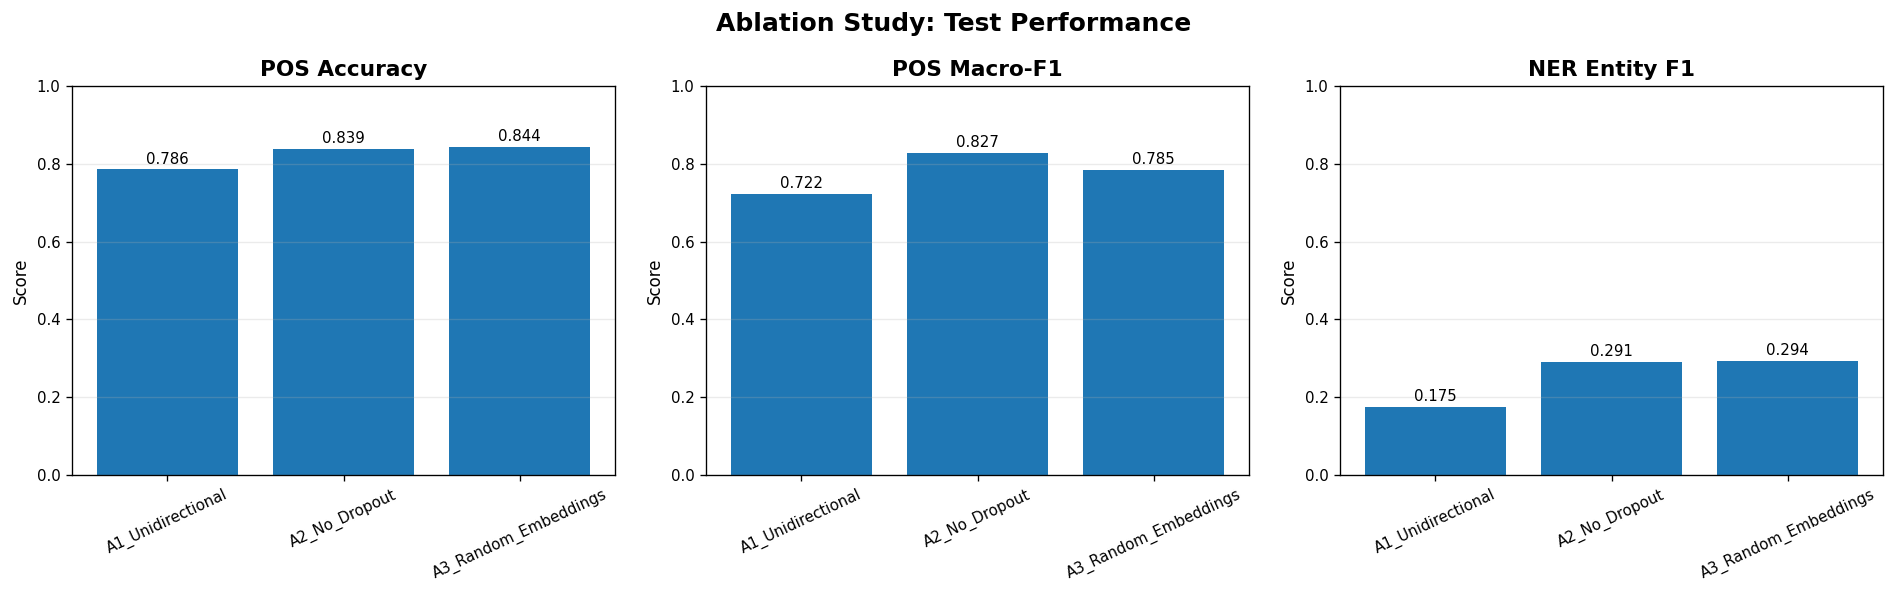

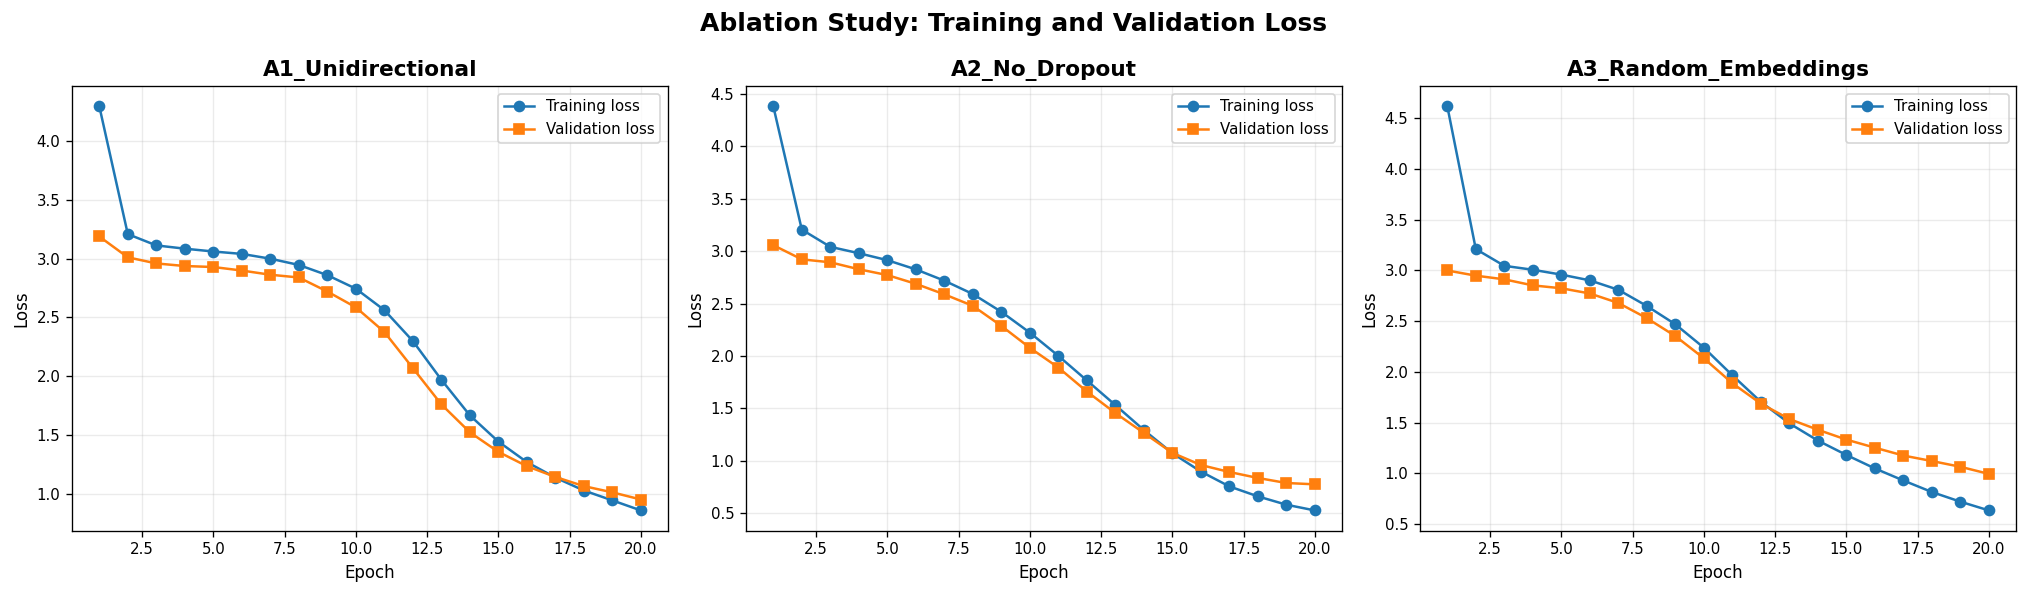

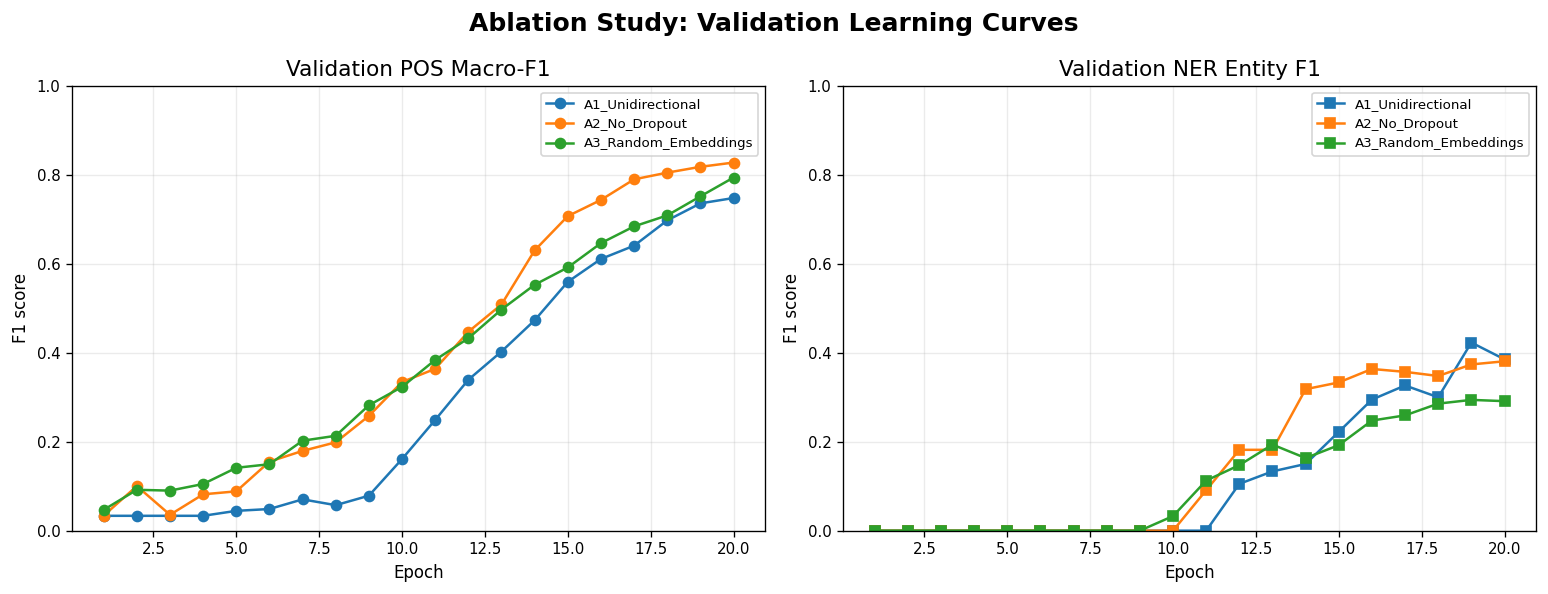

,Model,pos_accuracy,pos_macro_f1,ner_precision,ner_recall,ner_f1
0,A1_Unidirectional,0.7857,0.7220,0.2500,0.1343,0.1748
1,A2_No_Dropout,0.8386,0.8274,0.4167,0.2239,0.2913
2,A3_Random_Embeddings,0.8445,0.7846,0.3810,0.2388,0.2936



Visualization files saved in: /content/BBC_Urdu_NLP_Assignment2/part2_sequence_labelling/ablation_results
 - Ablation_01_Test_Performance.png
 - Ablation_02_Loss_Curves.png
 - Ablation_03_Validation_F1.png


In [71]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE_DIR = "/content/BBC_Urdu_NLP_Assignment2/part2_sequence_labelling"
ABLATION_DIR = os.path.join(BASE_DIR, "ablation_results")

results = pd.read_csv(
    os.path.join(
        ABLATION_DIR,
        "A1_A2_A3_ablation_comparison.csv"
    )
)

history = pd.read_csv(
    os.path.join(
        ABLATION_DIR,
        "A1_A2_A3_combined_training_history.csv"
    )
)

# ------------------------------------------------
# 1. COMPARISON OF POS AND NER PERFORMANCE
# ------------------------------------------------

metrics = [
    ("pos_accuracy", "POS Accuracy"),
    ("pos_macro_f1", "POS Macro-F1"),
    ("ner_f1", "NER Entity F1")
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (column, title) in zip(axes, metrics):

    bars = ax.bar(results["Model"], results[column])

    ax.set_title(title, fontweight="bold")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=0.25)

    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.015,
            f"{bar.get_height():.3f}",
            ha="center",
            fontsize=9
        )

plt.suptitle(
    "Ablation Study: Test Performance",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    os.path.join(ABLATION_DIR, "Ablation_01_Test_Performance.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------
# 2. TRAINING AND VALIDATION LOSS
# ------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, model_name in zip(axes, history["Model"].unique()):

    subset = history[
        history["Model"] == model_name
    ]

    ax.plot(
        subset["epoch"],
        subset["train_loss"],
        marker="o",
        label="Training loss"
    )

    ax.plot(
        subset["epoch"],
        subset["val_loss"],
        marker="s",
        label="Validation loss"
    )

    ax.set_title(model_name, fontweight="bold")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(alpha=0.25)

plt.suptitle(
    "Ablation Study: Training and Validation Loss",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    os.path.join(ABLATION_DIR, "Ablation_02_Loss_Curves.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------
# 3. POS MACRO-F1 AND NER F1 LEARNING CURVES
# ------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for model_name in history["Model"].unique():

    subset = history[
        history["Model"] == model_name
    ]

    axes[0].plot(
        subset["epoch"],
        subset["val_pos_macro_f1"],
        marker="o",
        label=model_name
    )

    axes[1].plot(
        subset["epoch"],
        subset["val_ner_f1"],
        marker="s",
        label=model_name
    )

axes[0].set_title("Validation POS Macro-F1")
axes[1].set_title("Validation NER Entity F1")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("F1 score")
    ax.set_ylim(0, 1)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)

plt.suptitle(
    "Ablation Study: Validation Learning Curves",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    os.path.join(ABLATION_DIR, "Ablation_03_Validation_F1.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------
# 4. SAVE A COMPACT RESULTS TABLE
# ------------------------------------------------

display(
    results[
        [
            "Model",
            "pos_accuracy",
            "pos_macro_f1",
            "ner_precision",
            "ner_recall",
            "ner_f1"
        ]
    ].round(4)
)

print("\nVisualization files saved in:", ABLATION_DIR)

for filename in [
    "Ablation_01_Test_Performance.png",
    "Ablation_02_Loss_Curves.png",
    "Ablation_03_Validation_F1.png"
]:
    print(" -", filename)


In [72]:
# ------------------------------------------------
# 3. FIND TOKEN ID TO WORD MAPPING
# ------------------------------------------------

id_to_word = None

# First check the exact vocabulary used by the dataset/model.
for variable_name in [
    "id_to_token",
    "idx_to_token",
    "idx_to_word",
    "id2word",
    "itos"
]:
    candidate = globals().get(variable_name)

    if isinstance(candidate, (dict, list, tuple)):
        id_to_word = candidate
        print("Token mapping found:", variable_name)
        break

# Reverse word-to-ID mapping if necessary.
if id_to_word is None:
    for variable_name in [
        "word_to_id",
        "word2idx",
        "token_to_id",
        "vocab"
    ]:
        candidate = globals().get(variable_name)

        if isinstance(candidate, dict):
            id_to_word = {
                int(index): word
                for word, index in candidate.items()
                if isinstance(index, (int, np.integer))
            }
            print("Reversed vocabulary:", variable_name)
            break

if id_to_word is None:
    print("WARNING: No vocabulary mapping found.")
    print("Confusion examples will display token IDs.")

def get_word(token_id):
    if id_to_word is None:
        return f"ID_{token_id}"

    try:
        if isinstance(id_to_word, dict):
            return str(id_to_word[int(token_id)])
        return str(id_to_word[int(token_id)])
    except (KeyError, IndexError, TypeError):
        return f"ID_{token_id}"

Token mapping found: id_to_token


In [73]:

# ================================================================
# PART 2 — FINAL CLEANUP (NO TRAINING)
# Task 1: POS examples from distinct sentences
# Task 2: Inspect saved NER error/prediction files
# ================================================================

import os
import pandas as pd

BASE_DIR = "/content/BBC_Urdu_NLP_Assignment2/part2_sequence_labelling"
POS_DIR = os.path.join(BASE_DIR, "bilstm_results_corrected")
NER_DIR = os.path.join(BASE_DIR, "ner_evaluation")

# ------------------------------------------------
# TASK 1 — TWO DISTINCT SENTENCES PER POS CONFUSION
# ------------------------------------------------

def distinct_pos_examples(results, top_pairs, model_name):
    lines = [f"{model_name.upper()} POS CONFUSION EXAMPLES"]

    for rank, pair in enumerate(top_pairs, 1):
        gold_id = pair["Gold_ID"]
        pred_id = pair["Predicted_ID"]
        found_sentences = set()
        examples = []

        for sentence in results["sentences"]:
            sentence_id = sentence["sentence_index"]

            if sentence_id in found_sentences:
                continue

            words = [get_word(t) for t in sentence["tokens"]]

            for position, (gold, pred) in enumerate(
                zip(sentence["gold"], sentence["predicted"])
            ):
                if gold == gold_id and pred == pred_id:
                    words[position] = "[" + words[position] + "]"
                    examples.append(
                        f"Sentence {sentence_id}: " + " ".join(words)
                    )
                    found_sentences.add(sentence_id)
                    break

            if len(examples) == 2:
                break

        lines.append(
            f"\n{rank}. {pair['Gold_Tag']} -> "
            f"{pair['Predicted_Tag']} ({pair['Count']} tokens)"
        )
        lines.extend(examples)

        if len(examples) < 2:
            lines.append(
                "Only one distinct sentence was found for this pair."
            )

    return lines


frozen_lines = distinct_pos_examples(
    frozen_results, frozen_confusions, "Frozen"
)

fine_lines = distinct_pos_examples(
    finetuned_results, finetuned_confusions, "Fine-tuned"
)

pos_example_path = os.path.join(
    POS_DIR, "POS_distinct_confusion_examples.txt"
)

with open(pos_example_path, "w", encoding="utf-8") as f:
    f.write("\n".join(frozen_lines))
    f.write("\n\n")
    f.write("\n".join(fine_lines))

print("TASK 1 COMPLETE — POS examples saved:")
print(pos_example_path)
print("\n".join(frozen_lines))
print("\n".join(fine_lines))


# ------------------------------------------------
# TASK 2 — INSPECT NER FILES FOR ERROR EXPLANATIONS
# ------------------------------------------------

print("\n" + "=" * 65)
print("TASK 2 — NER ERROR FILE INSPECTION")
print("=" * 65)

for filename in [
    "NER_false_positives.csv",
    "NER_false_negatives.csv",
    "NER_test_token_predictions.csv",
    "NER_CRF_entity_metrics.csv",
    "NER_Softmax_entity_metrics.csv"
]:
    path = os.path.join(NER_DIR, filename)

    if os.path.exists(path):
        df = pd.read_csv(path)
        print(f"\n{filename}")
        print("Rows:", len(df))
        print("Columns:", df.columns.tolist())
        print(df.head(3).to_string(index=False))
    else:
        print(f"\nMISSING: {path}")

print("\nPOS examples completed. NER file inspection completed.")


TASK 1 COMPLETE — POS examples saved:
/content/BBC_Urdu_NLP_Assignment2/part2_sequence_labelling/bilstm_results_corrected/POS_distinct_confusion_examples.txt
FROZEN POS CONFUSION EXAMPLES

1. ADP -> NOUN (139 tokens)
Sentence 1: ۔ وقت اشرف سر [کا] وسائل پاکستا وزیر سابق ایک نے رہا انگلینڈ ہے نہیں گا اسی ہیں کوئ ہی انگلینڈ کا دنوں اور ایئن جان ایک کو لیا اسی ہے ہندو کہ کالو اور لوہار ٹیسٹ گیا سال کی
Sentence 2: ۔ بین سنگ [کا] تھا کامیاب کر نے فلائٹ کا و اوق مختلف نمبر ہیں بست دور ان کیچ کا ۔ ۔ معلوم کہن کرت کی

2. NOUN -> PROPN (102 tokens)
Sentence 0: [وہاں] سرکار قائم مردان ہو تنازع ۔ ایٹلس تھوک بھی ۔ ہے مزید ایک نے بندر اور حیثیت کا عرب بالکل بھال نہر ہیں ۔ ۔ عقل میں عبدالحق اٹل میں دن معذور ہے ۔ انھ تک کیا کی
Sentence 1: ۔ وقت [اشرف] سر کا وسائل پاکستا وزیر سابق ایک نے رہا انگلینڈ ہے نہیں گا اسی ہیں کوئ ہی انگلینڈ کا دنوں اور ایئن جان ایک کو لیا اسی ہے ہندو کہ کالو اور لوہار ٹیسٹ گیا سال کی

3. ADJ -> NOUN (90 tokens)
Sentence 1: ۔ وقت اشرف سر کا وسائل [پاکستا] وزیر سابق ایک نے رہا 

In [74]:

# ================================================================
# PART 2 — FINAL NER EVALUATION AND ERROR ANALYSIS
# NO TRAINING — uses saved token predictions
# ================================================================

import os
import pandas as pd
import numpy as np

BASE_DIR = "/content/BBC_Urdu_NLP_Assignment2/part2_sequence_labelling"
NER_DIR = os.path.join(BASE_DIR, "ner_evaluation")
os.makedirs(NER_DIR, exist_ok=True)

INPUT_FILE = os.path.join(
    NER_DIR, "NER_test_token_predictions.csv"
)

assert os.path.exists(INPUT_FILE), f"Missing: {INPUT_FILE}"

df = pd.read_csv(INPUT_FILE)
df = df.sort_values(["sentence_index", "token_index"]).reset_index(drop=True)

required = [
    "sentence_index", "token_index", "token",
    "gold_ner", "crf_prediction", "softmax_prediction"
]
missing = [c for c in required if c not in df.columns]
assert not missing, f"Missing columns: {missing}"

ENTITY_TYPES = ["PER", "LOC", "ORG", "MISC"]


# ------------------------------------------------
# 1. EXTRACT BIO ENTITY SPANS
# I-X without a preceding matching B-X is treated
# as the beginning of a new entity.
# ------------------------------------------------

def extract_spans(data, tag_column):
    spans = set()

    for sentence_id, group in data.groupby("sentence_index", sort=True):
        group = group.sort_values("token_index")
        tags = group[tag_column].fillna("O").astype(str).tolist()
        positions = group["token_index"].astype(int).tolist()

        active_type = None
        active_start = None
        active_end = None

        def close_entity():
            nonlocal active_type, active_start, active_end
            if active_type is not None:
                spans.add((
                    int(sentence_id),
                    int(active_start),
                    int(active_end),
                    active_type
                ))
            active_type = None
            active_start = None
            active_end = None

        for position, tag in zip(positions, tags):
            if tag == "O" or "-" not in tag:
                close_entity()
                continue

            prefix, entity_type = tag.split("-", 1)

            if entity_type not in ENTITY_TYPES:
                close_entity()
                continue

            if prefix == "B":
                close_entity()
                active_type = entity_type
                active_start = position
                active_end = position

            elif prefix == "I":
                if active_type == entity_type:
                    active_end = position
                else:
                    close_entity()
                    active_type = entity_type
                    active_start = position
                    active_end = position

            else:
                close_entity()

        close_entity()

    return spans


# ------------------------------------------------
# 2. CONSISTENT ENTITY-LEVEL METRICS
# ------------------------------------------------

gold_spans = extract_spans(df, "gold_ner")
crf_spans = extract_spans(df, "crf_prediction")
softmax_spans = extract_spans(df, "softmax_prediction")


def calculate_metrics(gold, predicted, model_name):
    rows = []

    for entity_type in ENTITY_TYPES:
        gold_type = {x for x in gold if x[3] == entity_type}
        pred_type = {x for x in predicted if x[3] == entity_type}
        correct = gold_type.intersection(pred_type)

        precision = len(correct) / len(pred_type) if pred_type else 0
        recall = len(correct) / len(gold_type) if gold_type else 0
        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall else 0
        )

        rows.append({
            "Model": model_name,
            "Entity": entity_type,
            "Gold entities": len(gold_type),
            "Predicted entities": len(pred_type),
            "Correct entities": len(correct),
            "Precision": precision,
            "Recall": recall,
            "F1": f1
        })

    correct_all = gold.intersection(predicted)
    precision = len(correct_all) / len(predicted) if predicted else 0
    recall = len(correct_all) / len(gold) if gold else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    rows.append({
        "Model": model_name,
        "Entity": "OVERALL",
        "Gold entities": len(gold),
        "Predicted entities": len(predicted),
        "Correct entities": len(correct_all),
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

    return pd.DataFrame(rows)


crf_metrics = calculate_metrics(gold_spans, crf_spans, "CRF")
softmax_metrics = calculate_metrics(gold_spans, softmax_spans, "Softmax")

all_metrics = pd.concat(
    [crf_metrics, softmax_metrics],
    ignore_index=True
)

crf_metrics.to_csv(
    os.path.join(NER_DIR, "NER_CRF_consistent_metrics.csv"),
    index=False
)
softmax_metrics.to_csv(
    os.path.join(NER_DIR, "NER_Softmax_consistent_metrics.csv"),
    index=False
)
all_metrics.to_csv(
    os.path.join(NER_DIR, "NER_CRF_vs_Softmax_consistent.csv"),
    index=False
)

print("=" * 65)
print("CONSISTENT BIO ENTITY-LEVEL RESULTS")
print("=" * 65)
print(all_metrics.to_string(index=False, float_format=lambda x: f"{x:.4f}"))


# ------------------------------------------------
# 3. PREPARE SENTENCE TEXT AND ENTITY SURFACES
# ------------------------------------------------

sentence_data = {}

for sentence_id, group in df.groupby("sentence_index", sort=True):
    group = group.sort_values("token_index")
    sentence_data[int(sentence_id)] = {
        "tokens": group["token"].fillna("").astype(str).tolist(),
        "text": " ".join(group["token"].fillna("").astype(str))
    }


def span_surface(span):
    sentence_id, start, end, entity_type = span
    tokens = sentence_data.get(sentence_id, {}).get("tokens", [])
    positions = df[
        (df["sentence_index"] == sentence_id) &
        (df["token_index"] >= start) &
        (df["token_index"] <= end)
    ].sort_values("token_index")["token"].astype(str).tolist()

    return " ".join(positions)


# ------------------------------------------------
# 4. EXPLAIN FALSE POSITIVES AND FALSE NEGATIVES
# ------------------------------------------------

def explain_fp(entity_type, surface):
    return (
        f"The model predicted '{surface}' as {entity_type}, "
        "but the reference annotation does not contain an exact "
        "matching entity span. This is a false positive under "
        "strict span evaluation. It may reflect over-prediction, "
        "a boundary/type disagreement, or an omission in the "
        "automatically generated reference labels."
    )


def explain_fn(entity_type, surface):
    return (
        f"The reference annotation marks '{surface}' as {entity_type}, "
        "but the model did not predict the same exact entity span. "
        "This is a false negative under strict span evaluation. "
        "Possible causes include missed entity recognition, "
        "incorrect entity boundaries, or confusion with another tag."
    )


def make_error_table(gold, predicted, error_type):
    if error_type == "FP":
        errors = predicted - gold
    else:
        errors = gold - predicted

    rows = []

    for span in sorted(errors)[:5]:
        sentence_id, start, end, entity_type = span
        surface = span_surface(span)
        sentence = sentence_data.get(sentence_id, {}).get("text", "")

        rows.append({
            "Sentence index": sentence_id,
            "Entity type": entity_type,
            "Start token": start,
            "End token": end,
            "Entity": surface,
            "Sentence": sentence,
            "Explanation": (
                explain_fp(entity_type, surface)
                if error_type == "FP"
                else explain_fn(entity_type, surface)
            )
        })

    return pd.DataFrame(rows)


for model_name, predicted_spans in [
    ("CRF", crf_spans),
    ("Softmax", softmax_spans)
]:
    fp_table = make_error_table(
        gold_spans, predicted_spans, "FP"
    )
    fn_table = make_error_table(
        gold_spans, predicted_spans, "FN"
    )

    fp_table.to_csv(
        os.path.join(NER_DIR, f"NER_{model_name}_five_false_positives.csv"),
        index=False
    )
    fn_table.to_csv(
        os.path.join(NER_DIR, f"NER_{model_name}_five_false_negatives.csv"),
        index=False
    )

    print(f"\n{'=' * 65}")
    print(f"{model_name} — FIVE FALSE POSITIVES")
    print("=" * 65)
    print(fp_table.to_string(index=False))

    print(f"\n{model_name} — FIVE FALSE NEGATIVES")
    print("=" * 65)
    print(fn_table.to_string(index=False))


# ------------------------------------------------
# 5. SAVE A CONSOLIDATED REPORT
# ------------------------------------------------

report_path = os.path.join(
    NER_DIR, "NER_final_evaluation_summary.txt"
)

with open(report_path, "w", encoding="utf-8") as f:
    f.write("NER FINAL EVALUATION\n")
    f.write("Strict exact BIO entity-span evaluation\n\n")
    f.write(all_metrics.to_string(index=False))
    f.write("\n\nIMPORTANT NOTES\n")
    f.write(
        "- CRF and Softmax were evaluated on the same test predictions.\n"
        "- An entity is correct only when its sentence, start, end, "
        "and entity type match exactly.\n"
        "- MISC has no gold entities in this test set and is not "
        "meaningfully evaluable.\n"
        "- Reference labels were automatically generated pseudo-labels, "
        "not manually verified gold annotations.\n"
    )

print("\n" + "=" * 65)
print("NER FINAL CLEANUP COMPLETED")
print("=" * 65)
print("Saved in:", NER_DIR)
print("Metrics:", "NER_CRF_vs_Softmax_consistent.csv")
print("Error tables: NER_CR F / Softmax five FP and FN CSV files")
print("Summary:", report_path)


CONSISTENT BIO ENTITY-LEVEL RESULTS
  Model  Entity  Gold entities  Predicted entities  Correct entities  Precision  Recall     F1
    CRF     PER             24                  55                10     0.1818  0.4167 0.2532
    CRF     LOC             40                  44                13     0.2955  0.3250 0.3095
    CRF     ORG              3                  12                 0     0.0000  0.0000 0.0000
    CRF    MISC              0                   0                 0     0.0000  0.0000 0.0000
    CRF OVERALL             67                 111                23     0.2072  0.3433 0.2584
Softmax     PER             24                  60                10     0.1667  0.4167 0.2381
Softmax     LOC             40                  60                15     0.2500  0.3750 0.3000
Softmax     ORG              3                  16                 0     0.0000  0.0000 0.0000
Softmax    MISC              0                   0                 0     0.0000  0.0000 0.0000
Softmax OVERAL

## Part 03 of Assignment

In [75]:

import os
import re
import json
import pandas as pd
from collections import Counter

BASE = "/content/BBC_Urdu_NLP_Assignment2"
DATA = os.path.join(BASE, "data")

metadata_path = os.path.join(DATA, "Metadata.json")
cleaned_path = os.path.join(DATA, "cleaned.txt")

assert os.path.exists(metadata_path), f"Missing: {metadata_path}"
assert os.path.exists(cleaned_path), f"Missing: {cleaned_path}"

# Load metadata
with open(metadata_path, "r", encoding="utf-8") as f:
    metadata = json.load(f)

if isinstance(metadata, dict):
    metadata = metadata.get("articles", metadata.get("data", []))

# Reconstruct articles from cleaned.txt
with open(cleaned_path, "r", encoding="utf-8") as f:
    lines = f.read().splitlines()

articles = []
current = []

for line in lines:
    line = line.strip()

    if line.startswith("ARTICLE"):
        if current:
            articles.append(" ".join(current).strip())
            current = []
    elif line:
        current.append(line)

if current:
    articles.append(" ".join(current).strip())

# Display dataset integrity
print("=" * 65)
print("PART 3 — DATASET AUDIT")
print("=" * 65)
print("Metadata records:", len(metadata))
print("Reconstructed articles:", len(articles))
print("Metadata fields:", list(metadata[0].keys()) if metadata else [])
print("First metadata record:")
print(metadata[0] if metadata else "No metadata")

print("\nFirst three article previews:")
for i, article in enumerate(articles[:3], 1):
    print(f"\nArticle {i}: {article[:500]}")

# Indicative English keywords from assignment
keywords = {
    "Politics": [
        "election", "government", "minister", "parliament"
    ],
    "Sports": [
        "cricket", "match", "team", "player", "score"
    ],
    "Economy": [
        "inflation", "trade", "bank", "gdp", "budget"
    ],
    "International": [
        "un", "treaty", "foreign", "bilateral", "conflict"
    ],
    "Health & Society": [
        "hospital", "disease", "vaccine", "flood", "education"
    ]
}

# Inspect title and article text keyword matches.
# This is a preliminary English-keyword audit, not final labeling.
print("\n" + "=" * 65)
print("PRELIMINARY KEYWORD MATCH AUDIT")
print("=" * 65)

for category, terms in keywords.items():
    matches = []

    for i, article in enumerate(articles):
        title = str(metadata[i].get("title", "")) if i < len(metadata) else ""
        text = (title + " " + article).lower()

        found = [
            term for term in terms
            if re.search(r"\b" + re.escape(term) + r"\b", text)
        ]

        if found:
            matches.append((i + 1, found))

    print(f"\n{category}: {len(matches)} articles matched")
    for article_id, found in matches[:8]:
        print(f"  Article {article_id}: {', '.join(found)}")

print("\nAudit complete. No files were modified.")


PART 3 — DATASET AUDIT
Metadata records: 246
Reconstructed articles: 246
Metadata fields: ['article_number', 'title', 'date', 'url', 'word_count']
First metadata record:
{'article_number': 1, 'title': 'سائنسدانوں کے لیے معمہ بننے والی وہ مچھلیاں جو ایک لاکھ سال سے سیکس کے بغیر اپنی نسل بڑھا رہی ہیں', 'date': '2026-06-03', 'url': 'https://www.bbc.com/urdu/articles/c04200079zlo', 'word_count': 2756}

First three article previews:

Article 1: میکسیکو اور جنوب ٹیکساس کے دریاؤں میں مچھل کی ایک ایس قسم پائ جات ہے جس کا بظاہر وجود ناممکن ہون چاہی ۔ گرم اور ہلک بہاؤ وال پان میں مکمل طور پر ماد مچھل پر مشتمل جھنڈ اکثر تیر نظر آتا ہے ۔ دریاؤں کے تیر کے دور ان ماد مچھل کے چاند جیس چمک ہوئ پر ایک اور نسل کی نر مچھل سے ٹکرا ہیں ۔ ٹکرا کے اس ساد سے عمل کے دور ہی یہ ماد مچھل اپن لیے ایک ساتھ کا انتخاب کرت ہیں ۔ تاہم ارتقائ عمل کے ایک غیر معمول واقع کے طور پر ، نر مچھل کے جینز ماد کے بچہ کے حوال سے کوئ کردار ادا نہیں کرت ۔ یہ ایک حیاتیا عمل ہے جس

Article 2: ’پارٹیشن نے ہر اس فیمل کو تبا کر دیا جس نے 

In [76]:

import re
import pandas as pd
from collections import Counter

# Urdu equivalents and common news vocabulary.
# These are indicative matching terms, not manually verified labels.
urdu_keywords = {
    "Politics": [
        "انتخاب", "الیکشن", "حکومت", "حکومتوں", "وزیر", "وزیراعظم",
        "وزیر اعظم", "پارلیمان", "پارلیمنٹ", "اسمبلی", "سیاست",
        "سیاسی", "سیاست دان", "صدر", "حکمران", "اپوزیشن", "پارٹی",
        "عدالت", "سپریم کورٹ", "ہائی کورٹ", "جج", "پولیس", "گرفتار",
        "گرفتاری", "مقدم", "جیل", "قانون", "آئین", "انتظامیہ",
        "قومی اسمبلی", "سینیٹ", "پارلیمانی", "الیکشن کمیشن",
        "رکن اسمبلی", "وزارت", "سرکار", "ریاست"
    ],

    "Sports": [
        "کرکٹ", "میچ", "ٹیم", "کھلاڑی", "اسکور", "سکور", "رنز",
        "وکٹ", "کپتان", "ٹورنامنٹ", "فٹبال", "ہاکی", "کھیل",
        "کھلاڑیوں", "بیٹنگ", "بولنگ", "گیند", "بلے", "گول",
        "چیمپئن", "ورلڈ کپ", "ٹی ٹوئنٹی", "ٹیسٹ میچ",
        "ون ڈے", "پاکستان کرکٹ", "مقابلہ", "اولمپک", "میڈل",
        "فائنل", "سیمی فائنل", "رن", "کوچ", "اسپورٹس"
    ],

    "Economy": [
        "مہنگائی", "معیشت", "اقتصاد", "تجارت", "بینک", "بینکوں",
        "جی ڈی پی", "بجٹ", "روپے", "روپیہ", "ڈالر", "قیمت",
        "کاروبار", "مالی", "سرمایہ", "سرمایہ کاری", "ٹیکس",
        "درآمد", "برآمد", "قرض", "مارکیٹ", "اسٹاک", "صنعت",
        "تنخواہ", "منافع", "نقصان", "معاشی", "آئی ایم ایف",
        "شرح سود", "معاشی ترقی", "مالیات", "پٹرول", "توانائی",
        "شیئر", "اسٹاک مارکیٹ", "زر مبادلہ", "کساد بازاری"
    ],

    "International": [
        "اقوام متحدہ", "یو این", "معاہد", "غیر ملکی", "دوطرفہ",
        "تنازع", "جنگ", "عالمی", "بین الاقوامی", "خارجہ",
        "سفارتی", "سفارت", "امریکہ", "امریکا", "چین", "بھارت",
        "اسرائیل", "فلسطین", "ایران", "افغانستان", "روس",
        "یوکرین", "برطانیہ", "یورپ", "عرب", "غزہ", "لبنان",
        "سرحد", "حملہ", "فوجی کارروائی", "جنگ بندی",
        "پناہ گزین", "سلامتی کونسل", "سفیر", "دورہ",
        "پارٹیشن", "تقسیم", "عالمی رہنما", "غیر ملکی دورہ"
    ],

    "Health & Society": [
        "ہسپتال", "اسپتال", "بیماری", "ویکسین", "سیلاب",
        "تعلیم", "صحت", "ڈاکٹر", "مریض", "علاج", "وبا",
        "اسکول", "سکول", "یونیورسٹی", "بچے", "خواتین",
        "سماجی", "معاشر", "ماحول", "سائنس", "سائنسدان",
        "تحقیق", "طبی", "طب", "انسانی", "خاندان", "خواتین",
        "مرد", "بچوں", "آبادی", "غربت", "حادثہ", "موسم",
        "زلزلہ", "بارش", "پانی", "خوراک", "غذائیت",
        "ذہنی صحت", "نفسیاتی", "ماہرین", "جانور",
        "مچھلی", "مچھل", "جینیاتی", "جینز", "نسل",
        "ماں", "والد", "بچپن", "معذوری", "فلاح"
    ]
}

def count_matches(text, terms):
    text = str(text).lower()
    return {
        term: text.count(term.lower())
        for term in terms
        if text.count(term.lower()) > 0
    }

records = []

for i, article in enumerate(articles):
    meta = metadata[i]
    title = str(meta.get("title", ""))
    body = str(article)

    scores = {}
    matched_terms = {}

    for category, terms in urdu_keywords.items():
        title_hits = count_matches(title, terms)
        body_hits = count_matches(body, terms)

        # Give title evidence greater importance.
        title_score = sum(title_hits.values()) * 3
        body_score = sum(min(v, 3) for v in body_hits.values())

        scores[category] = title_score + body_score
        matched_terms[category] = list(
            dict.fromkeys(list(title_hits.keys()) + list(body_hits.keys()))
        )

    best_score = max(scores.values())
    winners = [
        category for category, score in scores.items()
        if score == best_score and score > 0
    ]

    predicted = winners[0] if winners else "REVIEW"

    records.append({
        "article_number": meta.get("article_number", i + 1),
        "title": title,
        "predicted_category": predicted,
        "best_score": best_score,
        "number_of_tied_categories": len(winners),
        "tied_categories": ", ".join(winners),
        "category_scores": scores,
        "matched_terms": matched_terms,
        "article_text": body
    })

audit_df = pd.DataFrame(records)

print("=" * 70)
print("URDU KEYWORD CLASSIFICATION — PRELIMINARY RESULTS")
print("=" * 70)

print("\nCategory distribution:")
print(audit_df["predicted_category"].value_counts().to_string())

print("\nArticles with no matching keywords:")
unmatched = audit_df[audit_df["predicted_category"] == "REVIEW"]
print("Count:", len(unmatched))

for _, row in unmatched.head(15).iterrows():
    print(f"\nArticle {row['article_number']}: {row['title'][:180]}")

print("\nAmbiguous articles (multiple categories tied):")
ambiguous = audit_df[audit_df["number_of_tied_categories"] > 1]
print("Count:", len(ambiguous))

for _, row in ambiguous.head(15).iterrows():
    print(
        f"\nArticle {row['article_number']}: "
        f"{row['tied_categories']} | {row['title'][:150]}"
    )

print("\nLow-evidence assignments (best score <= 2):")
low = audit_df[
    (audit_df["best_score"] > 0) &
    (audit_df["best_score"] <= 2)
]
print("Count:", len(low))

for _, row in low.head(15).iterrows():
    print(
        f"\nArticle {row['article_number']}: "
        f"{row['predicted_category']} | Score={row['best_score']} | "
        f"{row['title'][:150]}"
    )

print("\nSample assigned articles:")
for category in urdu_keywords:
    subset = audit_df[audit_df["predicted_category"] == category]
    print(f"\n{category}:")
    for _, row in subset.head(3).iterrows():
        print(
            f"  Article {row['article_number']}: "
            f"{row['title'][:140]}"
        )

print("\nAudit only: no dataset or Part 02 files modified.")


URDU KEYWORD CLASSIFICATION — PRELIMINARY RESULTS

Category distribution:
predicted_category
Politics            75
Health & Society    63
International       43
Sports              40
Economy             25

Articles with no matching keywords:
Count: 0

Ambiguous articles (multiple categories tied):
Count: 17

Article 9: Sports, Economy | ساؤتھ ایئر: پاکستان میں اے ٹی آر طیاروں کے ساتھ شروع کی گئی ایئر لائن کی ضرورت کیوں پڑی؟

Article 20: Sports, International | فوجی آپریشن کی ڈرون ویڈیوز: کیا پاکستانی فوج کی شدت پسندوں کے خلاف حکمت عملی تبدیل ہوئی ہے؟

Article 26: Politics, Sports, Health & Society | انڈیا نے پاکستان میں تیار ہونے والی دو بیوٹی کریموں کو ’خطرناک اور غیر قانونی‘ کیوں قرار دیا؟

Article 32: Sports, Health & Society | انڈیا کے معروف نغمہ نگار گلزار اور اداکارہ راکھی جن کی راہیں جدا ہوئیں مگر محبت برقرار رہی

Article 38: Sports, Health & Society | شوہر کی بے وفائی پر پہنے گئے شہزادی ڈیانا کے ’انتقامی لباس‘ کے پیچھے کیا کہانی تھی؟

Article 50: Sports, Health & Society | 

In [77]:

# Inspect all tied and low-evidence articles
# Uses the existing audit_df from the previous cell.

for _, row in audit_df[
    (audit_df["number_of_tied_categories"] > 1) |
    (audit_df["best_score"] <= 2)
].iterrows():

    print("\n" + "=" * 85)
    print(f"ARTICLE {row['article_number']}")
    print("TITLE:", row["title"])

    print("\nCATEGORY SCORES:")
    for category, score in sorted(
        row["category_scores"].items(),
        key=lambda x: x[1],
        reverse=True
    ):
        terms = row["matched_terms"].get(category, [])
        print(f"  {category:18s} Score={score:3d} | Terms: {terms}")

print("\n" + "=" * 85)
print("CURRENT CATEGORY DISTRIBUTION")
print(audit_df["predicted_category"].value_counts().to_string())



ARTICLE 9
TITLE: ساؤتھ ایئر: پاکستان میں اے ٹی آر طیاروں کے ساتھ شروع کی گئی ایئر لائن کی ضرورت کیوں پڑی؟

CATEGORY SCORES:
  Sports             Score=  4 | Terms: ['گول', 'رن']
  Economy            Score=  4 | Terms: ['کاروبار', 'درآمد', 'منافع']
  Politics           Score=  3 | Terms: ['حکومت']
  Health & Society   Score=  3 | Terms: ['تعلیم', 'وبا', 'طب']
  International      Score=  2 | Terms: ['عرب']

ARTICLE 20
TITLE: فوجی آپریشن کی ڈرون ویڈیوز: کیا پاکستانی فوج کی شدت پسندوں کے خلاف حکمت عملی تبدیل ہوئی ہے؟

CATEGORY SCORES:
  Sports             Score=  5 | Terms: ['گول', 'رن']
  International      Score=  5 | Terms: ['جنگ', 'چین', 'سرحد']
  Economy            Score=  4 | Terms: ['ڈالر', 'شیئر']
  Politics           Score=  3 | Terms: ['وزیر', 'ریاست']
  Health & Society   Score=  1 | Terms: ['نسل']

ARTICLE 26
TITLE: انڈیا نے پاکستان میں تیار ہونے والی دو بیوٹی کریموں کو ’خطرناک اور غیر قانونی‘ کیوں قرار دیا؟

CATEGORY SCORES:
  Politics           Score=  9 | Terms: ['قانون',

In [78]:

import re
import pandas as pd

# More topic-specific Urdu keywords.
# Generic words that cause accidental matches have been removed.

topic_terms = {
    "Politics": [
        "انتخاب", "الیکشن", "حکومت", "وزیر", "وزیراعظم",
        "وزیر اعظم", "پارلیمنٹ", "پارلیمان", "اسمبلی",
        "سیاست", "سیاسی", "سیاست دان", "صدر", "اپوزیشن",
        "سیاسی جماعت", "سینیٹ", "قومی اسمبلی", "الیکشن کمیشن",
        "آئین", "قانون سازی", "عدالت", "سپریم کورٹ",
        "ہائی کورٹ", "جج", "مقدمہ", "گرفتار", "گرفتاری",
        "جیل", "ریاست", "حکمران", "وزارت", "انتظامیہ",
        "پارٹی", "رکن اسمبلی", "پولیس"
    ],

    "Sports": [
        "کرکٹ", "میچ", "ٹیم", "کھلاڑی", "اسکور", "سکور",
        "رنز", "وکٹ", "کپتان", "ٹورنامنٹ", "فٹبال",
        "ہاکی", "کھیل", "کھلاڑیوں", "بیٹنگ", "بولنگ",
        "گیند", "بلے", "گول", "چیمپئن", "ورلڈ کپ",
        "ٹی ٹوئنٹی", "ٹیسٹ میچ", "ون ڈے", "پاکستان کرکٹ",
        "فائنل", "سیمی فائنل", "کوچ", "اولمپک", "میڈل",
        "رن", "اسپورٹس", "مقابلہ", "کرکٹر"
    ],

    "Economy": [
        "مہنگائی", "معیشت", "معاشی", "اقتصاد", "تجارت",
        "بینک", "بینکوں", "جی ڈی پی", "بجٹ", "روپے",
        "روپیہ", "ڈالر", "قیمت", "کاروبار", "سرمایہ کاری",
        "سرمایہ", "ٹیکس", "درآمد", "برآمد", "قرض",
        "مارکیٹ", "اسٹاک", "صنعت", "تنخواہ", "منافع",
        "نقصان", "آئی ایم ایف", "شرح سود", "مالیات",
        "پٹرول", "توانائی", "شیئر", "اسٹاک مارکیٹ",
        "زر مبادلہ", "کساد بازاری", "سبسڈی"
    ],

    "International": [
        "اقوام متحدہ", "یو این", "معاہدہ", "معاہدے",
        "غیر ملکی", "دوطرفہ", "تنازع", "جنگ", "عالمی",
        "بین الاقوامی", "خارجہ", "سفارتی", "سفارت",
        "امریکہ", "امریکا", "چین", "بھارت", "اسرائیل",
        "فلسطین", "ایران", "افغانستان", "روس", "یوکرین",
        "برطانیہ", "یورپ", "غزہ", "لبنان", "سرحد",
        "حملہ", "جنگ بندی", "پناہ گزین", "سلامتی کونسل",
        "سفیر", "عالمی رہنما", "یمن", "سعودی عرب",
        "پاکستان اور بھارت"
    ],

    "Health & Society": [
        "ہسپتال", "اسپتال", "بیماری", "ویکسین", "سیلاب",
        "تعلیم", "صحت", "ڈاکٹر", "مریض", "علاج",
        "وبا", "اسکول", "سکول", "یونیورسٹی", "سماجی",
        "معاشرہ", "ماحول", "سائنس", "سائنسدان", "تحقیق",
        "طبی", "طب", "انسانی حقوق", "خاندان", "بچوں",
        "خواتین", "آبادی", "غربت", "حادثہ", "موسم",
        "زلزلہ", "بارش", "پانی", "خوراک", "غذائیت",
        "ذہنی صحت", "نفسیاتی", "جانور", "مچھلی",
        "مچھلیاں", "جینیاتی", "بچپن", "فلاح",
        "خواتین کے حقوق", "بیوٹی کریم", "اداکارہ",
        "گلوکار", "گلوکارہ", "فلم", "ڈرامہ", "موسیقی",
        "گانا", "لباس", "ثقافت"
    ]
}

# Exact token/phrase matching, not substring matching.
def exact_match_count(text, term):
    text = str(text).lower()
    term = term.lower().strip()

    # Urdu/Arabic letters, English letters and digits are treated as word characters.
    left = r"(?<![\w\u0600-\u06FF])"
    right = r"(?![\w\u0600-\u06FF])"

    pattern = left + re.escape(term) + right
    return len(re.findall(pattern, text))

rows = []

for i, article in enumerate(articles):
    title = str(metadata[i].get("title", ""))
    body = str(article)

    scores = {}
    evidence = {}

    for category, terms in topic_terms.items():
        title_hits = [
            term for term in terms
            if exact_match_count(title, term) > 0
        ]

        body_hits = [
            term for term in terms
            if exact_match_count(body, term) > 0
        ]

        # Title matches carry more weight.
        title_score = sum(
            exact_match_count(title, term) * 4
            for term in title_hits
        )

        body_score = sum(
            min(exact_match_count(body, term), 3)
            for term in body_hits
        )

        scores[category] = title_score + body_score
        evidence[category] = {
            "title_matches": title_hits,
            "body_matches": body_hits
        }

    best = max(scores.values())
    winners = [
        category for category, score in scores.items()
        if score == best and best > 0
    ]

    rows.append({
        "article_number": metadata[i].get("article_number", i + 1),
        "title": title,
        "predicted_category": winners[0] if len(winners) == 1 else "REVIEW",
        "best_score": best,
        "tied_categories": ", ".join(winners),
        "number_of_tied_categories": len(winners),
        "category_scores": scores,
        "evidence": evidence,
        "article_text": body
    })

exact_df = pd.DataFrame(rows)

print("=" * 70)
print("EXACT-MATCH CLASSIFICATION RESULTS")
print("=" * 70)

print("\nCategory distribution:")
print(exact_df["predicted_category"].value_counts().to_string())

print("\nUnmatched articles:",
      (exact_df["predicted_category"] == "REVIEW").sum())

print("\nAmbiguous articles:")
ambiguous = exact_df[exact_df["number_of_tied_categories"] > 1]

for _, row in ambiguous.iterrows():
    print(f"\nArticle {row['article_number']}: {row['title']}")
    for category, score in sorted(
        row["category_scores"].items(),
        key=lambda x: x[1],
        reverse=True
    ):
        if score > 0:
            print(
                f"  {category}: {score} | "
                f"{row['evidence'][category]}"
            )

print("\nUnmatched article titles:")
for _, row in exact_df[
    exact_df["predicted_category"] == "REVIEW"
].iterrows():
    print(f"{row['article_number']}: {row['title']}")

print("\nLow-evidence assignments (score <= 4):")
for _, row in exact_df[
    (exact_df["best_score"] > 0) &
    (exact_df["best_score"] <= 4) &
    (exact_df["predicted_category"] != "REVIEW")
].iterrows():
    print(
        f"{row['article_number']}: "
        f"{row['predicted_category']} | "
        f"{row['best_score']} | {row['title']}"
    )

print("\nAudit complete. No files modified.")


EXACT-MATCH CLASSIFICATION RESULTS

Category distribution:
predicted_category
Politics            75
Health & Society    65
International       41
Economy             26
Sports              23
REVIEW              16

Unmatched articles: 16

Ambiguous articles:

Article 22: دوارکا میں ’چار منٹ میں مکمل‘ ہونے والی پاکستانی بحریہ کی کارروائی: جب انڈیا کو بطور ثبوت اپنے بحری جہاز میڈیا کے سامنے لانا پڑے
  Sports: 3 | {'title_matches': [], 'body_matches': ['گول']}
  International: 3 | {'title_matches': [], 'body_matches': ['جنگ']}
  Politics: 1 | {'title_matches': [], 'body_matches': ['ریاست']}

Article 36: ’اسامہ بن لادن کی تعریف‘: طاہر اشرفی سے برطانوی اعزاز واپس لے لیا گیا
  Politics: 3 | {'title_matches': [], 'body_matches': ['حکومت', 'حکمران']}
  International: 3 | {'title_matches': [], 'body_matches': ['تنازع', 'جنگ', 'روس']}

Article 45: ترک اور قطری وفود کا دورہ افغانستان: کیا اسلام آباد اور کابل کے درمیان بات چیت بحال ہو پائے گی؟
  Politics: 9 | {'title_matches': [], 'body_matches'

In [79]:

import os
import pandas as pd

# Manual topic decisions for ambiguous, unmatched, and low-evidence articles.
# Decisions are based on the article titles and their central subject.

manual_labels = {
    # Ambiguous and unmatched articles
    9: "Economy",
    20: "Politics",
    22: "International",
    26: "Health & Society",
    32: "Health & Society",
    36: "International",
    38: "Health & Society",
    45: "International",
    50: "Health & Society",
    52: "Health & Society",
    55: "Health & Society",
    59: "Sports",
    74: "Health & Society",
    76: "International",
    81: "Health & Society",
    104: "Health & Society",
    124: "International",
    127: "International",
    136: "Health & Society",
    143: "Health & Society",
    145: "Politics",
    149: "Economy",
    158: "Health & Society",
    163: "Health & Society",
    164: "Economy",
    166: "Health & Society",
    172: "Economy",
    210: "Health & Society",
    213: "Health & Society",
    235: "Politics",

    # Additional low-evidence assignments requiring correction
    30: "Health & Society",
    70: "International",
    123: "International",
    142: "Health & Society",
    146: "Economy",
    148: "Health & Society",
    188: "Health & Society",
    200: "Health & Society",
    205: "Politics",
    206: "Health & Society",
    208: "Health & Society",
    225: "Health & Society",
    226: "Health & Society",
    232: "Health & Society",
    238: "Health & Society"
}

# Work on a copy; preserve exact_df and previous audit results.
final_df = exact_df.copy()

final_df["final_category"] = final_df["predicted_category"]

for article_no, category in manual_labels.items():
    mask = final_df["article_number"] == article_no
    if mask.any():
        final_df.loc[mask, "final_category"] = category
    else:
        print(f"WARNING: Article {article_no} was not found.")

# Ensure all articles have one of the five required categories.
required_categories = [
    "Politics",
    "Sports",
    "Economy",
    "International",
    "Health & Society"
]

assert len(final_df) == 246
assert final_df["article_number"].nunique() == 246
assert final_df["final_category"].isin(required_categories).all()

# Final distribution
print("=" * 65)
print("PART 3 — FINAL TOPIC LABELS")
print("=" * 65)

distribution = (
    final_df["final_category"]
    .value_counts()
    .reindex(required_categories, fill_value=0)
)

print("\nFinal category distribution:")
print(distribution.to_string())

print("\nTotal articles:", len(final_df))
print("Unassigned articles:",
      (~final_df["final_category"].isin(required_categories)).sum())

print("\nManual decisions applied:", len(manual_labels))

# Save final labeled dataset.
OUTPUT_DIR = os.path.join(
    BASE, "part3_transformer_topic_classification"
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

label_file = os.path.join(
    OUTPUT_DIR, "part3_final_article_labels.csv"
)

final_df[[
    "article_number",
    "title",
    "final_category",
    "best_score",
    "predicted_category"
]].to_csv(label_file, index=False, encoding="utf-8-sig")

# Save full article texts with final labels for next stage.
article_file = os.path.join(
    OUTPUT_DIR, "part3_articles_with_labels.csv"
)

final_df[[
    "article_number",
    "title",
    "final_category",
    "article_text"
]].to_csv(article_file, index=False, encoding="utf-8-sig")

print("\nSaved:")
print(label_file)
print(article_file)

print("\nSample final assignments:")
print(
    final_df[[
        "article_number", "title", "final_category"
    ]].head(10).to_string(index=False)
)

print("\nDataset labeling completed.")


PART 3 — FINAL TOPIC LABELS

Final category distribution:
final_category
Politics            71
Sports              22
Economy             28
International       46
Health & Society    79

Total articles: 246
Unassigned articles: 0

Manual decisions applied: 45

Saved:
/content/BBC_Urdu_NLP_Assignment2/part3_transformer_topic_classification/part3_final_article_labels.csv
/content/BBC_Urdu_NLP_Assignment2/part3_transformer_topic_classification/part3_articles_with_labels.csv

Sample final assignments:
 article_number                                                                                                                           title   final_category
              1                               سائنسدانوں کے لیے معمہ بننے والی وہ مچھلیاں جو ایک لاکھ سال سے سیکس کے بغیر اپنی نسل بڑھا رہی ہیں Health & Society
              2                                               دو ملکوں میں تقسیم خاندان کی کہانی: ’مرنے سے پہلے ایک بار پاکستان جانا چاہتا ہوں‘ Health & Society
            

In [80]:

import os

BASE = "/content/BBC_Urdu_NLP_Assignment2"
C3_DIR = os.path.join(
    BASE, "part1_word2vec", "C3_cleaned_d100"
)

print("=" * 65)
print("C3 WORD2VEC FILE AUDIT")
print("=" * 65)

assert os.path.isdir(C3_DIR), f"Directory not found: {C3_DIR}"

for root, dirs, files in os.walk(C3_DIR):
    for filename in files:
        path = os.path.join(root, filename)
        print(f"{filename:45s} {os.path.getsize(path):,} bytes")

print("\n" + "=" * 65)
print("PART 3 LABEL FILE CHECK")
print("=" * 65)

LABEL_FILE = os.path.join(
    BASE,
    "part3_transformer_topic_classification",
    "part3_final_article_labels.csv"
)

print("Labels file exists:", os.path.exists(LABEL_FILE))


C3 WORD2VEC FILE AUDIT
word2vec_training_loss.png                    139,098 bytes
centre_embeddings_V.npy                       4,449,728 bytes
vocabulary.json                               239,418 bytes
word_frequencies.csv                          142,732 bytes
skipgram_checkpoint.pth                       9,151,109 bytes
context_embeddings_U.npy                      4,449,728 bytes
training_loss.csv                             123 bytes
embeddings_w2v.npy                            4,449,728 bytes
C3_query_word_availability.csv                245 bytes
C3_nearest_neighbours_top10.csv               3,020 bytes
C3_analogy_results_top3.csv                   1,060 bytes

PART 3 LABEL FILE CHECK
Labels file exists: True


In [81]:

import json
import os

VOCAB_FILE = (
    "/content/BBC_Urdu_NLP_Assignment2/"
    "part1_word2vec/C3_cleaned_d100/vocabulary.json"
)

with open(VOCAB_FILE, "r", encoding="utf-8") as f:
    vocab_data = json.load(f)

print("Python type:", type(vocab_data).__name__)

if isinstance(vocab_data, dict):
    print("Number of top-level entries:", len(vocab_data))
    print("\nFirst 15 entries:")
    for i, (key, value) in enumerate(vocab_data.items()):
        print(repr(key), ":", repr(value))
        if i == 14:
            break
elif isinstance(vocab_data, list):
    print("Number of items:", len(vocab_data))
    print("First 20 items:", vocab_data[:20])
else:
    print("Preview:", repr(vocab_data)[:1000])


Python type: dict
Number of top-level entries: 11124

First 15 entries:
'کے' : 0
'۔' : 1
'میں' : 2
'کی' : 3
'ہے' : 4
'اور' : 5
'سے' : 6
'کہ' : 7
'کا' : 8
'نے' : 9
'،' : 10
'اس' : 11
'کو' : 12
'پر' : 13
'ہیں' : 14


In [82]:

import os
import json
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# ============================================================
# 1. PATHS
# ============================================================

BASE = "/content/BBC_Urdu_NLP_Assignment2"

PART3_DIR = os.path.join(
    BASE, "part3_transformer_topic_classification"
)

LABEL_FILE = os.path.join(
    PART3_DIR, "part3_articles_with_labels.csv"
)

VOCAB_FILE = os.path.join(
    BASE, "part1_word2vec", "C3_cleaned_d100",
    "vocabulary.json"
)

os.makedirs(PART3_DIR, exist_ok=True)

MAX_LEN = 256
RANDOM_STATE = 42

# ============================================================
# 2. LOAD DATA AND VOCABULARY
# ============================================================

df = pd.read_csv(LABEL_FILE)

with open(VOCAB_FILE, "r", encoding="utf-8") as f:
    vocab = json.load(f)

required_columns = {
    "article_number", "title",
    "final_category", "article_text"
}

assert required_columns.issubset(df.columns), (
    f"Missing columns: {required_columns - set(df.columns)}"
)

assert len(df) == 246, f"Expected 246 articles, found {len(df)}"

# Verify the original vocabulary IDs are contiguous
vocab_ids = sorted(vocab.values())

assert vocab_ids == list(range(len(vocab))), (
    "Vocabulary IDs are not contiguous from zero."
)

PAD_ID = len(vocab)
UNK_ID = len(vocab) + 1

print("=" * 65)
print("VOCABULARY INFORMATION")
print("=" * 65)
print("Vocabulary size:", len(vocab))
print("PAD ID:", PAD_ID)
print("UNK ID:", UNK_ID)

# ============================================================
# 3. CATEGORY ENCODING
# ============================================================

class_names = [
    "Politics",
    "Sports",
    "Economy",
    "International",
    "Health & Society"
]

label_to_id = {
    category: index
    for index, category in enumerate(class_names)
}

assert set(df["final_category"].unique()).issubset(
    set(class_names)
)

df["label_id"] = df["final_category"].map(label_to_id)

# ============================================================
# 4. TOKENIZATION AND SEQUENCE CONVERSION
# ============================================================

def encode_article(text, vocab, max_len=256):
    """
    Convert whitespace-separated cleaned Urdu tokens
    into token IDs, then pad or truncate to max_len.
    """

    tokens = str(text).split()

    token_ids = [
        vocab.get(token, UNK_ID)
        for token in tokens
    ]

    original_length = len(token_ids)

    # Truncate long articles
    token_ids = token_ids[:max_len]

    # Pad short articles
    if len(token_ids) < max_len:
        token_ids += [PAD_ID] * (
            max_len - len(token_ids)
        )

    unknown_count = sum(
        1 for token in tokens
        if token not in vocab
    )

    return (
        np.array(token_ids, dtype=np.int64),
        original_length,
        unknown_count
    )


sequences = []
original_lengths = []
unknown_counts = []

for article in df["article_text"]:
    ids, length, unknown = encode_article(
        article, vocab, MAX_LEN
    )

    sequences.append(ids)
    original_lengths.append(length)
    unknown_counts.append(unknown)

X = np.stack(sequences)
y = df["label_id"].to_numpy(dtype=np.int64)

df["original_token_count"] = original_lengths
df["unknown_token_count"] = unknown_counts

# ============================================================
# 5. STRATIFIED 70/15/15 SPLIT
# ============================================================

all_indices = np.arange(len(df))

train_idx, temporary_idx = train_test_split(
    all_indices,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

val_idx, test_idx = train_test_split(
    temporary_idx,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y[temporary_idx]
)

# Assign split names
df["split"] = ""

df.loc[train_idx, "split"] = "train"
df.loc[val_idx, "split"] = "validation"
df.loc[test_idx, "split"] = "test"

# ============================================================
# 6. EXTRACT SPLIT ARRAYS
# ============================================================

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

# ============================================================
# 7. SAVE ARRAYS AND METADATA
# ============================================================

np.savez_compressed(
    os.path.join(PART3_DIR, "part3_tokenized_splits.npz"),
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val,
    X_test=X_test,
    y_test=y_test,
    class_names=np.array(class_names),
    pad_id=np.array(PAD_ID),
    unk_id=np.array(UNK_ID)
)

df.to_csv(
    os.path.join(PART3_DIR, "part3_split_metadata.csv"),
    index=False,
    encoding="utf-8-sig"
)

with open(
    os.path.join(PART3_DIR, "part3_vocabulary_config.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        {
            "vocabulary_size": len(vocab),
            "pad_id": PAD_ID,
            "unk_id": UNK_ID,
            "max_sequence_length": MAX_LEN,
            "class_names": class_names,
            "label_to_id": label_to_id,
            "random_state": RANDOM_STATE
        },
        f,
        ensure_ascii=False,
        indent=4
    )

# ============================================================
# 8. REPORT RESULTS
# ============================================================

print("\n" + "=" * 65)
print("PART 3 — SEQUENCE PREPARATION COMPLETED")
print("=" * 65)

print("Total articles:", len(df))
print("Sequence shape:", X.shape)
print("Maximum sequence length:", MAX_LEN)

print("\nSplit sizes:")
print("Training:", len(train_idx))
print("Validation:", len(val_idx))
print("Testing:", len(test_idx))

print("\nClass distribution across splits:")

for split_name, indices in [
    ("Training", train_idx),
    ("Validation", val_idx),
    ("Testing", test_idx)
]:
    print(f"\n{split_name} ({len(indices)} articles)")
    distribution = df.iloc[indices][
        "final_category"
    ].value_counts()

    for category in class_names:
        print(
            f"{category:20s}: "
            f"{distribution.get(category, 0)}"
        )

print("\nToken coverage:")
total_tokens = sum(original_lengths)
total_unknown = sum(unknown_counts)

coverage = (
    100 * (total_tokens - total_unknown) /
    max(total_tokens, 1)
)

print("Total original tokens:", total_tokens)
print("Unknown tokens:", total_unknown)
print(f"Vocabulary coverage: {coverage:.2f}%")

print("\nSaved files:")
print("1. part3_tokenized_splits.npz")
print("2. part3_split_metadata.csv")
print("3. part3_vocabulary_config.json")

print("\nAll sequence preparation checks completed.")


VOCABULARY INFORMATION
Vocabulary size: 11124
PAD ID: 11124
UNK ID: 11125

PART 3 — SEQUENCE PREPARATION COMPLETED
Total articles: 246
Sequence shape: (246, 256)
Maximum sequence length: 256

Split sizes:
Training: 172
Validation: 37
Testing: 37

Class distribution across splits:

Training (172 articles)
Politics            : 50
Sports              : 15
Economy             : 20
International       : 32
Health & Society    : 55

Validation (37 articles)
Politics            : 10
Sports              : 4
Economy             : 4
International       : 7
Health & Society    : 12

Testing (37 articles)
Politics            : 11
Sports              : 3
Economy             : 4
International       : 7
Health & Society    : 12

Token coverage:
Total original tokens: 389191
Unknown tokens: 11304
Vocabulary coverage: 97.10%

Saved files:
1. part3_tokenized_splits.npz
2. part3_split_metadata.csv
3. part3_vocabulary_config.json

All sequence preparation checks completed.


In [83]:

# ============================================================
# PART 3 — TRANSFORMER ENCODER FOR TOPIC CLASSIFICATION
# Custom implementation: no PyTorch Transformer classes
# ============================================================

import os
import time
import math
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# ============================================================
# 1. CONFIGURATION AND REPRODUCIBILITY
# ============================================================

BASE = "/content/BBC_Urdu_NLP_Assignment2"
PART3_DIR = os.path.join(
    BASE, "part3_transformer_topic_classification"
)

DATA_FILE = os.path.join(
    PART3_DIR, "part3_tokenized_splits.npz"
)

EPOCHS = 20
BATCH_SIZE = 16
LEARNING_RATE = 5e-4
WEIGHT_DECAY = 0.01
WARMUP_STEPS = 50

D_MODEL = 128
NUM_HEADS = 4
D_K = 32
D_V = 32
D_FF = 512
NUM_LAYERS = 4
NUM_CLASSES = 5
DROPOUT = 0.1
MAX_LEN = 256

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# ============================================================
# 2. LOAD SAVED DATA
# ============================================================

assert os.path.exists(DATA_FILE), (
    f"Dataset file not found: {DATA_FILE}"
)

data = np.load(DATA_FILE, allow_pickle=True)

X_train = torch.tensor(
    data["X_train"], dtype=torch.long
)
y_train = torch.tensor(
    data["y_train"], dtype=torch.long
)

X_val = torch.tensor(
    data["X_val"], dtype=torch.long
)
y_val = torch.tensor(
    data["y_val"], dtype=torch.long
)

X_test = torch.tensor(
    data["X_test"], dtype=torch.long
)
y_test = torch.tensor(
    data["y_test"], dtype=torch.long
)

class_names = data["class_names"].tolist()
PAD_ID = int(data["pad_id"])
UNK_ID = int(data["unk_id"])

VOCAB_SIZE = UNK_ID + 1

print("\nDataset shapes:")
print("Training:", tuple(X_train.shape))
print("Validation:", tuple(X_val.shape))
print("Testing:", tuple(X_test.shape))
print("Vocabulary size including special tokens:", VOCAB_SIZE)
print("PAD ID:", PAD_ID)
print("UNK ID:", UNK_ID)
print("Classes:", class_names)

# ============================================================
# 3. DATA LOADERS
# ============================================================

train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)
test_dataset = TensorDataset(X_test, y_test)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# ============================================================
# 4. SCALED DOT-PRODUCT ATTENTION
# ============================================================

class ScaledDotProductAttention(nn.Module):

    def __init__(self, dropout=0.1):
        super().__init__()
        self.dropout = nn.Dropout(dropout)

    def forward(self, Q, K, V, key_mask=None):
        """
        Q: (batch, query_length, d_k)
        K: (batch, key_length, d_k)
        V: (batch, key_length, d_v)

        key_mask: True for valid keys, False for padding.
        """

        d_k = Q.size(-1)

        scores = torch.matmul(
            Q, K.transpose(-2, -1)
        ) / math.sqrt(d_k)

        if key_mask is not None:
            # Mask padding positions in the key dimension.
            scores = scores.masked_fill(
                ~key_mask[:, None, None, :],
                -1e9
            )

        attention_weights = torch.softmax(
            scores, dim=-1
        )

        dropped_weights = self.dropout(
            attention_weights
        )

        output = torch.matmul(
            dropped_weights, V
        )

        return output, attention_weights


# ============================================================
# 5. MULTI-HEAD SELF-ATTENTION
# Separate Q, K, V projections for every head.
# One shared output projection.
# ============================================================

class MultiHeadSelfAttention(nn.Module):

    def __init__(
        self,
        d_model=128,
        num_heads=4,
        d_k=32,
        d_v=32,
        dropout=0.1
    ):
        super().__init__()

        self.num_heads = num_heads

        self.query_layers = nn.ModuleList([
            nn.Linear(d_model, d_k)
            for _ in range(num_heads)
        ])

        self.key_layers = nn.ModuleList([
            nn.Linear(d_model, d_k)
            for _ in range(num_heads)
        ])

        self.value_layers = nn.ModuleList([
            nn.Linear(d_model, d_v)
            for _ in range(num_heads)
        ])

        self.attention = ScaledDotProductAttention(
            dropout=dropout
        )

        self.output_projection = nn.Linear(
            num_heads * d_v,
            d_model
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, x, key_mask=None):

        head_outputs = []
        head_weights = []

        for h in range(self.num_heads):

            Q = self.query_layers[h](x)
            K = self.key_layers[h](x)
            V = self.value_layers[h](x)

            head_output, weights = self.attention(
                Q, K, V, key_mask
            )

            head_outputs.append(head_output)
            head_weights.append(weights)

        # Concatenate all four heads.
        combined = torch.cat(
            head_outputs, dim=-1
        )

        # Shared output projection.
        output = self.output_projection(combined)
        output = self.dropout(output)

        # Shape: (batch, heads, sequence, sequence)
        attention_weights = torch.stack(
            head_weights, dim=1
        )

        return output, attention_weights


# ============================================================
# 6. POSITIONAL ENCODING
# Fixed sinusoidal encoding, not learned.
# ============================================================

class SinusoidalPositionalEncoding(nn.Module):

    def __init__(self, d_model, max_len, dropout=0.1):
        super().__init__()

        position = torch.arange(
            max_len, dtype=torch.float
        ).unsqueeze(1)

        div_term = torch.exp(
            torch.arange(0, d_model, 2).float()
            * (-math.log(10000.0) / d_model)
        )

        pe = torch.zeros(max_len, d_model)

        pe[:, 0::2] = torch.sin(
            position * div_term
        )

        pe[:, 1::2] = torch.cos(
            position * div_term
        )

        # Fixed buffer; not a trainable parameter.
        self.register_buffer(
            "pe", pe.unsqueeze(0)
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):

        x = x + self.pe[:, :x.size(1), :]

        return self.dropout(x)


# ============================================================
# 7. FEED-FORWARD NETWORK
# Linear -> ReLU -> Linear
# ============================================================

class PositionwiseFeedForward(nn.Module):

    def __init__(
        self,
        d_model=128,
        d_ff=512,
        dropout=0.1
    ):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model)
        )

    def forward(self, x):
        return self.network(x)


# ============================================================
# 8. PRE-LAYER-NORMALIZATION ENCODER BLOCK
# ============================================================

class TransformerEncoderBlock(nn.Module):

    def __init__(
        self,
        d_model=128,
        num_heads=4,
        d_k=32,
        d_v=32,
        d_ff=512,
        dropout=0.1
    ):
        super().__init__()

        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)

        self.attention = MultiHeadSelfAttention(
            d_model=d_model,
            num_heads=num_heads,
            d_k=d_k,
            d_v=d_v,
            dropout=dropout
        )

        self.feed_forward = PositionwiseFeedForward(
            d_model=d_model,
            d_ff=d_ff,
            dropout=dropout
        )

        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)

    def forward(self, x, key_mask):

        # Pre-LN attention residual:
        # x = x + Dropout(MultiHead(LN(x)))

        attention_output, attention_weights = (
            self.attention(
                self.norm1(x),
                key_mask=key_mask
            )
        )

        x = x + self.dropout1(attention_output)

        # Pre-LN FFN residual:
        # x = x + Dropout(FFN(LN(x)))

        ff_output = self.feed_forward(
            self.norm2(x)
        )

        x = x + self.dropout2(ff_output)

        return x, attention_weights


# ============================================================
# 9. COMPLETE TRANSFORMER CLASSIFIER
# ============================================================

class TransformerTopicClassifier(nn.Module):

    def __init__(
        self,
        vocab_size,
        pad_id,
        d_model=128,
        num_heads=4,
        d_k=32,
        d_v=32,
        d_ff=512,
        num_layers=4,
        num_classes=5,
        max_len=256,
        dropout=0.1
    ):
        super().__init__()

        self.pad_id = pad_id

        self.token_embedding = nn.Embedding(
            vocab_size,
            d_model,
            padding_idx=pad_id
        )

        # Learned CLS token.
        self.cls_token = nn.Parameter(
            torch.randn(1, 1, d_model) * 0.02
        )

        self.position_encoding = (
            SinusoidalPositionalEncoding(
                d_model=d_model,
                max_len=max_len + 1,
                dropout=dropout
            )
        )

        self.encoder_layers = nn.ModuleList([
            TransformerEncoderBlock(
                d_model=d_model,
                num_heads=num_heads,
                d_k=d_k,
                d_v=d_v,
                d_ff=d_ff,
                dropout=dropout
            )
            for _ in range(num_layers)
        ])

        self.classifier = nn.Sequential(
            nn.Linear(d_model, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, num_classes)
        )

    def forward(
        self,
        input_ids,
        return_attention=False
    ):

        batch_size = input_ids.size(0)

        # Token embeddings: (B, 256, 128)
        x = self.token_embedding(input_ids)

        # Prepend CLS: (B, 257, 128)
        cls = self.cls_token.expand(
            batch_size, -1, -1
        )

        x = torch.cat([cls, x], dim=1)

        # CLS is always valid. Padding tokens are invalid keys.
        token_mask = input_ids.ne(self.pad_id)

        cls_mask = torch.ones(
            batch_size, 1,
            dtype=torch.bool,
            device=input_ids.device
        )

        key_mask = torch.cat(
            [cls_mask, token_mask], dim=1
        )

        x = self.position_encoding(x)

        final_attention = None

        for layer_index, encoder in enumerate(
            self.encoder_layers
        ):

            x, attention_weights = encoder(
                x, key_mask
            )

            if layer_index == len(self.encoder_layers) - 1:
                final_attention = attention_weights

        # CLS representation.
        cls_representation = x[:, 0, :]

        logits = self.classifier(
            cls_representation
        )

        if return_attention:
            return logits, final_attention

        return logits, None


# ============================================================
# 10. INITIALIZE MODEL
# ============================================================

model = TransformerTopicClassifier(
    vocab_size=VOCAB_SIZE,
    pad_id=PAD_ID,
    d_model=D_MODEL,
    num_heads=NUM_HEADS,
    d_k=D_K,
    d_v=D_V,
    d_ff=D_FF,
    num_layers=NUM_LAYERS,
    num_classes=NUM_CLASSES,
    max_len=MAX_LEN,
    dropout=DROPOUT
).to(device)

total_parameters = sum(
    p.numel() for p in model.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\n" + "=" * 65)
print("TRANSFORMER ARCHITECTURE")
print("=" * 65)

print("Encoder layers:", NUM_LAYERS)
print("Attention heads:", NUM_HEADS)
print("Model dimension:", D_MODEL)
print("Key dimension:", D_K)
print("Value dimension:", D_V)
print("Feed-forward dimension:", D_FF)
print("Maximum input length:", MAX_LEN)
print("CLS + input length:", MAX_LEN + 1)
print("Total parameters:", f"{total_parameters:,}")
print("Trainable parameters:", f"{trainable_parameters:,}")

# ============================================================
# 11. OPTIMIZER AND COSINE WARMUP SCHEDULER
# ============================================================

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

total_steps = EPOCHS * len(train_loader)

def lr_lambda(current_step):

    if current_step < WARMUP_STEPS:
        return float(current_step + 1) / float(
            WARMUP_STEPS
        )

    progress = (
        current_step - WARMUP_STEPS
    ) / max(1, total_steps - WARMUP_STEPS)

    progress = min(progress, 1.0)

    return 0.5 * (
        1.0 + math.cos(math.pi * progress)
    )


scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda
)

# ============================================================
# 12. TRAINING AND EVALUATION FUNCTIONS
# ============================================================

def run_epoch(model, loader, training=False):

    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for batch_x, batch_y in loader:

        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):

            logits, _ = model(batch_x)

            loss = criterion(logits, batch_y)

            if training:
                loss.backward()

                optimizer.step()
                scheduler.step()

        batch_size = batch_y.size(0)

        total_loss += loss.item() * batch_size

        predictions = torch.argmax(
            logits, dim=1
        )

        correct += (
            predictions == batch_y
        ).sum().item()

        total += batch_size

    average_loss = total_loss / total
    accuracy = correct / total

    return average_loss, accuracy


# ============================================================
# 13. TRAIN FOR EXACTLY 20 EPOCHS
# ============================================================

history = []

best_val_loss = float("inf")
best_epoch = 0

BEST_MODEL_FILE = os.path.join(
    PART3_DIR,
    "part3_transformer_best.pth"
)

print("\n" + "=" * 65)
print("TRANSFORMER TRAINING STARTED")
print("=" * 65)

for epoch in range(EPOCHS):

    epoch_start = time.time()

    train_loss, train_acc = run_epoch(
        model, train_loader, training=True
    )

    val_loss, val_acc = run_epoch(
        model, val_loader, training=False
    )

    epoch_time = time.time() - epoch_start

    current_lr = optimizer.param_groups[0]["lr"]

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "learning_rate": current_lr,
        "epoch_time_seconds": epoch_time
    })

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_epoch = epoch + 1

        torch.save(
            {
                "epoch": best_epoch,
                "model_state_dict": model.state_dict(),
                "best_val_loss": best_val_loss,
                "class_names": class_names,
                "vocab_size": VOCAB_SIZE,
                "pad_id": PAD_ID,
                "max_len": MAX_LEN
            },
            BEST_MODEL_FILE
        )

    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Acc: {train_acc:.4f} "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Acc: {val_acc:.4f} "
        f"| Time: {epoch_time:.2f}s"
    )

# ============================================================
# 14. SAVE TRAINING HISTORY
# ============================================================

history_df = pd.DataFrame(history)

history_file = os.path.join(
    PART3_DIR,
    "part3_transformer_training_history.csv"
)

history_df.to_csv(
    history_file,
    index=False
)

# ============================================================
# 15. PLOT TRAINING AND VALIDATION CURVES
# ============================================================

fig, axes = plt.subplots(
    1, 2, figsize=(14, 5)
)

axes[0].plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Training Loss"
)

axes[0].plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation Loss"
)

axes[0].set_title("Transformer Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_xticks(range(1, EPOCHS + 1))
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(
    history_df["epoch"],
    history_df["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)

axes[1].plot(
    history_df["epoch"],
    history_df["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

axes[1].set_title("Transformer Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_xticks(range(1, EPOCHS + 1))
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()

curve_file = os.path.join(
    PART3_DIR,
    "part3_transformer_learning_curves.png"
)

plt.savefig(
    curve_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 16. TRAINING SUMMARY
# ============================================================

print("\n" + "=" * 65)
print("TRANSFORMER TRAINING COMPLETED")
print("=" * 65)

print("Epochs completed:", len(history_df))
print("Best validation epoch:", best_epoch)
print(f"Best validation loss: {best_val_loss:.4f}")

print(
    "Average time per epoch:",
    f"{history_df['epoch_time_seconds'].mean():.2f} seconds"
)

print(
    "Total training time:",
    f"{history_df['epoch_time_seconds'].sum() / 60:.2f} minutes"
)

print("\nSaved files:")
print(BEST_MODEL_FILE)
print(history_file)
print(curve_file)


Device: cuda
GPU: Tesla T4

Dataset shapes:
Training: (172, 256)
Validation: (37, 256)
Testing: (37, 256)
Vocabulary size including special tokens: 11126
PAD ID: 11124
UNK ID: 11125
Classes: ['Politics', 'Sports', 'Economy', 'International', 'Health & Society']

TRANSFORMER ARCHITECTURE
Encoder layers: 4
Attention heads: 4
Model dimension: 128
Key dimension: 32
Value dimension: 32
Feed-forward dimension: 512
Maximum input length: 256
CLS + input length: 257
Total parameters: 2,225,925
Trainable parameters: 2,225,925

TRANSFORMER TRAINING STARTED


RuntimeError: Expected target size [16, 5], got [16]

In [84]:

model.eval()

sample_x = X_train[:2].to(device)

with torch.no_grad():
    sample_logits, sample_attention = model(sample_x)

print("Input shape:", tuple(sample_x.shape))
print("Model output shape:", tuple(sample_logits.shape))
print("Expected output shape:", (2, 5))
print("Attention shape:",
      tuple(sample_attention.shape)
      if sample_attention is not None else None)


Input shape: (2, 256)
Model output shape: (2, 257, 5)
Expected output shape: (2, 5)
Attention shape: None


MODEL OUTPUT VERIFICATION
Input shape: (2, 256)
Corrected logits shape: (2, 5)
Attention shape: (2, 4, 2, 257, 257)

CLS classifier correction PASSED.

TRANSFORMER TRAINING STARTED
Epoch 01/20 | Train Loss: 1.6395 | Train Acc: 0.2267 | Val Loss: 1.5448 | Val Acc: 0.2703 | Time: 3.60s
Epoch 02/20 | Train Loss: 1.5303 | Train Acc: 0.3430 | Val Loss: 1.5260 | Val Acc: 0.3243 | Time: 3.51s
Epoch 03/20 | Train Loss: 1.5317 | Train Acc: 0.3140 | Val Loss: 1.5244 | Val Acc: 0.3243 | Time: 3.52s
Epoch 04/20 | Train Loss: 1.5670 | Train Acc: 0.2500 | Val Loss: 1.5346 | Val Acc: 0.3243 | Time: 3.56s
Epoch 05/20 | Train Loss: 1.5049 | Train Acc: 0.3081 | Val Loss: 1.5347 | Val Acc: 0.2703 | Time: 3.53s
Epoch 06/20 | Train Loss: 1.5294 | Train Acc: 0.3023 | Val Loss: 1.5195 | Val Acc: 0.3243 | Time: 3.52s
Epoch 07/20 | Train Loss: 1.5188 | Train Acc: 0.2791 | Val Loss: 1.5299 | Val Acc: 0.3243 | Time: 3.53s
Epoch 08/20 | Train Loss: 1.5418 | Train Acc: 0.2965 | Val Loss: 1.5244 | Val Acc: 0.3243 |

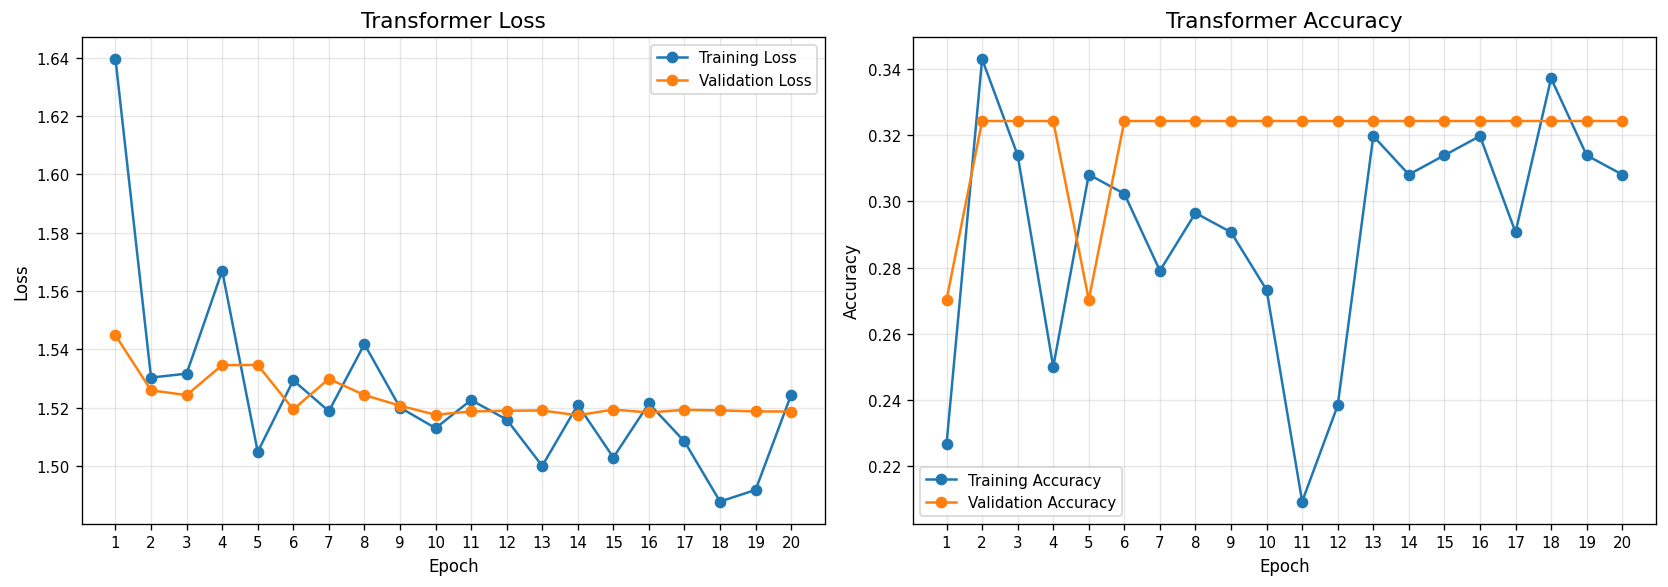


TRAINING COMPLETED
Completed epochs: 20
Best validation epoch: 14
Best validation loss: 1.5174
Average epoch time: 3.55 seconds
Total training time: 1.18 minutes

Saved files:
/content/BBC_Urdu_NLP_Assignment2/part3_transformer_topic_classification/part3_transformer_best.pth
/content/BBC_Urdu_NLP_Assignment2/part3_transformer_topic_classification/part3_transformer_training_history.csv
/content/BBC_Urdu_NLP_Assignment2/part3_transformer_topic_classification/part3_transformer_learning_curves.png

All training checks PASSED.


In [86]:

# ============================================================
# FINAL PATCH + TRANSFORMER TRAINING
# Robust CLS-only classifier correction
# ============================================================

import os
import time
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

# ------------------------------------------------------------
# 1. CONFIGURATION CHECK
# ------------------------------------------------------------

assert "model" in globals(), "Transformer model not found."
assert "train_loader" in globals(), "Training loader not found."
assert "val_loader" in globals(), "Validation loader not found."

device = next(model.parameters()).device

EPOCHS = 20
LEARNING_RATE = 5e-4
WEIGHT_DECAY = 0.01
WARMUP_STEPS = 50
NUM_CLASSES = 5

PART3_DIR = (
    "/content/BBC_Urdu_NLP_Assignment2/"
    "part3_transformer_topic_classification"
)
os.makedirs(PART3_DIR, exist_ok=True)

# ------------------------------------------------------------
# 2. PATCH CLASSIFIER TO USE CLS ONLY
# ------------------------------------------------------------

class CLSOnlyClassifier(nn.Module):

    def __init__(self, original_classifier):
        super().__init__()
        self.original_classifier = original_classifier

    def forward(self, x):

        # If all sequence positions are supplied,
        # select only the first position: CLS.
        if x.ndim == 3:
            x = x[:, 0, :]

        # If already CLS-only, leave it unchanged.
        assert x.ndim == 2, (
            f"Expected 2D CLS representation, got {x.shape}"
        )

        return self.original_classifier(x)


# Preserve the existing MLP classifier.
if not isinstance(model.classifier, CLSOnlyClassifier):
    model.classifier = CLSOnlyClassifier(
        model.classifier
    ).to(device)

# ------------------------------------------------------------
# 3. VERIFY OUTPUT SHAPE
# ------------------------------------------------------------

model.eval()

with torch.no_grad():
    sample_logits, sample_attention = model(
        X_train[:2].to(device),
        return_attention=True
    )

print("=" * 65)
print("MODEL OUTPUT VERIFICATION")
print("=" * 65)

print("Input shape:", tuple(X_train[:2].shape))
print("Corrected logits shape:", tuple(sample_logits.shape))
print("Attention shape:", tuple(sample_attention.shape))

assert sample_logits.shape == (2, NUM_CLASSES), (
    "CLS classifier correction failed."
)

print("\nCLS classifier correction PASSED.")

# ------------------------------------------------------------
# 4. OPTIMIZER AND SCHEDULER
# ------------------------------------------------------------

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

total_steps = EPOCHS * len(train_loader)

def lr_lambda(step):

    if step < WARMUP_STEPS:
        return float(step + 1) / WARMUP_STEPS

    progress = (
        step - WARMUP_STEPS
    ) / max(1, total_steps - WARMUP_STEPS)

    progress = min(progress, 1.0)

    return 0.5 * (
        1.0 + math.cos(math.pi * progress)
    )


scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda
)

# ------------------------------------------------------------
# 5. TRAINING FUNCTION
# ------------------------------------------------------------

def run_epoch(loader, training=False):

    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for batch_x, batch_y in loader:

        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):

            logits, _ = model(batch_x)

            # Final safeguard
            if logits.ndim == 3:
                logits = logits[:, 0, :]

            assert logits.shape == (
                batch_y.size(0), NUM_CLASSES
            ), f"Unexpected logits shape: {logits.shape}"

            loss = criterion(logits, batch_y)

            if training:
                loss.backward()
                optimizer.step()
                scheduler.step()

        batch_size = batch_y.size(0)

        total_loss += loss.item() * batch_size

        predictions = logits.argmax(dim=1)

        correct += (
            predictions == batch_y
        ).sum().item()

        total += batch_size

    return (
        total_loss / total,
        correct / total
    )


# ------------------------------------------------------------
# 6. TRAIN FOR 20 EPOCHS
# ------------------------------------------------------------

history = []

best_val_loss = float("inf")
best_epoch = 0

BEST_MODEL_FILE = os.path.join(
    PART3_DIR,
    "part3_transformer_best.pth"
)

print("\n" + "=" * 65)
print("TRANSFORMER TRAINING STARTED")
print("=" * 65)

for epoch in range(EPOCHS):

    start_time = time.time()

    train_loss, train_acc = run_epoch(
        train_loader, training=True
    )

    val_loss, val_acc = run_epoch(
        val_loader, training=False
    )

    epoch_time = time.time() - start_time

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "epoch_time_seconds": epoch_time
    })

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_epoch = epoch + 1

        torch.save(
            {
                "epoch": best_epoch,
                "model_state_dict": model.state_dict(),
                "best_val_loss": best_val_loss,
                "class_names": class_names,
                "vocab_size": VOCAB_SIZE,
                "pad_id": PAD_ID,
                "max_len": MAX_LEN
            },
            BEST_MODEL_FILE
        )

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Time: {epoch_time:.2f}s"
    )

# ------------------------------------------------------------
# 7. SAVE HISTORY
# ------------------------------------------------------------

history_df = pd.DataFrame(history)

history_file = os.path.join(
    PART3_DIR,
    "part3_transformer_training_history.csv"
)

history_df.to_csv(history_file, index=False)

# ------------------------------------------------------------
# 8. PLOT LEARNING CURVES
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Training Loss"
)

axes[0].plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation Loss"
)

axes[0].set_title("Transformer Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_xticks(range(1, EPOCHS + 1))
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(
    history_df["epoch"],
    history_df["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)

axes[1].plot(
    history_df["epoch"],
    history_df["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

axes[1].set_title("Transformer Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_xticks(range(1, EPOCHS + 1))
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()

curve_file = os.path.join(
    PART3_DIR,
    "part3_transformer_learning_curves.png"
)

plt.savefig(curve_file, dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 9. FINAL REPORT
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("TRAINING COMPLETED")
print("=" * 65)

print("Completed epochs:", len(history_df))
print("Best validation epoch:", best_epoch)
print(f"Best validation loss: {best_val_loss:.4f}")

print(
    "Average epoch time:",
    f"{history_df['epoch_time_seconds'].mean():.2f} seconds"
)

print(
    "Total training time:",
    f"{history_df['epoch_time_seconds'].sum() / 60:.2f} minutes"
)

print("\nSaved files:")
print(BEST_MODEL_FILE)
print(history_file)
print(curve_file)

assert len(history_df) == EPOCHS
assert os.path.exists(BEST_MODEL_FILE)

print("\nAll training checks PASSED.")


In [87]:
import inspect
import torch

print("=" * 65)
print("TRANSFORMER MODEL DIAGNOSTICS")
print("=" * 65)

# 1. Inspect the model's forward method
print("\n[1] MODEL FORWARD METHOD")
try:
    print(inspect.getsource(type(model).forward))
except Exception as e:
    print("Could not retrieve source:", e)

# 2. Inspect attention-related modules
print("\n[2] ATTENTION MODULES")

for name, module in model.named_modules():
    if "attention" in name.lower():
        print(f"\nModule: {name}")
        print("Class:", type(module).__name__)

        try:
            print(inspect.getsource(type(module).forward))
        except Exception as e:
            print("Source unavailable:", e)

# 3. Inspect encoder block structure
print("\n[3] MODEL MODULE STRUCTURE")

for name, module in model.named_children():
    print(name, "->", type(module).__name__)

# 4. Inspect attention output again
print("\n[4] RAW ATTENTION OUTPUT")

model.eval()

sample = torch.as_tensor(
    X_train[:2],
    dtype=torch.long,
    device=device
)

with torch.no_grad():
    output = model(sample, return_attention=True)

    if isinstance(output, tuple):
        logits, attention = output
        print("Logits:", tuple(logits.shape))

        if attention is not None:
            print("Attention:", tuple(attention.shape))
    else:
        print("Model output:", tuple(output.shape))

print("\nDIAGNOSTICS COMPLETED")

TRANSFORMER MODEL DIAGNOSTICS

[1] MODEL FORWARD METHOD
    def forward(self, input_ids, return_attention=False):

        batch_size = input_ids.size(0)

        x = self.token_embedding(input_ids)

        cls = self.cls_token.expand(
            batch_size, -1, -1
        )

        x = torch.cat([cls, x], dim=1)

        token_mask = input_ids.ne(self.pad_id)

        cls_mask = torch.ones(
            batch_size, 1,
            dtype=torch.bool,
            device=input_ids.device
        )

        key_mask = torch.cat(
            [cls_mask, token_mask], dim=1
        )

        x = self.position_encoding(x)

        final_attention = None

        for index, encoder in enumerate(self.encoder_layers):

            x, attention_weights = encoder(
                x, key_mask
            )

            if index == len(self.encoder_layers) - 1:
                final_attention = attention_weights

        # CORRECT: extract CLS only.
        cls_representation = x[:, 0, :]

        #

In [91]:
import torch

print("=" * 65)
print("CLEANING OLD DIAGNOSTIC HOOKS")
print("=" * 65)

# Remove stale diagnostic hooks from every model module
for module in model.modules():
    module._forward_hooks.clear()
    module._forward_pre_hooks.clear()

print("Old hooks removed.")

# --------------------------------------------------
# Register fresh diagnostic hooks
# --------------------------------------------------

hooks = []

def pre_hook(name):
    def hook(module, inputs):
        print(f"\n{name}")
        for i, value in enumerate(inputs):
            if torch.is_tensor(value):
                print(f"  Input {i}: {tuple(value.shape)}")
    return hook


def output_hook(name):
    def hook(module, inputs, output):
        print(f"\n{name}")

        if torch.is_tensor(output):
            print("  Output:", tuple(output.shape))

        elif isinstance(output, (tuple, list)):
            for i, value in enumerate(output):
                if torch.is_tensor(value):
                    print(f"  Output {i}: {tuple(value.shape)}")

    return hook


# Trace first encoder layer only
attn = model.encoder_layers[0].attention

hooks.append(
    attn.register_forward_pre_hook(
        pre_hook("MULTIHEAD ATTENTION INPUT")
    )
)

hooks.append(
    attn.attention.register_forward_pre_hook(
        pre_hook("SCALED DOT-PRODUCT INPUT")
    )
)

hooks.append(
    attn.attention.register_forward_hook(
        output_hook("SCALED DOT-PRODUCT OUTPUT")
    )
)

for h in range(attn.num_heads):
    for name in ["query_layers", "key_layers", "value_layers"]:
        layer = getattr(attn, name)[h]

        hooks.append(
            layer.register_forward_hook(
                output_hook(f"{name} HEAD {h}")
            )
        )

# --------------------------------------------------
# One forward pass; no training
# --------------------------------------------------

model.eval()

sample = torch.as_tensor(
    X_train[:2],
    dtype=torch.long,
    device=device
)

try:
    with torch.no_grad():
        logits, attention = model(
            sample,
            return_attention=True
        )

    print("\nFINAL LOGITS:", tuple(logits.shape))
    print("FINAL ATTENTION:", tuple(attention.shape))

finally:
    for hook in hooks:
        hook.remove()

print("\nDIAGNOSTIC COMPLETED")

CLEANING OLD DIAGNOSTIC HOOKS
Old hooks removed.

MULTIHEAD ATTENTION INPUT
  Input 0: (2, 257, 128)
  Input 1: (2, 257)

query_layers HEAD 0
  Output: (2, 257, 32)

key_layers HEAD 0
  Output: (2, 257, 32)

value_layers HEAD 0
  Output: (2, 257, 32)

SCALED DOT-PRODUCT INPUT
  Input 0: (2, 257, 32)
  Input 1: (2, 257, 32)
  Input 2: (2, 257, 32)
  Input 3: (2, 257)

SCALED DOT-PRODUCT OUTPUT
  Output 0: (2, 2, 257, 32)
  Output 1: (2, 2, 257, 257)

query_layers HEAD 1
  Output: (2, 257, 32)

key_layers HEAD 1
  Output: (2, 257, 32)

value_layers HEAD 1
  Output: (2, 257, 32)

SCALED DOT-PRODUCT INPUT
  Input 0: (2, 257, 32)
  Input 1: (2, 257, 32)
  Input 2: (2, 257, 32)
  Input 3: (2, 257)

SCALED DOT-PRODUCT OUTPUT
  Output 0: (2, 2, 257, 32)
  Output 1: (2, 2, 257, 257)

query_layers HEAD 2
  Output: (2, 257, 32)

key_layers HEAD 2
  Output: (2, 257, 32)

value_layers HEAD 2
  Output: (2, 257, 32)

SCALED DOT-PRODUCT INPUT
  Input 0: (2, 257, 32)
  Input 1: (2, 257, 32)
  Input 2: 

In [92]:
import torch
import types
import math

# Correct scaled dot-product attention
def corrected_attention_forward(self, Q, K, V, key_mask=None):

    scores = torch.matmul(
        Q, K.transpose(-2, -1)
    ) / math.sqrt(Q.size(-1))

    if key_mask is not None:
        # CORRECT MASK: (batch, 1, sequence)
        scores = scores.masked_fill(
            ~key_mask[:, None, :],
            -1e9
        )

    weights = torch.softmax(scores, dim=-1)

    output = torch.matmul(
        self.dropout(weights), V
    )

    return output, weights


# Patch attention in all encoder layers
for encoder in model.encoder_layers:
    encoder.attention.attention.forward = types.MethodType(
        corrected_attention_forward,
        encoder.attention.attention
    )

print("Corrected attention mask applied to all encoder layers.")

# Verify the corrected architecture
model.eval()

sample = torch.as_tensor(
    X_train[:2],
    dtype=torch.long,
    device=device
)

with torch.no_grad():
    logits, attention = model(
        sample,
        return_attention=True
    )

print("\nCorrected logits shape:", tuple(logits.shape))
print("Corrected attention shape:", tuple(attention.shape))

assert logits.shape == (2, 5)
assert attention.shape == (2, 4, 257, 257)

print("\nSUCCESS: Attention dimensions are now correct.")

Corrected attention mask applied to all encoder layers.

Corrected logits shape: (2, 5)
Corrected attention shape: (2, 4, 257, 257)

SUCCESS: Attention dimensions are now correct.


In [93]:
import os
import shutil
import torch

OUTPUT_DIR = (
    "/content/BBC_Urdu_NLP_Assignment2/"
    "part3_transformer_topic_classification"
)

# Preserve previous debugging-run files
for filename in [
    "part3_transformer_best.pth",
    "part3_transformer_training_history.csv",
    "part3_transformer_learning_curves.png"
]:
    source = os.path.join(OUTPUT_DIR, filename)

    if os.path.exists(source):
        backup = os.path.join(
            OUTPUT_DIR,
            filename.replace(
                ".pth", "_debug_run.pth"
            ).replace(
                ".csv", "_debug_run.csv"
            ).replace(
                ".png", "_debug_run.png"
            )
        )
        shutil.copy2(source, backup)
        print("Preserved:", backup)

# Reset all trainable module parameters
def reset_module_parameters(module):
    if hasattr(module, "reset_parameters"):
        module.reset_parameters()

model.apply(reset_module_parameters)

# Reinitialize the learned CLS token
with torch.no_grad():
    torch.nn.init.normal_(model.cls_token, mean=0.0, std=0.02)

print("\nModel weights freshly initialized.")
print("Corrected attention mask remains applied.")
print("Ready for final training.")

Preserved: /content/BBC_Urdu_NLP_Assignment2/part3_transformer_topic_classification/part3_transformer_best_debug_run.pth
Preserved: /content/BBC_Urdu_NLP_Assignment2/part3_transformer_topic_classification/part3_transformer_training_history_debug_run.csv
Preserved: /content/BBC_Urdu_NLP_Assignment2/part3_transformer_topic_classification/part3_transformer_learning_curves_debug_run.png

Model weights freshly initialized.
Corrected attention mask remains applied.
Ready for final training.


Training samples: 172
Validation samples: 37
Training batches: 11
Model output verified: torch.Size([2, 5])
Epoch [01/20] Train Loss: 1.5747 | Train Acc: 0.2907 | Val Loss: 1.5218 | Val Acc: 0.3243 | Time: 0.73s
Epoch [02/20] Train Loss: 1.5036 | Train Acc: 0.3023 | Val Loss: 1.5258 | Val Acc: 0.3243 | Time: 0.74s
Epoch [03/20] Train Loss: 1.5181 | Train Acc: 0.3256 | Val Loss: 1.5289 | Val Acc: 0.3243 | Time: 0.71s
Epoch [04/20] Train Loss: 1.5497 | Train Acc: 0.2674 | Val Loss: 1.5220 | Val Acc: 0.2703 | Time: 0.69s
Epoch [05/20] Train Loss: 1.5214 | Train Acc: 0.3198 | Val Loss: 1.5201 | Val Acc: 0.3243 | Time: 0.70s
Epoch [06/20] Train Loss: 1.5103 | Train Acc: 0.3140 | Val Loss: 1.5253 | Val Acc: 0.3514 | Time: 0.64s
Epoch [07/20] Train Loss: 1.5169 | Train Acc: 0.3198 | Val Loss: 1.5284 | Val Acc: 0.2703 | Time: 0.66s
Epoch [08/20] Train Loss: 1.5025 | Train Acc: 0.3256 | Val Loss: 1.5185 | Val Acc: 0.3243 | Time: 1.30s
Epoch [09/20] Train Loss: 1.4973 | Train Acc: 0.3488 | Val L

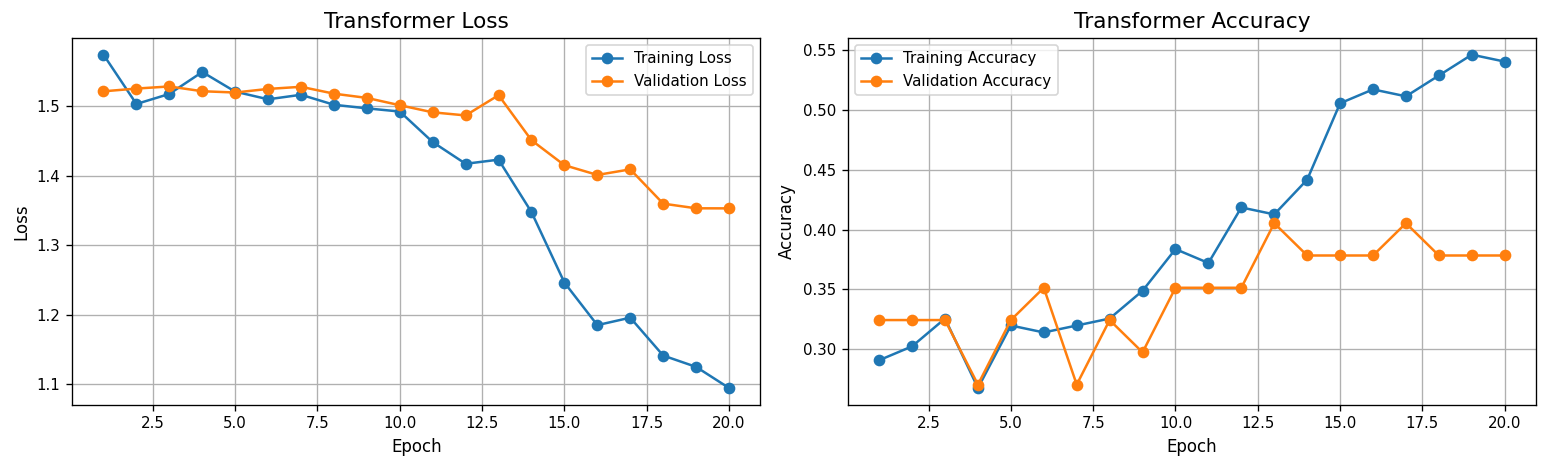


========== CORRECTED TRAINING SUMMARY ==========
Best validation epoch: 20
Best validation loss: 1.3531
Best epoch validation accuracy: 0.3784
Average epoch time: 0.80 seconds
Total training time: 0.28 minutes

Saved corrected checkpoint and training history.
Output directory: /content/BBC_Urdu_NLP_Assignment2/part3_transformer_topic_classification


In [95]:

import os
import math
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import LambdaLR

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------
SEED = 42
EPOCHS = 20
BATCH_SIZE = 16
LEARNING_RATE = 5e-4
WEIGHT_DECAY = 0.01
WARMUP_STEPS = 50

torch.manual_seed(SEED)
np.random.seed(SEED)

OUTPUT_DIR = (
    "/content/BBC_Urdu_NLP_Assignment2/"
    "part3_transformer_topic_classification"
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

# --------------------------------------------------
# 2. Prepare datasets
# --------------------------------------------------
Xtr = torch.as_tensor(np.asarray(X_train), dtype=torch.long)
Ytr = torch.as_tensor(np.asarray(y_train), dtype=torch.long)

Xva = torch.as_tensor(np.asarray(X_val), dtype=torch.long)
Yva = torch.as_tensor(np.asarray(y_val), dtype=torch.long)

train_loader = DataLoader(
    TensorDataset(Xtr, Ytr),
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    TensorDataset(Xva, Yva),
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training samples:", len(Xtr))
print("Validation samples:", len(Xva))
print("Training batches:", len(train_loader))

# --------------------------------------------------
# 3. Move model to device
# --------------------------------------------------
model = model.to(device)

# Verify model output before training
model.eval()
with torch.no_grad():
    test_logits = model(Xtr[:2].to(device))

    if isinstance(test_logits, tuple):
        test_logits = test_logits[0]

assert test_logits.shape == (2, 5), (
    f"Unexpected model output: {test_logits.shape}"
)

print("Model output verified:", test_logits.shape)

# --------------------------------------------------
# 4. Optimizer and warmup + cosine scheduler
# --------------------------------------------------
criterion = nn.CrossEntropyLoss()

optimizer = AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

total_steps = EPOCHS * len(train_loader)

def lr_lambda(current_step):
    if current_step < WARMUP_STEPS:
        return float(current_step + 1) / float(WARMUP_STEPS)

    progress = (
        current_step - WARMUP_STEPS
    ) / max(1, total_steps - WARMUP_STEPS)

    progress = min(progress, 1.0)

    return 0.5 * (1.0 + math.cos(math.pi * progress))

scheduler = LambdaLR(optimizer, lr_lambda)

# --------------------------------------------------
# 5. Training and validation functions
# --------------------------------------------------
def run_epoch(loader, training=True):

    model.train() if training else model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    context = torch.enable_grad() if training else torch.no_grad()

    with context:
        for batch_inputs, batch_labels in loader:

            batch_inputs = batch_inputs.to(device)
            batch_labels = batch_labels.to(device)

            if training:
                optimizer.zero_grad()

            logits = model(batch_inputs)

            if isinstance(logits, tuple):
                logits = logits[0]

            assert logits.shape == (
                batch_inputs.size(0), 5
            ), f"Unexpected logits shape: {logits.shape}"

            loss = criterion(logits, batch_labels)

            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(
                    model.parameters(), max_norm=1.0
                )
                optimizer.step()
                scheduler.step()

            predictions = torch.argmax(logits, dim=1)

            total_loss += loss.item() * batch_labels.size(0)
            total_correct += (
                predictions == batch_labels
            ).sum().item()

            total_samples += batch_labels.size(0)

    return (
        total_loss / total_samples,
        total_correct / total_samples
    )

# --------------------------------------------------
# 6. Train for 20 epochs
# --------------------------------------------------
history = []
best_val_loss = float("inf")
best_epoch = 0

training_start = time.time()

for epoch in range(EPOCHS):

    epoch_start = time.time()

    train_loss, train_acc = run_epoch(
        train_loader, training=True
    )

    val_loss, val_acc = run_epoch(
        val_loader, training=False
    )

    epoch_time = time.time() - epoch_start

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "epoch_time_seconds": epoch_time
    })

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1

        torch.save(
            model.state_dict(),
            os.path.join(
                OUTPUT_DIR,
                "part3_transformer_best_corrected.pth"
            )
        )

    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Time: {epoch_time:.2f}s"
    )

total_time = time.time() - training_start

# --------------------------------------------------
# 7. Save training history
# --------------------------------------------------
history_df = pd.DataFrame(history)

history_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "part3_transformer_training_history_corrected.csv"
    ),
    index=False
)

# --------------------------------------------------
# 8. Plot training and validation curves
# --------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Training Loss"
)
axes[0].plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation Loss"
)
axes[0].set_title("Transformer Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    history_df["epoch"],
    history_df["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)
axes[1].plot(
    history_df["epoch"],
    history_df["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)
axes[1].set_title("Transformer Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "part3_transformer_learning_curves_corrected.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------
# 9. Final training summary
# --------------------------------------------------
print("\n========== CORRECTED TRAINING SUMMARY ==========")
print("Best validation epoch:", best_epoch)
print(f"Best validation loss: {best_val_loss:.4f}")
print(
    f"Best epoch validation accuracy: "
    f"{history_df.loc[best_epoch-1, 'val_accuracy']:.4f}"
)
print(
    f"Average epoch time: "
    f"{history_df['epoch_time_seconds'].mean():.2f} seconds"
)
print(f"Total training time: {total_time/60:.2f} minutes")

print("\nSaved corrected checkpoint and training history.")
print("Output directory:", OUTPUT_DIR)



========== TEST SET RESULTS ==========
Test samples: 37
Test Accuracy: 0.5676
Test Macro-F1: 0.2815

Classification Report:
                  precision    recall  f1-score   support

         Economy       0.62      0.91      0.74        11
Health & Society       0.00      0.00      0.00         3
   International       0.00      0.00      0.00         4
        Politics       0.00      0.00      0.00         7
          Sports       0.52      0.92      0.67        12

        accuracy                           0.57        37
       macro avg       0.23      0.37      0.28        37
    weighted avg       0.36      0.57      0.44        37



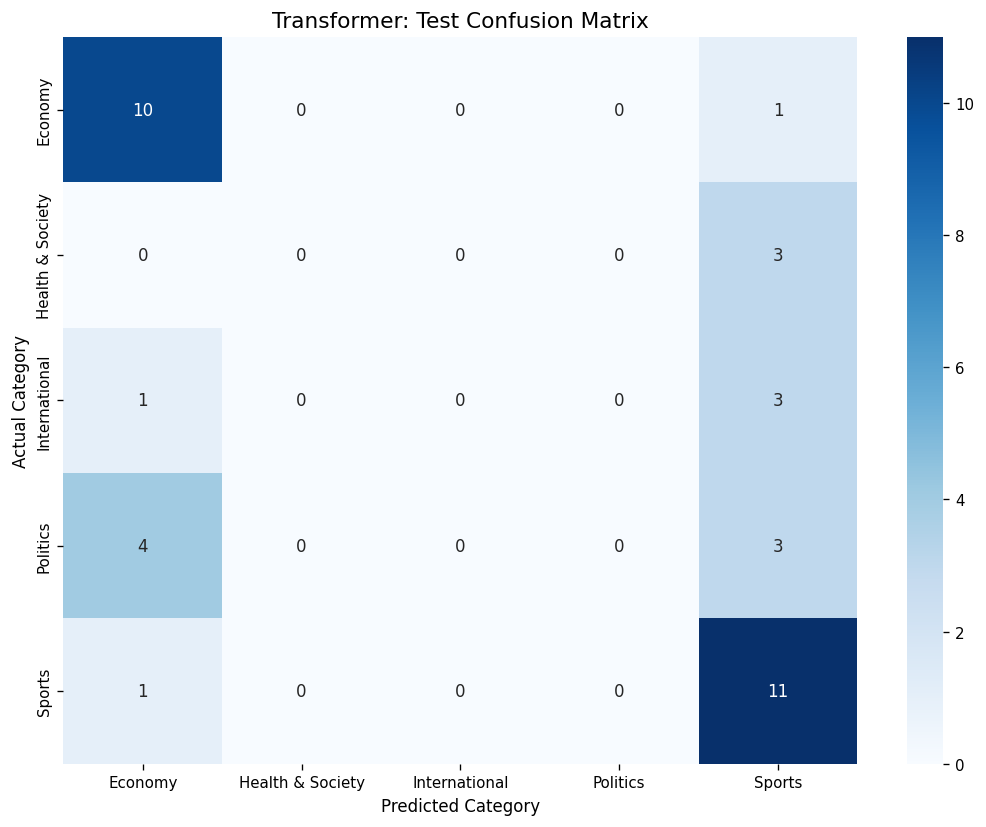


Test evaluation files saved.


In [96]:

import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

OUTPUT_DIR = (
    "/content/BBC_Urdu_NLP_Assignment2/"
    "part3_transformer_topic_classification"
)

CHECKPOINT = os.path.join(
    OUTPUT_DIR,
    "part3_transformer_best_corrected.pth"
)

# --------------------------------------------------
# 1. Load best corrected checkpoint
# --------------------------------------------------
checkpoint = torch.load(
    CHECKPOINT,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint)
model = model.to(device)
model.eval()

# --------------------------------------------------
# 2. Prepare test data
# --------------------------------------------------
Xte = torch.as_tensor(
    np.asarray(X_test),
    dtype=torch.long
).to(device)

Yte = torch.as_tensor(
    np.asarray(y_test),
    dtype=torch.long
).cpu().numpy()

# --------------------------------------------------
# 3. Generate predictions
# --------------------------------------------------
all_predictions = []

with torch.no_grad():
    for start in range(0, len(Xte), 16):
        batch = Xte[start:start+16]

        logits = model(batch)

        if isinstance(logits, tuple):
            logits = logits[0]

        predictions = torch.argmax(logits, dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )

y_pred = np.asarray(all_predictions)

# --------------------------------------------------
# 4. Calculate evaluation metrics
# --------------------------------------------------
test_accuracy = accuracy_score(Yte, y_pred)

test_macro_f1 = f1_score(
    Yte,
    y_pred,
    average="macro",
    zero_division=0
)

print("\n========== TEST SET RESULTS ==========")
print("Test samples:", len(Yte))
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Macro-F1: {test_macro_f1:.4f}")

# --------------------------------------------------
# 5. Class names
# --------------------------------------------------
# LabelEncoder normally orders these alphabetically.
# Verify this mapping against your label-encoding cell.
class_names = [
    "Economy",
    "Health & Society",
    "International",
    "Politics",
    "Sports"
]

print("\nClassification Report:")
print(
    classification_report(
        Yte,
        y_pred,
        labels=[0, 1, 2, 3, 4],
        target_names=class_names,
        zero_division=0
    )
)

# --------------------------------------------------
# 6. Confusion matrix
# --------------------------------------------------
cm = confusion_matrix(
    Yte,
    y_pred,
    labels=[0, 1, 2, 3, 4]
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Transformer: Test Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "part3_transformer_confusion_matrix.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------
# 7. Save test predictions and metrics
# --------------------------------------------------
results = pd.DataFrame({
    "actual_label": Yte,
    "predicted_label": y_pred,
    "correct": Yte == y_pred
})

results.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "part3_transformer_test_predictions.csv"
    ),
    index=False
)

pd.DataFrame([{
    "test_accuracy": test_accuracy,
    "test_macro_f1": test_macro_f1,
    "test_samples": len(Yte)
}]).to_csv(
    os.path.join(
        OUTPUT_DIR,
        "part3_transformer_test_metrics.csv"
    ),
    index=False
)

print("\nTest evaluation files saved.")


                  precision    recall  f1-score   support

        Politics       0.62      0.91      0.74        11
          Sports       0.00      0.00      0.00         3
         Economy       0.00      0.00      0.00         4
   International       0.00      0.00      0.00         7
Health & Society       0.52      0.92      0.67        12

        accuracy                           0.57        37
       macro avg       0.23      0.37      0.28        37
    weighted avg       0.36      0.57      0.44        37



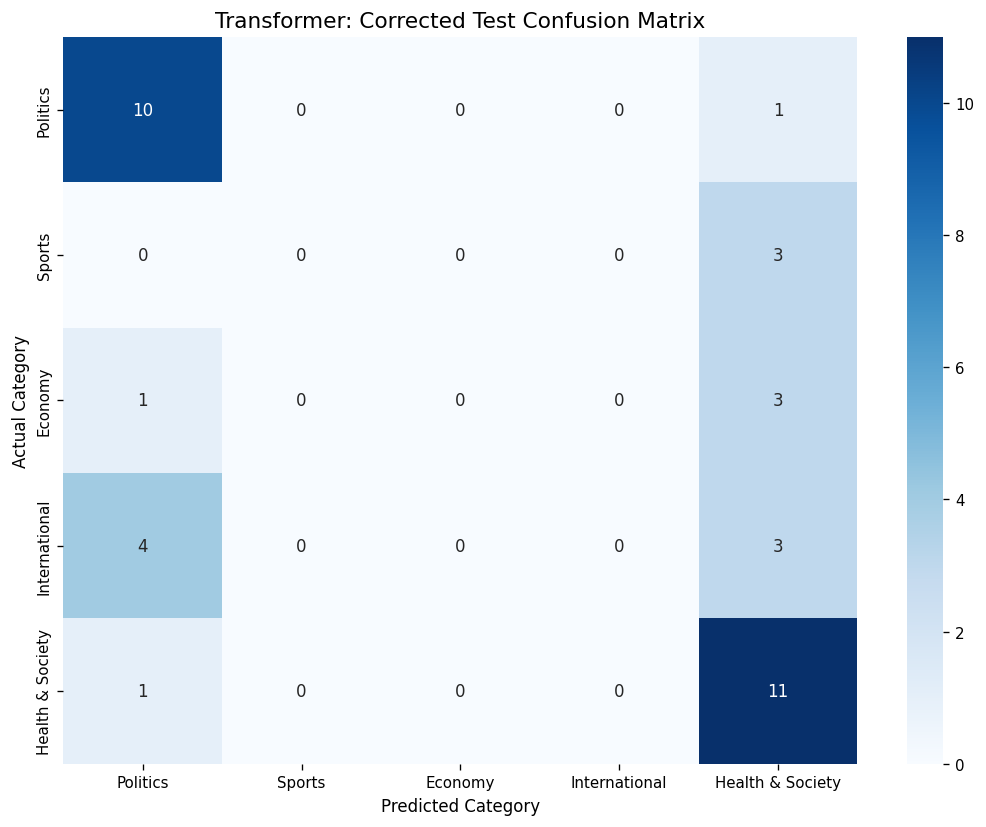

In [97]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns
import os

class_names = [
    "Politics",
    "Sports",
    "Economy",
    "International",
    "Health & Society"
]

print(classification_report(
    Yte,
    y_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(
    Yte,
    y_pred,
    labels=[0, 1, 2, 3, 4]
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Transformer: Corrected Test Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "part3_transformer_confusion_matrix_corrected.png"
    ),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


Selected test article indices: [2, 3, 4]


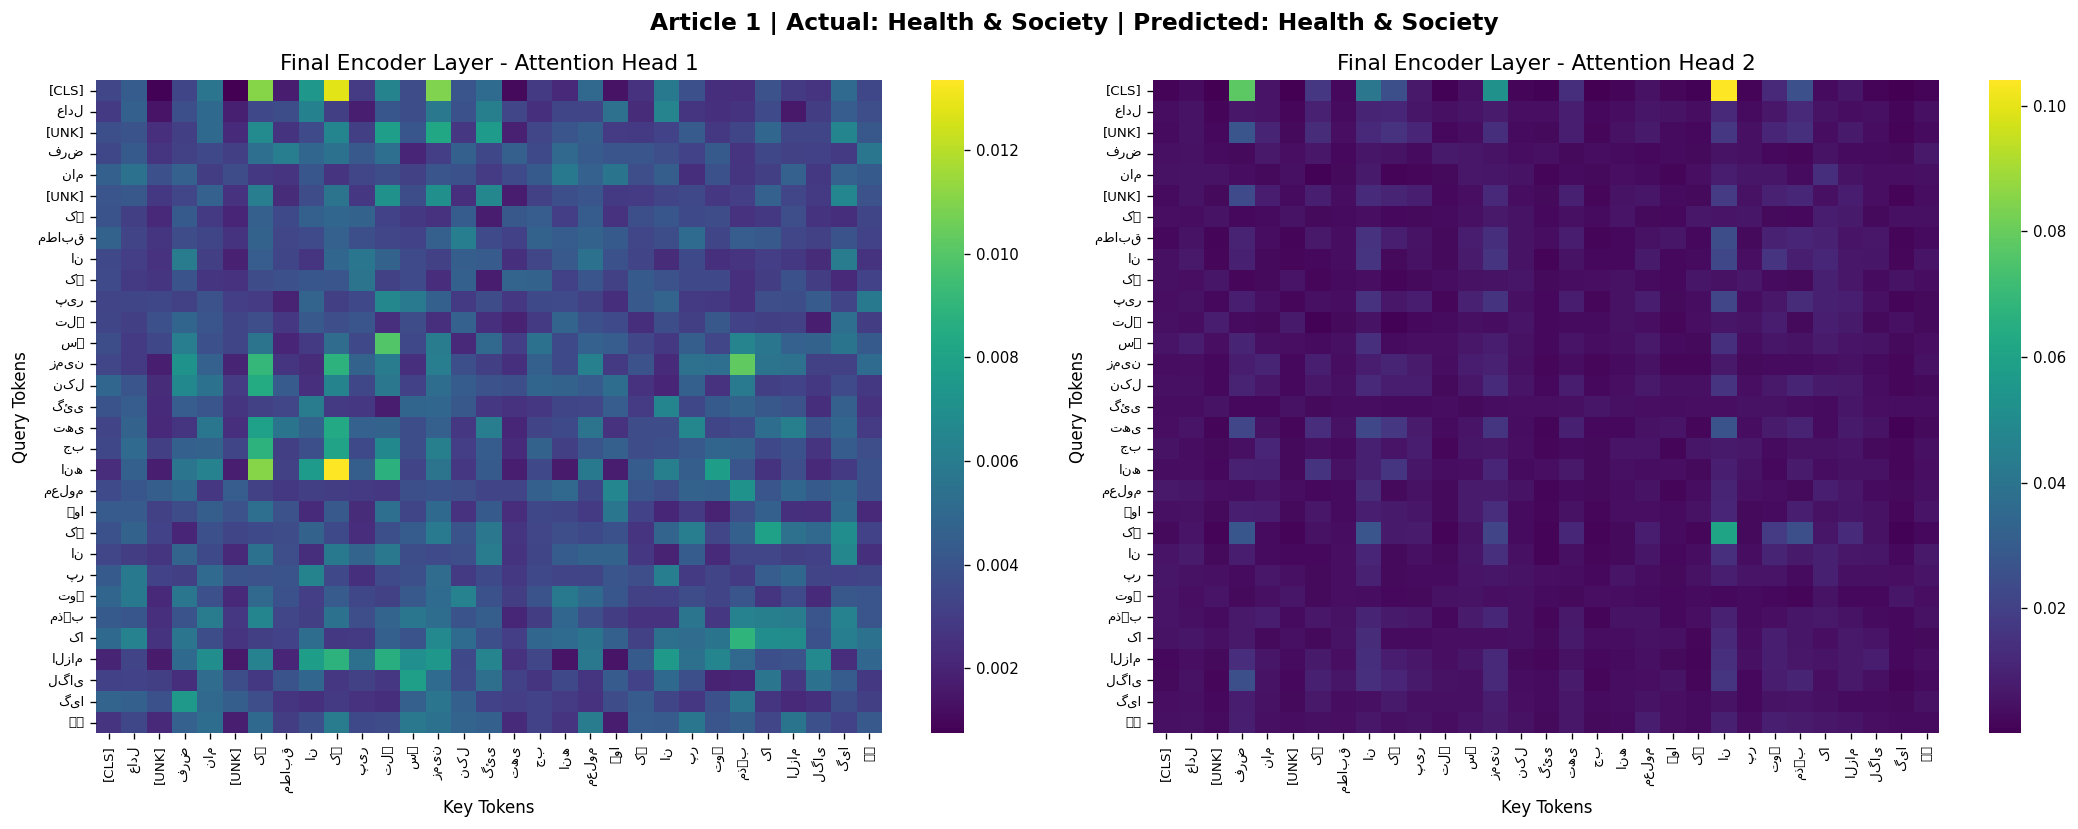


Article 1
Actual category: Health & Society
Predicted category: Health & Society
Tokens shown: 30
Attention heatmap saved: /content/BBC_Urdu_NLP_Assignment2/part3_transformer_topic_classification/part3_attention_article_1.png
Token sequence:
عادل [UNK] فرض نام [UNK] کے مطابق ان کے پیر تلے سے زمین نکل گئی تھی جب انھ معلوم ہوا کہ ان پر توہ مذہب کا الزام لگای گیا ہے
----------------------------------------------------------------------


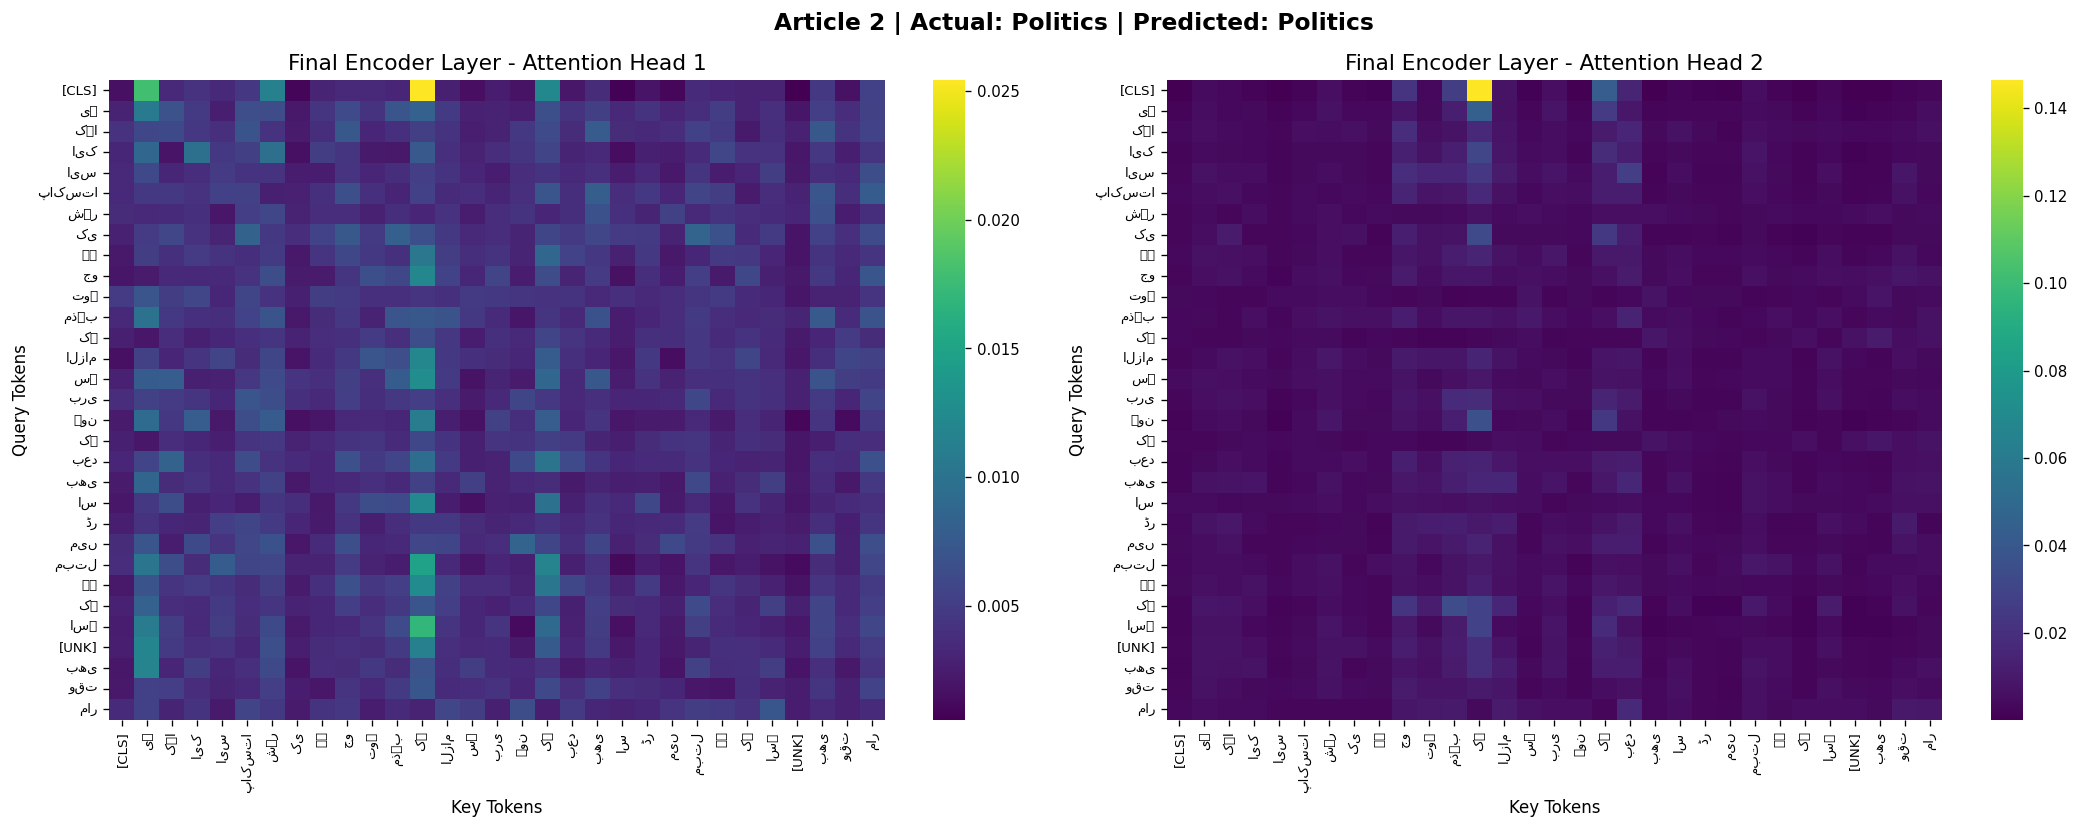


Article 2
Actual category: Politics
Predicted category: Politics
Tokens shown: 30
Attention heatmap saved: /content/BBC_Urdu_NLP_Assignment2/part3_transformer_topic_classification/part3_attention_article_2.png
Token sequence:
یہ کہا ایک ایس پاکستا شہر کی ہے جو توہ مذہب کے الزام سے بری ہون کے بعد بھی اس ڈر میں مبتل ہے کہ اسے [UNK] بھی وقت مار
----------------------------------------------------------------------


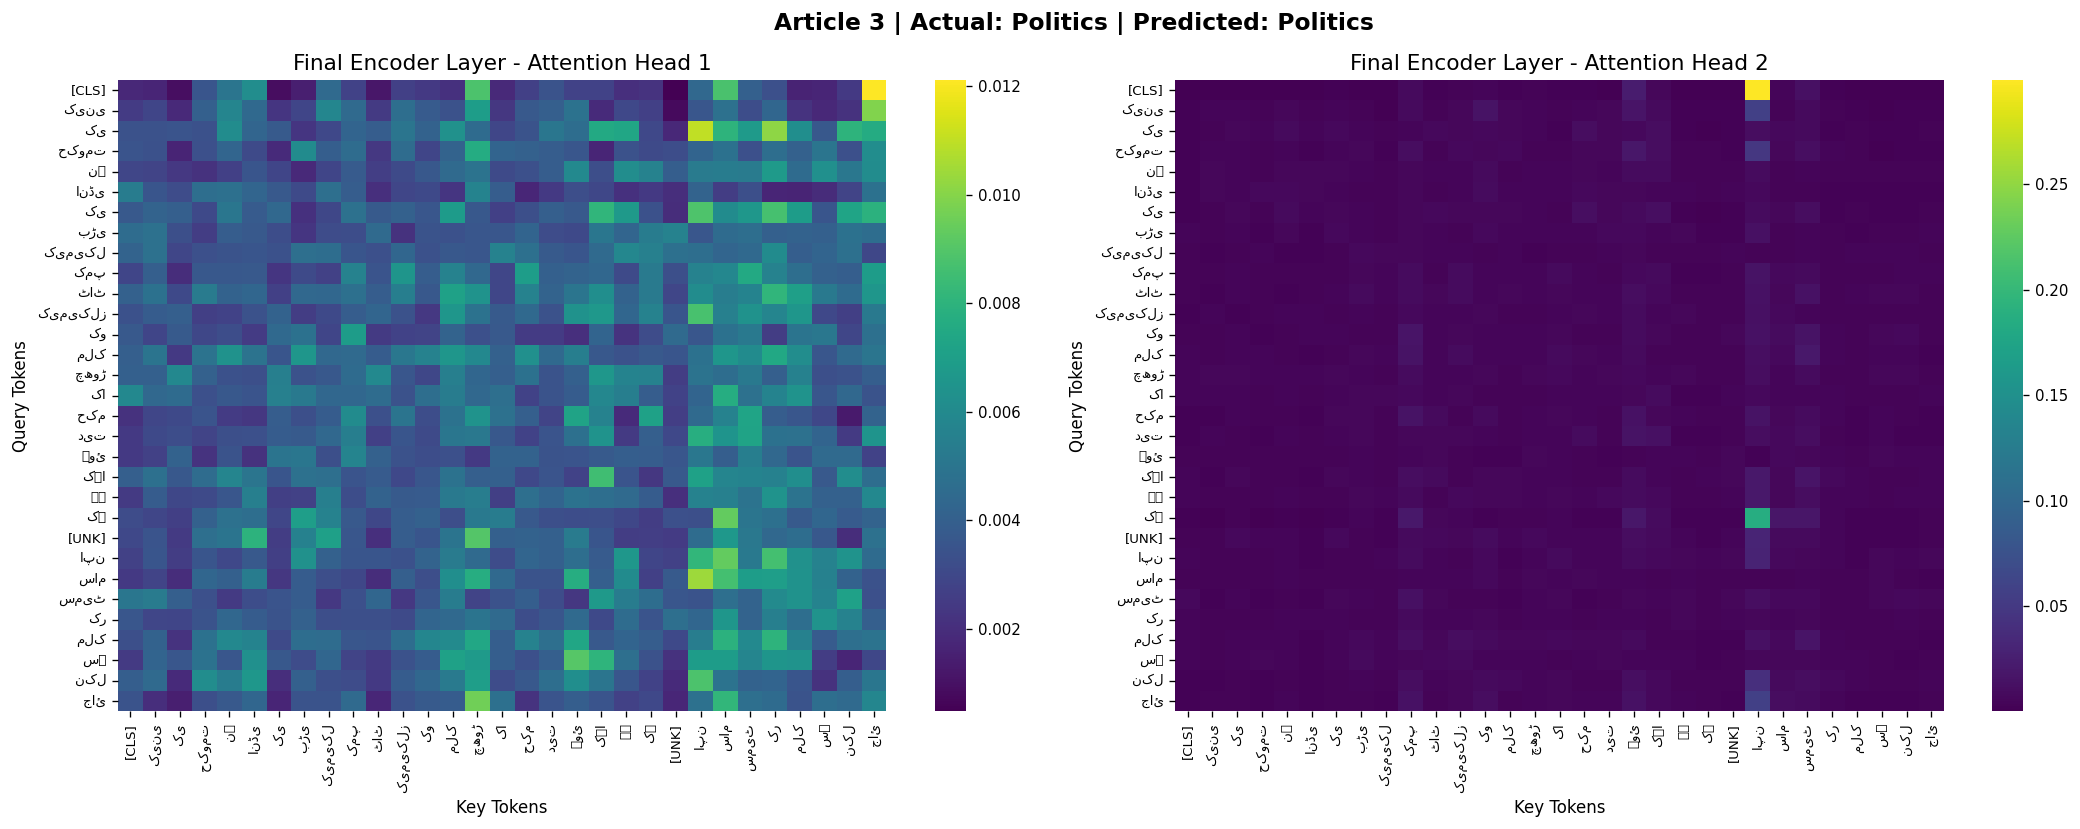


Article 3
Actual category: Politics
Predicted category: Politics
Tokens shown: 30
Attention heatmap saved: /content/BBC_Urdu_NLP_Assignment2/part3_transformer_topic_classification/part3_attention_article_3.png
Token sequence:
کینی کی حکومت نے انڈی کی بڑی کیمیکل کمپ ٹاٹ کیمیکلز کو ملک چھوڑ کا حکم دیت ہوئ کہا ہے کہ [UNK] اپن سام سمیٹ کر ملک سے نکل جائ
----------------------------------------------------------------------

All three attention visualizations generated.


In [98]:

import os
import json
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns

OUTPUT_DIR = (
    "/content/BBC_Urdu_NLP_Assignment2/"
    "part3_transformer_topic_classification"
)

VOCAB_PATH = (
    "/content/BBC_Urdu_NLP_Assignment2/"
    "part1_word2vec/C3_cleaned_d100/vocabulary.json"
)

class_names = [
    "Politics",
    "Sports",
    "Economy",
    "International",
    "Health & Society"
]

# --------------------------------------------------
# 1. Load vocabulary and create reverse mapping
# --------------------------------------------------
with open(VOCAB_PATH, "r", encoding="utf-8") as f:
    vocabulary = json.load(f)

id_to_token = {
    int(token_id): token
    for token, token_id in vocabulary.items()
}

PAD_ID = 11124
MAX_TOKENS_TO_DISPLAY = 30

# --------------------------------------------------
# 2. Select three correctly classified test articles
# --------------------------------------------------
correct_indices = np.where(Yte == y_pred)[0]

if len(correct_indices) < 3:
    raise ValueError(
        "Fewer than three correctly classified articles."
    )

# Prefer different correctly predicted categories
selected_indices = []
selected_categories = set()

for idx in correct_indices:
    category = int(Yte[idx])

    if category not in selected_categories:
        selected_indices.append(int(idx))
        selected_categories.add(category)

    if len(selected_indices) == 3:
        break

# If fewer than three categories were correctly predicted,
# fill the remaining slots with other correct articles.
for idx in correct_indices:
    if len(selected_indices) == 3:
        break

    if int(idx) not in selected_indices:
        selected_indices.append(int(idx))

print("Selected test article indices:", selected_indices)

# --------------------------------------------------
# 3. Extract final-layer attention and plot heatmaps
# --------------------------------------------------
model.eval()

for plot_number, idx in enumerate(selected_indices, start=1):

    input_ids = torch.as_tensor(
        np.asarray(X_test[idx:idx+1]),
        dtype=torch.long,
        device=device
    )

    with torch.no_grad():
        output = model(
            input_ids,
            return_attention=True
        )

    logits, attention = output

    if attention.ndim != 4:
        raise ValueError(
            f"Expected attention shape (B, heads, 257, 257), "
            f"received {attention.shape}"
        )

    # Attention from the final encoder layer:
    # (heads, 257, 257)
    final_attention = attention[0].detach().cpu().numpy()

    if final_attention.shape[0] < 2:
        raise ValueError("At least two attention heads are required.")

    # Convert input IDs into readable tokens
    token_ids = input_ids[0].detach().cpu().tolist()

    if PAD_ID in token_ids:
        token_count = token_ids.index(PAD_ID)
    else:
        token_count = len(token_ids)

    token_count = min(
        token_count,
        MAX_TOKENS_TO_DISPLAY
    )

    tokens = [
        id_to_token.get(token_ids[i], "[UNK]")
        for i in range(token_count)
    ]

    # Include CLS as position zero
    display_tokens = ["[CLS]"] + tokens

    # Extract CLS + actual token positions
    attention_size = token_count + 1

    fig, axes = plt.subplots(
        1, 2,
        figsize=(18, 7)
    )

    for plot_axis, head_index in zip(axes, [0, 1]):

        attention_matrix = final_attention[
            head_index,
            :attention_size,
            :attention_size
        ]

        sns.heatmap(
            attention_matrix,
            ax=plot_axis,
            cmap="viridis",
            xticklabels=display_tokens,
            yticklabels=display_tokens,
            cbar=True
        )

        plot_axis.set_title(
            f"Final Encoder Layer - Attention Head {head_index + 1}"
        )
        plot_axis.set_xlabel("Key Tokens")
        plot_axis.set_ylabel("Query Tokens")
        plot_axis.tick_params(
            axis="x",
            labelrotation=90,
            labelsize=8
        )
        plot_axis.tick_params(
            axis="y",
            labelrotation=0,
            labelsize=8
        )

    true_label = class_names[int(Yte[idx])]
    predicted_label = class_names[int(y_pred[idx])]

    fig.suptitle(
        f"Article {plot_number} | "
        f"Actual: {true_label} | "
        f"Predicted: {predicted_label}",
        fontsize=14,
        fontweight="bold"
    )

    plt.tight_layout()

    save_path = os.path.join(
        OUTPUT_DIR,
        f"part3_attention_article_{plot_number}.png"
    )

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print(f"\nArticle {plot_number}")
    print("Actual category:", true_label)
    print("Predicted category:", predicted_label)
    print("Tokens shown:", token_count)
    print("Attention heatmap saved:", save_path)
    print("Token sequence:")
    print(" ".join(tokens))
    print("-" * 70)

print("\nAll three attention visualizations generated.")


ARTICLE 03
Test-set index: 4
Actual category: Politics
Predicted category: Politics
Correctly classified: True

Logits shape: (1, 5)
Attention shape: (1, 4, 257, 257)

Full article token count: 256
Article 03 token sequence:
کینی کی حکومت نے انڈی کی بڑی کیمیکل کمپ ٹاٹ کیمیکلز کو ملک چھوڑ کا حکم دیت ہوئ کہا ہے کہ [UNK] اپن سام سمیٹ کر ملک سے نکل جائ ۔ [UNK] کینی کی حکومت کا مؤقف ہے کہ کمپ مقام صنعت اور روزگار کے فروغ میں مطلوب کردار ادا نہیں کر سکی ۔ کینی کے صدر ولیم روٹو کے مطابق کمپ سوڈ ایش کو مقام سطح پر پراسیس کر کے شیش اور دیگر کیمیکل بنا کے بجائ اسے برآمد کر رہی تھی ۔ صدر روٹو کے مطابق [UNK] نے کمپ کی جگہ لین کے لیے نئے سرمای کار ڈھونڈ لیے ہیں ۔ ان کے مطابق اس سے کینی میں روزگار کے مزید مواقع پید ہوں گے اور سرمای کار بڑھ گی ۔ [UNK] دوسر جانب ٹاٹ کیمیکلز نے کہا ہے کہ وہ حکومت کے فیصل کا احترام کرت ہے اور باق معامل کے حل کے لیے [UNK] قانو اور ریگولیٹر طریق کار کے تحت تعمیر [UNK] کے لیے پرعزم ہے ۔ [UNK] صدر روٹو نے یہ تبصر کاجیادو کاؤنٹ کے دور کے دور کیے ، جہاں ٹاٹ کیمیکلز مگاڈ کا پل

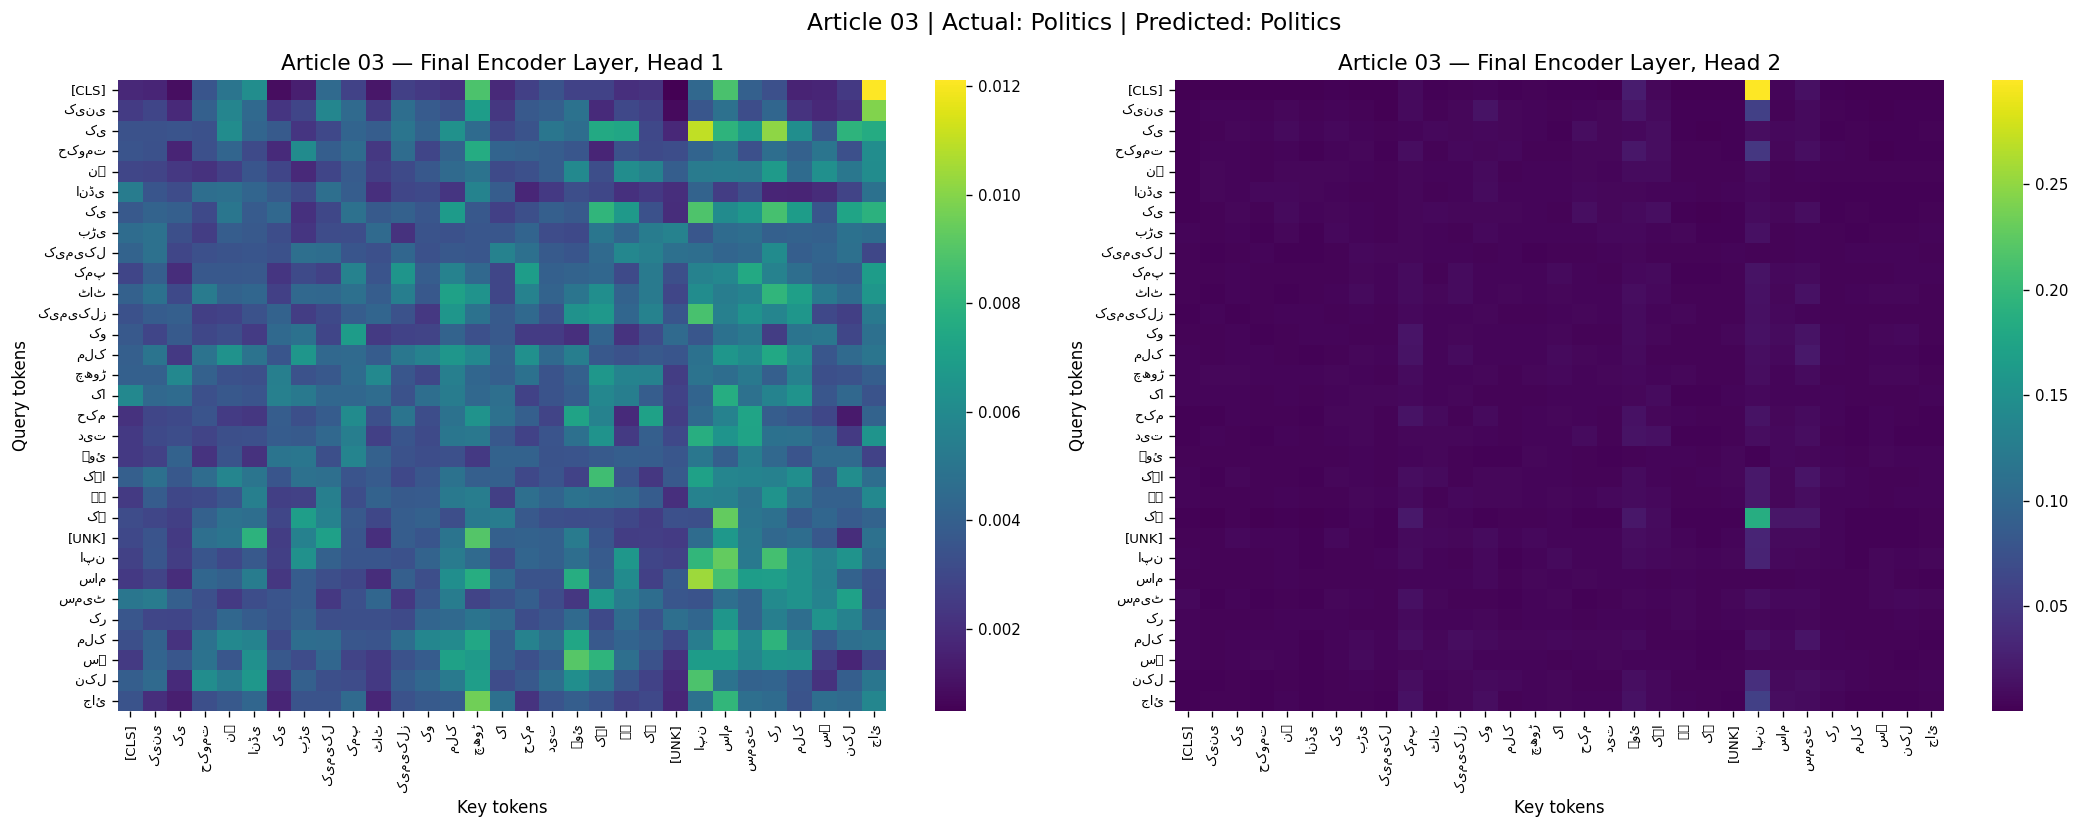


Article 03 heatmap saved: /content/BBC_Urdu_NLP_Assignment2/part3_transformer_topic_classification/part3_attention_article_3.png


In [99]:

# ARTICLE 03 — INDEPENDENT INSPECTION
import os
import json
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns

OUTPUT_DIR = (
    "/content/BBC_Urdu_NLP_Assignment2/"
    "part3_transformer_topic_classification"
)

CHECKPOINT = os.path.join(
    OUTPUT_DIR, "part3_transformer_best_corrected.pth"
)

class_names = [
    "Politics", "Sports", "Economy",
    "International", "Health & Society"
]

# Test index 4 was the third selected article: [2, 3, 4]
article_idx = 4

# Confirm this article was correctly classified
actual_id = int(Yte[article_idx])
predicted_id = int(y_pred[article_idx])

print("ARTICLE 03")
print("Test-set index:", article_idx)
print("Actual category:", class_names[actual_id])
print("Predicted category:", class_names[predicted_id])
print("Correctly classified:", actual_id == predicted_id)

# Load the best corrected Transformer checkpoint
model.load_state_dict(
    torch.load(CHECKPOINT, map_location=device, weights_only=True)
)
model.eval()

# Obtain attention weights
input_ids = torch.as_tensor(
    np.asarray(X_test[article_idx:article_idx+1]),
    dtype=torch.long,
    device=device
)

with torch.no_grad():
    logits, attention = model(
        input_ids, return_attention=True
    )

print("\nLogits shape:", tuple(logits.shape))
print("Attention shape:", tuple(attention.shape))

# Load the exact vocabulary used for tokenization
VOCAB_PATH = (
    "/content/BBC_Urdu_NLP_Assignment2/"
    "part1_word2vec/C3_cleaned_d100/vocabulary.json"
)

with open(VOCAB_PATH, "r", encoding="utf-8") as f:
    vocabulary = json.load(f)

id_to_token = {
    int(token_id): token
    for token, token_id in vocabulary.items()
}

PAD_ID = 11124
token_ids = input_ids[0].detach().cpu().tolist()

if PAD_ID in token_ids:
    token_count = token_ids.index(PAD_ID)
else:
    token_count = len(token_ids)

tokens = [
    id_to_token.get(token_ids[i], "[UNK]")
    for i in range(token_count)
]

print("\nFull article token count:", token_count)
print("Article 03 token sequence:")
print(" ".join(tokens))

# Display CLS plus the first 30 article tokens
display_count = min(30, token_count)
display_tokens = ["[CLS]"] + tokens[:display_count]
attention_size = display_count + 1

final_attention = attention[0].detach().cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, head_index in zip(axes, [0, 1]):
    matrix = final_attention[
        head_index, :attention_size, :attention_size
    ]

    sns.heatmap(
        matrix,
        ax=ax,
        cmap="viridis",
        xticklabels=display_tokens,
        yticklabels=display_tokens
    )

    ax.set_title(
        f"Article 03 — Final Encoder Layer, Head {head_index + 1}"
    )
    ax.set_xlabel("Key tokens")
    ax.set_ylabel("Query tokens")
    ax.tick_params(axis="x", rotation=90, labelsize=8)
    ax.tick_params(axis="y", rotation=0, labelsize=8)

fig.suptitle(
    f"Article 03 | Actual: {class_names[actual_id]} | "
    f"Predicted: {class_names[predicted_id]}",
    fontsize=14
)

plt.tight_layout()

save_path = os.path.join(
    OUTPUT_DIR, "part3_attention_article_3.png"
)
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("\nArticle 03 heatmap saved:", save_path)


Training articles: 172
Validation articles: 37
Test articles: 37
Vocabulary size: 11126

BiLSTM output verified: torch.Size([2, 5])
Epoch [01/20] Train Loss: 1.5998 | Train Acc: 0.2674 | Val Loss: 1.6035 | Val Acc: 0.1622 | Time: 0.86s
Epoch [02/20] Train Loss: 1.5965 | Train Acc: 0.2674 | Val Loss: 1.5998 | Val Acc: 0.1351 | Time: 0.42s
Epoch [03/20] Train Loss: 1.5838 | Train Acc: 0.3256 | Val Loss: 1.5931 | Val Acc: 0.1892 | Time: 0.34s
Epoch [04/20] Train Loss: 1.5690 | Train Acc: 0.3256 | Val Loss: 1.5836 | Val Acc: 0.1892 | Time: 0.39s
Epoch [05/20] Train Loss: 1.5463 | Train Acc: 0.3256 | Val Loss: 1.5696 | Val Acc: 0.2432 | Time: 0.34s
Epoch [06/20] Train Loss: 1.5177 | Train Acc: 0.3372 | Val Loss: 1.5559 | Val Acc: 0.2703 | Time: 0.43s
Epoch [07/20] Train Loss: 1.4807 | Train Acc: 0.3547 | Val Loss: 1.5401 | Val Acc: 0.2703 | Time: 0.38s
Epoch [08/20] Train Loss: 1.4515 | Train Acc: 0.3663 | Val Loss: 1.5204 | Val Acc: 0.2703 | Time: 0.37s
Epoch [09/20] Train Loss: 1.3953 | T

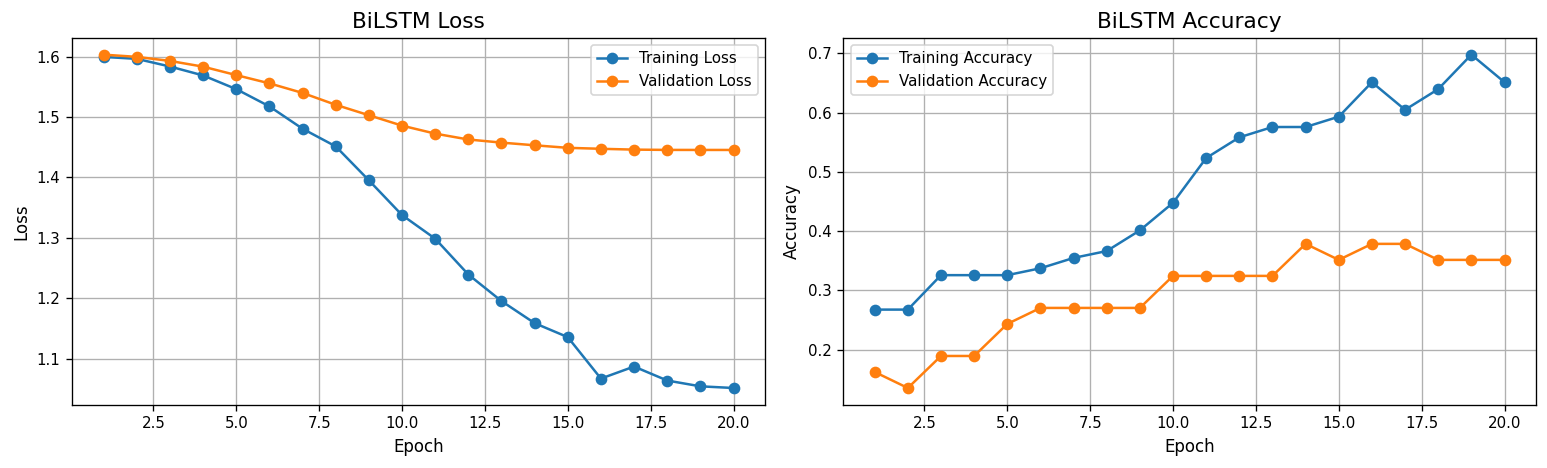


========== BiLSTM TEST RESULTS ==========
Test samples: 37
Test accuracy: 0.4054
Test macro-F1: 0.2000

BiLSTM classification report:
                  precision    recall  f1-score   support

        Politics       0.34      0.91      0.50        11
          Sports       0.00      0.00      0.00         3
         Economy       0.00      0.00      0.00         4
   International       0.00      0.00      0.00         7
Health & Society       0.62      0.42      0.50        12

        accuracy                           0.41        37
       macro avg       0.19      0.27      0.20        37
    weighted avg       0.31      0.41      0.31        37



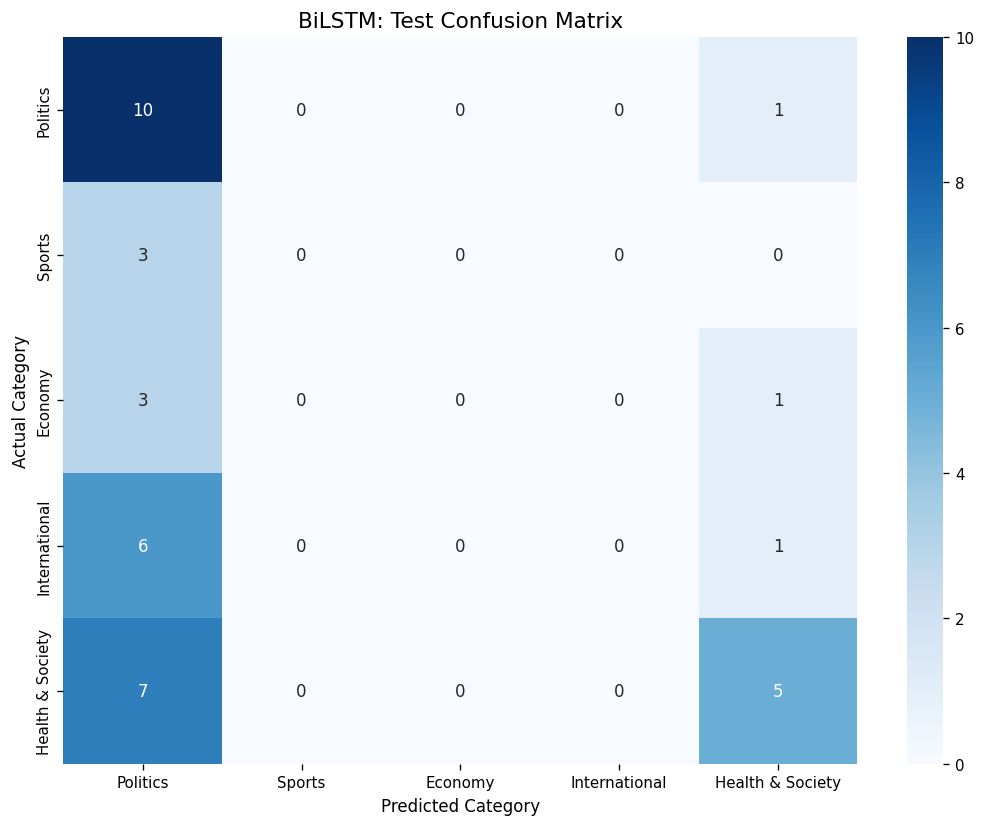


========== ARCHITECTURE COMPARISON ==========
Architecture  Test Accuracy  Test Macro-F1  Best Validation Epoch  Average Epoch Time (s)
 Transformer       0.567600         0.2815                     20                0.800000
      BiLSTM       0.405405         0.2000                     20                0.423132

BiLSTM average epoch time: 0.42s
BiLSTM total training time: 0.15 minutes

All BiLSTM outputs saved in:
/content/BBC_Urdu_NLP_Assignment2/part3_transformer_topic_classification


In [100]:

# PART 03 — BiLSTM TOPIC CLASSIFICATION BASELINE
import os
import time
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import LambdaLR

from torch.nn.utils.rnn import (
    pack_padded_sequence
)

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------
SEED = 42
EPOCHS = 20
BATCH_SIZE = 16
LEARNING_RATE = 5e-4
WEIGHT_DECAY = 0.01

PAD_ID = 11124

class_names = [
    "Politics",
    "Sports",
    "Economy",
    "International",
    "Health & Society"
]

OUTPUT_DIR = (
    "/content/BBC_Urdu_NLP_Assignment2/"
    "part3_transformer_topic_classification"
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

torch.manual_seed(SEED)
np.random.seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# --------------------------------------------------
# 2. Prepare the SAME existing data splits
# --------------------------------------------------
Xtr = torch.as_tensor(np.asarray(X_train), dtype=torch.long)
Ytr = torch.as_tensor(np.asarray(y_train), dtype=torch.long)

Xva = torch.as_tensor(np.asarray(X_val), dtype=torch.long)
Yva = torch.as_tensor(np.asarray(y_val), dtype=torch.long)

Xte = torch.as_tensor(np.asarray(X_test), dtype=torch.long)
Yte_bilstm = torch.as_tensor(
    np.asarray(y_test), dtype=torch.long
).cpu().numpy()

train_loader_bilstm = DataLoader(
    TensorDataset(Xtr, Ytr),
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader_bilstm = DataLoader(
    TensorDataset(Xva, Yva),
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Vocabulary size must include PAD and UNK IDs
VOCAB_SIZE = max(
    int(Xtr.max()),
    int(Xva.max()),
    int(Xte.max()),
    PAD_ID
) + 1

print("Training articles:", len(Xtr))
print("Validation articles:", len(Xva))
print("Test articles:", len(Xte))
print("Vocabulary size:", VOCAB_SIZE)

# --------------------------------------------------
# 3. Define BiLSTM classifier
# --------------------------------------------------
class BiLSTMTopicClassifier(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        hidden_dim=64,
        num_classes=5,
        padding_idx=PAD_ID,
        dropout=0.3
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=padding_idx
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )

        self.dropout = nn.Dropout(dropout)

        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim * 2, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, num_classes)
        )

    def forward(self, input_ids):

        # Count non-padding tokens
        lengths = (input_ids != PAD_ID).sum(dim=1)

        # Avoid zero-length sequences
        lengths = lengths.clamp(min=1)

        embedded = self.embedding(input_ids)

        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        _, (hidden, _) = self.lstm(packed)

        # Final forward and backward hidden states
        forward_hidden = hidden[-2]
        backward_hidden = hidden[-1]

        representation = torch.cat(
            [forward_hidden, backward_hidden],
            dim=1
        )

        representation = self.dropout(representation)

        return self.classifier(representation)


bilstm_model = BiLSTMTopicClassifier(
    vocab_size=VOCAB_SIZE
).to(device)

# Verify output dimensions
with torch.no_grad():
    sample_logits = bilstm_model(Xtr[:2].to(device))

assert sample_logits.shape == (2, 5)

print("\nBiLSTM output verified:", sample_logits.shape)

# --------------------------------------------------
# 4. Optimizer and scheduler
# --------------------------------------------------
criterion_bilstm = nn.CrossEntropyLoss()

optimizer_bilstm = AdamW(
    bilstm_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

total_steps = EPOCHS * len(train_loader_bilstm)
WARMUP_STEPS = 50

def bilstm_lr_lambda(step):

    if step < WARMUP_STEPS:
        return float(step + 1) / float(WARMUP_STEPS)

    progress = (
        step - WARMUP_STEPS
    ) / max(1, total_steps - WARMUP_STEPS)

    progress = min(progress, 1.0)

    return 0.5 * (
        1.0 + math.cos(math.pi * progress)
    )

scheduler_bilstm = LambdaLR(
    optimizer_bilstm,
    bilstm_lr_lambda
)

# --------------------------------------------------
# 5. Training and validation function
# --------------------------------------------------
def run_bilstm_epoch(loader, training=True):

    bilstm_model.train() if training else bilstm_model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    context = (
        torch.enable_grad()
        if training
        else torch.no_grad()
    )

    with context:

        for inputs, labels in loader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            if training:
                optimizer_bilstm.zero_grad()

            logits = bilstm_model(inputs)
            loss = criterion_bilstm(logits, labels)

            if training:
                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    bilstm_model.parameters(),
                    max_norm=1.0
                )

                optimizer_bilstm.step()
                scheduler_bilstm.step()

            predictions = logits.argmax(dim=1)

            total_loss += loss.item() * labels.size(0)
            total_correct += (
                predictions == labels
            ).sum().item()

            total_samples += labels.size(0)

    return (
        total_loss / total_samples,
        total_correct / total_samples
    )

# --------------------------------------------------
# 6. Train for 20 epochs
# --------------------------------------------------
history_bilstm = []

best_val_loss_bilstm = float("inf")
best_epoch_bilstm = 0

start_time = time.time()

for epoch in range(EPOCHS):

    epoch_start = time.time()

    train_loss, train_acc = run_bilstm_epoch(
        train_loader_bilstm,
        training=True
    )

    val_loss, val_acc = run_bilstm_epoch(
        val_loader_bilstm,
        training=False
    )

    epoch_time = time.time() - epoch_start

    history_bilstm.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "epoch_time_seconds": epoch_time
    })

    if val_loss < best_val_loss_bilstm:

        best_val_loss_bilstm = val_loss
        best_epoch_bilstm = epoch + 1

        torch.save(
            bilstm_model.state_dict(),
            os.path.join(
                OUTPUT_DIR,
                "part3_bilstm_best.pth"
            )
        )

    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Time: {epoch_time:.2f}s"
    )

total_time_bilstm = time.time() - start_time

# --------------------------------------------------
# 7. Save history and plot learning curves
# --------------------------------------------------
history_bilstm_df = pd.DataFrame(history_bilstm)

history_bilstm_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "part3_bilstm_training_history.csv"
    ),
    index=False
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(
    history_bilstm_df["epoch"],
    history_bilstm_df["train_loss"],
    marker="o",
    label="Training Loss"
)
axes[0].plot(
    history_bilstm_df["epoch"],
    history_bilstm_df["val_loss"],
    marker="o",
    label="Validation Loss"
)
axes[0].set_title("BiLSTM Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    history_bilstm_df["epoch"],
    history_bilstm_df["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)
axes[1].plot(
    history_bilstm_df["epoch"],
    history_bilstm_df["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)
axes[1].set_title("BiLSTM Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "part3_bilstm_learning_curves.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------
# 8. Evaluate best BiLSTM checkpoint on test set
# --------------------------------------------------
bilstm_model.load_state_dict(
    torch.load(
        os.path.join(
            OUTPUT_DIR,
            "part3_bilstm_best.pth"
        ),
        map_location=device,
        weights_only=True
    )
)

bilstm_model.eval()

with torch.no_grad():
    bilstm_logits = bilstm_model(Xte.to(device))
    bilstm_predictions = (
        bilstm_logits.argmax(dim=1).cpu().numpy()
    )

bilstm_test_accuracy = accuracy_score(
    Yte_bilstm,
    bilstm_predictions
)

bilstm_test_macro_f1 = f1_score(
    Yte_bilstm,
    bilstm_predictions,
    average="macro",
    zero_division=0
)

print("\n========== BiLSTM TEST RESULTS ==========")
print("Test samples:", len(Yte_bilstm))
print(f"Test accuracy: {bilstm_test_accuracy:.4f}")
print(f"Test macro-F1: {bilstm_test_macro_f1:.4f}")

print("\nBiLSTM classification report:")
print(
    classification_report(
        Yte_bilstm,
        bilstm_predictions,
        labels=[0, 1, 2, 3, 4],
        target_names=class_names,
        zero_division=0
    )
)

# --------------------------------------------------
# 9. BiLSTM confusion matrix
# --------------------------------------------------
cm_bilstm = confusion_matrix(
    Yte_bilstm,
    bilstm_predictions,
    labels=[0, 1, 2, 3, 4]
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_bilstm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("BiLSTM: Test Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "part3_bilstm_confusion_matrix.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------
# 10. Compare both architectures
# --------------------------------------------------
transformer_accuracy = 0.5676
transformer_macro_f1 = 0.2815
transformer_epoch_time = 0.80
transformer_best_epoch = 20

comparison = pd.DataFrame([
    {
        "Architecture": "Transformer",
        "Test Accuracy": transformer_accuracy,
        "Test Macro-F1": transformer_macro_f1,
        "Best Validation Epoch": transformer_best_epoch,
        "Average Epoch Time (s)": transformer_epoch_time
    },
    {
        "Architecture": "BiLSTM",
        "Test Accuracy": bilstm_test_accuracy,
        "Test Macro-F1": bilstm_test_macro_f1,
        "Best Validation Epoch": best_epoch_bilstm,
        "Average Epoch Time (s)": (
            history_bilstm_df["epoch_time_seconds"].mean()
        )
    }
])

comparison.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "part3_bilstm_transformer_comparison.csv"
    ),
    index=False
)

print("\n========== ARCHITECTURE COMPARISON ==========")
print(comparison.to_string(index=False))

print("\nBiLSTM average epoch time:",
      f"{history_bilstm_df['epoch_time_seconds'].mean():.2f}s")

print("BiLSTM total training time:",
      f"{total_time_bilstm/60:.2f} minutes")

print("\nAll BiLSTM outputs saved in:")
print(OUTPUT_DIR)


ARTICLE 03 — FINAL VERIFICATION
Test index: 4
Actual category: Politics
Predicted category: Politics
Correct classification: True

Logits shape: (1, 5)
Attention shape: (1, 4, 257, 257)

Article token count: 256

Complete Article 03 token sequence:
کینی کی حکومت نے انڈی کی بڑی کیمیکل کمپ ٹاٹ کیمیکلز کو ملک چھوڑ کا حکم دیت ہوئ کہا ہے کہ [UNK] اپن سام سمیٹ کر ملک سے نکل جائ ۔ [UNK] کینی کی حکومت کا مؤقف ہے کہ کمپ مقام صنعت اور روزگار کے فروغ میں مطلوب کردار ادا نہیں کر سکی ۔ کینی کے صدر ولیم روٹو کے مطابق کمپ سوڈ ایش کو مقام سطح پر پراسیس کر کے شیش اور دیگر کیمیکل بنا کے بجائ اسے برآمد کر رہی تھی ۔ صدر روٹو کے مطابق [UNK] نے کمپ کی جگہ لین کے لیے نئے سرمای کار ڈھونڈ لیے ہیں ۔ ان کے مطابق اس سے کینی میں روزگار کے مزید مواقع پید ہوں گے اور سرمای کار بڑھ گی ۔ [UNK] دوسر جانب ٹاٹ کیمیکلز نے کہا ہے کہ وہ حکومت کے فیصل کا احترام کرت ہے اور باق معامل کے حل کے لیے [UNK] قانو اور ریگولیٹر طریق کار کے تحت تعمیر [UNK] کے لیے پرعزم ہے ۔ [UNK] صدر روٹو نے یہ تبصر کاجیادو کاؤنٹ کے دور کے دور کیے ، جہا

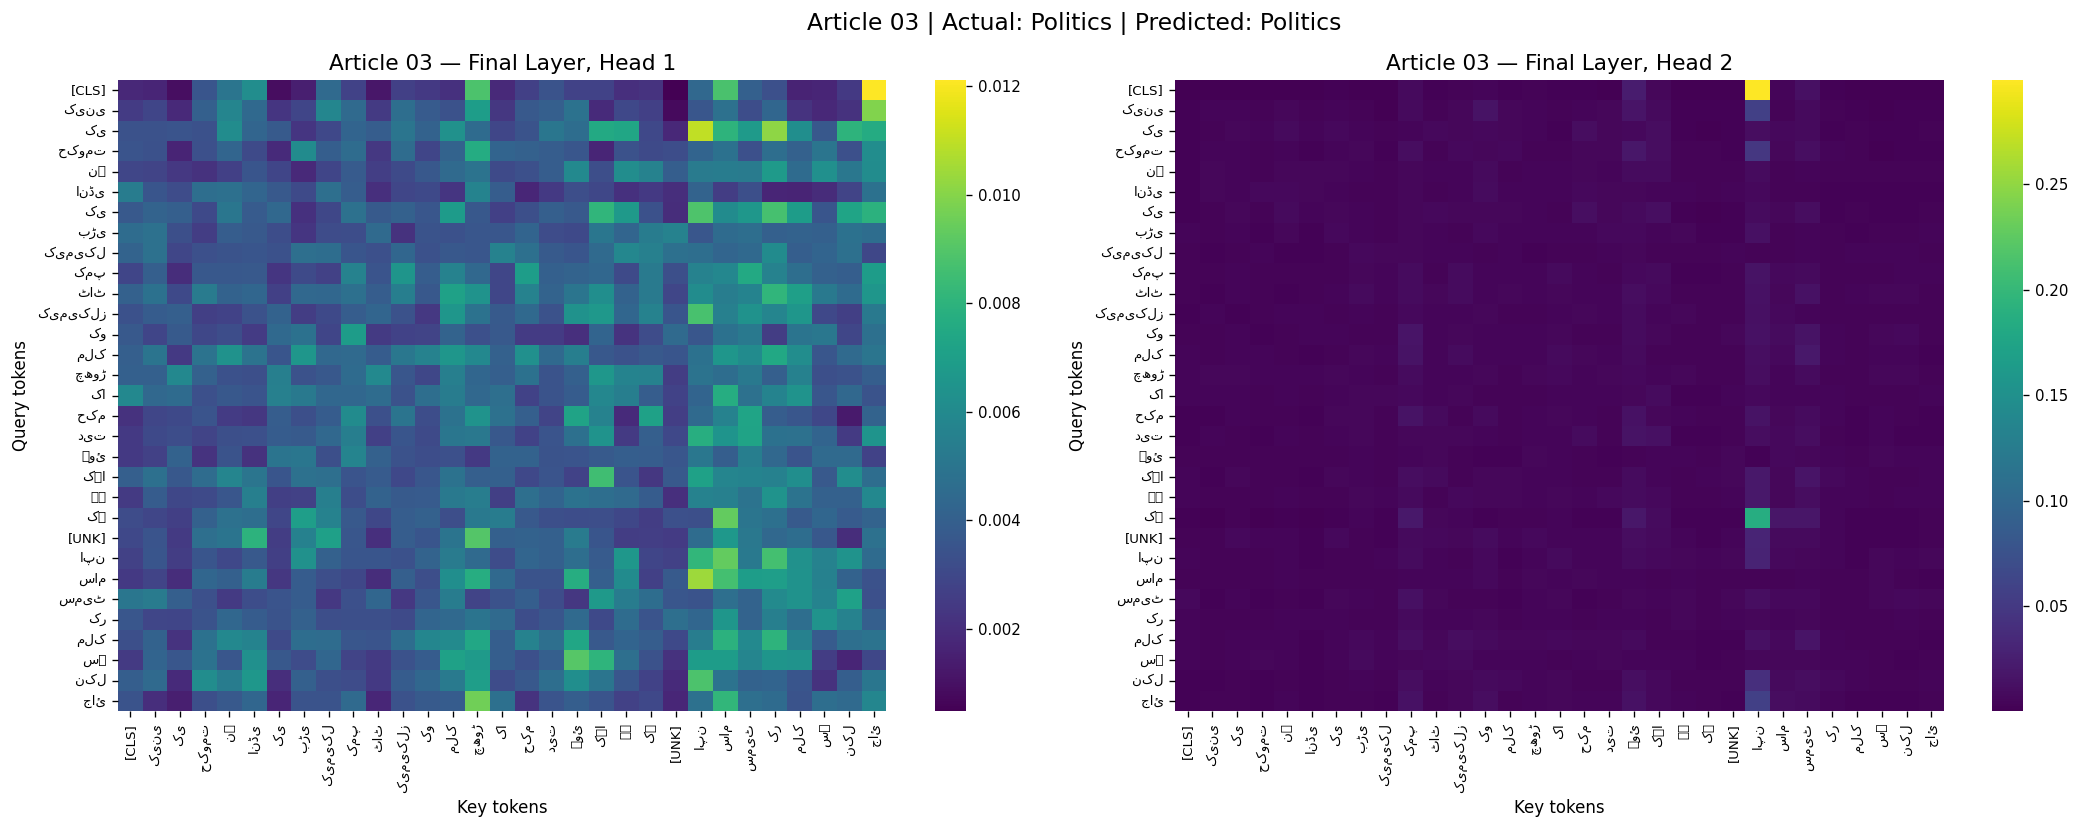


ARTICLE 03 VERIFICATION SUMMARY
Correctly classified: YES
Attention heads visualized: 2
Final encoder layer: YES
Heatmap file exists: True
Saved file: /content/BBC_Urdu_NLP_Assignment2/part3_transformer_topic_classification/part3_attention_article_3.png

PART 03 ATTENTION VISUALIZATION REQUIREMENT: VERIFIED


In [101]:

import os
import json
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns

OUTPUT_DIR = (
    "/content/BBC_Urdu_NLP_Assignment2/"
    "part3_transformer_topic_classification"
)

CHECKPOINT = os.path.join(
    OUTPUT_DIR,
    "part3_transformer_best_corrected.pth"
)

VOCAB_PATH = (
    "/content/BBC_Urdu_NLP_Assignment2/"
    "part1_word2vec/C3_cleaned_d100/vocabulary.json"
)

CLASS_NAMES = [
    "Politics",
    "Sports",
    "Economy",
    "International",
    "Health & Society"
]

# Third article from the previously selected indices [2, 3, 4]
ARTICLE_INDEX = 4

# 1. Verify actual and predicted categories
actual = int(Yte[ARTICLE_INDEX])
predicted = int(y_pred[ARTICLE_INDEX])

print("=" * 55)
print("ARTICLE 03 — FINAL VERIFICATION")
print("=" * 55)

print("Test index:", ARTICLE_INDEX)
print("Actual category:", CLASS_NAMES[actual])
print("Predicted category:", CLASS_NAMES[predicted])
print("Correct classification:", actual == predicted)

assert actual == predicted, (
    "This article is not correctly classified. "
    "Select another correctly classified test article."
)

# 2. Load the best corrected Transformer
model.load_state_dict(
    torch.load(
        CHECKPOINT,
        map_location=device,
        weights_only=True
    )
)
model.eval()

# 3. Get article attention
article = torch.as_tensor(
    np.asarray(X_test[ARTICLE_INDEX:ARTICLE_INDEX+1]),
    dtype=torch.long,
    device=device
)

with torch.no_grad():
    logits, attention = model(
        article,
        return_attention=True
    )

print("\nLogits shape:", tuple(logits.shape))
print("Attention shape:", tuple(attention.shape))

assert tuple(logits.shape) == (1, 5)
assert tuple(attention.shape) == (1, 4, 257, 257)

# 4. Recover readable Urdu tokens
with open(VOCAB_PATH, "r", encoding="utf-8") as f:
    vocabulary = json.load(f)

id_to_token = {
    int(value): key
    for key, value in vocabulary.items()
}

token_ids = article[0].cpu().tolist()
PAD_ID = 11124

token_count = (
    token_ids.index(PAD_ID)
    if PAD_ID in token_ids
    else len(token_ids)
)

tokens = [
    id_to_token.get(token_ids[i], "[UNK]")
    for i in range(token_count)
]

print("\nArticle token count:", len(tokens))
print("\nComplete Article 03 token sequence:")
print(" ".join(tokens))

# 5. Plot two heads from the final encoder layer
final_attention = attention[0].cpu().numpy()

display_count = min(30, len(tokens))
display_tokens = ["[CLS]"] + tokens[:display_count]
size = len(display_tokens)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, head in zip(axes, [0, 1]):

    matrix = final_attention[
        head, :size, :size
    ]

    sns.heatmap(
        matrix,
        ax=ax,
        cmap="viridis",
        xticklabels=display_tokens,
        yticklabels=display_tokens
    )

    ax.set_title(
        f"Article 03 — Final Layer, Head {head + 1}"
    )
    ax.set_xlabel("Key tokens")
    ax.set_ylabel("Query tokens")
    ax.tick_params(axis="x", rotation=90, labelsize=8)
    ax.tick_params(axis="y", rotation=0, labelsize=8)

fig.suptitle(
    f"Article 03 | Actual: {CLASS_NAMES[actual]} | "
    f"Predicted: {CLASS_NAMES[predicted]}",
    fontsize=14
)

plt.tight_layout()

heatmap_path = os.path.join(
    OUTPUT_DIR,
    "part3_attention_article_3.png"
)

plt.savefig(
    heatmap_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 6. Final confirmation
print("\n" + "=" * 55)
print("ARTICLE 03 VERIFICATION SUMMARY")
print("=" * 55)
print("Correctly classified: YES")
print("Attention heads visualized: 2")
print("Final encoder layer: YES")
print("Heatmap file exists:", os.path.exists(heatmap_path))
print("Saved file:", heatmap_path)
print("\nPART 03 ATTENTION VISUALIZATION REQUIREMENT: VERIFIED")


PART 03 — FINAL VISUALIZATION DASHBOARD
Output directory: /content/BBC_Urdu_NLP_Assignment2/part3_transformer_topic_classification/part3_final_visualizations
[LOADED] part3_final_article_labels.csv
[LOADED] part3_split_metadata.csv
[LOADED] part3_transformer_training_history_corrected.csv
[LOADED] part3_bilstm_training_history.csv
[LOADED] part3_transformer_test_predictions.csv
[LOADED] part3_bilstm_transformer_comparison.csv

Visualization input loading completed.
[SAVED] 01_dataset_distribution.png


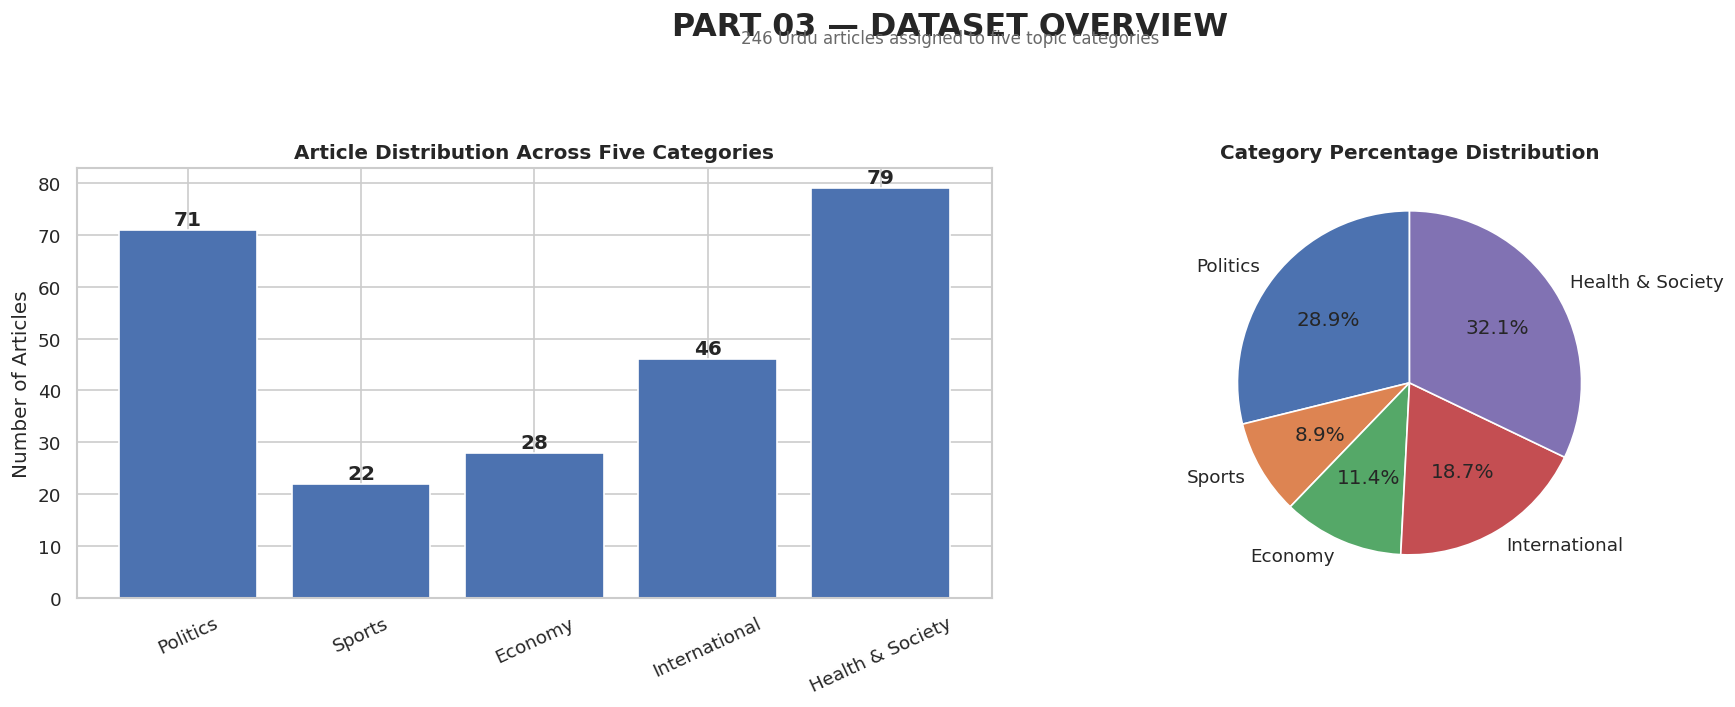

[SAVED] 02_stratified_split_distribution.png


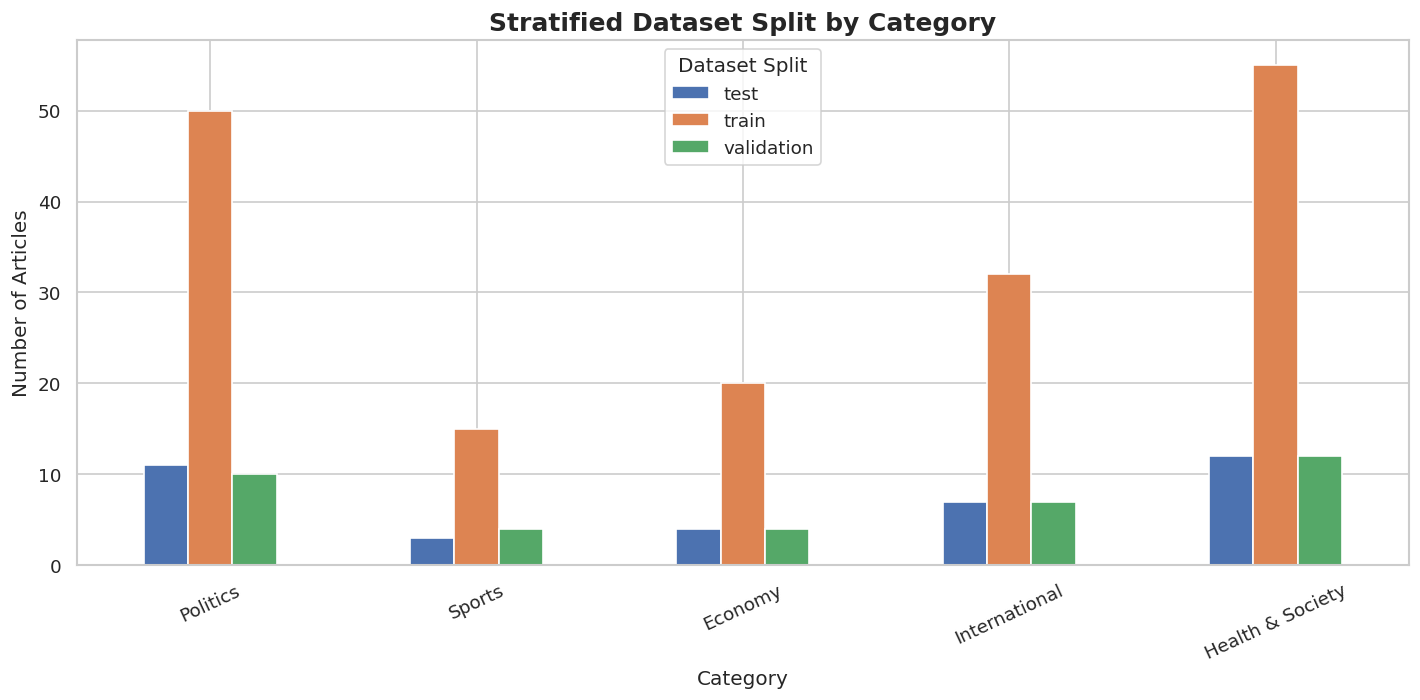

[SAVED] 03_transformer_architecture.png


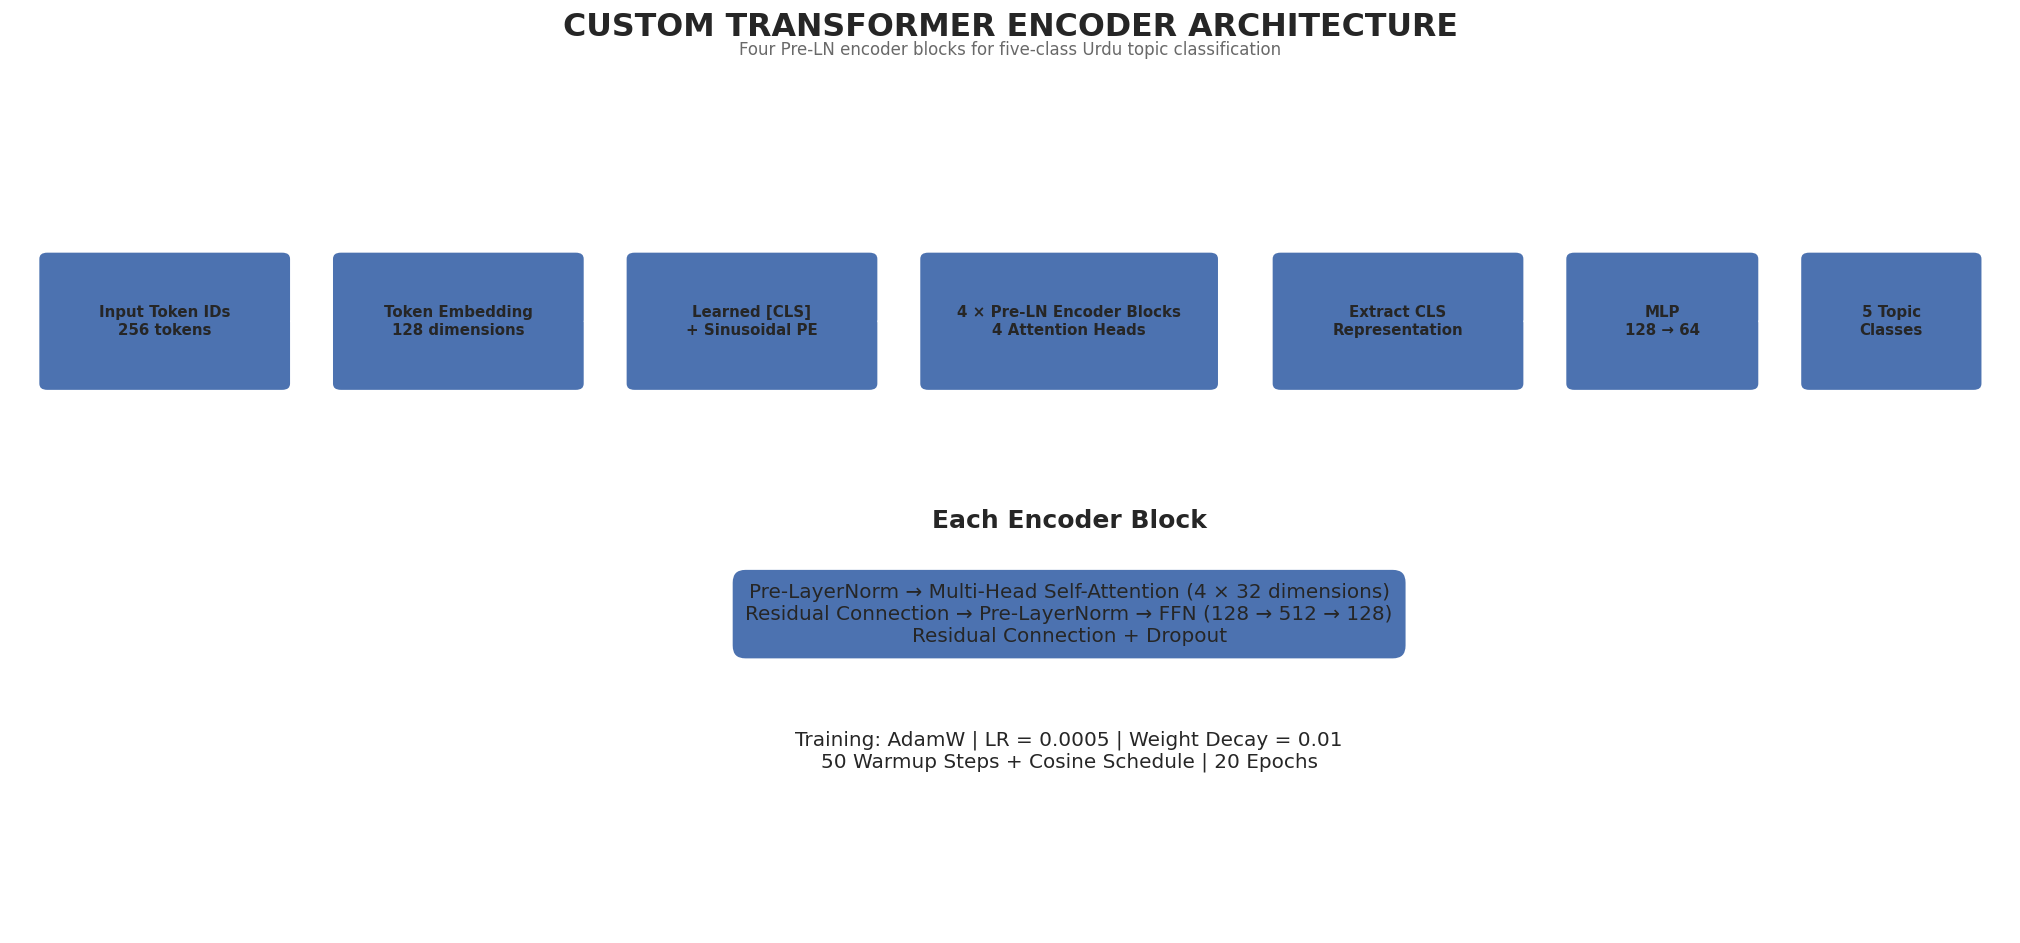

[SAVED] 04_transformer_training_curves.png


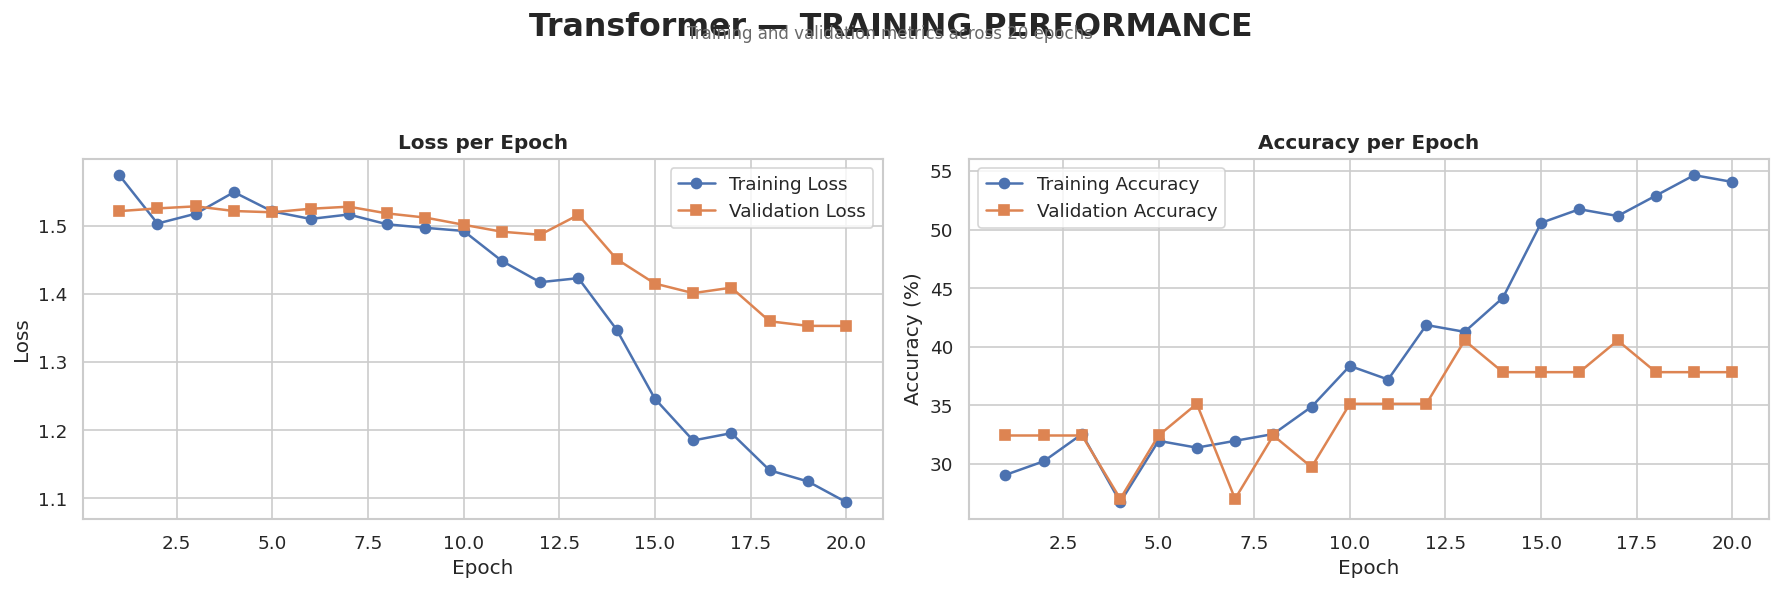

[SAVED] 05_bilstm_training_curves.png


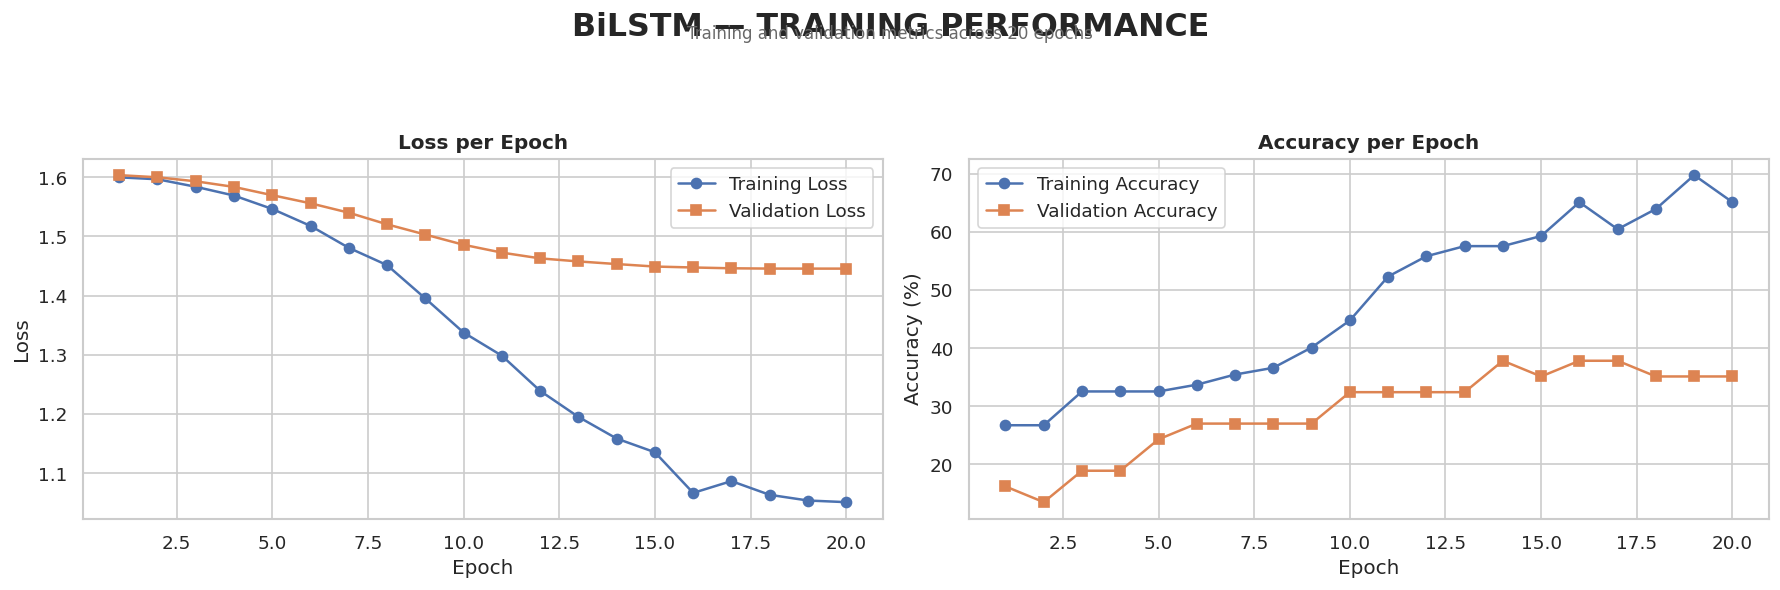

[SAVED] 06_bilstm_transformer_comparison.png


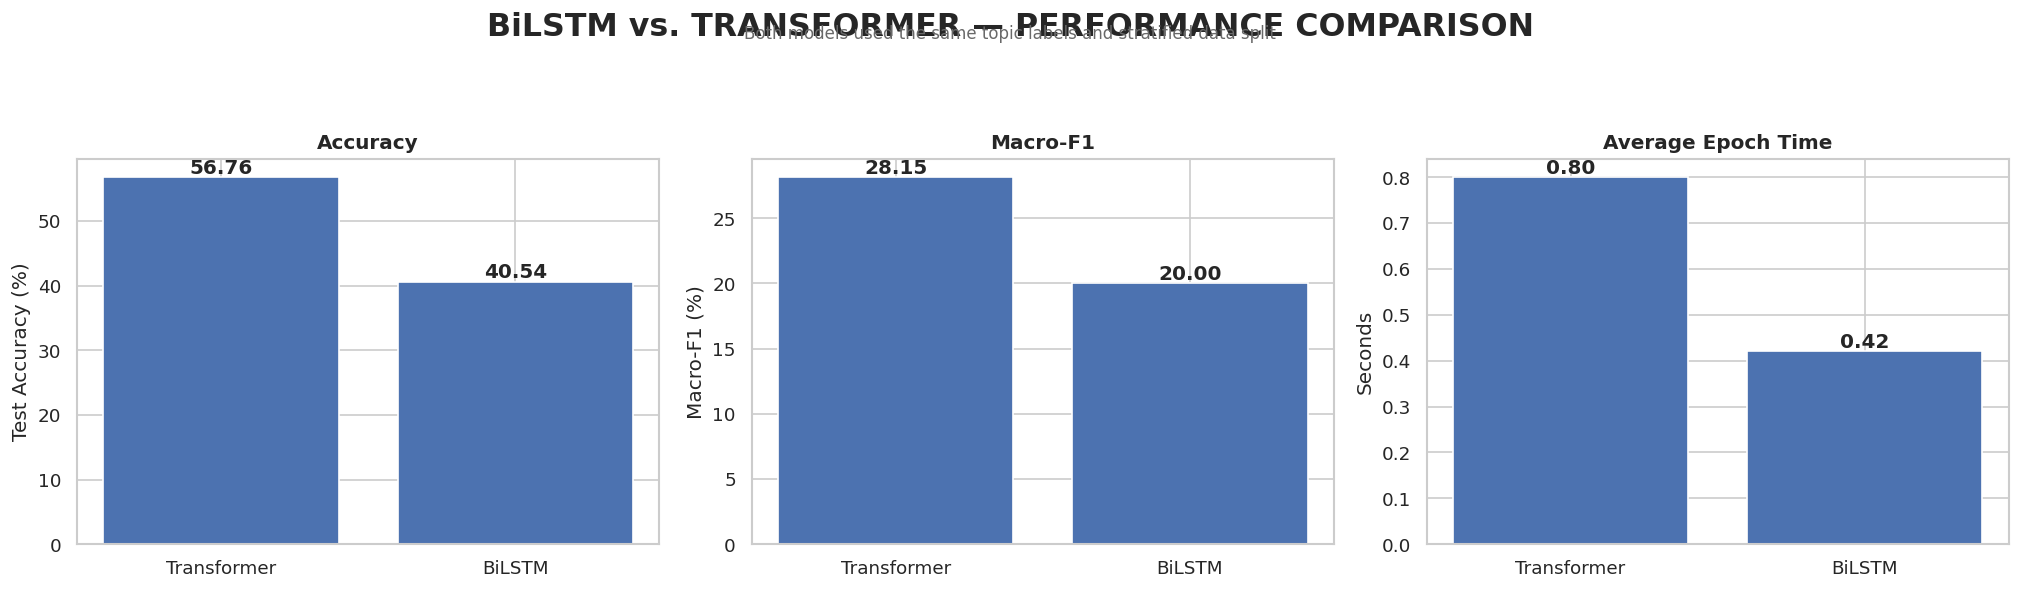

[SAVED] 07_test_metrics.png


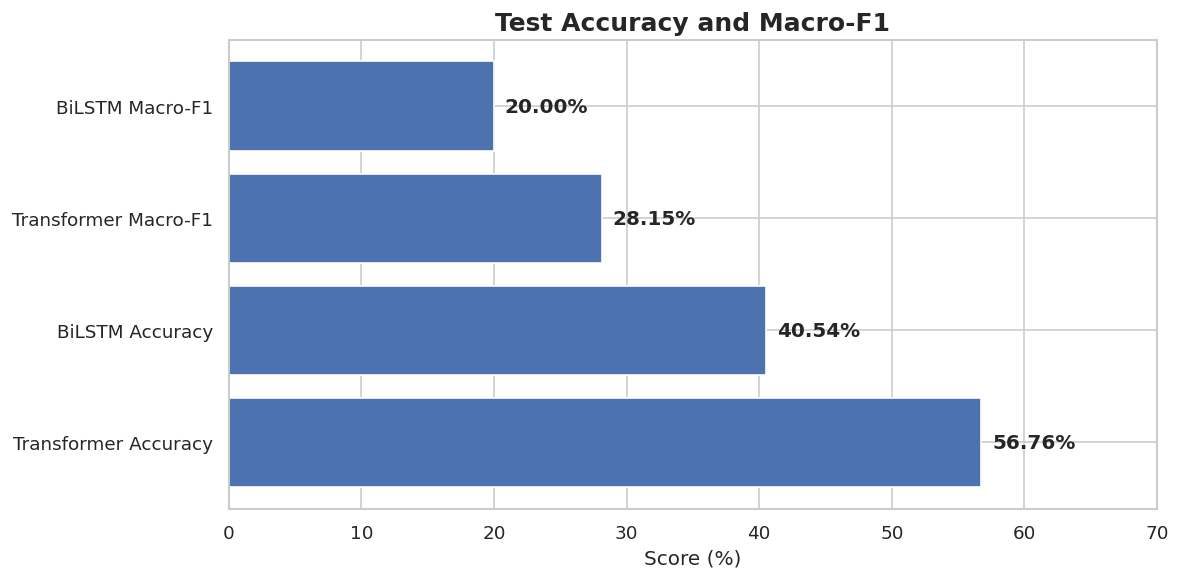

[SAVED] 08_confusion_matrices_comparison.png


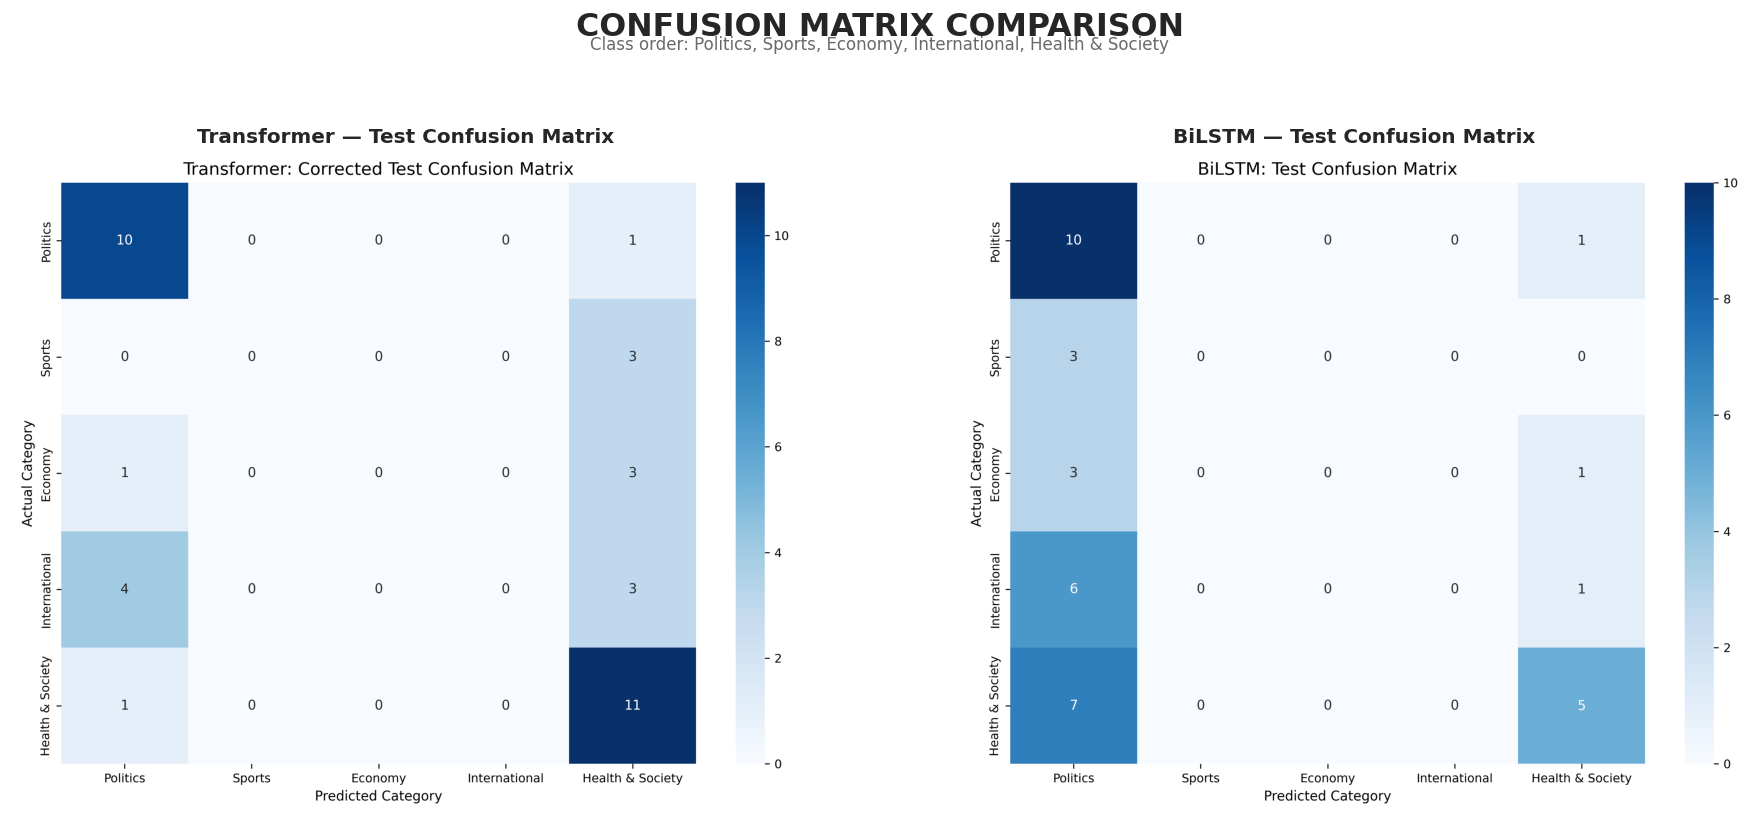

[SAVED] 09_three_attention_heatmaps.png


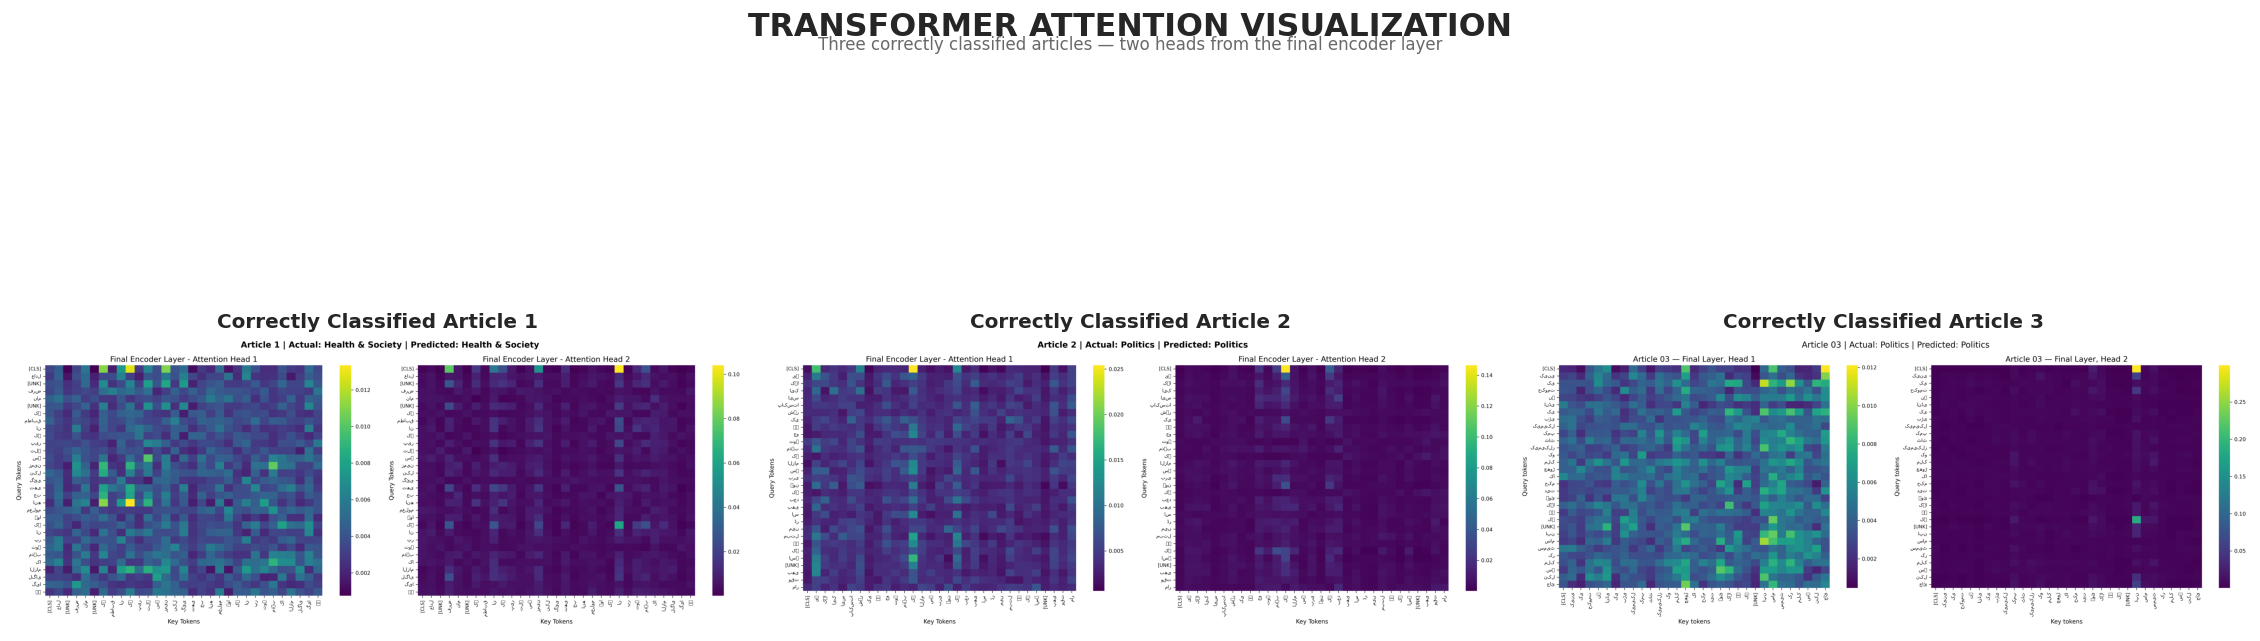

[SAVED] 10_final_experiment_summary.png


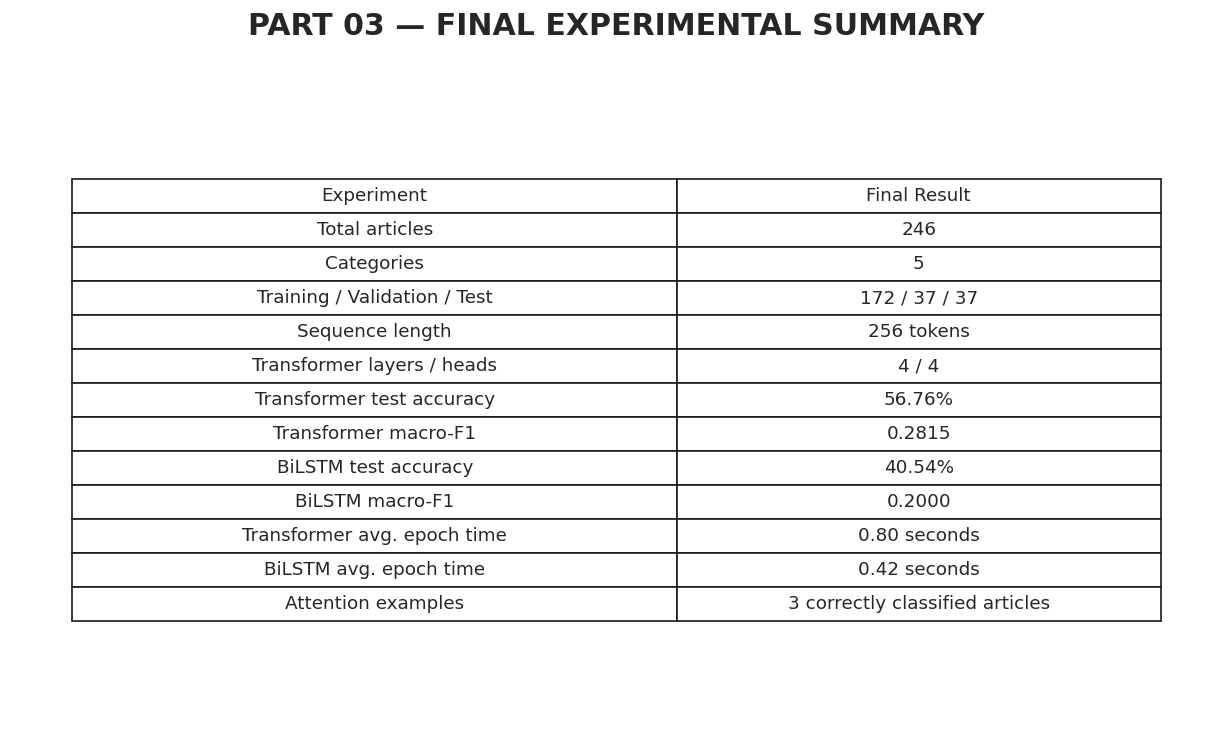


PART 03 VISUALIZATION GENERATION COMPLETED
[OK] 01_dataset_distribution.png
[OK] 02_stratified_split_distribution.png
[OK] 03_transformer_architecture.png
[OK] 04_transformer_training_curves.png
[OK] 05_bilstm_training_curves.png
[OK] 06_bilstm_transformer_comparison.png
[OK] 07_test_metrics.png
[OK] 08_confusion_matrices_comparison.png
[OK] 09_three_attention_heatmaps.png
[OK] 10_final_experiment_summary.png

Combined PDF:
/content/BBC_Urdu_NLP_Assignment2/part3_transformer_topic_classification/part3_final_visualizations/Part03_Complete_Results_Visualization.pdf

All generated outputs:
01_dataset_distribution.png
02_stratified_split_distribution.png
03_transformer_architecture.png
04_transformer_training_curves.png
05_bilstm_training_curves.png
06_bilstm_transformer_comparison.png
07_test_metrics.png
08_confusion_matrices_comparison.png
09_three_attention_heatmaps.png
10_final_experiment_summary.png
Part03_Complete_Results_Visualization.pdf


In [102]:

# ================================================================
# PART 03 — COMPLETE RESULTS VISUALIZATION DASHBOARD
# No training or model retraining required
# ================================================================

import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from PIL import Image
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

warnings.filterwarnings("ignore")

# ------------------------------------------------
# 1. PATHS AND CONFIGURATION
# ------------------------------------------------

ROOT = Path(
    "/content/BBC_Urdu_NLP_Assignment2/"
    "part3_transformer_topic_classification"
)

VIZ_DIR = ROOT / "part3_final_visualizations"
VIZ_DIR.mkdir(parents=True, exist_ok=True)

CLASSES = [
    "Politics",
    "Sports",
    "Economy",
    "International",
    "Health & Society"
]

sns.set_theme(style="whitegrid", context="notebook")

print("=" * 75)
print("PART 03 — FINAL VISUALIZATION DASHBOARD")
print("=" * 75)
print("Output directory:", VIZ_DIR)


# ------------------------------------------------
# 2. HELPER FUNCTIONS
# ------------------------------------------------

def load_csv(filename):
    path = ROOT / filename
    if path.exists():
        print("[LOADED]", filename)
        return pd.read_csv(path)
    print("[MISSING]", filename)
    return None


def find_column(df, candidates):
    if df is None:
        return None

    normalized = {
        str(col).lower().replace(" ", "_"): col
        for col in df.columns
    }

    for candidate in candidates:
        key = candidate.lower().replace(" ", "_")
        if key in normalized:
            return normalized[key]

    return None


def save_figure(fig, filename):
    path = VIZ_DIR / filename
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print("[SAVED]", path.name)
    return path


def add_title(fig, title, subtitle=None):
    fig.suptitle(
        title,
        fontsize=19,
        fontweight="bold",
        y=0.98
    )
    if subtitle:
        fig.text(
            0.5, 0.935, subtitle,
            ha="center",
            fontsize=10,
            color="dimgray"
        )


# ------------------------------------------------
# 3. LOAD EXISTING EXPERIMENTAL RESULTS
# ------------------------------------------------

labels_df = load_csv("part3_final_article_labels.csv")
split_df = load_csv("part3_split_metadata.csv")

transformer_history = load_csv(
    "part3_transformer_training_history_corrected.csv"
)

bilstm_history = load_csv(
    "part3_bilstm_training_history.csv"
)

transformer_predictions = load_csv(
    "part3_transformer_test_predictions.csv"
)

comparison_df = load_csv(
    "part3_bilstm_transformer_comparison.csv"
)

print("\nVisualization input loading completed.")


# ------------------------------------------------
# 4. DATASET CATEGORY DISTRIBUTION
# ------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

if labels_df is not None:

    category_col = find_column(
        labels_df,
        ["final_category", "category", "label", "topic"]
    )

    if category_col:
        counts = (
            labels_df[category_col]
            .value_counts()
            .reindex(CLASSES, fill_value=0)
        )

        axes[0].bar(
            counts.index,
            counts.values
        )

        axes[0].set_title(
            "Article Distribution Across Five Categories",
            fontweight="bold"
        )
        axes[0].set_ylabel("Number of Articles")
        axes[0].tick_params(axis="x", rotation=25)

        for i, value in enumerate(counts.values):
            axes[0].text(
                i, value + 1,
                str(value),
                ha="center",
                fontweight="bold"
            )

        axes[1].pie(
            counts.values,
            labels=counts.index,
            autopct="%1.1f%%",
            startangle=90
        )
        axes[1].set_title(
            "Category Percentage Distribution",
            fontweight="bold"
        )

    else:
        axes[0].text(
            0.5, 0.5,
            "Category column not found",
            ha="center"
        )
        axes[1].axis("off")

else:
    axes[0].text(0.5, 0.5, "Labels CSV unavailable", ha="center")
    axes[1].axis("off")

add_title(
    fig,
    "PART 03 — DATASET OVERVIEW",
    "246 Urdu articles assigned to five topic categories"
)

plt.tight_layout(rect=[0, 0, 1, 0.90])
save_figure(fig, "01_dataset_distribution.png")
plt.show()


# ------------------------------------------------
# 5. STRATIFIED TRAIN / VALIDATION / TEST DISTRIBUTION
# ------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 6))

if split_df is not None:

    split_col = find_column(
        split_df,
        ["split", "dataset_split", "subset", "set"]
    )

    category_col = find_column(
        split_df,
        ["final_category", "category", "label", "topic"]
    )

    if split_col and category_col:

        distribution = pd.crosstab(
            split_df[category_col],
            split_df[split_col]
        )

        distribution = distribution.reindex(
            CLASSES,
            fill_value=0
        )

        distribution.plot(
            kind="bar",
            ax=ax
        )

        ax.set_title(
            "Stratified Dataset Split by Category",
            fontsize=15,
            fontweight="bold"
        )
        ax.set_xlabel("Category")
        ax.set_ylabel("Number of Articles")
        ax.tick_params(axis="x", rotation=25)
        ax.legend(title="Dataset Split")

    else:
        ax.text(
            0.5, 0.5,
            "Split/category columns not detected.\n"
            "Expected split metadata CSV.",
            ha="center",
            va="center"
        )
        ax.axis("off")

else:
    ax.text(0.5, 0.5, "Split metadata unavailable", ha="center")
    ax.axis("off")

plt.tight_layout()
save_figure(fig, "02_stratified_split_distribution.png")
plt.show()


# ------------------------------------------------
# 6. TRANSFORMER ARCHITECTURE DIAGRAM
# ------------------------------------------------

fig, ax = plt.subplots(figsize=(17, 8))
ax.set_xlim(0, 17)
ax.set_ylim(0, 9)
ax.axis("off")

architecture = [
    (0.3, 5.7, 2.0, 1.3, "Input Token IDs\n256 tokens"),
    (2.8, 5.7, 2.0, 1.3, "Token Embedding\n128 dimensions"),
    (5.3, 5.7, 2.0, 1.3, "Learned [CLS]\n+ Sinusoidal PE"),
    (7.8, 5.7, 2.4, 1.3, "4 × Pre-LN Encoder Blocks\n4 Attention Heads"),
    (10.8, 5.7, 2.0, 1.3, "Extract CLS\nRepresentation"),
    (13.3, 5.7, 1.5, 1.3, "MLP\n128 → 64"),
    (15.3, 5.7, 1.4, 1.3, "5 Topic\nClasses")
]

for x, y, w, h, label in architecture:

    patch = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.08",
        linewidth=1.8
    )

    ax.add_patch(patch)

    ax.text(
        x + w / 2,
        y + h / 2,
        label,
        ha="center",
        va="center",
        fontsize=9,
        fontweight="bold"
    )

for i in range(len(architecture) - 1):

    x1 = architecture[i][0] + architecture[i][2]
    x2 = architecture[i + 1][0]

    ax.add_patch(
        FancyArrowPatch(
            (x1 + 0.05, 6.35),
            (x2 - 0.05, 6.35),
            arrowstyle="->",
            mutation_scale=17,
            linewidth=1.6
        )
    )

ax.text(
    9, 4.2,
    "Each Encoder Block",
    ha="center",
    fontsize=15,
    fontweight="bold"
)

block_text = (
    "Pre-LayerNorm → Multi-Head Self-Attention (4 × 32 dimensions)\n"
    "Residual Connection → Pre-LayerNorm → FFN (128 → 512 → 128)\n"
    "Residual Connection + Dropout"
)

ax.text(
    9, 3.3,
    block_text,
    ha="center",
    va="center",
    fontsize=12,
    bbox=dict(
        boxstyle="round,pad=0.7",
        linewidth=1.5
    )
)

ax.text(
    9, 1.7,
    "Training: AdamW | LR = 0.0005 | Weight Decay = 0.01\n"
    "50 Warmup Steps + Cosine Schedule | 20 Epochs",
    ha="center",
    fontsize=12
)

add_title(
    fig,
    "CUSTOM TRANSFORMER ENCODER ARCHITECTURE",
    "Four Pre-LN encoder blocks for five-class Urdu topic classification"
)

plt.tight_layout()
save_figure(fig, "03_transformer_architecture.png")
plt.show()


# ------------------------------------------------
# 7. TRANSFORMER TRAINING CURVES
# ------------------------------------------------

def plot_training_history(df, model_name, filename):

    if df is None:
        print("[SKIPPED]", model_name, "history unavailable")
        return

    train_loss_col = find_column(
        df, ["train_loss", "training_loss"]
    )
    val_loss_col = find_column(
        df, ["val_loss", "validation_loss"]
    )
    train_acc_col = find_column(
        df, ["train_acc", "train_accuracy", "training_accuracy"]
    )
    val_acc_col = find_column(
        df, ["val_acc", "val_accuracy", "validation_accuracy"]
    )

    if not all([
        train_loss_col,
        val_loss_col,
        train_acc_col,
        val_acc_col
    ]):
        print("[WARNING] Could not identify all history columns.")
        print("Available columns:", list(df.columns))
        return

    epochs = np.arange(1, len(df) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    axes[0].plot(
        epochs, df[train_loss_col],
        marker="o", label="Training Loss"
    )
    axes[0].plot(
        epochs, df[val_loss_col],
        marker="s", label="Validation Loss"
    )
    axes[0].set_title("Loss per Epoch", fontweight="bold")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()

    axes[1].plot(
        epochs, df[train_acc_col] * 100,
        marker="o", label="Training Accuracy"
    )
    axes[1].plot(
        epochs, df[val_acc_col] * 100,
        marker="s", label="Validation Accuracy"
    )
    axes[1].set_title("Accuracy per Epoch", fontweight="bold")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy (%)")
    axes[1].legend()

    add_title(
        fig,
        model_name + " — TRAINING PERFORMANCE",
        "Training and validation metrics across 20 epochs"
    )

    plt.tight_layout(rect=[0, 0, 1, 0.90])
    save_figure(fig, filename)
    plt.show()


plot_training_history(
    transformer_history,
    "Transformer",
    "04_transformer_training_curves.png"
)

plot_training_history(
    bilstm_history,
    "BiLSTM",
    "05_bilstm_training_curves.png"
)


# ------------------------------------------------
# 8. TRANSFORMER AND BILSTM PERFORMANCE COMPARISON
# ------------------------------------------------

model_names = ["Transformer", "BiLSTM"]

accuracy = [56.76, 40.54]
macro_f1 = [0.2815, 0.2000]
epoch_time = [0.80, 0.42]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

metrics = [
    (accuracy, "Test Accuracy (%)", "Accuracy"),
    (
        [v * 100 for v in macro_f1],
        "Macro-F1 (%)",
        "Macro-F1"
    ),
    (epoch_time, "Seconds", "Average Epoch Time")
]

for ax, (values, ylabel, title) in zip(axes, metrics):

    bars = ax.bar(
        model_names,
        values
    )

    ax.set_title(title, fontweight="bold")
    ax.set_ylabel(ylabel)

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{value:.2f}",
            ha="center",
            va="bottom",
            fontweight="bold"
        )

add_title(
    fig,
    "BiLSTM vs. TRANSFORMER — PERFORMANCE COMPARISON",
    "Both models used the same topic labels and stratified data split"
)

plt.tight_layout(rect=[0, 0, 1, 0.90])
save_figure(fig, "06_bilstm_transformer_comparison.png")
plt.show()


# ------------------------------------------------
# 9. TEST METRICS VISUALIZATION
# ------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5))

metric_names = [
    "Transformer Accuracy",
    "BiLSTM Accuracy",
    "Transformer Macro-F1",
    "BiLSTM Macro-F1"
]

metric_values = [
    56.76,
    40.54,
    28.15,
    20.00
]

bars = ax.barh(
    metric_names,
    metric_values
)

ax.set_xlim(0, 70)
ax.set_xlabel("Score (%)")
ax.set_title(
    "Test Accuracy and Macro-F1",
    fontsize=15,
    fontweight="bold"
)

for bar, value in zip(bars, metric_values):
    ax.text(
        value + 0.8,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}%",
        va="center",
        fontweight="bold"
    )

plt.tight_layout()
save_figure(fig, "07_test_metrics.png")
plt.show()


# ------------------------------------------------
# 10. CONFUSION MATRICES
# ------------------------------------------------

def show_saved_image(ax, filename, title):

    path = ROOT / filename

    if path.exists():

        image_data = Image.open(path).convert("RGB")
        ax.imshow(image_data)
        ax.axis("off")
        ax.set_title(title, fontweight="bold")

    else:

        ax.text(
            0.5, 0.5,
            "Image not found:\n" + filename,
            ha="center",
            va="center"
        )
        ax.axis("off")


fig, axes = plt.subplots(1, 2, figsize=(16, 7))

show_saved_image(
    axes[0],
    "part3_transformer_confusion_matrix_corrected.png",
    "Transformer — Test Confusion Matrix"
)

show_saved_image(
    axes[1],
    "part3_bilstm_confusion_matrix.png",
    "BiLSTM — Test Confusion Matrix"
)

add_title(
    fig,
    "CONFUSION MATRIX COMPARISON",
    "Class order: Politics, Sports, Economy, International, Health & Society"
)

plt.tight_layout(rect=[0, 0, 1, 0.90])
save_figure(fig, "08_confusion_matrices_comparison.png")
plt.show()


# ------------------------------------------------
# 11. THREE ATTENTION HEATMAPS
# ------------------------------------------------

attention_files = [
    "part3_attention_article_1.png",
    "part3_attention_article_2.png",
    "part3_attention_article_3.png"
]

fig, axes = plt.subplots(1, 3, figsize=(19, 7))

for i, (ax, filename) in enumerate(
    zip(axes, attention_files), start=1
):

    show_saved_image(
        ax,
        filename,
        f"Correctly Classified Article {i}"
    )

add_title(
    fig,
    "TRANSFORMER ATTENTION VISUALIZATION",
    "Three correctly classified articles — two heads from the final encoder layer"
)

plt.tight_layout(rect=[0, 0, 1, 0.90])
save_figure(fig, "09_three_attention_heatmaps.png")
plt.show()


# ------------------------------------------------
# 12. FINAL EXPERIMENT SUMMARY
# ------------------------------------------------

fig, ax = plt.subplots(figsize=(13, 7))
ax.axis("off")

summary = [
    ["Experiment", "Final Result"],
    ["Total articles", "246"],
    ["Categories", "5"],
    ["Training / Validation / Test", "172 / 37 / 37"],
    ["Sequence length", "256 tokens"],
    ["Transformer layers / heads", "4 / 4"],
    ["Transformer test accuracy", "56.76%"],
    ["Transformer macro-F1", "0.2815"],
    ["BiLSTM test accuracy", "40.54%"],
    ["BiLSTM macro-F1", "0.2000"],
    ["Transformer avg. epoch time", "0.80 seconds"],
    ["BiLSTM avg. epoch time", "0.42 seconds"],
    ["Attention examples", "3 correctly classified articles"],
]

table = ax.table(
    cellText=summary[1:],
    colLabels=summary[0],
    cellLoc="center",
    colLoc="center",
    loc="center",
    colWidths=[0.50, 0.40]
)

table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 1.7)

ax.set_title(
    "PART 03 — FINAL EXPERIMENTAL SUMMARY",
    fontsize=18,
    fontweight="bold",
    pad=25
)

save_figure(fig, "10_final_experiment_summary.png")
plt.show()


# ------------------------------------------------
# 13. COMBINE ALL VISUALIZATIONS INTO ONE PDF
# ------------------------------------------------

visualization_files = [
    "01_dataset_distribution.png",
    "02_stratified_split_distribution.png",
    "03_transformer_architecture.png",
    "04_transformer_training_curves.png",
    "05_bilstm_training_curves.png",
    "06_bilstm_transformer_comparison.png",
    "07_test_metrics.png",
    "08_confusion_matrices_comparison.png",
    "09_three_attention_heatmaps.png",
    "10_final_experiment_summary.png"
]

pdf_path = VIZ_DIR / "Part03_Complete_Results_Visualization.pdf"

with PdfPages(pdf_path) as pdf:

    for filename in visualization_files:

        path = VIZ_DIR / filename

        if path.exists():

            image_data = Image.open(path).convert("RGB")

            fig = plt.figure(figsize=(16, 9))
            plt.imshow(image_data)
            plt.axis("off")
            pdf.savefig(fig, bbox_inches="tight")
            plt.close(fig)

print("\n" + "=" * 75)
print("PART 03 VISUALIZATION GENERATION COMPLETED")
print("=" * 75)

for filename in visualization_files:
    if (VIZ_DIR / filename).exists():
        print("[OK]", filename)
    else:
        print("[NOT GENERATED]", filename)

print("\nCombined PDF:")
print(pdf_path)

print("\nAll generated outputs:")
for path in sorted(VIZ_DIR.iterdir()):
    print(path.name)


In [103]:

import os
from pathlib import Path

PROJECT = Path("/content/BBC_Urdu_NLP_Assignment2")

print("=" * 65)
print("ASSIGNMENT 2 — PROJECT STRUCTURE AUDIT")
print("=" * 65)

if not PROJECT.exists():
    raise FileNotFoundError(f"Project folder not found: {PROJECT}")

for root, dirs, files in os.walk(PROJECT):

    dirs[:] = [
        d for d in dirs
        if d not in [".git", "__pycache__"]
    ]

    level = len(Path(root).relative_to(PROJECT).parts)
    indent = "    " * level

    print(f"{indent}{Path(root).name}/")

    for filename in sorted(files):
        path = Path(root) / filename
        size_mb = path.stat().st_size / (1024 * 1024)

        print(
            f"{indent}    {filename} "
            f"({size_mb:.2f} MB)"
        )

print("\n" + "=" * 65)
print("ZIP FILES IN /content")
print("=" * 65)

for path in Path("/content").glob("*.zip"):
    print(path.name, f"({path.stat().st_size / (1024*1024):.2f} MB)")


ASSIGNMENT 2 — PROJECT STRUCTURE AUDIT
BBC_Urdu_NLP_Assignment2/
    part3_transformer_topic_classification/
        part3_articles_with_labels.csv (2.73 MB)
        part3_attention_article_1.png (0.25 MB)
        part3_attention_article_2.png (0.24 MB)
        part3_attention_article_3.png (0.27 MB)
        part3_bilstm_best.pth (5.85 MB)
        part3_bilstm_confusion_matrix.png (0.12 MB)
        part3_bilstm_learning_curves.png (0.19 MB)
        part3_bilstm_training_history.csv (0.00 MB)
        part3_bilstm_transformer_comparison.csv (0.00 MB)
        part3_final_article_labels.csv (0.05 MB)
        part3_split_metadata.csv (2.74 MB)
        part3_tokenized_splits.npz (0.10 MB)
        part3_transformer_best.pth (8.67 MB)
        part3_transformer_best_corrected.pth (8.67 MB)
        part3_transformer_best_debug_run.pth (8.67 MB)
        part3_transformer_confusion_matrix.png (0.12 MB)
        part3_transformer_confusion_matrix_corrected.png (0.13 MB)
        part3_transformer_lea

In [104]:
from pathlib import Path

ROOT = Path("/content")

print("=" * 65)
print("NOTEBOOKS AND PYTHON SCRIPTS")
print("=" * 65)

for pattern in ("*.ipynb", "*.py"):
    files = sorted(ROOT.rglob(pattern))

    print(f"\n{pattern}: {len(files)} found")

    for file in files:
        if any(part in {".git", "__pycache__"} for part in file.parts):
            continue

        try:
            size_mb = file.stat().st_size / (1024 * 1024)
            print(f"{file} ({size_mb:.2f} MB)")
        except OSError:
            print(file)

print("\nSearch completed.")

NOTEBOOKS AND PYTHON SCRIPTS

*.ipynb: 0 found

*.py: 0 found

Search completed.
